# DIMER Notebook: Weather and Earth-System Forecasting with Aurora

**Profile:** `E2E`  
**Mode:** `WORKSHOP`  
**Kind:** `WORKSHOP`  
**Notebook specification:** `2.5`  
**Status:** Candidate  
**Canonical runtime:** NVIDIA Tesla T4 or equivalent

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use. This notebook is not a weather-warning service or an operational forecast: do not
> use its output to issue or inform warnings or other consequential weather decisions.

This standalone notebook demonstrates **short-range global weather forecasting** with Microsoft's Aurora Earth-system foundation model [1].

The learning workflow is:

> **ERA5 analysis → persistence baseline → frozen Aurora → diagnose the domain shift → LoRA adaptation with validation-selected early stopping → freeze → 6/12/18/24-hour test on a temporally separate, development-reused evaluation window → spatial interpretation → new-origin forecast → adapter export and fresh reload**

### Problem statement

Weather services and researchers, for example in the Philippines, increasingly consider pretrained Earth-system foundation models for short-range forecasting. Those models are usually run on data that differ from what they were trained on: another grid, another product, another preprocessing chain. The question this notebook works through is whether a pretrained model still forecasts usefully on such a data product, and whether a small, cheap adaptation can recover skill when it does not.

**What a useful outcome looks like here.** An adapted forecast whose latitude-weighted RMSE is below persistence's (an RMSE ratio below 1) at each lead from 6 to 24 hours on the evaluation window, and below the frozen model's, for individual variables and not only on average.

**Scope.** This is a tutorial experiment on four two-day windows. It does not verify an operational forecast, does not assess Aurora on its own training data, does not identify which part of the domain shift matters, and is not climate projection.

### Core lesson: domain shift

A foundation model is not automatically useful merely because it is pretrained.

Aurora was trained on 0.25° data. This notebook runs it on a different data product: WeatherBench2's conservatively regridded 1.5° version of the ERA5 reanalysis [3], [4]. That is a **domain shift**: the inputs differ from the training data in several ways at once.

- **Grid spacing:** six times coarser along each horizontal axis, so each 4×4 model token covers 36 times the area.
- **Regridding:** every field is conservatively averaged, which smooths gradients and weakens extremes.
- **Static fields:** they are regridded too. The categorical soil-type codes are averaged, so about 26% of the 1.5° cells hold non-integer codes. Section 6 counts them in the loaded field (non-integer: more than 0.001 from the nearest integer); the 2026-10-13 review of this notebook read 7,535 of 29,040 cells from the public store with the same rule. Fractional codes are a plausible preprocessing concern; they do not show how much forecast error they cause.
- **Checkpoint:** the notebook uses Aurora's small debugging checkpoint.

On this shifted data product the frozen checkpoint can lose to a very simple persistence forecast. The notebook then asks whether a **540,672-parameter LoRA adaptation** [5] can recover useful short-range skill on it.

**What this comparison does not isolate.** There is no matched control, such as the same checkpoint on its own training data or a run that changes one of the differences above at a time. The notebook therefore does not attribute the frozen model's loss, or the LoRA gain, to any one component; grid spacing is one of several plausible contributors. The LoRA gain is adaptation to this whole data product.

### Weather, not climate projection

This notebook forecasts atmospheric state over **6–24 hours**. It does **not** perform:

- climate projection;
- seasonal climate outlooks;
- long-range climate simulation; or
- climate-change attribution.

Weather forecasting predicts how an atmospheric initial condition evolves over hours to days. Climate projection studies statistical changes in the Earth system over much longer periods and under changing forcings.

### Standalone contract

The default path:

- does not clone a Git repository;
- does not download or import DIMER repository source;
- does not call DIMER workers or APIs;
- requires no token or login;
- uses the upstream `microsoft-aurora` Python package directly;
- installs nothing into the notebook kernel: section 1 builds a separate, hash-locked Python 3.12.12 environment (Linux x86_64 only) and runs every later cell there, so **Run all** needs no restart;
- pins the Aurora model revision and checkpoint digest;
- obtains real public ERA5/WeatherBench2 data anonymously;
- runs validation, forecasting, LoRA adaptation, evaluation, export, and reload locally.

The notebook is marked **candidate** because its lighter xarray/GCS acquisition path does not yet reproduce the current Aurora pipeline's 57-object per-file digest verification. Exact WeatherBench2 object-pin parity remains a release qualification item.

All measurements are **tutorial/sample-sanity evidence**, not operational forecast verification.

**AI Use Disclosure:** Generative AI assisted with this notebook’s code and instructional content under maintainer direction. The maintainer remains responsible for review, validation, and release decisions. AI-generated material may contain errors; validation claims are limited to documented runs and configurations. AI use does not imply independent verification, provider endorsement, or release approval.

## How to use this notebook

**Who it is for.** Learners who can run Python cells in Colab/Jupyter and have basic familiarity with arrays/plots; prior numerical-weather-prediction experience is not required.

**Runtime.** A capable CUDA GPU is required for the canonical Aurora path; follow the resource envelope stated in the notebook. The runtime must be **Linux x86_64** (Google Colab, Kaggle or a Linux Jupyter server): section 1 builds its environment from manylinux wheels and stops on Windows or macOS.

**How to run it.**
1. Select the documented runtime/accelerator.
2. Choose **Run all** for the canonical path; the defaults are the reference settings.
3. Read the explanation around each learning stage while the cells execute.
4. Cells marked **Infrastructure** handle setup, model acquisition, provenance, or orchestration. You may run those cells without understanding their implementation.

### Task at a glance

`historical Earth-system state → Aurora forecast rollout → future atmospheric/surface state → comparison with ERA5 truth and persistence`

### Roadmap

1. Understand the task, inputs, outputs, and evaluation boundary.
2. Inspect and validate the built-in sample.
3. Establish the simple reference/baseline where applicable.
4. Run the model or model comparison.
5. Inspect errors, disagreements, robustness, or resource tradeoffs.
6. Try one controlled change and explain what changed.
7. Write an evidence-based conclusion, then optionally try your own compatible data.

### What successful execution looks like

You should finish with validated sample/input evidence, the notebook's principal baseline/reference result, model outputs and comparison metrics, at least one diagnostic or qualitative view, and machine-readable results/provenance where the capability supports them. Exact numeric values may vary slightly with the supported runtime; interpret the pattern and the stated metric semantics rather than treating one number as universal.


## 0. Learning objectives and resource envelope

By the end of this notebook you should be able to:

1. describe an Aurora atmospheric state;
2. distinguish surface, pressure-level, and static Earth variables;
3. explain why Aurora needs two historical analyses;
4. explain how the notebook constructs an autoregressive 6–24-hour rollout;
5. explain how the persistence baseline is computed, and predict where it is hard to beat;
6. explain how cosine-latitude-weighted global RMSE is calculated;
7. read RMSE ratio relative to persistence;
8. recognize a domain shift between a model's training data and the data product it is run on, and say what this comparison can and cannot attribute to it;
9. perform bounded LoRA adaptation without touching the full backbone;
10. preserve train/validation/test time-window separation;
11. interpret lead-time error growth and spatial error maps;
12. export and reload a SafeTensors adapter; and
13. distinguish an experiment output from an operational weather product.

### Expected resource envelope

Approximate default-path acquisition:

- Aurora small checkpoint: **451 MB**, plus the **12 MB** upstream static-field file
- Converted base cache (section 4): about **464 MB** of local disk outside `OUTPUT_DIR`
- WeatherBench2 data actually pulled by xarray for four two-day windows: approximately **200 MB**, subject to store/chunk implementation
- Isolated Python environment (section 1): 107 hash-locked packages, including PyTorch 2.14.0 with its CUDA libraries, about 10 GB of disk in `dimer_isolated_env` next to the notebook (plus the uv cache)

**Recorded timing (quoted, not re-run here):** the Colab CLI run of revision `b5c8494` (notebook blob `09775738`, 2026-10-03, default settings) took **207.8 s** on a fresh Colab Tesla T4 for the whole notebook, including the 64 s build of the isolated environment and the downloads. That was a sequential CLI execution, not a browser **Run all**; it is recorded in [`docs/release-verification.md`](https://github.com/kurtvalcorza/aurora-earth-system-pipeline/blob/main/docs/release-verification.md). That run used the earlier design with six fixed epochs. This revision trains up to 30 epochs with early stopping (section 12); six epochs took about 36 s there, so a run that uses all 30 adds roughly 2.5 minutes, for an expected total of about 6 minutes on a T4 (an estimate, not yet measured for this revision). Your time also depends on download speed and on the GPU you are given.

## 1. Build the isolated runtime

Nothing is installed into the notebook kernel. The first cell below downloads a pinned `uv` (checked by size and SHA-256), builds a separate Python 3.12.12 environment and installs the notebook's pins into it from a hash-locked list of prebuilt wheels (`--require-hashes --only-binary :all:`): every package is one exact version with a matching digest, or the install stops. The pins are the ones this notebook always used (PyTorch 2.14.0, microsoft-aurora 2.0.1, xarray 2026.7.0, NumPy 2.5.3 and the anonymous Google Cloud/Zarr readers for the WeatherBench2 acquisition path). The second cell starts one Python process in that environment and sends every later code cell to it, so the hosted runtime's own packages are never replaced and **no restart is needed**: choose **Run all** once.

**Linux x86_64 only.** The locked wheels are built for manylinux x86_64: use Google Colab, Kaggle or a Linux Jupyter server. On Windows or macOS the first cell stops with that message.

**Expected result:** the first cell prints the environment path, `isolated_python: 3.12.12`, the kernel's own Python version, the number of locked packages and the setup time (a few minutes: the locked PyTorch with its CUDA libraries is the large download). The second cell prints the worker's process id.

**Environment variables (optional; leave both unset on Colab and Kaggle).** The first cell reads two:

- `DIMER_ISOLATED_ENV`: the folder for the isolated environment (default `dimer_isolated_env` in the working directory); its uv tools go in a sibling folder with the suffix `_tools`.
- `DIMER_NOTEBOOK_CI_PREINSTALLED=1`: skips the build and the routing, so every cell runs in the notebook kernel itself. It is meant for a test image that already holds the locked packages; the version check in section 2 still stops the notebook if they differ.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Infrastructure: install the locked runtime into an isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from pathlib import Path

PINS = [
    'torch==2.14.0',
    'microsoft-aurora==2.0.1',
    'timm==1.0.29',
    'einops==0.8.2',
    'xarray==2026.7.0',
    'netCDF4==1.7.4',
    'numcodecs==0.17.0',
    'numpy==2.5.3',
    'safetensors==0.8.0',
    'huggingface-hub==1.32.0',
    'zarr==3.4.0',
    'gcsfs==2026.7.0',
    'matplotlib>=3.9,<3.11',
    'pandas>=2.2,<3.1',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements-weather-workshop.lock.txt'
LOCK_SHA256 = 'd83e4aa3d4974e9f1e3173dd0ad476f37c9a199875cc36d3e92e7cd27e7b5195'
LOCKED_PACKAGES = 107
# The hash-locked requirements, compiled from the PINS above with `uv pip compile --generate-hashes` for manylinux x86_64.
LOCK_TEXT = r'''# This file was autogenerated by uv via the following command:
#    uv pip compile tutorials/requirements-weather-workshop.in --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-weather-workshop.lock.txt
aiohappyeyeballs==2.7.1 \
    --hash=sha256:065665c041c42a5938ed220bdcd7230f22527fbec085e1853d2402c8a3615d9d \
    --hash=sha256:9243213661e29250eb41368e5daa826fc017156c3b8a11440826b2e3ed376472
    # via aiohttp
aiohttp==3.14.3 \
    --hash=sha256:03cd2bde3d7f085b64e549c985f4bb928cad7e8ecf5323bfca320db548d81b39 \
    --hash=sha256:041badb8f84396357c4d3ad26de6afd7a32b112f43d3c63045c0c8278cfd2043 \
    --hash=sha256:0a5ff2dfbb9ce645fa5b8ef3e02c6c0b9cc3f6030ff863d0c51fffc50cb5541b \
    --hash=sha256:0fdea2281997af69da84c77ffa6f5938a0285f21fb3887c249d67419ca865b3d \
    --hash=sha256:11fb37ef075669eee52ab1928fbf6e1741fada40409fa309ebde9607a962aebf \
    --hash=sha256:134ac5ddcf61c6fad984b9a5727d83492ada43d63471db20fb73042c13fca62f \
    --hash=sha256:152516815ef926786a0b6ae2b8f1fd2e0c71582dee0b435636865316fd4891b7 \
    --hash=sha256:1576145bdceeb92382d899751e12743a3a5b8e460a841e3e50543859e54864dc \
    --hash=sha256:16100ad3ab8d649fdfbee87602d9d2dcdca9df0b9eda8a1b5fdc0d41f96da559 \
    --hash=sha256:16ea7e24c309fb7c0bbd505d149abe4fe4dccfb8db911db7dbec0921bc889a6f \
    --hash=sha256:18c441d0a8fca6de8d1f546849b9f0ab20d435993e2c5b59562b2fae6be2f929 \
    --hash=sha256:18cb43369747b2ae007bd2655fb8e63a099c2ff1d207962943636dac989b3147 \
    --hash=sha256:1b59533861b70a2185c8f4f350f791f39d64358ef6944ce71c5240c9ec0982c9 \
    --hash=sha256:1c5281acc88b92396f88c7e1e2748f8466689df22b80170e4f51efa712fb47a8 \
    --hash=sha256:1c5ec8fb1bcc31a8466f74aaf26c345d5c386fa4bd08a3f0eb9c7a4a3fe8b5bf \
    --hash=sha256:1caa7b0d05f3e3a36f87788c59e970a7ee1cefcfcbb924a9f138c4a6551c9cb7 \
    --hash=sha256:21c016079415ed3fd676963e9793700a566d85dbbd6bfc564b9b2d209147dcc8 \
    --hash=sha256:2498f0fe69ead802f9675beca44a7c21c62fdaa4ec5145ea1c3ad6edbee29f85 \
    --hash=sha256:25bd2708db6bdf6a6630dd37bdcdfcb47c4434d22ac69c64665b802910140b30 \
    --hash=sha256:270d3dace9ca2f10f0da5d8ebe519b7a310fc6112ed916e32df5866df0888553 \
    --hash=sha256:2e1161602f45a54de2ce0905243a95f58cb42dcd378402f3697f5e0b21e9d2e7 \
    --hash=sha256:2e9878ae68e4a5f1c0abe4dd497dbc3d51946f5837b56759e2a02e78fa90ef86 \
    --hash=sha256:30402d03a7c0ff52bce290b57e564e9079fd9d0cb545c8aba73f86a103162d2e \
    --hash=sha256:33a2d7c28d33797a2e99923dffa63f83d908a19b6bf26cfe80fa790aa5e1a75a \
    --hash=sha256:362a3fd481769cac1a824514bcd86fda51c65e8fe6e051099e008fddde6db17c \
    --hash=sha256:38901a84da3ce22249f6e860bf8f90d141bcab7da090cc398f8bb58c0e44b7da \
    --hash=sha256:39aded8c7f3b935b54aab1d8d73c70ec0ee2d3ec3b943e0e86611bc150ba47f5 \
    --hash=sha256:3a26434dafe408229ff3403458ca58de24fb51936504decac49ce6755f77e59d \
    --hash=sha256:3ae5b3a59436d089b5395d910121a390feed4d00578eb95a0fd1a329fe963100 \
    --hash=sha256:3d4f72af88ac2474bb5bca640030320e3d38a0163a1d7533500e87be458eef71 \
    --hash=sha256:3f42e9b78301f11c8f861746175d8b9c1ccef713fcad9eab396e2f6db8ed4a22 \
    --hash=sha256:42a67efc36300d052fb4508a53e8b6901b9284b599ae63945c377569c5fcc1e1 \
    --hash=sha256:48d67b87db6279c044760787eb01f6413032c2e6f3ba1cafaa492b1c8e578479 \
    --hash=sha256:498c6c623134f8e09a3c4e60bcd607a0b4590dd7dbf08dd40851b27cbb520ccb \
    --hash=sha256:49f7325beb0f85ef4aef5f48f490269575f83e6e2acad00a1d80b807eb027062 \
    --hash=sha256:4e3ac92d90e92773b2362d506068e9a948192bd553e743c5b2429e28527c8661 \
    --hash=sha256:530125ee1163c4219af35dc3aa1206e541e7b31b6efc1a3f93b70a136f65d427 \
    --hash=sha256:5373dc80ad1aa2fb9ad95c83f24eef418bbda3a61375f128e5b0192e4f3f9b32 \
    --hash=sha256:53e5179d8abb5710f8e83ba207c41c8d1261fcffd4616500e15ca2b7a33be10a \
    --hash=sha256:53e7b4ce82b54a8bcc71b3b67a5cbd177ca1d7f592cbc92cd38b7349f73482db \
    --hash=sha256:543906c127fb1d929b95076db19b83fa2d46751006ff1e23b093aa5ac4d8db42 \
    --hash=sha256:54cfcdee2770dac994417cbb0ee1f3eb0e7cb6b30c79bf44f2c02ff79ec5124a \
    --hash=sha256:55bdcc472aafe2de4a253045cc128007a64f1e0264fb675791e132ea5edaa3bd \
    --hash=sha256:56f355e79f71aef2a85c80305cc915f894b170dba76de5fe84f6351939b83c06 \
    --hash=sha256:5895ef58c4620afe02fa16044f023dc4dafec08158f9d08874a46a7dbc0341b8 \
    --hash=sha256:5bcb6ff3fdab1258a192679ff1a05d44f59626430aa05cd1a9d2447423599228 \
    --hash=sha256:5f08ec777f35ee70720233b8b9811d3bb5d728137f30ac91b7457709c3261ac0 \
    --hash=sha256:614c61d478b83953e261d02bb2df750f17227cd33ef8002945bf5aebbde21919 \
    --hash=sha256:617105e2c3018ee38d0c8ce5ee3c84f621a6d8b9f723202aacaff28449ca91ee \
    --hash=sha256:6debfa7312ff9d4c124dc71d72e9a0a4b9e0879e48ba6fcb42bef5c3300289e2 \
    --hash=sha256:7041d52c3a7fa20c9e8c182b534704abb19502c8bdcbde7ab23bfda6f642394f \
    --hash=sha256:70c987b27534f9ae1a723f47ae921571d616da21d3208282bf4c52af5164ac43 \
    --hash=sha256:74ab5b6a9fb13e873e5a90946588baecaf488745e1db1a4a5c433f971f035098 \
    --hash=sha256:78253b573e6ffab5028924fc98bc281aae05445969982a10864bc360dea2016c \
    --hash=sha256:7a75aa63cbf9b21cfaf60dc2657e19df2c2867d91707d653fee171ffeedd1371 \
    --hash=sha256:8800c996b01c2772a783e3e46f3e1abd5823029adca0df54231960de9bfefa5b \
    --hash=sha256:89176250f686cb9853c0fb7ead90e639e915b84a6f43eedc2a4e7ec21f1037f0 \
    --hash=sha256:8a5fd34f7f7410d1730d5c2ba873cacb2eed3fede366feb268a70ba22581ed8f \
    --hash=sha256:8b3b60de05f3dcb6f6a00f818bb2ec781cee4de0645f59ccaf99b1d1823b6100 \
    --hash=sha256:8f2f1c4c032c7cedd7d8da6f54c97b70266c6570c3108d3fdffee7188bb70529 \
    --hash=sha256:9491196535a88924a60afd5b5f434b5b203b6cc616250878dbdb223a8f7844bc \
    --hash=sha256:9aa6e61fdf20105c4144e755bd586008ff450791d67b1c8146fdc15959c4d51c \
    --hash=sha256:9d9edccfe496b476db5f398d97b865e9a6752bcf8aec4eef8390ce20fb64bb41 \
    --hash=sha256:9fc7b5bfec6573f3ae844f457fdde5adeb713f8b8e4a81ad64fc207b49383716 \
    --hash=sha256:a0dc483c00da8b673abbb367eb6f8d8f4bcec30eb58529ea13cb42e7fd2dfa33 \
    --hash=sha256:a3a8296e7ab5c295f53f1041487cb088e1480775aafbf7fe545d93b770a0f96f \
    --hash=sha256:a3e22975f905b89a55a488c2a08f2fdb2186175349e917d48985cc468a3d4c6e \
    --hash=sha256:a4af35c443e0b1a1bd6a8af3f3485d7fda15c142751a00f3ff8090f0b93346fa \
    --hash=sha256:a94dbaae5ae27bd849c93570669bff91e0510f33a80805738e3de72a7be0447b \
    --hash=sha256:ac74facc01463f138b0da5580329cfcc82818dea5656e83ddcd11268fc12ff80 \
    --hash=sha256:ad4c8b7488d745d2ca4838ebd8ae5ba9b56341d30b1da43640e4ce87f9f49646 \
    --hash=sha256:b014a6ed7cf912e787149fdc529166d3ceabac23f26efeea3158c9aba2354e7e \
    --hash=sha256:b20032766aedf6261c7a566585a40867d092ac03a0d81592d5370ef9b054f99b \
    --hash=sha256:b2466434105a4e03113c36ec775cc2ebe6676b62eae326fa670bb607ef788c1c \
    --hash=sha256:b304db572b4368edd8dda8a2274f73156fe15558fca4a917cb8a09fc47af5963 \
    --hash=sha256:ba59d59aba08ac02fc03b0c8983ccd5ee39a199d0552ce9e6d2b4845b34d59ae \
    --hash=sha256:bd52f811e65f6fb634b1047159657c98f52b407f8efec907bcfc09da9a4c0a25 \
    --hash=sha256:bdd0e2834dce1a26c1bbe26464861e16bbe217042cbff619247c11594472518c \
    --hash=sha256:c23ec8ee9d5ab2f5421f9c7fffce208435607af27fd46d4a44e031954352838f \
    --hash=sha256:c39846c3aad97a8530c89d7a3869a8f8e9e3762c6ac0504481e5c80948f7e807 \
    --hash=sha256:c3c200cf9757edd785051dc699c7ecbec22110dbfcb3fefc7a9f9695eda8ea7a \
    --hash=sha256:c7d3a97c678d34fc5b59da671ee9cd630096ddc643e7b5a30d54a2a6f3574d3f \
    --hash=sha256:c8653fd547c93a61aadc612007790f5555cdd18946fa48cf45e26d8ea4ea473d \
    --hash=sha256:cc7cb243a68167172f48c1fd43cee91ec4b1d40cefd190edd43369d1a6bc9c82 \
    --hash=sha256:ccd4893707b3e2a13e39c90d43cf80edf2e4d0457935bcc103bf2346214c3f15 \
    --hash=sha256:cd817772b2fcf2b8c0905795318485f9ec16eae60b29feb7f4c77085311637f0 \
    --hash=sha256:cda5fd5c95ad7a125a2e8464acc78b98b94c475a3780d6aa0aa157c93f470f4d \
    --hash=sha256:cef89a58e628c4efcac3275c2d68083f82426dcdc89c1492a6f654f9f7ea6ab9 \
    --hash=sha256:d1558173930a5a8d3069cee5c92fc91c87c4dbcb099debbb3622053717145a19 \
    --hash=sha256:d6088ec9894113802bddb3c09e974929aed2c7b3a8c456219b8aab4481f1a239 \
    --hash=sha256:d6218d92e450824e9b4881f44e8c09f1853b490f9a64130801024a4793b1b3b0 \
    --hash=sha256:d77640cc618c1d99fc4f8589c0f24a730adfa54eb1e57ef7bf0c8dfb78da898c \
    --hash=sha256:d7d2deec16eeedf55f2c7cf75b521ea3856a5177e123844f8fd0f114ce252cb5 \
    --hash=sha256:db332af25642007330fca8be5c4d194caf2bea7a7fc84415aff3497af5dfee6b \
    --hash=sha256:dd54d0e8717de95939766febac482ac0474d8ac3b048115f9f2b1d23a16e7db4 \
    --hash=sha256:ddcac3c6b382e81f1dd0499199d4136b877beb4cb5ef770bbbfba56c4b8f55d2 \
    --hash=sha256:df82f3787c940c94986b34222d59c9e38843fba85139f36e85255a82ad5355a9 \
    --hash=sha256:dfa68deb2a443bdaa3ea5297b0699c1464f08aef3812b486d1348eee61b07dc0 \
    --hash=sha256:dff9461ec275f22135650d5ba4b4931a11f3958df7dfbb8db630000d4dee0883 \
    --hash=sha256:e1e74298bab6ee0d6e749ed4fd1901c7e604bdda32c03d787a2cc71c46d0433d \
    --hash=sha256:e2667f0bbe7eb6c74eae5e9691441ad186e5845ca3cff63230fc09c4e7514f5d \
    --hash=sha256:e3be98a7c30b8c25d573dafba7171d66dfb05ee6a9070fc46535464ff97700a6 \
    --hash=sha256:e568e14940c09955aa51f4e645b6daa18a581c5dcfcd73744dcc86a856e3ced3 \
    --hash=sha256:e72ee89e28d907a18f46959b4eb0bb06701cc7f8cf4366e00029e2ccfaaf5924 \
    --hash=sha256:e92eb8acc45eb6a9f4935071a77edf5b85cc6f8dfad5cd99e97653c26593cdde \
    --hash=sha256:ea05e1f97ceea523942d9b2a7d7c0359d781d683d6b043f5943a602b14da4787 \
    --hash=sha256:eac645b09bcfdf73df7536331f0678c1086ea250981118ddb5199e17ccef72bb \
    --hash=sha256:eb0495d778817619273c108784292be161a924b9f5ae5cbbc70a2caa6838250b \
    --hash=sha256:ebe8e504f058fe91223351cecd2d9d6946c9d241bb0250d898ffbdf584cc72b0 \
    --hash=sha256:ed099d105449c4f9e84f24af203cd131349d4761d8813fa7e02c32e7128cd910 \
    --hash=sha256:f0f177d1b195b9e06376cfd7d308d8a1b920909a609d03ac82a8c73bbb16d3b9 \
    --hash=sha256:f3d2669fe7dec7fc359ecdb5984b29b50d85d5d00f8c1cb61de4f4a24ee42627 \
    --hash=sha256:f4e05329faa0ea1a404b37de4f034fd2c2defcca06a68dc6745e4e56c88e8a48 \
    --hash=sha256:f53bcd52f585e1ac3e590d61434eb61f9a88c38df041b4ea126d97144344a77b \
    --hash=sha256:f55119f7bf25f49ed210f6096090715da24f2943c62102448915fde3c62877ce \
    --hash=sha256:f631fe87a6f30df5fbe6d79640b25e4cffb38c31c7fb6f10871517b84b0f8c1a \
    --hash=sha256:f8fb78a83c9e5f741ca3a68cfb455c1f5bb83b4e7249a3848b3cd78d0a8563b0 \
    --hash=sha256:fa9467a8113aa69d3d7c55a70ef0b7c636010a40993f3df9d9d0d73b3eb7ef24 \
    --hash=sha256:fd51ebf9d3a00c074df4ede271023f4d2dba289bcc740b88191872716014e3c5
    # via gcsfs
aiosignal==1.4.0 \
    --hash=sha256:053243f8b92b990551949e63930a839ff0cf0b0ebbe0597b0f3fb19e1a0fe82e \
    --hash=sha256:f47eecd9468083c2029cc99945502cb7708b082c232f9aca65da147157b251c7
    # via aiohttp
annotated-types==0.8.0 \
    --hash=sha256:13b2beaad985e05e2d6407ee4c4f35590b11f8d693a258a561055cac8f64cab7 \
    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0
    # via pydantic
anyio==4.15.1 \
    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \
    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94
    # via httpx
attrs==26.1.0 \
    --hash=sha256:c647aa4a12dfbad9333ca4e71fe62ddc36f4e63b2d260a37a8b83d2f043ac309 \
    --hash=sha256:d03ceb89cb322a8fd706d4fb91940737b6642aa36998fe130a9bc96c985eff32
    # via aiohttp
azure-core==1.41.0 \
    --hash=sha256:522b4011e8180b1a3dcd2024396a4e7fe9ac37fb8597db47163d230b5efe892d \
    --hash=sha256:f46ff5dfcd230f25cf1c19e8a34b8dc08a337b2503e268bb600a16c00db8ad5a
    # via azure-storage-blob
azure-storage-blob==12.31.0 \
    --hash=sha256:0c0cb601d3462491d09ea96023cd791bb9dd4b173bf950daf3cff34ff47ba5b5 \
    --hash=sha256:997b393cfcbdc4b186d5911790d91f80387f7edc12c4d73eab963a2d26e5b2a9
    # via microsoft-aurora
certifi==2026.7.22 \
    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \
    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55
    # via
    #   httpcore
    #   httpx
    #   netcdf4
    #   requests
cffi==2.1.1 \
    --hash=sha256:046bfc24911b37851ee1b51aab8bffe713d89c68c6a057b09484ce9fd5f69b4e \
    --hash=sha256:06c72bb76605a4b0cd0aad6930b69d4baf7dd5d806cfc409b824191099700e66 \
    --hash=sha256:0beceaabe56af686895136a2de78db54ecd8e4046b236b8fd6d6cb61389e9bf2 \
    --hash=sha256:154852545011f779917b11c78db2358d095da62a9a172b78ad0a583ee5adc0d0 \
    --hash=sha256:194cffa889098ced9976c3fc6340305e43f6303657d298da55366907c05c22d6 \
    --hash=sha256:19ee6127ee34de7d83ce3d371ebc5ed91addbdcc39f9ab15ce4eb35a4e534971 \
    --hash=sha256:1a18a57b58cfb21fc28d72e876acf10eaed67a1ed96226f92af4df681d571c4c \
    --hash=sha256:1aa5645c30469b09530c4ebca77ebf8f17618293c58f8549cb1a543a50236e7d \
    --hash=sha256:1dea0e4d7d4f11f619fe8c1d76caf49e24405b4b5743c0e3be16a500ecd930c9 \
    --hash=sha256:208f941bb9d18e768138677f0a6d2ce01f590df56043dda1df1535ac57c88517 \
    --hash=sha256:210019b6c7cf07f081b4c54635c8cf744377001350e29cc0f81c4377b4797735 \
    --hash=sha256:246fa40ce8645a614ff682e0b70f37134e460eaf93a775e0cbe3cca585a67a80 \
    --hash=sha256:25792eac27877609e7bb06d42ff88278a6624fff2ba9bbb523c09616b117e80f \
    --hash=sha256:27350daa11d4f10c540e6e89dada4c54feb7256ad03e9a4dc075ebad7ba360d1 \
    --hash=sha256:28907ab9bfb6aa13184cfc17c6b8e1023c5ab6fd7076d8c20a35e59fe04f8f29 \
    --hash=sha256:2ae64be792b8966f2c69538199728b290e34726562896df1e5dc8ffd8d8188e8 \
    --hash=sha256:31348097ff5bbe827ccc41795d4dd099d9f0625e7def00ee653c137a490c2a6c \
    --hash=sha256:3143d81e29e1e20a9ce10901ec369012947876596f75a222235965f2b7ae832e \
    --hash=sha256:3222ba5d678f80a030e6afbcc33dc1ae5cb45facabb61cee2c7016b8432fde48 \
    --hash=sha256:3311ed60d36f83378794e1009ac6258bafbf81f7888b4caa7b35a521e3f95813 \
    --hash=sha256:334644fbac4eff73d985a17a91226df55d0f394160c4cfb880e084c8f7161cac \
    --hash=sha256:34e261f78cb6ceaaa36f42f2613f4380d94d9c759a9c73c769ee6e0247364632 \
    --hash=sha256:363e05fa78e15116c3c32c210ee36884fd6b9afa6d440e47112c3bd511d64cb6 \
    --hash=sha256:398aff33cee2767e3e781d2554c54bd0dff386bb437581e0d8011fde1a942ec1 \
    --hash=sha256:3d22a20b1fb1632cc72c22f95f7b0d2961c3e1c235f245ba4c606c4771035659 \
    --hash=sha256:42a494cee34437f05546455144f2b5d9ac09b1face62bcfce597d2e521066688 \
    --hash=sha256:42e2f76b9455f5a9a844f770bf3e200ed3da0e15f5df3db9c31fe80b04b3d004 \
    --hash=sha256:42f6930c31dc7f50732c9ae793c2786c7b6b044195967bbdde40bb9be81c4cc0 \
    --hash=sha256:456a61fa52d579ebf9df2e9552ead5129855dbaff6c1e5a9b1bc408809bdc062 \
    --hash=sha256:471cee653ae88de62096552e6d24ccb4a5adb8c8c9f10b5054d0122c15bf2779 \
    --hash=sha256:49cbc70e6542d4ccccb936558d1064a8012541e78f821f955cff24e357776c94 \
    --hash=sha256:4a7c934f7360e8cd64fe9efadcbd10c7c6364f531e432b9a4bf5ccbc9e0e8b50 \
    --hash=sha256:4be96343e422f2dfcd12ab5c9f5aebe03f82f737c6bffeca6830b3875cb44aab \
    --hash=sha256:4f42141fc14250de6dde5ee7ea4432be017252d91f19c5ad043c084cea629cac \
    --hash=sha256:507a24c282e0f42f8ed737cf048572cbf580468da5555764a8331735e9c736b6 \
    --hash=sha256:51b31d1c98274844cfd7838ce00bfc27c7423a4dc00fc0772fc3331c2cc90676 \
    --hash=sha256:58acb8ab8e295e6c5ea12f888cbb13cf21511ef2a3303a23f4325c29d17fe5c1 \
    --hash=sha256:5a59cc1c4442bc3d5c703bf720b51138d0bfc173618807c9ee2490a7541dd3d9 \
    --hash=sha256:5bb4e7ea95dcd6a014a6fef62e62467d67d8e582326443f3d68e71d6320a9fcf \
    --hash=sha256:5c58fe613dc5e5336357eff555824a314d8e43282600435c8d1cb6a7a2fedd13 \
    --hash=sha256:5e7cecbaadb83884793e05828cee59b210b24583b9c7425d0ba6a754fe22eb4e \
    --hash=sha256:616f097f2fe415bc92a247f02e11f634e1f9e9a83d327e3c915c15089c87869e \
    --hash=sha256:63bbfd5ded17c4840ac07cd8f1c21ba9d9708141f840b324f422f41b207e3973 \
    --hash=sha256:64faea20f4e2613363a1a9b9c7dd73058f3ecd00133a511e72ad7c511658f527 \
    --hash=sha256:661c298b4821edebead0c91edd2b00374d67ad7c5a1f7a91d4442633b79d6a72 \
    --hash=sha256:68e62fe11f30d5ca8289242866f0a5291402d8529ca2178ab8afc5c9694ae890 \
    --hash=sha256:6a8dddef476fab96d066d578fc88526767b836ab5ab21754e1d5bf3879c31c7c \
    --hash=sha256:6e192623c49c94421616a5778fba35cf0d5a8d000650c1967ef4448ee5cdd990 \
    --hash=sha256:7225e4514edb64eb6740324353e0da0711954fd8d7da4576755b1c6e09b697cd \
    --hash=sha256:75f80557d1389eddbd0de2681f6a390a0c5338c31ddaa821381c203fc3fd50d9 \
    --hash=sha256:770de9db11e84213beec501cfcaa013b019820ca881e03344dea5844f7876d94 \
    --hash=sha256:7750c6449dff7864bb9bb27ddfb0267756189201a3afc911d82b3caacd70dfc3 \
    --hash=sha256:7bde5e4cc5c10140859842b9d383af292b22639a4dffb725314baf45968cef80 \
    --hash=sha256:7ce713ace7c0e4520535b42b77eaa742c16dab813978064913e5a3cf82973b41 \
    --hash=sha256:7da0c5eff80f0197f3b3d1232ec5a682a9325f4ae9016a78f5f5ca35f9ced1f5 \
    --hash=sha256:7dbb61fe3a7699468030f71bbe5f8a0e326a151daa91beb11a6fc1f980c55e1c \
    --hash=sha256:811bd1e21d32de12efca32393a0ab3f5133b54fce9bd44b8bd77ab07da14bf6a \
    --hash=sha256:8ef53b2de9bcb9197d31854256575d59dbac0cba72ac627bb291ef5eceb74be4 \
    --hash=sha256:937c0052c05a31ca1daf18de3158eed4dbfcb9cc107adbea227728d647be701e \
    --hash=sha256:9d2055050ea716bd38b7f7f1579c275386646b4894c155a3e2f3cd62ed41b7c6 \
    --hash=sha256:9f8d177621de5cb38ee3e731eda45d421db093ec0739f46a5594babda7987a98 \
    --hash=sha256:a2d7755bef5a12ed488f4ef1f1b69ee9191d7396083b755a5d2295f6edb4768b \
    --hash=sha256:a48d62ab9d6f4f98c983223a547af44be6ca3691074c31cecced6facd3ba2dc1 \
    --hash=sha256:a4f00aa42f75d6e4595e8866e748cc1705adc0cddfeb2ca86d0d03993d63ba03 \
    --hash=sha256:a6e721d4b0e45d5b65e87534470e67b18dcd092c83f68fba09f152b9cbc061af \
    --hash=sha256:a730a083190634c65cca36ba5f489531576ebd79bcd5c8e172130f6453127231 \
    --hash=sha256:a931079504ecc49efed7744c476a5c343a92fabf66dec2db95edb1b2fdc770e2 \
    --hash=sha256:aa9511c62d14da7aacc9b4bf51f3f697a621e83b2d6919008243c3aad168eea3 \
    --hash=sha256:ab36d55f9ed2d067327667c2fea18dda018eb628dd6347aa01dda6cf1f5d3836 \
    --hash=sha256:ad2c86c495b899d862ea0f4b42891b8713a3bd45dd4105c7fd51c2a72f39f3a5 \
    --hash=sha256:aeae0e330c9f6acd681f647d46cefd30c29f93e3392882e792e82080c9691399 \
    --hash=sha256:b0431303acaea1089ad4b3e9ce4e6518193def1118d4073ca848635ee4ea2e96 \
    --hash=sha256:b5bdfd1c873d4e093aabc0ca84c4ca6dbc4f752afb5c86f146d9742580c9da2e \
    --hash=sha256:baed1e86cc735622097354b9d1281406caf42ff42a886d29faa8e8d1630333be \
    --hash=sha256:c1453022f490d2459a11819d83ad1d586e9ff65a12ac3e705ffebd46d3685dcf \
    --hash=sha256:c26608d2222fb1e94487e4a387d85f13eb55d5ed725cb25a0c589ac4ee60e7bc \
    --hash=sha256:c7659f22557c5a0bc4855cd635f55edec690cc008a40768527762cb9fb263455 \
    --hash=sha256:c8c69575568085ba0b1b10c0249d779a214aea6f6522e949a0fc9fb0fcb449d0 \
    --hash=sha256:c8d2c9fd1f2d16f780d15127abb050d13d1a76c03a4bd87d7e4980e45e511e12 \
    --hash=sha256:ca82be1a1d406ecfe1d25dc16cb33488e5a16bf4438c9fb590484ea29d92478b \
    --hash=sha256:cc572dace3f60ef98d7b12ff411d20f5362feb31a0439eab0085bbfd349982d7 \
    --hash=sha256:d18e5ac0f2f03f4f518d3e23db0f0cad7faa1da8620e9c09461d443bbf6e6692 \
    --hash=sha256:d28630f5854ab07ab1fd4aba756de52326c82e6be15d414b12793f1975048b54 \
    --hash=sha256:d9c275eaacd24aa73f94ffd6de08fc3f932424d8b6c376f4bed7cde376fe7bc3 \
    --hash=sha256:da0e573f9f97159390c89d9f1a9e41908b66d408cc5b58d08cf3847d844c531b \
    --hash=sha256:dd31f52ea1086513bb9df30f8fcee9b8918323ae067a3d5b78bc826a000712be \
    --hash=sha256:dddad92b554513a31f272570678ba307fb9f618f05e3d4a5eacafff9eae03e1d \
    --hash=sha256:df423d40ee8654634421812bc3b196da3f9bd7d32929da813f8394c4348a5358 \
    --hash=sha256:df913725b79db7bcf03448f36b7bf8815363417d5b58deecf9305e3e30f0f21a \
    --hash=sha256:e0bcb7e0f677f543555d2adff3bf19c05f66cdb4796e5ff602442ab2fe3c4ef7 \
    --hash=sha256:e2d65b31f36619cda3999b78b2aa9632e76b78448e7a56fc4240824200e7c4fc \
    --hash=sha256:e6e8cff14d6fb0be70a09c0bdc58096f501952d04624ebf867e0e56da2df8960 \
    --hash=sha256:f16c709686a78c727bbbf059f92b0bf41c6fc60deec706d2dc19f529175a6125 \
    --hash=sha256:f24fb43132a4c6b4cb4eb029492919b2db645be6808d738f244fd146c03c32cb \
    --hash=sha256:f53e442b08449d42821fa4a4fba000095af9f62742a500f978a9f557ec44339a \
    --hash=sha256:f5cfbc5fe74540d335175b656c725d74d90e3730c626d92575eea35029d9afaa \
    --hash=sha256:f81b3b8f3d4e343550fa4baa0e479bba9f2d29ce9c2e9b51d1ce1718d7442fcf \
    --hash=sha256:f8ec5e643a9a937f64e1999eb9f75d072263751912dc5cd06d3c85f8f44be7c3 \
    --hash=sha256:fb92203a88b3d3053034db775110081c49d28be6551923805e039924093761e4 \
    --hash=sha256:fcd22650c908d7b7da162bbfaab594a1227a15d1643a98c68b122ac642fa2264
    # via cryptography
cftime==1.6.6 \
    --hash=sha256:0d1a6bcfa29bf05f14460e4aedac2b210acdb50a038e5e8e16486a7eead06a3b \
    --hash=sha256:59a2c7821642b62c18e71ea67f84ce13ec2bb51ce7ee348cf0a3c50d55fd91cb \
    --hash=sha256:5f8aeb9410d0124df40c272d9c13dc761a2e9d1e96f44695804a38472a136c67 \
    --hash=sha256:6aa8944676baa3f2a05c0663723d29a99cbd5bd573588207b48ed9129520e893 \
    --hash=sha256:7a3e80e48b8cdb61a6f46b135e79e669ffd56ca586bafdb834ffb2cceeb81e6c \
    --hash=sha256:7b2716b3dce97ba1740189c424ce97bd6f8e65391b7fe323c6f0f817f6a8ad56 \
    --hash=sha256:81c62149a7c614491596d8f897f2026c1dc23f2a4695b2b27871cc9c50084e94
    # via netcdf4
charset-normalizer==3.5.2 \
    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \
    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \
    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \
    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \
    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \
    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \
    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \
    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \
    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \
    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \
    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \
    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \
    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \
    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \
    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \
    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \
    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \
    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \
    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \
    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \
    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \
    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \
    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \
    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \
    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \
    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \
    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \
    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \
    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \
    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \
    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \
    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \
    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \
    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \
    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \
    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \
    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \
    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \
    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \
    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \
    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \
    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \
    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \
    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \
    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \
    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \
    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \
    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \
    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \
    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \
    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \
    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \
    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \
    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \
    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \
    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \
    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \
    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \
    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \
    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \
    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \
    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \
    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \
    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \
    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \
    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \
    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \
    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \
    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \
    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \
    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \
    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \
    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \
    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \
    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \
    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \
    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \
    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \
    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \
    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \
    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \
    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \
    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \
    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \
    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \
    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \
    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \
    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \
    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \
    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \
    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \
    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \
    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \
    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \
    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \
    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \
    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \
    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \
    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \
    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \
    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \
    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \
    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \
    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \
    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \
    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \
    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \
    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \
    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \
    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \
    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \
    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \
    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \
    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \
    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \
    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \
    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \
    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \
    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \
    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \
    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \
    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \
    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \
    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \
    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \
    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \
    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \
    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \
    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \
    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \
    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \
    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \
    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \
    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \
    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \
    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \
    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \
    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \
    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \
    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \
    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \
    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \
    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \
    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \
    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \
    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \
    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \
    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \
    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \
    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \
    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \
    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \
    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \
    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \
    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \
    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \
    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \
    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \
    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \
    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \
    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \
    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \
    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \
    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \
    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \
    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \
    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \
    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \
    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \
    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \
    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \
    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f
    # via requests
click==8.5.0 \
    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \
    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34
    # via huggingface-hub
contourpy==1.4.0 \
    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \
    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \
    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \
    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \
    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \
    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \
    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \
    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \
    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \
    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \
    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \
    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \
    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \
    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \
    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \
    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \
    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \
    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \
    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \
    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \
    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \
    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \
    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \
    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \
    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \
    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \
    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \
    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \
    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \
    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \
    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \
    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \
    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \
    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \
    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \
    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \
    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \
    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \
    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \
    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \
    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \
    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \
    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \
    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \
    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \
    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \
    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \
    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \
    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \
    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \
    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \
    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \
    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \
    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \
    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \
    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \
    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \
    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \
    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \
    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \
    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \
    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \
    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \
    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \
    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \
    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \
    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \
    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \
    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \
    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707
    # via matplotlib
cryptography==50.0.2 \
    --hash=sha256:0ddc924c04591c2811ca024d62ecad4f7f6f08af8939c211438f48a16bd23602 \
    --hash=sha256:0ec5f09541743261e66e291b4a0cbf0fb2997aeaab6d9e9c740b9dba1b58d1c2 \
    --hash=sha256:0ecbc5652bdb6fc9eaf89a7d196e20941adfe812f43bc4ca05d9150496821047 \
    --hash=sha256:1981f1db4630889b9ef7803fadef12b056f428cb6b85c27ba57b774793b6093c \
    --hash=sha256:1ba34f04897fcdaa73f74145c25f3ec146fbd56593853e88adc2e811303c5f42 \
    --hash=sha256:241449bf940a5d27309bd317e6f9a2af6932113818bb2b8f5c59ddc7ef16da18 \
    --hash=sha256:25784ce8b9621c90c643efb9e1e2162ab3b0224cae446ad5e70e7fcb1ce18b51 \
    --hash=sha256:3dc4fd8058cea1644971207d530e1a03a184a805ffc8ebdddf0599d78a331b81 \
    --hash=sha256:4061c0079120205fb760c58acab6443e217307dcf05e3702cf970e0689972856 \
    --hash=sha256:4a20ce1e5cb4284a86692fdcba7cb8754185c6b2e5c56fcef3751cf451d3cdc2 \
    --hash=sha256:4e81d95e5bafc2d6e34e4bed780e53e4d5b9a2f928573428aa4d35fbec1eb0de \
    --hash=sha256:58a0c478eeca76fe5e07993c5a0703def34a6dc6a0cda4f5564639b33112ffe7 \
    --hash=sha256:58ddb5a8e3179d12f19e4ea34d2d32e9d63a4baa142c875c1eb59f41b7243acd \
    --hash=sha256:630ebfea3bf689d075f82316324ff7433dc447fe6bc1bfc76524b74b4a9567d2 \
    --hash=sha256:6f8700550aa1474a91e5dc07049c46f98b423b5b1ddd0483e0b51362eeeaf5be \
    --hash=sha256:78198641e5be9521beea5aa782bb551a58068d10e6eb04c9c680c1b69f2e7d45 \
    --hash=sha256:79def8d059362e7831389ed3be0ecdf58a89386e1271e35dd9f5af84e81bffd0 \
    --hash=sha256:7a8701d6b584d76e909e3d305b7d126b41439876a5aaf76cddc67fc230eafa2e \
    --hash=sha256:7afa5a6602a9f29af1f3a2965f831bae7c9d5d597b7cbb716d41ab3b7d89879c \
    --hash=sha256:7b46165bb56eb4704e2eaaf86f3c940d19154535d9b0ca7d6d590b04060e00d5 \
    --hash=sha256:7b75de3c8b3be1cdb1052747c929440c3eea46c1bc2cb8a6e3a48388e9b7b452 \
    --hash=sha256:7c6d0330c472d96f6a6afe24d80dfdf15176c33096f0a4397ae4c60f3dd3be48 \
    --hash=sha256:828d49b0ff5a0e3975865571c5d91dbbdd0d38d8289b249a163e9425413a5e05 \
    --hash=sha256:84f964e537f916e2cc85199e5a88742e964939b575ac8598b3f9d6cc416cdaf1 \
    --hash=sha256:85d0d9a31b9098e98534226d5686b47264b95e62ce459dc2e62fdfc809f9fe93 \
    --hash=sha256:87e9ce85beb6b328ba370cc6e6aea483c92617b4c95b1d33a49297eb662bfb04 \
    --hash=sha256:8c71ba2cd31fc93748c38e1b613200ff1c2665cbfd5341fe3a61cfde35a1430e \
    --hash=sha256:92e665960f25fcdc73725b9cec7a3824f279ba97a98653afe9ffac2e43668f67 \
    --hash=sha256:94e5e9f108ee10471288214d3d233fbfbb492840a8457eb85178d643ddeb32c7 \
    --hash=sha256:9c8402a82ea0dc4ceeab793db05f0fafa8ca139ca34fcde5df0f596103c74107 \
    --hash=sha256:9dab55f57c74c3cad24c323bacbbd04be4705ba6eb0d92e920b1fc4837ed5079 \
    --hash=sha256:a582ab2ae1d34f67112cadc86702774c9ea4374df6bca6afe672817203c99134 \
    --hash=sha256:a6557e5f38e065ca9fbdaf7cfc7435ecb1d113aa81a022d1b51921ee7432e227 \
    --hash=sha256:a9f7355e6fab51f6c369b86fb7571cffa05edee2c2121e0380a37fb9ac1cd5c1 \
    --hash=sha256:ab50ee449bf968271e820086f10a33d101dd060370abc10bcd22279be2656539 \
    --hash=sha256:ac9ed99d81760c62fe89d5f0815cdfa1ba9a35141cf30f1c2d044f04b4803d2e \
    --hash=sha256:b13478603dcd0a2479ff8e87e2c19a7d525734686fe3c49542472293a204212d \
    --hash=sha256:c423ab384a46c4dff7217b2ea5ba2e11cffdeab6441acd04cf65a369caf0366c \
    --hash=sha256:c5e67125c7dca78d199ec4e116aa93dbb83494808ecbb8211a2cb09b1bf41dbd \
    --hash=sha256:c71be1cbfa5cd9a41ee452acf1eccd82b2c05950358b106ec8ceb83411d1a020 \
    --hash=sha256:cbc8738fd8526d80f35cb3a40d41f41a2e7030bb3b18b09a6778ef63d291c2fd \
    --hash=sha256:ce47f66801c20ec6c6632453bb5960fe38939e9306970b48b3a5a26de7745d94 \
    --hash=sha256:d370b8d1dfcdf7130178137f6fbee6140774a1acc6cacefc4b42643ec11d0a3a \
    --hash=sha256:d38cdff612d06fa6a32840d5e1b1f7a27cee4a349aa9085d94a67789d6bfd408 \
    --hash=sha256:d8947001be83df1394050758ce0e745dd74fb134eef0a4b5124208dfc3a68c37 \
    --hash=sha256:deb9fde5c60e437ee4821bc9bc39ff31b42135c27e1dc61ef0a629389c1de62e \
    --hash=sha256:dfe9763530994147d9af1def057a5b9658b00e8f8fe8743d144d1e0911c2e454 \
    --hash=sha256:e105ab60406787da31fccc883fc0f733af1efd78f0136a4599692c4083a73d0c \
    --hash=sha256:e275096ea1e60cc595cda2836fd4a6c725d1125108b868be17f53684d164e2cc \
    --hash=sha256:edc3342adf8f697fc5f59c887a304356f147b397809440ed64e2fa6af2f50f37 \
    --hash=sha256:ee247f5c245c9a2fe7c8e2214e295918838e44e00a45a6718451e4004219e767 \
    --hash=sha256:eef4c2f3423810b3070ab391f85436d2f8bbfcb286ac15cbc73190b3563b1f1a \
    --hash=sha256:f21e8a22c8605750c7af886bab299a363721264061b4ac0a30efb73cfd58efc5 \
    --hash=sha256:f265528741e048bce55c3463ed721fb0aa45a5888d8add8cfeccb3035451bbdc \
    --hash=sha256:f2f9bd7f90c64fe89253f0a2c05e3c4856072660429ce8831b4235bf29403a67 \
    --hash=sha256:f785f6161f202ab04d8ca194158968798e480ca058943907972da5f12e2881e8 \
    --hash=sha256:f9f6143a8c75945eb960d9eb98905a441394abfa24afaae239d514ffb2586480 \
    --hash=sha256:fa8f5efb344d6908a1ce62f4a24e2e5780f825d6f53f5f50ec5ffacac72936cb \
    --hash=sha256:fdd28f912fccfec1846a94e2e1e8f9b0012f557f0c46fe4f3eb0d7a87afcf90b
    # via
    #   azure-storage-blob
    #   google-auth
cuda-bindings==13.4.3 \
    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \
    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \
    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \
    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \
    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \
    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \
    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \
    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \
    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \
    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \
    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \
    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \
    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \
    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \
    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \
    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \
    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \
    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \
    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \
    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \
    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \
    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \
    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368
    # via torch
cuda-pathfinder==1.8.3 \
    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f
    # via cuda-bindings
cuda-toolkit==13.0.3.0 \
    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f
    # via torch
cycler==0.12.1 \
    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \
    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c
    # via matplotlib
decorator==5.3.1 \
    --hash=sha256:4cbcdd55a6efadb9dbea26b858f4fb3264567b52d69ca0d25b721b553f60ea82 \
    --hash=sha256:f47fe6fdbd2edd623ecfe36875d37aba411624e2670dd395dddae1358689bb3c
    # via gcsfs
donfig==0.8.1.post1 \
    --hash=sha256:2a3175ce74a06109ff9307d90a230f81215cbac9a751f4d1c6194644b8204f9d \
    --hash=sha256:3bef3413a4c1c601b585e8d297256d0c1470ea012afa6e8461dc28bfb7c23f52
    # via zarr
einops==0.8.2 \
    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193 \
    --hash=sha256:609da665570e5e265e27283aab09e7f279ade90c4f01bcfca111f3d3e13f2827
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
filelock==4.0.9 \
    --hash=sha256:635e7d67fa92654eed444e75e9ca18426d34e77ad9c469bf4373f75a932f7b22 \
    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb
    # via
    #   huggingface-hub
    #   torch
fonttools==4.66.1 \
    --hash=sha256:058cd823b80bac59e64dfad9e3b6fcd677852f9a3804971bbf6b48cc611e785c \
    --hash=sha256:05aeb146451f37289f782c3c861f3d0f4b86c2dd2e4620b46683544c7406640e \
    --hash=sha256:05c0fff6b4a5d872ed89cab2c4f81060b86ace263903eb4e8d0edcac47a60dfa \
    --hash=sha256:08d8956e3ec990c75230d92f1630b215e8f3738c83a003421c22b31ebfd0ce15 \
    --hash=sha256:09ae73bd219e1245debd8376077a0fa6e03175e255c4f51bae5f6a271bfe384a \
    --hash=sha256:0dc6fd99cb8c30941036308b148da9432640442a6f26f36d71dad9be24cbd0e9 \
    --hash=sha256:1801fdad5600118327171e0e8aa79f7cc48831dd55ab36998c9de03bd5ffe6cd \
    --hash=sha256:261d8dc95845e751f975fe8d6075600593ee253470d46d1b84801688051b09f6 \
    --hash=sha256:2aeb745f2664eb811026997c95628071137a777ea2ad296deec9cb393f0b23cf \
    --hash=sha256:2c7340497cf53490293e0c2b61011e0191633022ede0a0a964a68157a98b0fb4 \
    --hash=sha256:2ce4c93160535761f22c80b2afbc96cabc09855363a5d1a5554265b8a4c85901 \
    --hash=sha256:2d320483928c7831f0139ecb361954a26b2e2a8995681200155835dd8cd4a7d5 \
    --hash=sha256:2d637468dac23aac0e223bd52e66f8faa3b0dfcef57435460fa2107e830226cd \
    --hash=sha256:3087a430722aba8de429c2539fd2a58a9cf05238cdfefd8626460001052ca878 \
    --hash=sha256:34378db9a398b59de18cc79d942f0a907c6fc6301945e065ec888202f607aa3f \
    --hash=sha256:36bb24d4b98faacaff04af1d5e0a4285feba6ed1da6728cd34b6b6deb6bbb934 \
    --hash=sha256:38ce8f5fbd5c17dd2153d47d7c8d4108f3deda3f2b4a79b60ddc470a58faded3 \
    --hash=sha256:43d1284c1964666ee833f2badd3017dc138f53d4889043ffca66c5ce4188f188 \
    --hash=sha256:53e5854ea8003efec34adc0863c18ce91da923018354d27366f7fee7db928d7a \
    --hash=sha256:56d41d650cb8fc6cfe1d85ed7c62a0a56cbeed07bc65ca795475b914d401312a \
    --hash=sha256:5de5d80fbc0e50ff794c244e8fb7afd3eadfe0fa232ba8b162b8c551df22fcb4 \
    --hash=sha256:60f5ea17aed4262630afa43f26997ceabd6417fa05dcedf54c665f5a29193e18 \
    --hash=sha256:64967c6ddb0d4c610dfd8cb1485981b2d27972ddfb7d4bbbd9e199d2a089c450 \
    --hash=sha256:668f092bc0de8902167df6a0d5c5aedc3b4f9e43cf88eea92e9b46a2bd3968f5 \
    --hash=sha256:66fad3b7874062c2a2692f0ae6dea56d24f01b778c7f191950ca3ff997e25a88 \
    --hash=sha256:6946fe7bfb28590a1fd4061a17609c9a843952deb65dcf30d1fe725070c3e7a4 \
    --hash=sha256:71c7ca1b5f46f5dd549f56b47d47c0b709217675c23d3a7bc6aa1a69b6d9bbae \
    --hash=sha256:72299346b96b9244dabcc051b24e4653da4edfda6105544cfb10ce856a1afaac \
    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \
    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de \
    --hash=sha256:7cf4f996f9b1cb549bff9ea4c50813988a26ec922c95cfa85c7e4f1270447e06 \
    --hash=sha256:7f49f2834f5d006fe0f3bb10fec73b261806c50941f0cfbc08294074ffc32210 \
    --hash=sha256:83572afe48733bad7a4a9c11721d3a726c2e976d82b063fc9bdd049d76955abd \
    --hash=sha256:8526b2b7ec4db6b81efb83438be52b1264eda9a4994d867163cfe8c65581ce8d \
    --hash=sha256:8aed2bbcd6216253ef1b015763593365ee8084f621dfa53bb957c19d5e05f7cd \
    --hash=sha256:90de3477394c73481d27d2b86091c1c736053ee13ff52c42f0e151948e8578c6 \
    --hash=sha256:9261ef507f2dd74203443a472b65b5a26429eb378f975016dec7dc7305b24898 \
    --hash=sha256:9ea6c93091cbf83161a544388746a0911550bd98cb911faca3591cf5ead166ac \
    --hash=sha256:b13c8c541ce0b794add3211b3641cc0e113d707f73e06235e6fe9731bd7c45a9 \
    --hash=sha256:b18803cbdef248e7ee1be59cb277fbbe1da1faaa6f726fa5d3557904e6a3d967 \
    --hash=sha256:b878c78b2af11b879bd4f26bb0d8bda2a4c64543fdd3f28efe2c80f97f043885 \
    --hash=sha256:b8b71db96d605784e2c5ebf0788a406018ea8fdd80338491f4c83613d5cd1fec \
    --hash=sha256:b913b8e9f7ca9bec44d1eb919f591c596c61041aa357c96be55ff93169859e91 \
    --hash=sha256:c258eba62260beb33c110b03a6912cefa3635239c4ab5615b7225fb6f7b85238 \
    --hash=sha256:c47299bca4b5acaaeb32100f77b944feea151de9ef1773365a410dc3d49b945b \
    --hash=sha256:c666fefdd5613a0e99aa4516e6ff4ef87aa86cf1c7ba12a73550f4770e46b750 \
    --hash=sha256:c724e56213494c6695335577822b2d1628d102e71614de8b7eb8e30886d6a314 \
    --hash=sha256:d3b5403e82d0c7659ff1d9f956e29a3a68d094f043e9f5bc0442796fc3a4fb58 \
    --hash=sha256:d4f76868aea9cc4ce47fdbeaa904c02ee7d85dd0ad095071ae77f0bda6e62cf5 \
    --hash=sha256:d84ac0bf776b68396185bd919dd29e633d94300660335efc40b55b294b886903 \
    --hash=sha256:d8f0a8f16c4f3a5a87ca971de2631792d8cb4d570951f2000acf712f157d40db \
    --hash=sha256:dbb7b950f8c02deaffb6968994691e8589d671b7ef8396bc9d5b5c0dfbb7292f \
    --hash=sha256:dfba62cc93199ba62c376f90f2a9147d92730d301e44f88e013e50ff5edf6193 \
    --hash=sha256:e1cde50b3ec84ca6fe63ca815de183dbecb88e8adf8ada82d8ea130ef12b2b43 \
    --hash=sha256:e7ea7a08547a453fa000db96ed5714a3dc7e2b4255b9243f897921f8c10c169a \
    --hash=sha256:eef76d5796e604f9d6753fa6d323c4eb9f4e0e43f1dcca553f3e6914f1667b64 \
    --hash=sha256:f08ab7f8461c37ecfdd29ad97fb0c0780b50501bd664bb0f46b6e83ed2b9d2a7 \
    --hash=sha256:fdf4afd75c643e60ef4a96fe64fc8a9def27d2a542112332371a9e5066885f9a
    # via matplotlib
frozenlist==1.8.0 \
    --hash=sha256:0325024fe97f94c41c08872db482cf8ac4800d80e79222c6b0b7b162d5b13686 \
    --hash=sha256:032efa2674356903cd0261c4317a561a6850f3ac864a63fc1583147fb05a79b0 \
    --hash=sha256:03ae967b4e297f58f8c774c7eabcce57fe3c2434817d4385c50661845a058121 \
    --hash=sha256:06be8f67f39c8b1dc671f5d83aaefd3358ae5cdcf8314552c57e7ed3e6475bdd \
    --hash=sha256:073f8bf8becba60aa931eb3bc420b217bb7d5b8f4750e6f8b3be7f3da85d38b7 \
    --hash=sha256:07cdca25a91a4386d2e76ad992916a85038a9b97561bf7a3fd12d5d9ce31870c \
    --hash=sha256:09474e9831bc2b2199fad6da3c14c7b0fbdd377cce9d3d77131be28906cb7d84 \
    --hash=sha256:0c18a16eab41e82c295618a77502e17b195883241c563b00f0aa5106fc4eaa0d \
    --hash=sha256:0f96534f8bfebc1a394209427d0f8a63d343c9779cda6fc25e8e121b5fd8555b \
    --hash=sha256:102e6314ca4da683dca92e3b1355490fed5f313b768500084fbe6371fddfdb79 \
    --hash=sha256:11847b53d722050808926e785df837353bd4d75f1d494377e59b23594d834967 \
    --hash=sha256:119fb2a1bd47307e899c2fac7f28e85b9a543864df47aa7ec9d3c1b4545f096f \
    --hash=sha256:13d23a45c4cebade99340c4165bd90eeb4a56c6d8a9d8aa49568cac19a6d0dc4 \
    --hash=sha256:154e55ec0655291b5dd1b8731c637ecdb50975a2ae70c606d100750a540082f7 \
    --hash=sha256:168c0969a329b416119507ba30b9ea13688fafffac1b7822802537569a1cb0ef \
    --hash=sha256:17c883ab0ab67200b5f964d2b9ed6b00971917d5d8a92df149dc2c9779208ee9 \
    --hash=sha256:1a7607e17ad33361677adcd1443edf6f5da0ce5e5377b798fba20fae194825f3 \
    --hash=sha256:1a7fa382a4a223773ed64242dbe1c9c326ec09457e6b8428efb4118c685c3dfd \
    --hash=sha256:1aa77cb5697069af47472e39612976ed05343ff2e84a3dcf15437b232cbfd087 \
    --hash=sha256:1b9290cf81e95e93fdf90548ce9d3c1211cf574b8e3f4b3b7cb0537cf2227068 \
    --hash=sha256:20e63c9493d33ee48536600d1a5c95eefc870cd71e7ab037763d1fbb89cc51e7 \
    --hash=sha256:21900c48ae04d13d416f0e1e0c4d81f7931f73a9dfa0b7a8746fb2fe7dd970ed \
    --hash=sha256:229bf37d2e4acdaf808fd3f06e854a4a7a3661e871b10dc1f8f1896a3b05f18b \
    --hash=sha256:2552f44204b744fba866e573be4c1f9048d6a324dfe14475103fd51613eb1d1f \
    --hash=sha256:27c6e8077956cf73eadd514be8fb04d77fc946a7fe9f7fe167648b0b9085cc25 \
    --hash=sha256:28bd570e8e189d7f7b001966435f9dac6718324b5be2990ac496cf1ea9ddb7fe \
    --hash=sha256:294e487f9ec720bd8ffcebc99d575f7eff3568a08a253d1ee1a0378754b74143 \
    --hash=sha256:29548f9b5b5e3460ce7378144c3010363d8035cea44bc0bf02d57f5a685e084e \
    --hash=sha256:2c5dcbbc55383e5883246d11fd179782a9d07a986c40f49abe89ddf865913930 \
    --hash=sha256:2dc43a022e555de94c3b68a4ef0b11c4f747d12c024a520c7101709a2144fb37 \
    --hash=sha256:2f05983daecab868a31e1da44462873306d3cbfd76d1f0b5b69c473d21dbb128 \
    --hash=sha256:33139dc858c580ea50e7e60a1b0ea003efa1fd42e6ec7fdbad78fff65fad2fd2 \
    --hash=sha256:332db6b2563333c5671fecacd085141b5800cb866be16d5e3eb15a2086476675 \
    --hash=sha256:33f48f51a446114bc5d251fb2954ab0164d5be02ad3382abcbfe07e2531d650f \
    --hash=sha256:34187385b08f866104f0c0617404c8eb08165ab1272e884abc89c112e9c00746 \
    --hash=sha256:342c97bf697ac5480c0a7ec73cd700ecfa5a8a40ac923bd035484616efecc2df \
    --hash=sha256:3462dd9475af2025c31cc61be6652dfa25cbfb56cbbf52f4ccfe029f38decaf8 \
    --hash=sha256:39ecbc32f1390387d2aa4f5a995e465e9e2f79ba3adcac92d68e3e0afae6657c \
    --hash=sha256:3e0761f4d1a44f1d1a47996511752cf3dcec5bbdd9cc2b4fe595caf97754b7a0 \
    --hash=sha256:3ede829ed8d842f6cd48fc7081d7a41001a56f1f38603f9d49bf3020d59a31ad \
    --hash=sha256:3ef2d026f16a2b1866e1d86fc4e1291e1ed8a387b2c333809419a2f8b3a77b82 \
    --hash=sha256:405e8fe955c2280ce66428b3ca55e12b3c4e9c336fb2103a4937e891c69a4a29 \
    --hash=sha256:42145cd2748ca39f32801dad54aeea10039da6f86e303659db90db1c4b614c8c \
    --hash=sha256:4314debad13beb564b708b4a496020e5306c7333fa9a3ab90374169a20ffab30 \
    --hash=sha256:433403ae80709741ce34038da08511d4a77062aa924baf411ef73d1146e74faf \
    --hash=sha256:44389d135b3ff43ba8cc89ff7f51f5a0bb6b63d829c8300f79a2fe4fe61bcc62 \
    --hash=sha256:48e6d3f4ec5c7273dfe83ff27c91083c6c9065af655dc2684d2c200c94308bb5 \
    --hash=sha256:494a5952b1c597ba44e0e78113a7266e656b9794eec897b19ead706bd7074383 \
    --hash=sha256:4970ece02dbc8c3a92fcc5228e36a3e933a01a999f7094ff7c23fbd2beeaa67c \
    --hash=sha256:4e0c11f2cc6717e0a741f84a527c52616140741cd812a50422f83dc31749fb52 \
    --hash=sha256:50066c3997d0091c411a66e710f4e11752251e6d2d73d70d8d5d4c76442a199d \
    --hash=sha256:517279f58009d0b1f2e7c1b130b377a349405da3f7621ed6bfae50b10adf20c1 \
    --hash=sha256:54b2077180eb7f83dd52c40b2750d0a9f175e06a42e3213ce047219de902717a \
    --hash=sha256:5500ef82073f599ac84d888e3a8c1f77ac831183244bfd7f11eaa0289fb30714 \
    --hash=sha256:581ef5194c48035a7de2aefc72ac6539823bb71508189e5de01d60c9dcd5fa65 \
    --hash=sha256:59a6a5876ca59d1b63af8cd5e7ffffb024c3dc1e9cf9301b21a2e76286505c95 \
    --hash=sha256:5a3a935c3a4e89c733303a2d5a7c257ea44af3a56c8202df486b7f5de40f37e1 \
    --hash=sha256:5c1c8e78426e59b3f8005e9b19f6ff46e5845895adbde20ece9218319eca6506 \
    --hash=sha256:5d63a068f978fc69421fb0e6eb91a9603187527c86b7cd3f534a5b77a592b888 \
    --hash=sha256:667c3777ca571e5dbeb76f331562ff98b957431df140b54c85fd4d52eea8d8f6 \
    --hash=sha256:6da155091429aeba16851ecb10a9104a108bcd32f6c1642867eadaee401c1c41 \
    --hash=sha256:6dc4126390929823e2d2d9dc79ab4046ed74680360fc5f38b585c12c66cdf459 \
    --hash=sha256:7398c222d1d405e796970320036b1b563892b65809d9e5261487bb2c7f7b5c6a \
    --hash=sha256:74c51543498289c0c43656701be6b077f4b265868fa7f8a8859c197006efb608 \
    --hash=sha256:776f352e8329135506a1d6bf16ac3f87bc25b28e765949282dcc627af36123aa \
    --hash=sha256:778a11b15673f6f1df23d9586f83c4846c471a8af693a22e066508b77d201ec8 \
    --hash=sha256:78f7b9e5d6f2fdb88cdde9440dc147259b62b9d3b019924def9f6478be254ac1 \
    --hash=sha256:799345ab092bee59f01a915620b5d014698547afd011e691a208637312db9186 \
    --hash=sha256:7bf6cdf8e07c8151fba6fe85735441240ec7f619f935a5205953d58009aef8c6 \
    --hash=sha256:8009897cdef112072f93a0efdce29cd819e717fd2f649ee3016efd3cd885a7ed \
    --hash=sha256:80f85f0a7cc86e7a54c46d99c9e1318ff01f4687c172ede30fd52d19d1da1c8e \
    --hash=sha256:8585e3bb2cdea02fc88ffa245069c36555557ad3609e83be0ec71f54fd4abb52 \
    --hash=sha256:878be833caa6a3821caf85eb39c5ba92d28e85df26d57afb06b35b2efd937231 \
    --hash=sha256:8a76ea0f0b9dfa06f254ee06053d93a600865b3274358ca48a352ce4f0798450 \
    --hash=sha256:8b7b94a067d1c504ee0b16def57ad5738701e4ba10cec90529f13fa03c833496 \
    --hash=sha256:8d92f1a84bb12d9e56f818b3a746f3efba93c1b63c8387a73dde655e1e42282a \
    --hash=sha256:908bd3f6439f2fef9e85031b59fd4f1297af54415fb60e4254a95f75b3cab3f3 \
    --hash=sha256:92db2bf818d5cc8d9c1f1fc56b897662e24ea5adb36ad1f1d82875bd64e03c24 \
    --hash=sha256:940d4a017dbfed9daf46a3b086e1d2167e7012ee297fef9e1c545c4d022f5178 \
    --hash=sha256:957e7c38f250991e48a9a73e6423db1bb9dd14e722a10f6b8bb8e16a0f55f695 \
    --hash=sha256:96153e77a591c8adc2ee805756c61f59fef4cf4073a9275ee86fe8cba41241f7 \
    --hash=sha256:96f423a119f4777a4a056b66ce11527366a8bb92f54e541ade21f2374433f6d4 \
    --hash=sha256:97260ff46b207a82a7567b581ab4190bd4dfa09f4db8a8b49d1a958f6aa4940e \
    --hash=sha256:974b28cf63cc99dfb2188d8d222bc6843656188164848c4f679e63dae4b0708e \
    --hash=sha256:9ff15928d62a0b80bb875655c39bf517938c7d589554cbd2669be42d97c2cb61 \
    --hash=sha256:a6483e309ca809f1efd154b4d37dc6d9f61037d6c6a81c2dc7a15cb22c8c5dca \
    --hash=sha256:a88f062f072d1589b7b46e951698950e7da00442fc1cacbe17e19e025dc327ad \
    --hash=sha256:ac913f8403b36a2c8610bbfd25b8013488533e71e62b4b4adce9c86c8cea905b \
    --hash=sha256:adbeebaebae3526afc3c96fad434367cafbfd1b25d72369a9e5858453b1bb71a \
    --hash=sha256:b2a095d45c5d46e5e79ba1e5b9cb787f541a8dee0433836cea4b96a2c439dcd8 \
    --hash=sha256:b3210649ee28062ea6099cfda39e147fa1bc039583c8ee4481cb7811e2448c51 \
    --hash=sha256:b37f6d31b3dcea7deb5e9696e529a6aa4a898adc33db82da12e4c60a7c4d2011 \
    --hash=sha256:b4dec9482a65c54a5044486847b8a66bf10c9cb4926d42927ec4e8fd5db7fed8 \
    --hash=sha256:b4f3b365f31c6cd4af24545ca0a244a53688cad8834e32f56831c4923b50a103 \
    --hash=sha256:b6db2185db9be0a04fecf2f241c70b63b1a242e2805be291855078f2b404dd6b \
    --hash=sha256:b9be22a69a014bc47e78072d0ecae716f5eb56c15238acca0f43d6eb8e4a5bda \
    --hash=sha256:bac9c42ba2ac65ddc115d930c78d24ab8d4f465fd3fc473cdedfccadb9429806 \
    --hash=sha256:bf0a7e10b077bf5fb9380ad3ae8ce20ef919a6ad93b4552896419ac7e1d8e042 \
    --hash=sha256:c23c3ff005322a6e16f71bf8692fcf4d5a304aaafe1e262c98c6d4adc7be863e \
    --hash=sha256:c4c800524c9cd9bac5166cd6f55285957fcfc907db323e193f2afcd4d9abd69b \
    --hash=sha256:c7366fe1418a6133d5aa824ee53d406550110984de7637d65a178010f759c6ef \
    --hash=sha256:c8d1634419f39ea6f5c427ea2f90ca85126b54b50837f31497f3bf38266e853d \
    --hash=sha256:c9a63152fe95756b85f31186bddf42e4c02c6321207fd6601a1c89ebac4fe567 \
    --hash=sha256:cb89a7f2de3602cfed448095bab3f178399646ab7c61454315089787df07733a \
    --hash=sha256:cba69cb73723c3f329622e34bdbf5ce1f80c21c290ff04256cff1cd3c2036ed2 \
    --hash=sha256:cee686f1f4cadeb2136007ddedd0aaf928ab95216e7691c63e50a8ec066336d0 \
    --hash=sha256:cf253e0e1c3ceb4aaff6df637ce033ff6535fb8c70a764a8f46aafd3d6ab798e \
    --hash=sha256:d1eaff1d00c7751b7c6662e9c5ba6eb2c17a2306ba5e2a37f24ddf3cc953402b \
    --hash=sha256:d3bb933317c52d7ea5004a1c442eef86f426886fba134ef8cf4226ea6ee1821d \
    --hash=sha256:d4d3214a0f8394edfa3e303136d0575eece0745ff2b47bd2cb2e66dd92d4351a \
    --hash=sha256:d6a5df73acd3399d893dafc71663ad22534b5aa4f94e8a2fabfe856c3c1b6a52 \
    --hash=sha256:d8b7138e5cd0647e4523d6685b0eac5d4be9a184ae9634492f25c6eb38c12a47 \
    --hash=sha256:db1e72ede2d0d7ccb213f218df6a078a9c09a7de257c2fe8fcef16d5925230b1 \
    --hash=sha256:e25ac20a2ef37e91c1b39938b591457666a0fa835c7783c3a8f33ea42870db94 \
    --hash=sha256:e2de870d16a7a53901e41b64ffdf26f2fbb8917b3e6ebf398098d72c5b20bd7f \
    --hash=sha256:e4a3408834f65da56c83528fb52ce7911484f0d1eaf7b761fc66001db1646eff \
    --hash=sha256:eaa352d7047a31d87dafcacbabe89df0aa506abb5b1b85a2fb91bc3faa02d822 \
    --hash=sha256:eab8145831a0d56ec9c4139b6c3e594c7a83c2c8be25d5bcf2d86136a532287a \
    --hash=sha256:ec3cc8c5d4084591b4237c0a272cc4f50a5b03396a47d9caaf76f5d7b38a4f11 \
    --hash=sha256:edee74874ce20a373d62dc28b0b18b93f645633c2943fd90ee9d898550770581 \
    --hash=sha256:eefdba20de0d938cec6a89bd4d70f346a03108a19b9df4248d3cf0d88f1b0f51 \
    --hash=sha256:ef2b7b394f208233e471abc541cc6991f907ffd47dc72584acee3147899d6565 \
    --hash=sha256:f21f00a91358803399890ab167098c131ec2ddd5f8f5fd5fe9c9f2c6fcd91e40 \
    --hash=sha256:f4be2e3d8bc8aabd566f8d5b8ba7ecc09249d74ba3c9ed52e54dc23a293f0b92 \
    --hash=sha256:f57fb59d9f385710aa7060e89410aeb5058b99e62f4d16b08b91986b9a2140c2 \
    --hash=sha256:f6292f1de555ffcc675941d65fffffb0a5bcd992905015f85d0592201793e0e5 \
    --hash=sha256:f833670942247a14eafbb675458b4e61c82e002a148f49e68257b79296e865c4 \
    --hash=sha256:fa47e444b8ba08fffd1c18e8cdb9a75db1b6a27f17507522834ad13ed5922b93 \
    --hash=sha256:fb30f9626572a76dfe4293c7194a09fb1fe93ba94c7d4f720dfae3b646b45027 \
    --hash=sha256:fe3c58d2f5db5fbd18c2987cba06d51b0529f52bc3a6cdc33d3f4eab725104bd
    # via
    #   aiohttp
    #   aiosignal
fsspec==2026.9.0 \
    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \
    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f
    # via
    #   gcsfs
    #   huggingface-hub
    #   torch
gcsfs==2026.7.0 \
    --hash=sha256:2df36ce1e9010e76dc4295774030495a97496838483c619e9f63bc0ab7bdc770 \
    --hash=sha256:8ce6c08ea64302d8fd4bc23a615ccd9e7752541cde1a88ec8362109bd79cde78
    # via -r tutorials/requirements-weather-workshop.in
google-api-core==2.40.0 \
    --hash=sha256:4b9e0a80024c269ae173136d5439f4ed284651d6e5e2773ba5c694f481f9c0f4 \
    --hash=sha256:ebee7d1b138b5362beecec260e6e8988ac97346562c7382ccb6f0ad8435c599f
    # via
    #   google-cloud-core
    #   google-cloud-storage
    #   google-cloud-storage-control
google-auth==2.59.1 \
    --hash=sha256:89c3f931683a482ac97e61df7eb9da5e08a91703f3c752b2377d72cfb7d69e6a \
    --hash=sha256:ce50fc533ac02f489a2b183a0c156672c376ecb2091b1127bc7efba2975fff27
    # via
    #   gcsfs
    #   google-api-core
    #   google-auth-oauthlib
    #   google-cloud-core
    #   google-cloud-storage
    #   google-cloud-storage-control
google-auth-oauthlib==1.5.0 \
    --hash=sha256:71625fdea21c6c03217eb9ff13741c3096e6d257ebca0ad084dbd6e9f4aa4ef4 \
    --hash=sha256:b351107c7dd9017f426cbb0272ea1bc04f469020fd18f4443c7d40362e0b1510
    # via gcsfs
google-cloud-core==2.8.0 \
    --hash=sha256:365f8e4518ae81c8101b8dea5fc1c32a960badedb8b511f19db2843cbbd285d2 \
    --hash=sha256:e235b0952f7ffe7b9c71a4cf96b506d9cfb557e22557c412f0df9b7068b5d007
    # via google-cloud-storage
google-cloud-storage==3.16.0 \
    --hash=sha256:3f75cf8ad345d68ef33f0c69db8a8b3f34f160b1524e75d73890602b7b8a4d6e \
    --hash=sha256:59e54ff1f7f8a7253c01f593f79d253728c122a8901b83f68fe7464a4131539f
    # via gcsfs
google-cloud-storage-control==1.16.0 \
    --hash=sha256:52af754aa24bee34bc58287f67a1a849b07c33a010d58d2c1f7c91fa1be0f119 \
    --hash=sha256:b3b20047d09743fc143db70ac2738f1df7c482af381335bb0dbb86ee4732215d
    # via gcsfs
google-crc32c==1.9.0 \
    --hash=sha256:0568b17ed90ac596f29400d99e243fd0cc6276766183def888d1bf8d1dc13827 \
    --hash=sha256:0abe7e202c25909869c35672ab0f2fe748a7acf276eb78577332a7c38999740f \
    --hash=sha256:13179f7e3282617923e957b8e54b8f9c3968030f48640a9f47fd7c5c38c4a215 \
    --hash=sha256:16865b477d7941712cb0e0aad8ad4815e984fb5fc16d3fdaef7d986e26e53c95 \
    --hash=sha256:265233aff33d835f5b909584fe36ab29647b598c271b661a300001099109e53e \
    --hash=sha256:280f3a3e47af0eeba3a3e5aa7d311af77001812b8df80fb8beafcd0b40eaf7f1 \
    --hash=sha256:3abb18297d9ef0ab120531838be0e6d68c9fa876570e11c229c48f2edac23ce7 \
    --hash=sha256:43a2dc26f9be213fbe0b4fc4a1088c5d45cbfcb3247420ccc820f0fc3edeea86 \
    --hash=sha256:4488f1553a9ab7e86cdedc833374a7e904031803b995dc0bd0be48c271fa6556 \
    --hash=sha256:457d0d9a4718fd52b1494eac5c200ad25beeadbdc91843d550a003910838589f \
    --hash=sha256:51cb4e23a38ad4f495f35f87c233ca3ea6b9c4559e7ac383cdef786fab0f7977 \
    --hash=sha256:53fdafef58e230d0c946ab5f8446d123d9f548230a73b29c8b41c9546f268bc1 \
    --hash=sha256:56610f548f1b35c9568b9d1de30423480f505dae4991556072d5802820ff35c4 \
    --hash=sha256:5695c8b9327e040b2aba12c6659b0acb5995314ef0af0192da66e662e011103b \
    --hash=sha256:6a3b2c8a343c570ed8100a7627c20badfd92c6caa2067093a86be45af27f5b1b \
    --hash=sha256:7b8c84c3d159ab6817fe3f74e6e6cef099c3f95dcec3abc0d8afb1404642efbe \
    --hash=sha256:8535e75dfead304f30e9122b9ea2c0a570dbaa52c176a0a591540c7914c1e46d \
    --hash=sha256:8583ec21d56b565d68ab2963cc7e21b3b271247c29b04286068255ef65f221bd \
    --hash=sha256:86764b99e7a607830d93cb5b75e0ec3ff6cb06d3c274624418473cee701900d4 \
    --hash=sha256:8b91f41645b15a720357183fa5716682ada441873e3c462c15f9714be36f146b \
    --hash=sha256:af73200fa9791ccd380f3598235dba8d82b8af0905df045b3dc60b59836e8ddd \
    --hash=sha256:ccfe40021fd6afe23361175cf7551e3cef5fd34dc1ebe319f14993a83579e0eb \
    --hash=sha256:dee799544cae42a42b17a88e38b59cf2c271051dc001da2117a8ff240ffa0548 \
    --hash=sha256:e6b529a6a287104ec79d281c411685231200ce954a29c28ab8e5093cb6e130fb \
    --hash=sha256:e6e8be8a94436079cb5340f6d495d9d7ba30124d8b952703994c739c7c06e236 \
    --hash=sha256:f1dc17d987ddcc5eba12a7ce48f0eb93141dea236b170c1101151396edf2f0cf \
    --hash=sha256:f2b64641bca27497b986b9d87883014035aa904cb4fa333407c6752b3afee9ba \
    --hash=sha256:f894a2877650b56201d26a012a257b76d54a68834dc3913a93830ca8a047b075 \
    --hash=sha256:f97c3806dcea41c29c04965347b0e12481561b75e0045dc7a4f69d75dec5d9b1 \
    --hash=sha256:fb63a8d7fa2e95dcff1ca16af2f4d88b526fa5ff72d1696285884ac2d49b6963 \
    --hash=sha256:fbef61a3794e011c65fb4396a196cf123a7f474fe5a443db8e5dd7d751b9e6d4
    # via
    #   google-cloud-storage
    #   google-resumable-media
    #   zarr
google-resumable-media==2.11.0 \
    --hash=sha256:f43d15e6a7f818f762eaead0f369c551f8275a4179c9d6225d0d259f49b87b5d \
    --hash=sha256:febd83686752799661b4de575f0b993c5c25c349a5362556fc4d7be164056a37
    # via google-cloud-storage
googleapis-common-protos==1.75.5 \
    --hash=sha256:c7a866fc34ed29a3b10af627a4b9b1dc2433313ca6e959f0ae4feb132047ed72 \
    --hash=sha256:d7285525c23039db98f2463e6d5a4f9b958b94d497f03a844ece3259c4e72d5d
    # via
    #   google-api-core
    #   grpc-google-iam-v1
    #   grpcio-status
grpc-google-iam-v1==0.14.5 \
    --hash=sha256:07fd3a9fafb586588e771831fbfc8f6597050181d0c3b45e039d18b8fdc1aab5 \
    --hash=sha256:0f5e680b20aa0a9441e68c769da04d94d70fca4e43751a82d8abb8aa6a7181ca
    # via google-cloud-storage-control
grpcio==1.84.0 \
    --hash=sha256:026d757df86c5b7a41de8200b9a2cda454aaa5004cb0c7e3374c66eb82f61499 \
    --hash=sha256:06619ba1515e5ee69fb2a514e95dd8be05ce74cb3928d5b34f87f87c86fe3c27 \
    --hash=sha256:08735e3d08d24ab3132cf87e2e5dea8746cabcc7d676c2b0b7362f195feef9d9 \
    --hash=sha256:0d532ade4486dad9b302ffa4d4683d67561051c26d17c4023322845e9fa10140 \
    --hash=sha256:158c1c11cfb61b4849c3caf4d52de6f5ecd376e14446feb4a90dc95a90d616f5 \
    --hash=sha256:15bb76489e337fc492685c9758e2fd4d4ab516b901ad830dc5a91987decf00be \
    --hash=sha256:19aaf172fc2edbefccce3f6e92c5150975dbe56c45744e9e87cf72ebdf85bfbe \
    --hash=sha256:209414080da8c20af94df1395b635da52dd57b5edc9e917e1deca0dc1c4bb55e \
    --hash=sha256:210e4c32f907045eb8158273e60c6ab69a3947697df6245dbda381f26c59485b \
    --hash=sha256:23e6e8e8a75cff88e0a793bfd3becea03a13e2763ae90c1ff573bc19ca5b429a \
    --hash=sha256:27b8b36200a9fbee6e120246f4a8a41657549107ef19fb2c819c4b2fd524f39a \
    --hash=sha256:28d2609691da93051e998495108bbddd2a9f7a561253bae94828d81290f30c15 \
    --hash=sha256:2c024da73b296f040b8360e60bd73a659b230093684a438da0e1260f34cc724e \
    --hash=sha256:393d8a78bff6731ecc5ad2151a821f8fbc1709b137ebb9c25a4ef399fbdcc914 \
    --hash=sha256:3d6a82c4fc6c85f2fb7572c86bdb86f84c97b6580e5f6599f711800bac48a5d8 \
    --hash=sha256:3de427b05f244ba2c2a9bdc67e7a6731c8340811524ecc4435466549f8af1d17 \
    --hash=sha256:406583b4e8fb2282ebd392e12b963e601c1f82e07125a8c2cb5b144e7e024796 \
    --hash=sha256:4119efa6519871719ad81f33bc95ab87857dcb1c5801f30a6e592f2c41164169 \
    --hash=sha256:42959bd50dd660ffc3f2a9bec15a6da4f9aaa0dda555d59ff2d2e80b908456a8 \
    --hash=sha256:455ed6083353b8e938f1d58c765eab2fbb165731e5b507be30fee344915a2a11 \
    --hash=sha256:465eef3d17e59ad22a556fc0138f7c7c799df426734344daec42c797d49fda99 \
    --hash=sha256:47ecf0d9b81d981f07b61bd89eced9d2582f5eaacc3aaa36ad27f81aef70a27f \
    --hash=sha256:49717e857899f4136d7657bf5aded61ac479110a075438290923a4d86af7cd02 \
    --hash=sha256:4aaeceeb7fa7d824c322d1ec3208c8495c88478a927295553235435fc49043ad \
    --hash=sha256:57dc36a5ab0e676f5f6e171de2917fd0aef73f32a9aaf23956bfe19997a30bd1 \
    --hash=sha256:5933a052946873d01a42119a05420d669bdca436aeba2d1851988ccb12b421c0 \
    --hash=sha256:5deda5b4bf62769eb98c119cca43d40e1231e34846b19db5cdea821d446a2253 \
    --hash=sha256:61386101ecaa096b694d0dd278caf99a56aeec78440cc17e918eef0b50f2d567 \
    --hash=sha256:659728f20fc7a0933ed7b1945435e31014b97ab8a5a7edcbaa70da4794aeb191 \
    --hash=sha256:70bb4ce8be0c5606bec259cbd7152374470396413b7863a658a08c849e6b29ff \
    --hash=sha256:71fd60e6e426d293d0a2f685115ad0a0845117602cf13605a4be7524fb5f7bba \
    --hash=sha256:756ea5c2da00fa65c930284892d2a9706828704ca3ba40b4c51c4834eb39fcfd \
    --hash=sha256:800b7e00d92553313c0463c200087930aa78678ec1d528193aeb50906f55989b \
    --hash=sha256:82da34ae4f639c73ac46e521e00c0a49bf86f717b9fb1f405f133e98731e38dc \
    --hash=sha256:8e1a45d174b6b8589f51dce1cea804aa6c1f72c9c80cba91ae2caabeb6d90540 \
    --hash=sha256:8e3f508d0e9e6236ba2f08d56e33355e434e785e813149a1b8477d3edf69779d \
    --hash=sha256:986e9751d416d7a6eaa2fecdac38da63153d63a4b340ba7d624889c490451500 \
    --hash=sha256:9b73836ba0e16fcbb57c31cf6cbc2907c8d8c790b83679df454b74bd15e0be04 \
    --hash=sha256:9bab4cf571653a8afffb83ce21aa27b51dfe629b526b7b6adec35491fe1fc2ea \
    --hash=sha256:a71d24f40b0cc6798feaa978c7411dc1135b7018e9fc0442db611c139bf58344 \
    --hash=sha256:a9383401d9f116f98cacd4eba6c505a6edb80ba65badfc8e8ed8ae64983bcc44 \
    --hash=sha256:b44f0a0fc7bc6677d38cc80bca1a32814ce6c8f200fb8b3c1a61c9d77eaefbf3 \
    --hash=sha256:b5c6f20d657ae09ae4e30d9d3a21edd13f1219d58cc6f999b9d1bb63be9c1baa \
    --hash=sha256:b61692f0069b3eee2fc8a3a1b7f6c044df9e03fede6ce69b3ca832e1c39f26c5 \
    --hash=sha256:b8c62888c3e49debf37ad9773e3c02f77b0c1e811f8fb0962f2b6c3bbab5b97a \
    --hash=sha256:bd8ea8eb3817b226057cc1c0e7ec4b378dcda52043b972b6ff12b1152178967d \
    --hash=sha256:c5559b492007dc09b4de9b95dab05f0b5e53547aad230cf07e46c7dd017a3be5 \
    --hash=sha256:d0fdd25faece8a1f95e8a3a8006e29701b5cf8dadb4a8132e68f3134637004a5 \
    --hash=sha256:e094dd21f077af8194923fc263cad872eaa1802bb0156fd7e5ae18e99cd86715 \
    --hash=sha256:e41c3993eee896c617dbd8a505085d28b6e84a0445ed9a1f40f95808473cf678 \
    --hash=sha256:e88d304f094f4937bc27ec6a435e218a084168f11ec630c8d5d39b431d08d81d \
    --hash=sha256:e90e3bdf7b5eac005fef631adae9cafde16f922def207b80a7c46b253c18ad20 \
    --hash=sha256:ed2c1493c44d0932f1e55fdb5d1ead658c68288ec5d51b8c4928422d98633ef9 \
    --hash=sha256:edb6f87fc60ff438557291501b3e16c7a77c3b01a52d782cf276dccc7c5dd89c \
    --hash=sha256:efb29f8633bf6630dc89de4fe0353ac3d7e4b70ef7b6e29fb40f00e68c127fa5 \
    --hash=sha256:f6c972474ce691aca74e58d17625450cef153dc4760364cadeb167983ea6d589 \
    --hash=sha256:f6d178ba6dc8e82976c184b65fddde172d054c17237993a3e083efe4f134d55b \
    --hash=sha256:f9a456bdbed52a01c9ab8423bdebab04a5363c78676edc55ab9b58bd13bdf9e1 \
    --hash=sha256:fbdbcd06986ede3ce584083b1dc2afe6808e8943e5cf50ad11183c03aceda25a \
    --hash=sha256:fc66cb50c93554b86db0b6625ab5c6e9051dbf8847c08d93c84918e02e413fb7 \
    --hash=sha256:fff5ef3fe1bba7d6147e5f19e01e5e122ac2c076486887ddcb8d42e663400fbe
    # via
    #   google-api-core
    #   google-cloud-storage-control
    #   googleapis-common-protos
    #   grpc-google-iam-v1
    #   grpcio-status
grpcio-status==1.84.0 \
    --hash=sha256:0c182ca0d6e60acbfd0e14499cf39a155e4827a1c3fd9f7638e49af15a74c30a \
    --hash=sha256:5caf28ba7184b81f618b5f7f094859fd2541bf429d2189bbbcd715c9c2cdcee2
    # via google-api-core
h11==0.16.0 \
    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \
    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86
    # via httpcore
hf-xet==1.6.0 \
    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \
    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \
    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \
    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \
    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \
    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \
    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \
    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \
    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \
    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \
    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \
    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \
    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \
    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \
    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \
    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \
    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b
    # via huggingface-hub
httpcore==1.0.9 \
    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \
    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8
    # via httpx
httpx==0.28.1 \
    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \
    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad
    # via huggingface-hub
huggingface-hub==1.32.0 \
    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \
    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
    #   timm
idna==3.20 \
    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \
    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c
    # via
    #   anyio
    #   httpx
    #   requests
    #   yarl
isodate==0.7.2 \
    --hash=sha256:28009937d8031054830160fce6d409ed342816b543597cece116d966c6d99e15 \
    --hash=sha256:4cd1aa0f43ca76f4a6c6c0292a85f40b35ec2e43e315b59f06e6d32171a953e6
    # via azure-storage-blob
jinja2==3.1.6 \
    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \
    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67
    # via torch
kiwisolver==1.5.1 \
    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \
    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \
    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \
    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \
    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \
    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \
    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \
    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \
    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \
    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \
    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \
    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \
    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \
    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \
    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \
    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \
    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \
    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \
    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \
    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \
    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \
    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \
    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \
    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \
    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \
    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \
    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \
    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \
    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \
    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \
    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \
    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \
    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \
    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \
    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \
    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \
    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \
    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \
    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \
    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \
    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \
    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \
    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \
    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \
    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \
    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \
    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \
    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \
    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \
    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \
    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \
    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \
    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \
    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \
    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \
    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \
    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \
    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \
    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \
    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \
    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \
    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \
    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \
    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \
    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \
    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \
    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \
    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \
    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \
    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \
    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \
    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \
    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \
    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \
    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \
    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \
    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \
    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \
    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \
    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \
    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \
    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \
    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \
    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \
    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \
    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \
    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \
    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \
    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \
    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \
    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \
    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \
    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \
    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \
    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \
    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \
    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \
    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \
    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \
    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \
    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \
    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \
    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \
    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \
    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \
    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \
    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \
    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \
    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \
    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \
    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \
    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \
    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \
    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \
    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \
    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \
    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \
    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \
    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \
    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \
    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \
    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \
    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \
    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \
    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \
    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \
    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \
    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \
    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \
    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \
    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \
    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \
    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \
    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \
    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \
    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \
    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \
    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \
    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \
    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \
    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404
    # via matplotlib
markupsafe==3.0.4 \
    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \
    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \
    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \
    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \
    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \
    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \
    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \
    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \
    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \
    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \
    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \
    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \
    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \
    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \
    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \
    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \
    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \
    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \
    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \
    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \
    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \
    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \
    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \
    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \
    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \
    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \
    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \
    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \
    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \
    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \
    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \
    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \
    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \
    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \
    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \
    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \
    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \
    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \
    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \
    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \
    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \
    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \
    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \
    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \
    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \
    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \
    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \
    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \
    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \
    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \
    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \
    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \
    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \
    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \
    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \
    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \
    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \
    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \
    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \
    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \
    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \
    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \
    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \
    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \
    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \
    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \
    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \
    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \
    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \
    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \
    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \
    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \
    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \
    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \
    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \
    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \
    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \
    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \
    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \
    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \
    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \
    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \
    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \
    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \
    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \
    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \
    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \
    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \
    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \
    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \
    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \
    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \
    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \
    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \
    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \
    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \
    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \
    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \
    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \
    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \
    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \
    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \
    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \
    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \
    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \
    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \
    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \
    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \
    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \
    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \
    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \
    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \
    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \
    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \
    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \
    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \
    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \
    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \
    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \
    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \
    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \
    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \
    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \
    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \
    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \
    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \
    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \
    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \
    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \
    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \
    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \
    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \
    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \
    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \
    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \
    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \
    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \
    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \
    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \
    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \
    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \
    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \
    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \
    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \
    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \
    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \
    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \
    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \
    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \
    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \
    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3
    # via jinja2
matplotlib==3.10.9 \
    --hash=sha256:09218df8a93712bd6ea133e83a153c755448cf7868316c531cffcc43f69d1cc9 \
    --hash=sha256:10cc5ce06d10231c36f40e875f3c7e8050362a4ee8f0ee5d29a6b3277d57bb42 \
    --hash=sha256:172db52c9e683f5d12eaf57f0f54834190e12581fe1cc2a19595a8f5acb4e77d \
    --hash=sha256:1872fb212a05b729e649754a72d5da61d03e0554d76e80303b6f83d1d2c0552b \
    --hash=sha256:1aa972116abb4c9d201bf245620b433726cb6856f3bef6a78f776a00f5c92d37 \
    --hash=sha256:1e7698ac9868428e84d2c967424803b2472ff7167d9d6590d4204ed775343c3b \
    --hash=sha256:2dc9477819ffd78ad12a20df1d9d6a6bd4fec6aaa9072681465fddca052f1456 \
    --hash=sha256:3225f4e1edcb8c86c884ddf79ebe20ecd0a67d30188f279897554ccd8fded4dc \
    --hash=sha256:336b9acc64d309063126edcdaca00db9373af3c476bb94388fe9c5a53ad13e6f \
    --hash=sha256:345f6f68ecc8da0ca56fad2ea08fde1a115eda530079eca185d50a7bc3e146c6 \
    --hash=sha256:34cf8167e023ad956c15f36302911d5406bd99a9862c1a8499ea6f7c0e015dc2 \
    --hash=sha256:3fc0364dfbe1d07f6d15c5ebd0c5bf89e126916e5a8667dd4a7a6e84c36653d4 \
    --hash=sha256:41cb28c2bd769aa3e98322c6ab09854cbcc52ab69d2759d681bba3e327b2b320 \
    --hash=sha256:42fb814efabe95c06c1994d8ab5a8385f43a249e23badd3ba931d4308e5bca20 \
    --hash=sha256:4e42042d54db34fda4e95a7bd3e5789c2a995d2dad3eb8850232ee534092fbbf \
    --hash=sha256:4edcfbd8565339aa62f1cd4012f7180926fdbe71850f7b0d3c379c175cd6b66c \
    --hash=sha256:51bf0ddbdc598e060d46c16b5590708f81a1624cefbaaf62f6a81bf9285b8c80 \
    --hash=sha256:56fc0bd271b00025c6edfdc7c2dcd247372c8e1544971d62e1dc7c17367e8bf9 \
    --hash=sha256:59476c6d29d612b8e9bb6ce8c5b631be6ba8f9e3a2421f22a02b192c7dd28716 \
    --hash=sha256:6640f75af2c6148293caa0a2b39dd806a492dd66c8a8b04035813e33d0fd2585 \
    --hash=sha256:68cfdcede415f7c8f5577b03303dd94526cdb6d11036cecdc205e08733b2d2bb \
    --hash=sha256:6b63d9c7c769b88ab81e10dc86e4e0607cf56817b9f9e6cf24b2a5f1693b8e38 \
    --hash=sha256:6be157fe17fc37cb95ac1d7374cf717ce9259616edec911a78d9d26dae8522d4 \
    --hash=sha256:6c63ebcd8b4b169eb2f5c200552ae6b8be8999a005b6b507ed76fb8d7d674fe2 \
    --hash=sha256:77210dce9cb8153dffc967efaae990543392563d5a376d4dd8539bebcb0ed217 \
    --hash=sha256:7a8d66a55def891c33147ba3ba9bfcabf0b526a43764c818acbb4525e5ed0838 \
    --hash=sha256:82368699727bfb7b0182e1aa13082e3c08e092fa1a25d3e1fd92405bff96f6d4 \
    --hash=sha256:82834c3c292d24d3a8aae77cd2d20019de69d692a34a970e4fdb8d33e2ea3dda \
    --hash=sha256:8e436d155fa8a3399dc62683f8f5d0e2e50d25d0144a73edd73f82eec8f4abfb \
    --hash=sha256:8f3bcac1ca5ed000a6f4337d47ba67dfddf37ed6a46c15fd7f014997f7bf865f \
    --hash=sha256:97e35e8d39ccc85859095e01a53847432ba9a53ddf7986f7a54a11b73d0e143f \
    --hash=sha256:985f2238880e2e69093f588f5fe2e46771747febf0649f3cf7f7b7480875317f \
    --hash=sha256:a49f1eadc84ca85fd72fa4e89e70e61bf86452df6f971af04b12c60761a0772c \
    --hash=sha256:a5a6104ed666402ba5106d7f36e0e0cdca4e8d7fa4d39708ca88019e2835a2eb \
    --hash=sha256:aba1615dabe83188e19d4f75a253c6a08423e04c1425e64039f800050a69de6b \
    --hash=sha256:ae20801130378b82d647ff5047c07316295b68dc054ca6b3c13519d0ea624285 \
    --hash=sha256:ae2f11957b27ce53497dd4d7b235c4d4f1faf383dfb39d0c5beb833bff883294 \
    --hash=sha256:b049278ddce116aaa1c1377ebf58adea909132dfce0281cf7e3a1ea9fc2e2c65 \
    --hash=sha256:b1b745c489cd1a77a0dc1120a05dc87af9798faebc913601feb8c73d89bf2d1e \
    --hash=sha256:b2b9516251cb89ff618d757daec0e2ed1bf21248013844a853d87ef85ab3081d \
    --hash=sha256:b580440f1ff81a0e34122051a3dfabb7e4b7f9e380629929bde0eff9af72165f \
    --hash=sha256:ba7b3b8ef09eab7df0e86e9ae086faa433efbfbdb46afcb3aa16aabf779469a8 \
    --hash=sha256:c27df8b3848f32a83d1767566595e43cfaa4460380974da06f4279a7ec143c39 \
    --hash=sha256:d091f9d758b34aaaaa6331d13574bf01891d903b3dec59bfff458ef7551de5d6 \
    --hash=sha256:d730e984eddf56974c3e72b6129c7ca462ac38dc624338f4b0b23eb23ecba00f \
    --hash=sha256:d75d11c949914165976c621b2324f9ef162af7ebf4b057ddf95dd1dba7e5edcf \
    --hash=sha256:d843374407c4017a6403b59c6c81606773d136f3259d5b6da3131bc814542cc2 \
    --hash=sha256:da4e09638420548f31c354032a6250e473c68e5a4e96899b4844cf39ddea23fe \
    --hash=sha256:de2445a0c6690d21b7eb6ce071cebad6d40a2e9bdf10d039074a96ba19797b99 \
    --hash=sha256:dfca0129678bd56379db26c52b5d77ed7de314c047492fbdc763aa7501710cfb \
    --hash=sha256:e9fae004b941b23ff2edcf1567a857ed77bafc8086ffa258190462328434faf8 \
    --hash=sha256:f0c3c28d9fbcc1fe7a03be236d73430cf6409c41fb2383a7ac52fe932b072cb1 \
    --hash=sha256:f4399f64b3e94cd500195490972ae1ee81170df1636fa15364d157d5bdd7b921 \
    --hash=sha256:f76e640a5268850bfda54b5131b1b1941cc685e42c5fa98ed9f2d64038308cba \
    --hash=sha256:fd66508e8c6877d98e586654b608a0456db8d7e8a546eb1e2600efd957302358
    # via -r tutorials/requirements-weather-workshop.in
microsoft-aurora==2.0.1 \
    --hash=sha256:f0903508ad2122bc759106a99380b1eb1a2ca7195a0450eb5d8c059531886d09 \
    --hash=sha256:f9b72b268d579c0799e476afe121c62cd8dde6501f8505f3480c4cb89a5ce019
    # via -r tutorials/requirements-weather-workshop.in
mpmath==1.3.0 \
    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \
    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c
    # via sympy
msgspec==0.22.0 \
    --hash=sha256:0067057df265795f742658b15dbe53f3b6f21d19dcfa53676db11088cfa41e0a \
    --hash=sha256:024138c51afd335d0b4dce401be33902caafac2b64f8c9f2509a378986175d98 \
    --hash=sha256:05dbc8268e50c9232ec72b9af1c7b13049aade4d1197764e38c427048706e046 \
    --hash=sha256:0666a1520cab86796612e794e71107e0fbf5e8ff3ddcdfcfff8f1d94b860d2f1 \
    --hash=sha256:0739b068f31f2004a364f97679ba91f2f5ecd6ec2a5b4b890188ab5c57d20672 \
    --hash=sha256:08826f5e5b0fa2f7a88592c396a243cfcc63d37e19f9d4fbe3b3f1be2fbdc404 \
    --hash=sha256:0922714feff5300aacd8ecd65fa828317ce4bf5212b3139258c0bfc0253cd80e \
    --hash=sha256:0a13624a4969159fe35d8c2a3d377b2b61bbd8585e327440d5e52725affcce38 \
    --hash=sha256:0b25dcbc108783cb72503ed705b9fbb8c3cb02ee5801923f44b5f038c91cc365 \
    --hash=sha256:0b31746da07cba0e330c6433a94a4699ad77d3aeb9638d1a320a7686b69f6249 \
    --hash=sha256:0dfadea8bdcfafc614bd031de55a8ede22b43445cfff6d8b77cc0c07d3edc8a8 \
    --hash=sha256:10d0d1d464960d99a949f7ca01ef8928e51c472433a5f5ab74b2d695fb830652 \
    --hash=sha256:12a887c4c06e4a771a2db32c9a80c7bb21866b12458025f636dcdc2253331c28 \
    --hash=sha256:1e547966017265c0d23342bcf2e027305dde40ea042d16694a9b96b4f696a052 \
    --hash=sha256:21460f54cee9208239b1a8421fdf25bffc77293e1daba88f585711ad839b9758 \
    --hash=sha256:21c887d4de397355f6635c2a037b1c067882dac5d132a1793d63bbf7cf5ca78e \
    --hash=sha256:221cbcbfa4478152b91d37dcfd4830e2be92773e8139e883f43773450ebacef8 \
    --hash=sha256:263e110955ed76fe0af2d79f819903b50a70dc0e7a752eb7aabe79d2e0a084fb \
    --hash=sha256:268594d0bae5510572599a6ab0364dd9de43c867d24a30856cd9f5edb63d8dc6 \
    --hash=sha256:27d9ef46c80884f9c4f323e0b18bec464287e872121e70f2cbe47335780bf597 \
    --hash=sha256:28f53f3604dd3e70225f7563c831628dbb03299b428f8e62aadb4b628e386874 \
    --hash=sha256:38c5b9bd347bc9abbcee40752be3c5117854e891ea7a1881a56d4b3dec58c5e7 \
    --hash=sha256:38f7022fbe91954b31afe3888a0af1b652e0f370fafdeb1d425f4a814d789c9f \
    --hash=sha256:3c789b5ccd07c0a3c09767108ee06e089b2875f2309a4569c2648f30a8d31dfa \
    --hash=sha256:3ca7d4cd69fbb66bd2da6211d3e79d40542d196c16c6d99bf838f76767ad35be \
    --hash=sha256:4600dbec738ed74e4c9bd35503e84701200ea7db344cfdeda80677b3ee53eb64 \
    --hash=sha256:4a663a8d7f6ad56ac1dbcba91e046ba8ebab7773ae72ef3dd3c47f8226919184 \
    --hash=sha256:508278300dd4efbd21cd3a4b2b016160a5feac98bc880d3673f6c06697baaf62 \
    --hash=sha256:57c282f474e17acf6bcf84f393c73afd45d6eba47cccff8b76b79c4fbb8a3b54 \
    --hash=sha256:5aa24eb475d070ecbbe5b21080fc3ce4b0b76c60de25cfe0c9678d8fb44bb42f \
    --hash=sha256:5e4f7e09cceac7dbf4c0761b8ae7df51c55b5df5e9af7aff2c895aac1ebea015 \
    --hash=sha256:614e2c827e0a3f934f3cf0cf4ba65210df8132b75a69a8a1f51bb3b2caf0ac5a \
    --hash=sha256:627bfdfe5a4b3d916b3360b30f4cddeee3a084f56593e33527c6872fa8322ff9 \
    --hash=sha256:65eea14bc65ccfeb8f3af62cb204841871e2961f002d7fa87dbe0f79dacf1c1c \
    --hash=sha256:6ad64f5c260866b0d543f89f50cee43628989c1433c5de7ce820281fa28a2611 \
    --hash=sha256:6ae370f92f3517f0e6f209ba7cc649c957b444868439197e046be07154667551 \
    --hash=sha256:6f48317f05312bfdf78248f53933f830f07ab75cc1c813ac3ca4220cb3b5b019 \
    --hash=sha256:71cbbdb39631064e2f2f9e9ac2b1b69931d72276eb5f9da4ed025726296bdbb6 \
    --hash=sha256:7293dee54de040cfa225c22151cc3d72f17cd674b5ebcb52f38fb9f5701592e6 \
    --hash=sha256:749899563d26b211379f142b8ffd7e2d7da149a51717798f0ce994dce50324f0 \
    --hash=sha256:7c1e76c6bd523141b9c05c2f8a70979cd0efedbd68855a66f292f8892c0b8fc7 \
    --hash=sha256:884c28c80b0a511595b29a9b04a3a230c3797369e4a033e6d5c6d9b5427f8e09 \
    --hash=sha256:885c6e0c89d6103648525fe62aa78d600054dedf7b3713d23b15d7ddb6d66a13 \
    --hash=sha256:8c8e84789918fbc15a503b92a829115ddd7567ecd3e4778bd418c56abbb86c11 \
    --hash=sha256:8d67582478b0eaabb899f2fb255c878ee7de57dff80eb73ab24f1865524ec441 \
    --hash=sha256:8f0a5c25516e2034b2db7767081759ff8996e214def9c43b3055f61e1be1caad \
    --hash=sha256:99c401861c5bb3a57f7d6423ea7ed4352cd57aa3f04f4fbe9f3e3e4564a10f08 \
    --hash=sha256:9a696f23f7c1ffb31fae308502e01a3965c3891d5c400f01d0d1096dbe77519e \
    --hash=sha256:a1dab6a99c759d1391ab2993388c1892746a697254f4b5dc6c059ca6e3bfbc8b \
    --hash=sha256:a52eba5c9528fd181fcec39d22b67aaa1dccc6cfe8e24d3f5d41130e6d04289d \
    --hash=sha256:a66b1766311e42371e509c996c3933b161c7ae0eabdf361af5316dec197e1022 \
    --hash=sha256:a6c8a3f210421e29d8f7e9815f106cf59d758665b7fe5428e61152ce24fe65d7 \
    --hash=sha256:a6db3806b3b76ca78064255eac6fa101a8a64fe6f698d80fbaf81fdfa21217d4 \
    --hash=sha256:a88d939d3fe4b8c7314645ebcd6e86c8c8a512ea7820d6550355973e803bc0f1 \
    --hash=sha256:a8b98ae215a102cbf6635f7df45f5c4af12f77fad1f7b71b9808fcf868a5735d \
    --hash=sha256:ab1e9e7531e353653b906cdd12a0220cc288a1e8e3436aabc65f4508d91b14d9 \
    --hash=sha256:b3113ebcceeb7693a915183c73d92c10bf5c62851dd187cab43bd025fb587419 \
    --hash=sha256:b5a169b5b03f0f2c7a296c002647db1dab75d2cd501bca34e32b71cab0261b56 \
    --hash=sha256:b60b43425a47eb9cfe987f6874e354ca7c760e58e295b4e2273ff03574df28a1 \
    --hash=sha256:b6d3ca19a8ff28d0a67a1824e2bff7ec649ec795c80a265f20ade4caa63080de \
    --hash=sha256:b962000e11dd34fb210a5a2c57a8a62b2d92b381c8cb3b05c075a83e38f8d645 \
    --hash=sha256:bc374dedd5f85a5f4de2386dc5f737894ccb8c1ac18e9566ce66fd9839e6285d \
    --hash=sha256:c3c510aba9015c085e514b75a9b3f1ed7c4591ae5e379655821b8bba51f30cc7 \
    --hash=sha256:c6c310ef83e7e291b01a63298828f848348bb99e84a1098c4b3923c05674d032 \
    --hash=sha256:c6f06576eced70462179a4b4638e84cf69fdbba37f44d13a64a21739c131a830 \
    --hash=sha256:cfc3d9557de9c806318725b702f3e664db33167bb42892079b693c69893fd33b \
    --hash=sha256:d2f950239ff1fc7322c6f9634807310265149cb168270d3ddcdda5b6ada13a28 \
    --hash=sha256:d7a738826936c72348c613061d260446f13c82b6fd7d5d7705b6911ab8dca2f3 \
    --hash=sha256:dce29a04966e31abf9b83b697c6d672486526dc5d03fcd6970cb56d5dc1fbeea \
    --hash=sha256:dd9568695911055440d2bb7099ed9098fc181d335daa772d0eb3fe8f31ba4efb \
    --hash=sha256:e0aa0cc3f18c35bab79bd7b87fde95d6274a9deddeebd1ea541f8066a5073165 \
    --hash=sha256:e79725246291516a7359caad5fb743ddc0ec66ed40d2381fb846325b5031504e \
    --hash=sha256:ebd211d7af79ed8710c64e9e8d4c0d02749bc20170e7ab4e1c5801ca7c99d25b \
    --hash=sha256:ec108e96fdaa8fdbe5bb993ec97a9d1faa69b3a521eecd71a6e5acbe0e29ae69 \
    --hash=sha256:f039ef5207b847f075a0a43020ee6140cd47505f890e47e157f2deb485c2dc96 \
    --hash=sha256:f13c127a945479bc9db057eb253b8851075c8e1ae07ffc967bfa1c5676203a86 \
    --hash=sha256:f2ddea9d78d09460f06c26a7a508adcd049761c3208776162b8eb79b8a032cff \
    --hash=sha256:f3413e3647275f787b21b4dfb4836a59a1a5acf1018ab1d45843b1d7edf15c22 \
    --hash=sha256:f7a923bcde480065c8e25967464cfb2a687ee67000bb43157e2d57e40eca7305 \
    --hash=sha256:fa3689b9dfcc663358ef23ba4299d7460f01108515b041a7d30d05908ac9c32f \
    --hash=sha256:fb1e129b81ac8fcf9ec649b081c6c8da1c7ea6f87cab336d46386abc2cd855c1 \
    --hash=sha256:feafe612034d49e9144340c0b5168ee4e22c2af4aaa2c1db11ae84e1aac9543b
    # via zarr
multidict==6.9.1 \
    --hash=sha256:006c4478de0a1876f4834e14255776286f09b9846b505fe63f67f9d173a9487c \
    --hash=sha256:024123f0ab402ab33828e24eb80fa8f25167d0d3783ba5f287e39ed741e6abf9 \
    --hash=sha256:02f6d0c4b70f783305e73f9944d8efe6be1022550f0974ba0ae9d8893c0350fa \
    --hash=sha256:02fe09dc197b8ae7e355371e51e5dce2f39060cd5a8badf94904527e23a3f188 \
    --hash=sha256:03731f6fc036180700c9dc2308205a48e5ca6f3ff03087739ab746f294022201 \
    --hash=sha256:03d47df72f084f757c1cb771188d5f4e3a805e4abc4d67e32509272343ae9382 \
    --hash=sha256:03fac50ddfd8302175b77863a015eccfae76767cda5506eef86df559ba861e1f \
    --hash=sha256:042fb0196047e786936a730bd302de83143950da45f2c16078da8f35e1cf7919 \
    --hash=sha256:083735b7f395894e43adb278d5dae901448883a835ff8f1977e285fefdb10418 \
    --hash=sha256:095d900c242e00fbe5f321ee072e7278b4153e78c5ce9c1efde167d62c1e4771 \
    --hash=sha256:0a5769559e3312dd96731fbe15b4abb6033368ac1cad5a98dadd21946a4c7d6c \
    --hash=sha256:0b2fb8c349d1103863750b5d8cb5ace766917f4b35f3d883c8f778853eaa9f76 \
    --hash=sha256:0dd655518f136febd96c05131a76a863e32fc2a1d7acd4e3c959e3ceb77d8345 \
    --hash=sha256:0f06e60fa190aa7abd0914c2a766736fdc8e9f34878c4346338534b73d1b20e2 \
    --hash=sha256:0f2ce963299d42fa3f22a90adc0fdf174792ffef5ff4c7ffb68260548fb05580 \
    --hash=sha256:0f3bd290711c6e9486173a6ee7cd4e7f00c3971c7908c1ec1b6e5437c5e4c6f9 \
    --hash=sha256:10083a8a0f4e1b26b599889e90b9802504ce5d3f7722f925bbb7ca47dd22a7c1 \
    --hash=sha256:13849a1d4f54c3809ae721e9e83ab28f5ea602f33660cb84eb6ef261eac706c1 \
    --hash=sha256:14c56f73e78faa1f68bbb826197cd5871994e70e841b8590829c35912ece5c64 \
    --hash=sha256:15db6a102cbaf1949cf028ecf080aac76d20bcd29ad4e092574db6c6b7af78a5 \
    --hash=sha256:19e31815d41cefc365489e591d105d2baceb2f65aa75d29471fbdbda8651e006 \
    --hash=sha256:1a53de2772cfb74559df2eb4456ec4eeb908435ec55a84b69370d9d745d62aa8 \
    --hash=sha256:1a8adfcaf96f587ab138476eaddef95f29b8a2a8a9afbfea8d2fd62180995d02 \
    --hash=sha256:1a938761c77e0e6edb0c93d02f4e988d44a69e5195e5a3b893e5553311347132 \
    --hash=sha256:1c9f3c25df6c9d3bbae4f6fd3f514b1c5c740a2110f56ccf36069c85417e289c \
    --hash=sha256:1ca5ebe6d454f1e5496cf052386a559f1080bf2de75bf327ebca0a6003b79f19 \
    --hash=sha256:1d804e4caf5d5da37d6dac1325da5629ebef1e27a294c2b568b295814aa36c7b \
    --hash=sha256:1fee9a16d88a1c4865610de31ef5c666671020d7a81d1f510eaf3c97d00ebeba \
    --hash=sha256:23136f5a564654eb61061ec6d5620a4c1ea32c8f552b65e9982a12b72bff601b \
    --hash=sha256:2784090c30a586d5b45197bd9c32f87fb927216cde302f6cfd76d76577e90f08 \
    --hash=sha256:29138fef49828542e859828107e42e50d0e587c513b7eb4b2d92bade2b0860fe \
    --hash=sha256:2c1aeb92eea59d824f004341b26d5e4b47a8a441cf9726769b9a90abf9d0e08f \
    --hash=sha256:2c5d675da8f1cb5650271c8ad5e95c0a3e5a183c105e72d953b12877b1c8d0fd \
    --hash=sha256:3100d169ceb7bc8f05f89a6db11d1b21f119975fc26f29dc45a472e3569f0879 \
    --hash=sha256:31199204b3ced121ff5407a2c342326a5d27e3870abbf94bd80dbd2451b7bc8f \
    --hash=sha256:32217133dddc58c927805cf6c0731d8144584176b768042ee886d51e71860bc9 \
    --hash=sha256:33fa55b990f81c2927e01399ace0d18926c69d69baa8cdaa819424132fb97987 \
    --hash=sha256:35ba0263bae5dd3ad5aad767cc9afc01a8598c7dae30f1b3b2de98b1b32c28bd \
    --hash=sha256:35fc236507fb1b3138f0af5ecd5f94ed752d4d6d826248eae425f86204013eea \
    --hash=sha256:361f7206cf341ba94fb015688f5c8b480f8e63bd58a4c14a48aeca7851a241cc \
    --hash=sha256:369b5aa01b241cd3fea6890bdbb11a1425d87bf1515831500d518f4223e9d72c \
    --hash=sha256:37245ca4105386194dd1d292a6f2aae09bfe1bd7ac6f9ec25093e3cf8e9b143b \
    --hash=sha256:372c063f37480f62c1ae32dc3a1a0a5942b180c883f99789075a8a8ec3c4e709 \
    --hash=sha256:37a9ebe00c698279213d56e6c64e1962ab1e092918270649b397cac3dc196ca4 \
    --hash=sha256:38c9986f9ce50c459b10de216a05f4bd7ed5ac63887d56e500a52bb464b861ce \
    --hash=sha256:3adf06c66041aa21eeb8a71e82379b74773298c8e6d3d839b151aae441a99b94 \
    --hash=sha256:3c95601ed98fad3f6e2f8fe809c3b526b0fab31ef525e00a155e227f3d17f58a \
    --hash=sha256:40aec5299e1ed71fbb988389059da381c3c1a60e0c649acceb2a35d9b128848e \
    --hash=sha256:43124fe172ada86d03ac3c8dc8179091341f6724d5e5d5b160e1587e4cd3761b \
    --hash=sha256:4736d350371337825cac1793c9f7c40701c32a03912548c2a7608e51679cbb96 \
    --hash=sha256:475d04d5192eba487a3e2f935976340baa24529046e9c1c9c7a3b7bf80445ae1 \
    --hash=sha256:4a409ccc42aefec904038695d5d7fd6d8f3af2721b7b6401d55135ec7d6d298e \
    --hash=sha256:4d718fa1b5f0d0dd75e86fbbc5b0c93ea3a5d65216c85c61cd5d7cdddfe08455 \
    --hash=sha256:501ed8b02a5990c67a91c732843609d43a6be1f7576fcdfc867331239f37fbd3 \
    --hash=sha256:539c2cd5fed0947c135cd7eabaaac55f48300dfa1de0f3ca4edb5efa6606f471 \
    --hash=sha256:557a4e1708df428ebe6c3081c83a273d275dad2446ce0d81fc648ac71afdb18d \
    --hash=sha256:56d834b74c993a7d7cb2b8ab33a0d55c3e0d4a3d2f2da2808a4ad3d79189711b \
    --hash=sha256:5800368526647146978389dfaa46da3356291e9f0fff9a4ef12e8c2bef964a0d \
    --hash=sha256:59c123d0e948d760a5f930f316cfefa07e8d632ab84327c0693ee6a88171154f \
    --hash=sha256:5b30ddf7234e611ca877575b62840e6af5977f92f1f9d532eedbb05a44ff8004 \
    --hash=sha256:5ecace251ccfa705bf3d7d35c5032cf750f5c629809740405697bce5c118c4a4 \
    --hash=sha256:5f89dad732280e7a10b74d40b91364f88e13c3f2c08c2ef83a8cd42f7a61af2e \
    --hash=sha256:637f4ae36264bd7b8d9a60193acddc1d735ad52e8ed53a19931ea6d921fea8e5 \
    --hash=sha256:63ada7ee2e9345695f9e9bc4c65d72222253f07b1ac94fd0e37555cc6f3c7f60 \
    --hash=sha256:6441cc837aea58be7d9baef1b2383eb8311ab9303f500f99ac90b584cd78bb14 \
    --hash=sha256:658f90f49cf5af2441cad0a2b801c3ef520471989a1ec55bcb25b255b2ca8d2f \
    --hash=sha256:66987aa68b0f7c2a1cc5f388ca962b8ed92b10f79de38d6d0d8c716154f519d9 \
    --hash=sha256:696477ad71385c4795e3b8e4cf10b0d2c28c2a1ca6a955e031cb1e62993e9ee3 \
    --hash=sha256:6b7e54fd883671d1a8810704851c044b7173287c552b9f5c3d9e0eb9f00ae194 \
    --hash=sha256:6bc94fe17c3c56e5418f79515b786b101845f70609b0d19d0c1ba13448e5633a \
    --hash=sha256:6e6b7e3a1520c39a2772f414cd9ddf5995f77e4e823dfa1522af383addd465a3 \
    --hash=sha256:6ed30be8918e18c8bed0a2e8b70639ecf02feb61ed00ca2e41cfcb2a50fa3f42 \
    --hash=sha256:73533644e1f69ea1164d56cc6505f564c6c44072b646b66d67df2d31fed0348c \
    --hash=sha256:73bcafa21a78d0776b3ee7cd2a63c66f968eb7db8e8d594e32d7329950f6e828 \
    --hash=sha256:7814bbee202acd3bd240204c17d8b87a4c48c81064fd8674dbe527d94d5a4290 \
    --hash=sha256:783ba7d845d79ce976afd9c1e91a4e5714671defa198ee789e8b23316083a485 \
    --hash=sha256:79da2491348b30810728050b4a8ec0416f85884125c2fd44655b3d01150d9c3e \
    --hash=sha256:7a0c98f6a636adf0d7edd60c61589eaf52d149239af754d0bfeb0effedba53a8 \
    --hash=sha256:7ab379f95caee071a37cbd8be86d4c65accc651d391f9f97748fef006f38769c \
    --hash=sha256:7bf6478188f4e47bf5686e8a33da4ae28bf43b1b2528d9ee144d28492bfac60b \
    --hash=sha256:7c6eecfab7ce4cd9487ff8ba936fe38cdfd68c04faf3d5c710363c6a8e695659 \
    --hash=sha256:7c708566da8014b120a64b1eb6d200c6c0c8cb36296383723cdb6fc82038270b \
    --hash=sha256:7c8d5882ba25ac0282258be435d8a05aa0cbcacfce15799154a338f847f159b9 \
    --hash=sha256:7fc59e9ba821b220944ccfe0f89c9dc4745f6d097569992356eb03869f21e953 \
    --hash=sha256:7fd79c521f6290c69125fa2b85fa65d9e657e6a8ffaf722dc881b926bef4aa5c \
    --hash=sha256:803f8b575a71b1b299d677c28db0653459c79b5308874efec813f17b7457c7f1 \
    --hash=sha256:8050e75af7e4c6e2d5260b84eeedb618f3e452e66473432e085b5d1b81429299 \
    --hash=sha256:81cdc537e0a42e3c0170752fcadbe450246d5c3b4b7231d6eb9672456605ac94 \
    --hash=sha256:827c92145b3b976b39430129c89d213b250dacbe5fce678e9a03940e6e848983 \
    --hash=sha256:854fd2f1bc6e8a56b89910b5cd7261a8b40f13ebb31572da985ce59c7da0886d \
    --hash=sha256:877ca17fdcfdf5c397493a71e5ff97a87bb181417fe717fdadc77c08c09301ac \
    --hash=sha256:87cc632c88ee5dc80e12681047839304d98ee5c9a708d686505767001c9b8b9a \
    --hash=sha256:8879510a76940670517ea1cb589978da44b86e286ec3e50d664ef330817afce7 \
    --hash=sha256:8885e3808aedbd6725b921fb67dacaae0678933561ddd47c2b01315198c70e2e \
    --hash=sha256:8b193bf7a443c97d81c47052f60c486071a4bdef4a573fa2514f920089414d45 \
    --hash=sha256:8ed78ccad4c7b421804f5d524b7740946a7ef75d89dc0dac52e9d7c24c472410 \
    --hash=sha256:8f2973bbd2bebd9d2e0cd6394c1292a1a19ccd56bdcbe1e174059f1a39be5b40 \
    --hash=sha256:910d4260512660484c0dc1588a316fbb35a40c081c36fc51d1225351af17cfe4 \
    --hash=sha256:95052e8777a86bae87c0bd0b5ab22d809e3d1d02bf69e3e66ddda5ba75a05805 \
    --hash=sha256:95f273bea318a194f656527ee2ed19494327bc500b8e87d9358e3222579aa28d \
    --hash=sha256:963a8d8f97057082679523d0fd4c53a38f86bc58cabe4556faef682ae53fa2fa \
    --hash=sha256:976fd7689d69ec78d67d31d38d396d8adb562f7e8368279f76aed4aa451fa06d \
    --hash=sha256:989261c5f1735a165f2e4e87cf6d5f17ab734fa18f9ad0383d5adfcdaefce701 \
    --hash=sha256:9ae9614c317c50836689ce2dfde07c05fe0b16378562e2221746c3913ede3c80 \
    --hash=sha256:9b0124b9c17e9890f0819b2e7a5f65ec9a2f5aabd6c8e7ad090c1675cf70dee6 \
    --hash=sha256:9c4880d017555d70dea367dd49271830842d48e3891c2da97da7ce8c4abcee40 \
    --hash=sha256:9c62e71e6289d78c0108d8aeb495f8bd3cad4bc1632fedddc9297ddf287ecc20 \
    --hash=sha256:9d0a21cf76153de8f2d96a877991d6bc59b9ab5180b949e50db73cc193b4a694 \
    --hash=sha256:9e14d17773b1b3c758ff153659a1824608a0cb562c45f484b5ed8a433428444a \
    --hash=sha256:a16a1dc8529f9e734a41c3b856f3eae7ebacdc061dde3f8a844e0c7889c97203 \
    --hash=sha256:a2212a0c842c723d919ea4a22a9296cb6b244b386e4e6ea92adfc7fbf3095519 \
    --hash=sha256:a313bad717dde740959d50850c315b75fd4eb0c5e6b4dc8535db0f1c369be125 \
    --hash=sha256:a32b78c1e52ebd8e247bb68300b90b233300d8816faa008ed0713bc539fb6af0 \
    --hash=sha256:a3ffe881246d28a862f1985824f484cb7361f44d6b99c4c620436ef56462f38d \
    --hash=sha256:a49ff5cdb33654cb7d6a3c377aa2a83ddefaa1db31eb10bcf3c180aa84f9af8a \
    --hash=sha256:a8b75dd3d3638d9a19f23e84af4ffab3b8940422c0df2da2a77005ef5aa3d7ea \
    --hash=sha256:ab64ace1a68682d191d9bedd9d4c939406ad86b1d9f628180410644249ad46c2 \
    --hash=sha256:abc7c2e4b47bfe6a9aea434d3fdebb9597ee636e914e92ba352f2068b9142f4c \
    --hash=sha256:ac348379cf4de5538a0a213be1532d289aa801ec5d267c5909446b9ea2f8e2c3 \
    --hash=sha256:ac51cd64bae51c462ea58ad2492c9b8209667a4ef60c45c4a304518b67598d5d \
    --hash=sha256:acddcac38adc8342ba48aba98896faa7928854bebb62542362138655b5367ee3 \
    --hash=sha256:ad4528cdce058b684f75fad1faf4a6a6c992fe2f08376370ca66e4ce5916a84a \
    --hash=sha256:aec65b53a07f580606593f877eefbb29a45939bfc0d3fe6e6d9f42b41b749f68 \
    --hash=sha256:aef74e9beabbd6c4aafc091dabff86d046ccf013ce1e4396c0fbb01b4cad9de8 \
    --hash=sha256:af1b5a92315048c3e36bbebfa7d4760a9c3e910bc4166f11b20d77d20d6bcfca \
    --hash=sha256:b22ff30006a2f28f8bff878fb93413cbe3a4d1fd517c28081d848c90e9cfd2c8 \
    --hash=sha256:b2483da477932ad1983d1d33c18bc3771c6fb00cfbaaed70a875fd547ef8e840 \
    --hash=sha256:b2f0adc22a4eb31e545221d93fc73a0f6a8cc2379d0f4309f71d1d17ba938b82 \
    --hash=sha256:b4c9e5d05b126b267ac048a89a0e2d9b48b1b648add62d4872906304a8590610 \
    --hash=sha256:b4da208a63434d21a3df64d29758e650fc4aa8cb05848554b76949c296539cca \
    --hash=sha256:b5f8771aaaed7f80e84a4e471d2f29ab6721e4595075e54d03ae1ed951b2000a \
    --hash=sha256:b65121091567847a8cb520d364ab22ba90e00d3cc55fa9eb34bb439f0684bcd1 \
    --hash=sha256:b66ccc5c2cdd26e74fa5d4c29ffae424cc6148bf93ce574821783fb3b6d452c5 \
    --hash=sha256:b69651732c64afb691e50cdc3387cae305e0eeff8804fe3e3ce203876494932a \
    --hash=sha256:b828cf64d62dc09ac183f03c1aeedd164ade96a2ce4934109452edf29de1dd13 \
    --hash=sha256:b8a65621b98984a62e59403009591b8a5a7736273aefe1cab64cfb85b365cc07 \
    --hash=sha256:bb0d664505f4b112f384cffeee82e91e3f6448d8e574989479db4439b68cba05 \
    --hash=sha256:bb58ba73a3f96f9a3e46b1fab69929d7edbbddb3133ee74b5c3c54074a53c4f1 \
    --hash=sha256:bc94a68ea5e18f8e85dc6b522bcb53093f692c8eb62b4837ac047da73956cbe4 \
    --hash=sha256:bd82c4977196681a499bb6ca9e462afbc5c91c1c15b6a991dfbd72733fea4dd2 \
    --hash=sha256:c0c88085affd35c33e124e36930c5ad96aff9294ce195eaa0fd9cec962b64a82 \
    --hash=sha256:c148e8b596000dd3e4bfe206e70f3e666be18d72032e0012555f2373c52e35d6 \
    --hash=sha256:c57541034d12b215ab0a2bfa371d1a8a198da18176d0426c27105b9161a6862d \
    --hash=sha256:c9648ed33dc8179e4ec04bbc73bd7f0038e1e81217a69467f61f02a78bf07e88 \
    --hash=sha256:ca65cced0d67a9039e93bcd98a369920e499bf98296844ff56ead01c9085321f \
    --hash=sha256:cf22b43f35b7dbb9f71e8ee2041b5c00029cdfc28ede3a2f31cf8906f9a6c126 \
    --hash=sha256:d35a4f1c63f07fbb8c8f9946dea98b21eddf6c57421585f71d91864be3ba2a24 \
    --hash=sha256:d3b6e6840421c83ccb60398e333b44f910b0907bb409597685ab2eedd1e22eab \
    --hash=sha256:d73fed4e37158ff00cd271871170b79e40138db51e625fd352fa17c6acb34f67 \
    --hash=sha256:d7bf9e43282d69561618e8a0ea33368d532ebef42f15c096f427090521dd74f3 \
    --hash=sha256:d9d6544790ba50438a9c1a903c3c4afb1ec8a7832db5518549275b40ef0dd4b1 \
    --hash=sha256:db4d697b18b6ef5528b1f36bfa25072cd2a421869f5963bc0e92c8a34b9e2800 \
    --hash=sha256:dd9a137a4a9becda3094f3831cd026380f75f6855e051eefe4c73ade524f1cc3 \
    --hash=sha256:de7738b8c0bb74c4cc16bbd7fb49fc2bcf6430dba11b3432cd52768ae40933e8 \
    --hash=sha256:e3b1aa25f01238886a6baed9e13b9a9240ed344346c79ae280ae65e8603b21d5 \
    --hash=sha256:e58952f04772f59f11c6e007471449809a30165188669bca8fdb19dde40a8f24 \
    --hash=sha256:e5ccad4b7bac125722f48d6f862bed3b514d8526deea06316bb72f152cd30a7c \
    --hash=sha256:e7386aa18d98d6b8af44b92173654ec469237fda35f8e8523e43b581a86f476a \
    --hash=sha256:e81ae656b9935ac4528a71f96bb7a14d949778ed1897c573d3e7ebb9187f8841 \
    --hash=sha256:e8f1e362c9352b50ed120f001046fdbb80810c9d56580f4c3fc13bbe30823387 \
    --hash=sha256:e96ca64383efa107262ee3949f047af5ee4f1845ba09463466c04d35a83bd3ec \
    --hash=sha256:ea999ae6e80e66ad5eea287860951b033d0104ca34d6d87c7b5125ebe0e12721 \
    --hash=sha256:ecc89dbd4155b2f8a47f4bbd89242a35ed15e8e0ec581cab5ac65fa38407329d \
    --hash=sha256:ef01d29fca550ab871fd99154f82c6472aacf8e7def272dfb07b460123850390 \
    --hash=sha256:f04551dce5a7db8c9659f2e4245494c182d0663b83661803e08d46bfcae5eda1 \
    --hash=sha256:f0700527dd5bfa8b7204b08330542f4f388899d3c14d885d8a368992e0eb562d \
    --hash=sha256:f2524ec55b3e65cbe235a8b3c36e2af3b635be02ed05e20c94e70c5c943c009e \
    --hash=sha256:f5844e7befc707367807586f550fa97e23dcfef0728f02b98c7bc498a961a5df \
    --hash=sha256:f9dad513626a33670f17cddc6078e30e311f444c957e8dbfc5b2b4603c8b4edb \
    --hash=sha256:fc0dcb22fa9aeabfe3fa4e0430099acff985ec5d77a851382f76cc6146e780e5 \
    --hash=sha256:fd882aa29bf402b62bf1fd7c19fd5df4b6528cf468a908864b39368572b662a9
    # via
    #   aiohttp
    #   yarl
netcdf4==1.7.4 \
    --hash=sha256:034220887d48da032cb2db5958f69759dbb04eb33e279ec6390571d4aea734fe \
    --hash=sha256:0b06c0b93fd0ecc1ec67a582f3ba98b7db9da1fa843c8f83fd75990e3701771e \
    --hash=sha256:224a15434c165a5e0225e5831f591edf62533044b1ce62fdfee815195bbd077d \
    --hash=sha256:31a2318305de6831a18df25ad0df9f03b6d68666af0356d4f6057d66c02ffeb6 \
    --hash=sha256:56688c03444fffe0d0c7512cb45245e650389cd841c955b30e4552fa681c4cd9 \
    --hash=sha256:6c4a0aa9446c3a616ef3be015b629dc6173643f8b09546de26a4e40e272cd1ed \
    --hash=sha256:75cf59100f0775bc4d6b9d4aca7cbabd12e2b8cf3b9a4fb16d810b92743a315a \
    --hash=sha256:7ecf471ba8a6ddb2200121949bedfa0095db228822f38227d5da680694a38358 \
    --hash=sha256:7f22014092cc9da3f056b0368e2e38c42afd5725c87ad4843eb2f467e16dd4f6 \
    --hash=sha256:86fac03a8c5b250d57866e7d98918a64742e4b0de1681c5c86bac5726bab8aee \
    --hash=sha256:876ad9d58f09c98741c066c726164c45a098a58fb90e5fac9e74de4bb8a793fd \
    --hash=sha256:889ba77f084504aebaba9c6f9a88ac213431fef0e897f887cd35aef351ff7740 \
    --hash=sha256:9476e1f23161ae5159cd1548c50c8a37922e77d76583e247133f256ef7b825fc \
    --hash=sha256:a5841de0735e8e4875b367c668e81d334287858d64dd9f3e3e2261e808c84922 \
    --hash=sha256:a72c9f58767779ec14cb7451c3b56bdd8fdc027a792fac2062b14e090c5617f3 \
    --hash=sha256:ad083d260301b5add74b1669c75ab0df03bdf986decfcc092cb45eec2615b5f1 \
    --hash=sha256:b1c1a7ea3678db76bf33d14f7e202385d634db38c5e70d8cf4895971023eebb9 \
    --hash=sha256:c8e18294af803e80f8c0339f791901942e268c334c099bbd5f7ea8325a49801a \
    --hash=sha256:cdbfdc92d6f4d7192ca8506c9b3d4c1d9892969ff28d8e8e1fc97ca08bf12164 \
    --hash=sha256:d3f9497873454207f9480847d02b1b19a4bc81ad6e9166e1c17d4e2f8f3555d1 \
    --hash=sha256:ddfc7e9d261125c74708119440c85ea288b5fee41db676d2ba1ce9be11f96932 \
    --hash=sha256:dec70e809cc65b04ebe95113ee9c85ba46a51c3a37c058d2b2b0cadc4d3052d8
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
networkx==3.7 \
    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \
    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a
    # via torch
numcodecs==0.17.0 \
    --hash=sha256:0fc125d1c726c1937cde346e109e3662a2b4ff6be073289da7d124d172aceda5 \
    --hash=sha256:1837d4d1d646cecd3ab2d1ba22956295d709edea0bddc952737c647bec1d03c4 \
    --hash=sha256:1cce4bf2278ed74841c2088acfd38e67c3e5aa77e3bc1962ef0fa2931becbb12 \
    --hash=sha256:1ebd63cdb8985c66257bc037fcdff5f38637aff72d7ef62612ec46f2299e8749 \
    --hash=sha256:2e29732c5e3a83663e51b40007819d8fd0aae16a2322f7044ce13a2460a99e23 \
    --hash=sha256:3e4e351566b3ab2f6255a9d91c6c48e1d0f9ec6e2ae409a148e091a8fc0a80b0 \
    --hash=sha256:4a62e5a821ccfbe425bbdd9a079f8b6c41b7e796ff3c99324530561193a53047 \
    --hash=sha256:4c36f6fd14dc22939172145c24d3b3eab2410c34ed807906a5ece5f4541c7c43 \
    --hash=sha256:4d83befe67a51ba6a988c562209bf13836438c1b6dce23049d84ff42854af32d \
    --hash=sha256:4f43ba0d834ce012ed482996a7424df9077a47d5899ede2d1d54fe85e6eb12fa \
    --hash=sha256:657b1f9aa4b1025aa0fa7d4bd8d7492900950a11f636dff622bd208c0b99e35e \
    --hash=sha256:69b9b4685097c4d478a0c829debf4470555ec63e92cdd2c6b5f195460f1dc888 \
    --hash=sha256:6c3342d91ed7cf59c1be84396edd364e936bb0ec9e366d24bb69689748d19625 \
    --hash=sha256:6f1293581326e92293b142bd05b389f6682ed1ce333f36f116344bca340cfd10 \
    --hash=sha256:7065b3349b73d54785aa89e00d0b97d80f664e9056757929d28151f9208dc04c \
    --hash=sha256:8697a4631fedded77a75d333e4926b1eb3a11bc7d3e30213e7e565d6910526d0 \
    --hash=sha256:a854e9c89f58eeeb2453f3c1637d1916797edb6eaff26bc186a6cdb09d187092 \
    --hash=sha256:d30c69b4bdb1755af1022fa913e184eaadc4fc0cd38f736e483e8ad205e130d1 \
    --hash=sha256:de2c66db238e74e66fe9be7e02b7e0129b75d3f812d38e4019eb0102cc2dcdf0 \
    --hash=sha256:e8db2e337bdafd3bb5f891a2543b53b2b36a509ce9d587af2846db3715b6c8b9 \
    --hash=sha256:ecd0f6a10e3f8afbbb16ecc999d2b06aa2a31a2946f1c1a85d15d91a1ebcfef3
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   zarr
numpy==2.5.3 \
    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \
    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \
    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \
    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \
    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \
    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \
    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \
    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \
    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \
    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \
    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \
    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \
    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \
    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \
    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \
    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \
    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \
    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \
    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \
    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \
    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \
    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \
    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \
    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \
    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \
    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \
    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \
    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \
    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \
    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \
    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \
    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \
    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \
    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \
    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \
    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \
    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \
    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \
    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \
    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \
    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \
    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \
    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \
    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \
    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \
    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \
    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \
    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \
    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \
    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \
    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \
    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \
    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \
    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \
    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \
    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \
    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \
    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \
    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \
    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \
    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \
    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \
    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \
    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \
    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \
    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   cftime
    #   contourpy
    #   matplotlib
    #   microsoft-aurora
    #   netcdf4
    #   numcodecs
    #   pandas
    #   scipy
    #   torchvision
    #   xarray
    #   zarr
nvidia-cublas==13.1.1.3 \
    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \
    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \
    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5
    # via
    #   cuda-toolkit
    #   nvidia-cudnn-cu13
    #   nvidia-cusolver
nvidia-cuda-cupti==13.0.85 \
    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \
    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \
    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151
    # via cuda-toolkit
nvidia-cuda-nvrtc==13.0.88 \
    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \
    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \
    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b
    # via
    #   cuda-toolkit
    #   nvidia-cublas
nvidia-cuda-runtime==13.0.96 \
    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \
    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \
    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492
    # via cuda-toolkit
nvidia-cudnn-cu13==9.24.0.43 \
    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \
    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \
    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f
    # via torch
nvidia-cufft==12.0.0.61 \
    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \
    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \
    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3
    # via cuda-toolkit
nvidia-cufile==1.15.1.6 \
    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \
    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1
    # via cuda-toolkit
nvidia-curand==10.4.0.35 \
    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \
    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \
    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f
    # via cuda-toolkit
nvidia-cusolver==12.0.4.66 \
    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \
    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \
    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65
    # via cuda-toolkit
nvidia-cusparse==12.6.3.3 \
    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \
    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \
    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79
    # via
    #   cuda-toolkit
    #   nvidia-cusolver
nvidia-cusparselt-cu13==0.8.1 \
    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \
    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \
    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215
    # via torch
nvidia-nccl-cu13==2.30.7 \
    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \
    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50
    # via torch
nvidia-nvjitlink==13.4.92 \
    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \
    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \
    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \
    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323
    # via
    #   cuda-toolkit
    #   nvidia-cufft
    #   nvidia-cusolver
    #   nvidia-cusparse
nvidia-nvshmem-cu13==3.4.5 \
    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \
    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9
    # via torch
nvidia-nvtx==13.0.85 \
    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \
    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \
    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519
    # via cuda-toolkit
oauthlib==4.0.0 \
    --hash=sha256:624c28c13a0a59cabf9747dfa52af63be3e512a7f2714df16e91b5b3a145e6cd \
    --hash=sha256:efb274799819440f95b4ab3b818869f1ce9ae26c5beacba0201d1a1b76b54f86
    # via requests-oauthlib
opentelemetry-api==1.45.0 \
    --hash=sha256:711ede81773c8025c2c03dac0450bc89f3d30aea6eabcc815c570d4e35a963f7 \
    --hash=sha256:80e068aba7cd56c8b58512d6a36f8d25cb1dfaa0c0a4cc1c938ccf9f362d9cb3
    # via google-api-core
packaging==26.3 \
    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \
    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c
    # via
    #   huggingface-hub
    #   matplotlib
    #   xarray
    #   zarr
pandas==3.0.6 \
    --hash=sha256:0704044b676496b8350e023b09f174a26772456c974a2b11c36bebb558c9490d \
    --hash=sha256:085e3786ae6b2e82b406266bce36690f72b9dc1421903ba9296b2981a9fcf586 \
    --hash=sha256:097090508a1dd335013d39106fc10b20f4fd4a171638e47b77d55798ed9dab6c \
    --hash=sha256:1bcb3e9ed29e74a7439cedff9e2aefd3ea65de84d7de9ccb6c194192541bd60e \
    --hash=sha256:1e7c0afdcaf6661d795fcefc2f647ddd1136f62cdc153fba177c685d97a87808 \
    --hash=sha256:1e92d9fa834c7d877130027cddc0cad8dcff97c1f6cca26bd6310f847228b658 \
    --hash=sha256:22172a92e7ee678ec0140c7af4fc9366b55413834a1cd86af78b3caa0b0574de \
    --hash=sha256:253e12cb9081b0afbac607920f6142975966bc315135e09de275fdbaa415d2de \
    --hash=sha256:265f562fdd1079f69f3de96dd425c3405224038c0af4f920c54bd240ee2c4640 \
    --hash=sha256:2a8fc94be2ee5f1d86f97aacd8cc566f81680b6498e76f3007421bb5d98151bf \
    --hash=sha256:2e5fa32ff162dfdbc280157d664f44d23049ae414725af9676df339c501d82cd \
    --hash=sha256:3ef908d28590b3f42d7070e7ad8f9b34b442b260b7f3c1afb57e0040c58cdb1b \
    --hash=sha256:429d9df32731ab01383ed98f2baa7a60368090d1a94fc06019a12062510e8630 \
    --hash=sha256:47121f9571503f724c9b93e297ab6254ac99c77adf5e9ed085ea419fd585c258 \
    --hash=sha256:4e25e2e1adee99ddfada6f7206a79ae8e9c8a8861b0e3eaaba165006d3eef18e \
    --hash=sha256:4ff44b2cb51cbd691c91f92c4ea6c71e34003f239ebd67c2e857dc898466b49c \
    --hash=sha256:50c44cbf5820b6b91a5f74aae04972472aefadd3cd9fbd1010409d85528bd570 \
    --hash=sha256:569e114072b24fc4970c12e2b4bab252671668a40b324318903380cab0254c0c \
    --hash=sha256:583be68728a31d0d750d5b8d9e00f02b153df0d4655f858bde93cb84cfc4227c \
    --hash=sha256:5e75072773c1b2f7cb63faa3a6f562aede11f3976f68ed34cb538bc091a28171 \
    --hash=sha256:5edd0a7abb0986ecce1ac81f56d99b6763f86aa6946dceb6c661224f90af5a19 \
    --hash=sha256:60d81f9e1799b36f3739e7fff44d1fbb2e8fd5a271b3863e03de9715fccda0fa \
    --hash=sha256:62f51d7f651c8054c5e82a69265c98082e795d1442df7ca6edc3a545d61214b1 \
    --hash=sha256:654aae059295dbba6ecd2328ca12712a2cf1676214c8699f1c29213f7ccf9c34 \
    --hash=sha256:66b07ef7315a31bfe1089cd3d71a7de781c9dca986762d0b4fe7c0ef17465d10 \
    --hash=sha256:6ff482fa91fa2bafd92e8fe66ce3645c851824310f295c1f0a2f96e928fc4541 \
    --hash=sha256:77ccbe5057aece6fc172b9b77f19c04335af6882bc2e10c8f3ee4e6bfb3da553 \
    --hash=sha256:7dac2d65e9087e8e7b5a45fe15c4920911a221df061ab629943ce016489145c7 \
    --hash=sha256:83e91d15738d7783c050197cef2f2cf82fc6353dae9865aa87ed1fa16aa4d55a \
    --hash=sha256:86fa853a12e0b70927e2b1ee00d56d2224ec9cbb4b9d58348b5ad52d2f21150e \
    --hash=sha256:8fe77b408d82e2615674dfed62533b95e18a03610573877422aada4f625d4947 \
    --hash=sha256:963ca21199097a84c7827c4678b04e30833084fbf8ef44fde3fa7180a29f8fa0 \
    --hash=sha256:97274c9adf6255bb48c620cd6959805efa7f09ea2167f0e0ae006a448cd2fca7 \
    --hash=sha256:994a79608263fe1c14cc48ffa7300e2b834b7d1cb406ffe96a08828cb0cdd79b \
    --hash=sha256:9ae8073aed8e21d1a7fe263dcdc6840743549722a6738198a0a46000fa9476f2 \
    --hash=sha256:9dab635a549e58a053c7b0fa054dc0bd7be22f0ed9a720f4a85d5fb993276172 \
    --hash=sha256:9e492cd4bdba6778de4fe0df7f4590c012161ebcf9902dce01b01dc683105514 \
    --hash=sha256:a3a22e07fe75347eaacc75b0e85297947af4fba6b4aae23916bd8b6828d0bba3 \
    --hash=sha256:a4dbd4dc65cbe645b92b8785d0f96dd7311010dc6606cf620e51b07b8788a12a \
    --hash=sha256:a77a1a44e4d88f1c6a2a64d3eb12efec8420875722e14279800b173a7c7c2804 \
    --hash=sha256:b27c8d890e4aa2171437ae2a39de1d215e674158e4865c4023a8b31c932513b2 \
    --hash=sha256:bd75ed0c840f709fc2ae26ddd9534ac77ca1a48ac0cce521a74acaa85f3340a7 \
    --hash=sha256:c6e4aae3e9bea26c6c9a20d88d96c86ec4a99b4db5fd516bcb4e829ab2c0ee36 \
    --hash=sha256:c826e9babb7790142c399f58599d8de679bea059d7b39c5b6efa2096fac37266 \
    --hash=sha256:cc39303913e2ea129915670de5d1c9fbd647f543bb72e5543bac8baa94e9e42f \
    --hash=sha256:d7564d86a94c2eb8ab290b07f63ddaae5c032fa53897c29a2ff2197d43aee8af \
    --hash=sha256:d7dcd21238cbb4828ff148481ba01cac8946dc5121457b5aeba28636f8f99a60 \
    --hash=sha256:db7ec631f26223beee8e5c9e0b8f23c24d8197bbd1d982421d4e3188bea51965 \
    --hash=sha256:e3dccb584123b399c07562ac4d62543e90ede49ddf8ce3c13ffc64cbe828c281 \
    --hash=sha256:e7c1905ef02c3d6d43d9dbd5b6ccb4da4870a0b0c821bbc103fbdb6f3ad2707b \
    --hash=sha256:eb6900de08ac85f93ac4948aa6b80842eba555875337b8359035ac9c43e92d34 \
    --hash=sha256:ee913a91669056c1de1a6b733fbfeab711de9e54e3bee2dfa5fe79d9457247d1 \
    --hash=sha256:ef738d71d1059245b6bb03e312be06d8b3821326a83486c1ad03b9aba3710e44 \
    --hash=sha256:f3ce8a6968045481e91a3990e797e348ce13db45ee164a7095bbc824e26c09dd \
    --hash=sha256:f4e7c52eb108d752e7592268108fd3e98efd76d83a3125cdd06c621c2e44359b \
    --hash=sha256:f8029ec0f1f89e4f985929ce1f6626dabf3140d61a4e9c1215afdab34eaf9a5d \
    --hash=sha256:fb625f426b375bcc96e3a04c5d5d266cd7be6ae5d6866e0e703382ab5164068c \
    --hash=sha256:ff51a4459ed036e93d1eb1bb5e6e7b28685d3cb6b7c12b91c05b31024e234729
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   xarray
pillow==12.3.0 \
    --hash=sha256:00808c5e14ef63ac5161091d242999076604ff74b883423a11e5d7bbb38bf756 \
    --hash=sha256:04f01d28a6aaff387bf842a13be313df23ba0597a44f1a976c9feb3c6ff4711a \
    --hash=sha256:06ff022112bc9cbf83b60f8e028d94ad87b60621706487e65f673de61610ab59 \
    --hash=sha256:0740a512dc522224c77d9aa5a8d70d8b7d73fb91f2c21125d8d025d3b8990e45 \
    --hash=sha256:0847a763afefb695bc912d7c131e7e0632d4edc1d8698f58ddabec8e46b8b6d3 \
    --hash=sha256:0dd2064cbc55aaec028ef5fbb60fa47bb6c3e7918e07ff17935284b227a9d2df \
    --hash=sha256:0feb2e9d6ad6c9e3c06effe9d00f3f1e618a6643273576b016f591e9315a7139 \
    --hash=sha256:10e41f0fbf1eec8cfd234b8fe17a4caac7c9d0db4c204d3c173a8f9f6ef3232b \
    --hash=sha256:1182d52bc2d5e5d7d0949503aa7e36d12f42205dc287e4883f407b1988820d39 \
    --hash=sha256:164b31cd1a0490ab6efae01aa5df49da7061be0af1b30e035b6e9a1bfe34ee6e \
    --hash=sha256:1657923d2d45afb66526e5b933e5b3052e6bdea196c90d3abb2424e18c77dae8 \
    --hash=sha256:186941b6aef820ad110fb01fb06eb925374dc3a21b17e37ec9a53b250c6fe2d1 \
    --hash=sha256:1cca606cd25738df4ed873d5ad46bbdb3d83b5cbca291f6b4ff13a4df6b0bbe8 \
    --hash=sha256:21900ce7ba264168cd50defae43cd75d25c833ad4ad6e73ffc5596d12e25ac89 \
    --hash=sha256:236ff70b9312fb68943c703aa842ca6a758abfa45ac187a5e7c1452e96ef72b5 \
    --hash=sha256:23aceaa007d6172b02c277f0cd359c79492bbb14f7072b4ede9fbcaf20648130 \
    --hash=sha256:23d27a3e0307ec2244cc51e7287b919aa68d097504ebe19df4e76a98a3eea5bd \
    --hash=sha256:24870b09b224f7ae3c39ed07d10e819d06f8720bc551847b1d623832b5b0e28d \
    --hash=sha256:251bf95b67017e27b13d82f5b326234ca62d70f9cf4c2b9032de2358a3b12c7b \
    --hash=sha256:25b9b82bb22e6e2b3cd07b39c68b7b862001226cb3dff7130d1cb914121b39ed \
    --hash=sha256:28ce87c5ab450a9dd970b52e5aca5fe63ed432d18a2eaddd1979a00a1ba24ace \
    --hash=sha256:300557495eb45ebb8aec96c2da9c4be642fbf7cd937278b4013ba894ea8eb0eb \
    --hash=sha256:30f2aa603c41533cc25c05acd0da21636e84a315768feb631c937177db558931 \
    --hash=sha256:331b624368d4f1d069149002f25f44bc61c8919ce8ddb3c45bdad8f6e2d89510 \
    --hash=sha256:37d6d0a00072fd2948eb22bce7e1475f34569d90c87c59f7a2ec59541b77f7a6 \
    --hash=sha256:37dc8f7bbb66efe481bb60defacef820c950c24713fb44962ed6aa2a50966de1 \
    --hash=sha256:3b8182a766685eaa002637e28b4ec8d6b18819a0c71f579bf0dbaa5830297cce \
    --hash=sha256:3edce1d53195db527e0191f84b71d02022de0540bf43a16ed734ed7537b07385 \
    --hash=sha256:446c34dcc4324b084a53b705127dc15717b22c5e140ae0a3c38349d4efec071e \
    --hash=sha256:4998562bf62a445225f22e07c896bb04b35b1b1f2eb6d760584c9c51d7a5f78c \
    --hash=sha256:4b0a7fe987b14c31ebda6083f74f22b561fd3739bc0ac51e019622e3d72668c7 \
    --hash=sha256:4e8c2a84d977f50b9daed6eeaf3baef67d00d5d74d932288f02cb94518ee3ace \
    --hash=sha256:4f883547d4b7f0495ebe7056b0cc2aea76094e7a4abc8e933540f3271df27d9c \
    --hash=sha256:514435a37670e3e5e08f3945b68718b6ed329bb84367777e16f9f4dfe1e61a0f \
    --hash=sha256:53aa02d20d10c3d814d536aa4e5ac9b84ca0ff5a88377963b085ad6822f93e64 \
    --hash=sha256:5594fc43d548a7ed94949d139aa1341b270f1863f11cfd37f5a6c8b778a6b67f \
    --hash=sha256:571b9fcb07b97ef3a492028fb3d2dc0993ca23a06138b0315286566d29ef718a \
    --hash=sha256:57b3d78c95ba9059768b10e28b813002261d3f3dfc55cc48b0c988f625175827 \
    --hash=sha256:5afb51d599ea772b8365ae807ae557f18bccfe46ab261fd1c2a9ed700fc6eb17 \
    --hash=sha256:6b02afb9b97f65fbca5f31db6a2a3ba21aa93030225f150fa3f249717e938fb4 \
    --hash=sha256:6c0016e7b354317c4e9e525b937ac8596c38d2d232b419529b9cd7a1cd46e39a \
    --hash=sha256:71d6097b330eea8fd15097780c8e89cb1a8ce7838669f48c5bacd6f663dd4701 \
    --hash=sha256:756c768d0c9c2955feb7a56c37ea24aea2e369f8d36a88da270b6a9f19e62b5e \
    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91 \
    --hash=sha256:7a743ff716f746fc19a9557f60dab1600d4613255f8a7aeb3cdde4db7eb15a66 \
    --hash=sha256:85f998ea1848bc6757289e739cfbdda3a04adfd58b02fc018ce54d754a5ce468 \
    --hash=sha256:8728f216dcdb6e6d555cf971cb34076139ad74b31fc2c14da4fafc741c5f6217 \
    --hash=sha256:877c3f311ff35410f690861c4409e7ccbf0cd2f878e50628a28e5a0bb689e658 \
    --hash=sha256:8cd2f7bdda092d99c9fc2fb7391354f306d01443d22785d0cbfafa2e2c8bb418 \
    --hash=sha256:8e95e1385e4998ae9694eeaa4730ba5457ff61185b3a55e2e7bea0880aef452a \
    --hash=sha256:962864dc93511324d51ddbb5b9f8731bf71675b93ca612a07441896f4688fb8c \
    --hash=sha256:9cf95fe4d0f84c82d282745d9bb08ad9f926efa00be4697e767b814ce40d4330 \
    --hash=sha256:9e881fca225083806662a5c43d627d215f258ff43c890f831966c7d7ba9c7402 \
    --hash=sha256:a2b55dd6b2a4c4b7d87ffa56bdb33fdc5fdb9a462173861a7bc097f17d91cb09 \
    --hash=sha256:a45650e8ce7fafffd731db8550230db6b0d306d181a90b67d3e6bca2f1990930 \
    --hash=sha256:a876864214e136f0eb367788dbd7df045f4806801518e2cfe9e13229cfe06d8f \
    --hash=sha256:ae26d61dfa7a47befdc7572b521024e8745f3d809bd95ca9505a7bba9ef849ec \
    --hash=sha256:af8d94b0db561cf68b88a267c5c44b49e134f525d0dc2cb7ed413a66bc23559a \
    --hash=sha256:b343699e8308bdc51978310e1c959c584e7869cc8c40780058c87da7781a1e94 \
    --hash=sha256:b3c777e849237620b022f7f297dd67705f9f5cf1685f09f02e46f93e92725468 \
    --hash=sha256:b629de27fda84b42cde7edef0d85f13b958b47f6e9bbcbba9b673c562a89bd8b \
    --hash=sha256:ba09209fbe443b4acccebe845d8a138b89a8f4fbaeedd44953490b5315d5e965 \
    --hash=sha256:ba54cfebe86920a559a7c4d6b9050791c20513650a1952ebe3368c7dc70306f8 \
    --hash=sha256:bcb46e2f9feff8d06323983bd83ed00c201fdcab3d74973e7072a889b3979fcd \
    --hash=sha256:bcc33feacfaefce60c12fd500a277533bdc02b10a19f7f6d348763d8140bbba7 \
    --hash=sha256:bf16ba1b4d0b6b7c8e534936632270cf70eb00dbe09005bc345b2677b726855c \
    --hash=sha256:cf1845d02ad822a369a49f2bb9345b1614744267682e7a03527dc3bf6eea1777 \
    --hash=sha256:d69141514cc30b774ceea5e3ed3a6635c8d8a96edf664689b890f4089111fb35 \
    --hash=sha256:d9c7f76c0673154f044e9d78c8655fb4213f6ca31a836df48b40fe5d187717b9 \
    --hash=sha256:dbce0b29841537a2fa4a214c2bbf14de3587c9680caa9b4e217568472490b28f \
    --hash=sha256:dc624f6bc473dacdf7ef7eb8678d0d08edf15cd94fad6ae5c7d6cc67a4e4902f \
    --hash=sha256:e158cb00350dc278f3b91551101aa7d12415a66ebf2c91d8d5ac14e56ddd3ad0 \
    --hash=sha256:e491916b378fba47242221bb9ead245211b70d504f495d105d17b14a24b4907c \
    --hash=sha256:e795b7eb908249c4e43c7c99fac7c2c75dab0c43566e37db472a355f63693d71 \
    --hash=sha256:e7e480451b9fa137494bccd3a7d69adbe8ac65a87d97be61e11f1b1050a5bac3 \
    --hash=sha256:e91206ee562682b51b98ef4b26a6ef48fd84e15fd4c4bc5ec768eb641d206838 \
    --hash=sha256:e9871b1ffbfa9656b60aeee92ed5136a5742696006fa322b29ea3d8da0ecc9cf \
    --hash=sha256:e9aeb04d6aef139de265b29683e119b638208f88cf73cdd1658aa07221165321 \
    --hash=sha256:ebaea975e03d3141d9d3a507df75c9b3ec90fa9d2ffd07567b3a978d9d790b26 \
    --hash=sha256:f0606c8bf2cdefea14a43530f7657cbbb7ecf1c4222512492ef4a4434a9501ec \
    --hash=sha256:f13c32a3abd6079a66d9526e18dad9b6d280384d49d7c54040cd57b6424041d9 \
    --hash=sha256:f7401aebd7f581d7f83a439d87d474999317ee099218e5ad25d125290990ba65 \
    --hash=sha256:fa4ecea169a355be7a3ade2c783e2ed12f0e40d2c5621cda8b3297faf7fbb9f5 \
    --hash=sha256:fbd139c8447d25dd750ab79ee274cc5e1fe80fc56340ab10b18a195e1b6eca3e \
    --hash=sha256:fdafc9cce40277e0f7a0feabce0ee50dd2fa1800f3b38015e51296b5e814048d \
    --hash=sha256:fe3cca2e4e8a592be0f269a1ca4835c25199d9f3ce815c8491048f785b0a0198 \
    --hash=sha256:ffd0c5368496f41b0944be820fcb7a838aa6e623d250b01acf2643939c3f99d7
    # via
    #   matplotlib
    #   torchvision
propcache==0.5.4 \
    --hash=sha256:004e685b315646c410771836e72a44f143bbe624f29653a42687815069a303d5 \
    --hash=sha256:02c0a34f16889cf800f10f0247a564d8ce6eeab6ffcd7c87198f769067eb8432 \
    --hash=sha256:03969626faf0783a592dfa17e28eac06018bd0b44dafae6943d53b92421a7f72 \
    --hash=sha256:03b229037d25b801e7af53fd52b9fc49d9439b036fca1e087e02780631adfa97 \
    --hash=sha256:0951315a6b3142ee2167404d707743f0157c110091342b1aa0accac5cf0e4acf \
    --hash=sha256:0a095db8e15a6020db149ecbed6461939fe74f6acaa3ae8b702a1fe8c38cd983 \
    --hash=sha256:0c889f6fa84957bc7e8b4eab71fd16a0455068d5045e3aa40c733071d2b2fd77 \
    --hash=sha256:0d21d0d2c82bbfeb1677a9711f38df968f9837576102bb4add1bd449d28d88f1 \
    --hash=sha256:10ef33a68a61ce317e095fd2e202a592ea92392b90944a78c993f0d9a73ab06c \
    --hash=sha256:12682126712ddc19b70ff819debbd279e58adf1f0c8f8f8138c18ade2044b284 \
    --hash=sha256:135036c5cfc93864affb0f9af9a27e5d7a71cb7bd745e7b6dbfc2d56cc30e827 \
    --hash=sha256:13e52b6e0bde97dee98ab66552dbff2931649c96f1ac432eac299fe689ec373b \
    --hash=sha256:141fdbd73748db0cf7636035030aaac383d2efde8f34e7bc24594cc776d225b8 \
    --hash=sha256:146f48a9e4812611a7581003b1a39de56c34967046310c4171a68ef908c9a745 \
    --hash=sha256:174507f82d3594622acb1dd2dafecf2d899d6d506335494e7107767bf05f3aae \
    --hash=sha256:1783582065a1f07f9d9ee1e992e13f15d7dc8fb1eb3a7476d43eb3f2e69d26bb \
    --hash=sha256:17a7400cec0256f0a71ae71f9da398f9894c956ff6668a1c9d317b3367316320 \
    --hash=sha256:1b2f3bec4261a94019575481c726c29850f72e27907773c75b1de421e20e9f9d \
    --hash=sha256:1d759d05634f1b038fb625a66662a8c85e5a8fec912da381b5149ddac107482b \
    --hash=sha256:1df8d8561b21465c5dd56110a01caf897e026d065b4b84e98a488209094272ec \
    --hash=sha256:213bb68d9ced5cf2bf717b1071bf2b09b4b04c426256f9fe6d054c60318424c4 \
    --hash=sha256:23278f808cd81d5ada7184a76606b925fb3389c60e1077b2cd7da7b1fcf0553c \
    --hash=sha256:251c63dd46a0659bb875cb254dc4c1e79ee91a847c737cd62373295afc2235dc \
    --hash=sha256:279655a16973f1ee2bd2fe79973137681642fd9ae0d89215bba263726eb0dc3a \
    --hash=sha256:2814ecd8e818f487bee4b0f921bc4d1c176cc5fc71ac0f072d0fa67eda4ac14b \
    --hash=sha256:286867fb156488c251a3721766e380ac4495e4fd6b51aaa1403d89ce7f4359d9 \
    --hash=sha256:2dba2f02d2d5c09ef8a0e6c1a42aeaa451f4be9898cb00b04fe98717da2eb23b \
    --hash=sha256:30cc1cebaf9aef49db06357a50398323ae04d70460c0491837d026ab7d6452ea \
    --hash=sha256:31eb43ba2edc704ab2ec27815315dd8a19def0fb16215be4cfe8d32fe78ffd51 \
    --hash=sha256:350b272b2279f4135a64fc0c304a5d08e28a137c9573442c606152446638a831 \
    --hash=sha256:36c0d9db44b523ef93d03341b1c42d69ff01d673c053d1b1c6c3a363bcaa39ba \
    --hash=sha256:3af0c8642b2da4815d86e631232ac8286e17644fad907c19508aa8e7cb4ba8ad \
    --hash=sha256:3cd3a7edb6b95b9b33998135ebfa18d709da82290fb8f27c858970b5a12c8b56 \
    --hash=sha256:3d605bb239b796e82a81c6709548b2bd460ab73b4590cb0c83de8a2dd9694d0f \
    --hash=sha256:3e413d7a4a9b4866b7a761d6060d434b64d23cd35122eda3b026a0bbe8196b25 \
    --hash=sha256:3eb2e820e8e2101407da93f17c57cbb7d225461955fc60105daaba14cd421ee2 \
    --hash=sha256:3fa15757fea1dfcd5b7745cad9f4638929605531bd4018ab2adff7955f1a403d \
    --hash=sha256:3fc24f209c1b7f7f688b66b98293954f5504279760999b58920ee12dd8471c1d \
    --hash=sha256:4054acf80d40456a0537f2913b349718649d8d6458a14ab7f48d0ce28c30869d \
    --hash=sha256:40e94adb1e7d39ff28a8bd8d8b8fbd1df6b9f40976dbe379134f1ce058e532dd \
    --hash=sha256:420162a77f94eb1cf5ef7893f500016dabd548e73de956785a1dd899cc73006a \
    --hash=sha256:425f8cc86ab5018b4b8d4a23bc8e74d964bd3d757c3702e301aa79be76c53f6c \
    --hash=sha256:44149f46500a0a41b95b4d99c2e586a77319539730607b9892974a092788b111 \
    --hash=sha256:445ee3bfb46e85838387fb3c536a73cc0b994dc192b004e40e170adc54aa2a7e \
    --hash=sha256:45488d1a5f9ab5bd90aaa1ca20f50fe1922b8ffad71a2009d2adf41355897aac \
    --hash=sha256:45bebbe252550fec975ba3b62bc6f931643cfd3b5464ef47619cf3fef154e01c \
    --hash=sha256:45bf2e730ab8905d0527fe05a86500f406e64305c34cc81ebe64b4617cab9760 \
    --hash=sha256:48cb48c5346a97de792254af77715aa2529c2a1ebc5f586aa0aae44a02f1fe57 \
    --hash=sha256:4a1f4f5ffa55dce6307631f3cb2948e117e665966ea512e0d502b16c24f567e7 \
    --hash=sha256:4cfe0a92ae30151869e67a4b5f5e105e4e03ad30b3f38e5211b5bf77d0881993 \
    --hash=sha256:4d86476a935c88963d9b8e1a9a0d38188790e9622169bfbafa173046846709d3 \
    --hash=sha256:4e985382be6d15da8d0c2710a6fa7b9070fc9ecdeefb7f580e88373984ec8be3 \
    --hash=sha256:4f2d880ff60f45898f4acfa152aac8d04e3ee627d90ff4003491bf92239d5757 \
    --hash=sha256:4fbc1a15dc8cd1689508758d626b372b1f09d28d9577667feaf9e6bfcd8efcbc \
    --hash=sha256:50e337653721d20ead710da33bf44487fbe8a0db8782714b60306481e9f95b51 \
    --hash=sha256:53eaa697c4d0422ff4cb714d00231b43352064d97b944033b30c1d57cc506ec0 \
    --hash=sha256:56fc3f7599528db40b1efa0889a620116e2704144495273d66066e8164e45838 \
    --hash=sha256:58134228927cee6c047d626c08e60a81be604a20578a12ce752cc5c9a84d4826 \
    --hash=sha256:594eb4c6ec35e7179b058481f4e9f02521b56de16fa577c4b85c76fb1bf8a9f8 \
    --hash=sha256:5cacf3c9efd09df409dc33654dd077e1c245ba8fb747b0f0236ef41b7c49b589 \
    --hash=sha256:60a64cbccaa11b7760ce705a14ada17ba459e7ca9f23ba587eb013821032d7ef \
    --hash=sha256:62530ca89187827e4a4fe733f971abe81a7542eeea48ff61995f19b64d7199c8 \
    --hash=sha256:62c60aec739ed00124573cce1178138fd690c7676352d67a37328c1cf51d7468 \
    --hash=sha256:69fc35c0779522da366c563e5faf203ffc1f8ff0021d5b1337fa4efa5be73177 \
    --hash=sha256:6af4693716bfb03f1752ef1b30faa593db2c01d5272e9b8564a1549452a979ab \
    --hash=sha256:6c7599df2b57ebeea8de011b5f2f7b85de95e76037d43d34b95e328430275487 \
    --hash=sha256:6e9368e87a3efc285e559131092c5db643eb8e56de4ee42064d5baec22ef2bb5 \
    --hash=sha256:6f0093ac3e9daada202c2082439d414a625c57184727a46e112a3fb2a81cb788 \
    --hash=sha256:7177c43eddf10a0893c4fec52ebb408fdcd7f7d63962caace9180d8f81b14ece \
    --hash=sha256:720cf832eb2d0b0dfee129cb3335a26f6ce3cc45ee1187e8f0731758caa16792 \
    --hash=sha256:770e8209d018175fc0063936fa9583b6d27e88c5ad31543f3383d66080efdd62 \
    --hash=sha256:7a8d5ff04eb1f85698a78d20c62a14676e7b960dcafde09a388d60ad377d355d \
    --hash=sha256:7b9100a93b372418d8688f3f2a3e5b45c64d70ca4d6176e121aca1e3bfc1e32f \
    --hash=sha256:7cc528e760a8af06f2b13e9b9f362cd90c7c718ea61228a96dbd31ba16ed7f47 \
    --hash=sha256:7ffafcbfc7b549ab940047e505c831eabac5e67de53e1bc174adbc5285c55944 \
    --hash=sha256:87a3caecf8095e48dc72f84bfa42e23a848cf410cc9cc13031fba4869b706a21 \
    --hash=sha256:886b59c4d28ca97dd23b025fdfc50a0356be934efbbbca89ad26230067f86fe5 \
    --hash=sha256:8876b39961e33d912afe3c1bee18ee564fdad0206f873cc15d522756b7f50737 \
    --hash=sha256:897d1ddf6716e8f47200f7aad9a0efa6cc7586df66c6defa572f9eab379c078e \
    --hash=sha256:8a1fc236528c457cd739c88abe823da851b7ab645d72792f88658114cc340c12 \
    --hash=sha256:8a235f73d6e020855dc29dff012d920c02ee0feab8d73a24185a7569f4be1161 \
    --hash=sha256:8f911c395cef73c510bac566da9507bb6a43e7763d0c79138dc60ee53f11207e \
    --hash=sha256:96f7c5c15656040ddcbc51e56dc59b58aa25999d743c126abd425b9766ab43e9 \
    --hash=sha256:978f28401afbc76cdc3df9e1717b4229a06b626a1dcc75db4e1f2beb3884c3e9 \
    --hash=sha256:98914de2c4d7f0f9f4a8c6ea4bf05841f4175796941e3ef7d47eb718f22311fb \
    --hash=sha256:9a2a8a50a93dee0268a860a07fa3b4bd968f8ce4dbd794957da772f395368526 \
    --hash=sha256:9cbfff4423eef4cc6cafc021469641a2b835f610b2647a6c5281903e21b8670d \
    --hash=sha256:9e9ab13760aa8b6d0881ae7cb04fd891d8d490cd2554ea8e79bb278399169bcc \
    --hash=sha256:9f3551b8a35c1df3e7ea4d2d86edee15f0dde1bddd434a71744048683544d0ef \
    --hash=sha256:9f86f7259efe2c951f43e57d471c9b41daa5bfc7db9f67189059cf1ae6d77fd9 \
    --hash=sha256:9fb0a5be8d9aa213150e8d8148a42aca4984b285bcad1e69587dc4298edd929b \
    --hash=sha256:a219f0ac59817a9114dd2aa57c13180f993e819ba658c7ddab4b66ed1ee0d370 \
    --hash=sha256:a419ee85e654927baabda3929c03c0cc1112bf472ff0dfd6142f4e3a81ca4162 \
    --hash=sha256:a4d7a54719b67338a305dca2ce6aafe366817df94ddfd4b5514374356f5ca546 \
    --hash=sha256:a5793c7698a53f56f4a1889a4737c7eeb1b7ad0842fa6b1abca22913ff79c8c1 \
    --hash=sha256:a5e8ef588c109725dc713ba69aadcac00a1ef90c2ce9c0a8c7075128f569f47f \
    --hash=sha256:a74bfa37147cc08fb29df10bd9c16f40fa7f860cd3a6d2fff853323a94f6e17f \
    --hash=sha256:ada748108a43d29b7c328ba7db3755327cd94f028bcc1a7ee3f0addcfacd9c38 \
    --hash=sha256:ae58f361bd5dae942717c65d3413b478c70aea9c462599e7b9adad3731db3894 \
    --hash=sha256:b28f41fa3b8c6900457f858ec5b03998f3a6d535fbc1bb2edec5961ea05ec429 \
    --hash=sha256:b3083bfe87f95c756e610bd8025f26cbd1cd4aaa03a422f2d65efb7a97cd53d8 \
    --hash=sha256:b61805357d966680acf68b3b6d49772631ed9df44ebece10ff1460e117a7da8a \
    --hash=sha256:b77c313314524ca9c38fbd70f73515d04597ac58c40c939bc0e71eeb4abff680 \
    --hash=sha256:bee7d3aed13d56f54e681df38c3a23031bc9e3863f687d9d598825c9146acd7d \
    --hash=sha256:c02c0e570c5c7e077b0181a9f3cdb7d4c3617d1cda6b5c95bd5d34022923d82c \
    --hash=sha256:c174bfd1c48a1b51a3078e95586dde718374bac79719ab3541ec9e74aec40574 \
    --hash=sha256:c2ba30a89035b57b73e00475de948521602f543d79ce01db10b04b36c4c76fc8 \
    --hash=sha256:c3e98c55bde2bcf7db3c70d1aed7ae9aa8aebbf19a250c66645cde44cdb8b867 \
    --hash=sha256:c3ef2818d63bc86071e9d2989ae75a1bc32b8f7059cfd9f5abbbee70c32e2ed6 \
    --hash=sha256:c83acbce9f2b5e3f5f5eda9e53d2001fed22fcdfef81274a9e02d8fd53b70a30 \
    --hash=sha256:c9281e922c072158c91974d4589f1dbe0fee6d467f284c28e463f9f5a4d933f4 \
    --hash=sha256:cc07876cfb079b6f6f36d21ce75784ad6c2c6b563eeac0ed26c2fa2669b85df9 \
    --hash=sha256:ccf4f7a79e26bb7efb06ecd50c177833b71df05cbc748701372325e6bcc17f6f \
    --hash=sha256:cdee8205a44d0be91bbac4c41b95d86641b72dfc7aef1279400e4fda3f26a937 \
    --hash=sha256:ceb3e879afac028f93d272c957814695dc5569e4904262dbee92f6c41bd5e4a3 \
    --hash=sha256:d1f5a500bfcbb2c0ab85e98a0dcd70f5899d34efe365a0187700369a79603031 \
    --hash=sha256:d42a9a856a4a6e2f6c10f1318c07e7daa498d6593abe745c71dae4521a26ca39 \
    --hash=sha256:d83b12902eb8bce151259c86c03ba746600b2d994543de46e370cecf96c452f2 \
    --hash=sha256:d8e017eeb7482bed34cdb0d61cf2bcfc88d104bbab296a17cd16a6af8aabc70e \
    --hash=sha256:db3ae52ccc150dbc84704e9d642743897f3e1c54742ff34cacb661e52e3818a9 \
    --hash=sha256:dbab5f5ff6897c81f355d079010cdae85b02e5a0b518b5251523b8ad8ae9ac3c \
    --hash=sha256:dc4242ca653c9b30ab51c5f8193323e7bc0928f897ee9103201e59a43abcb72e \
    --hash=sha256:dcbf346a318a5e30063f547630b02bb787ce2f45b6368d5da143660b6a3835d8 \
    --hash=sha256:dd2ac8f5b643454c2cc6b6118b13da16e88f4a6434fc3ba61aca384029f04f36 \
    --hash=sha256:e1d52a05dc417279f7e5c7618c5dfbbc29923aaf9bc0a5c1802ddcebf54c61a0 \
    --hash=sha256:e6720ba44ad7e72174314d0e1fb0172494cff5c73a3a8a2159c3d2402ff15565 \
    --hash=sha256:e738ab81179510ce79b2eac9a6ecf47feffd9e76d1c72e403005dddb6e36c06c \
    --hash=sha256:e904d4d01f36bd6e197590be1533c44e06058771e0746dd073a8ebb3ef880858 \
    --hash=sha256:e9f165403b81fea7e89c932d89046a1e3d9a3a60e8d7ef2f249dccdcb0982bf5 \
    --hash=sha256:ec6a85f424afa8d23e0d9a094e5dbb6eda01da91c92b9183cd433768247ffc97 \
    --hash=sha256:ee19113bce2f3acd46432050688b70f61acd6857d75abb9ec96341b7e9ced123 \
    --hash=sha256:ef3b928d9c984322b5c44e6964d8dbc653da87d2d8ee1647fa6da43072e650a9 \
    --hash=sha256:f273dcf7149a50527c4fd1f55cfe9eac0f60753f5af544b4c9352578e20c0874 \
    --hash=sha256:f5470694918830da62fac9e69133b53d23b736d7070e587b27a4a2be37e08e68 \
    --hash=sha256:f574e460d1c8a08384a016fdb09ccf3543433263ed6b2f97104f979e64ea57c2 \
    --hash=sha256:f85915e00dcb1cd9f2f890ead064ed40a27df06f0db65be427b29482ae357572 \
    --hash=sha256:fc2461ecc45f17893f8207e73b46ea8ba93e33630e51cf4af3fbc21d47462b1a \
    --hash=sha256:ff6b113f50bc066a698db5d944d2c6dc7507168dd3341e255a8892fd0715a558
    # via
    #   aiohttp
    #   yarl
proto-plus==1.29.0 \
    --hash=sha256:8acd070469a7aaf43f440b022ef9757c8cac1a9f866e933f59ae98669ddc6c8b \
    --hash=sha256:cfb4e62ad7e13dd18f346cabbda00cab39930d36a05791fd81ddb074d6ee884f
    # via
    #   google-api-core
    #   google-cloud-storage-control
protobuf==7.36.2 \
    --hash=sha256:497d0463ff3316681da6c0b9e8d06cb465d61abce00b613ab42226175644d1bb \
    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \
    --hash=sha256:912c1221170e16c08d1f086762f563dd61ff83c18b5fa6652952dfaded66f728 \
    --hash=sha256:a300819d441e078a5608c0d3c709796bb548136058fda017ae51d425b44fd353 \
    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e \
    --hash=sha256:cbc70b17ee27e28894c7fee8bb04be1abead49e936bc70eb60052531eee2079e \
    --hash=sha256:e11e1f0180583a2af89db6a2ecd9e8dc40aa6d2988ca175bfd0e6d12ea72d74e \
    --hash=sha256:f4fee11ec330d238b34a05c9b675f693c20415d1c5bd7d5320cc2f8a798eb9cf
    # via
    #   google-api-core
    #   google-cloud-storage-control
    #   googleapis-common-protos
    #   grpc-google-iam-v1
    #   grpcio-status
    #   proto-plus
pyasn1==0.6.4 \
    --hash=sha256:9c447d8431c947fe4c8febc4ed9e760bc29011a5b01e5c74b67025bd9fb8ce81 \
    --hash=sha256:deda9277cfd454080ec40b207fb6df82206a3a2688735233cdcd8d3d565f088b
    # via pyasn1-modules
pyasn1-modules==0.4.2 \
    --hash=sha256:29253a9207ce32b64c3ac6600edc75368f98473906e8fd1043bd6b5b1de2c14a \
    --hash=sha256:677091de870a80aae844b1ca6134f54652fa2c8c5a52aa396440ac3106e941e6
    # via google-auth
pycparser==3.0 \
    --hash=sha256:600f49d217304a5902ac3c37e1281c9fe94e4d0489de643a9504c5cdfdfc6b29 \
    --hash=sha256:b727414169a36b7d524c1c3e31839a521725078d7b2ff038656844266160a992
    # via cffi
pydantic==2.13.5 \
    --hash=sha256:346a034f080da3755d8e9cb5e00e8b07de1d39e4f6e2c87d8ab7cafa0b269a73 \
    --hash=sha256:51a9c5f7b2f8e636f04c6cada605d9b6a3bf1348fdf945a3d8869b19bba0ee08
    # via microsoft-aurora
pydantic-core==2.46.5 \
    --hash=sha256:013d6f3483d81e02e7c328831808f336c8596ee33b4bd4026b9ffb1e960b8942 \
    --hash=sha256:03b9666e41e35d8909852ba191a0607520f81b74eaf12ccf8737005dbb313821 \
    --hash=sha256:045ab3b6d308439e32b81cc173bba5b9018bc6ed896afd0c65b3b009b1699af5 \
    --hash=sha256:0bddb4020d8f04175865ccd17eff3040874fc11fb593f424edb452653b4b947c \
    --hash=sha256:0cdbada856a1c69a7624a64d3d9aefe79300bd6ef827b43a4f265010b9b55184 \
    --hash=sha256:0fc5be0abd4a407e200d844b404e33639a554e7bd0d448e7b9ae181be4789ac2 \
    --hash=sha256:10416c15b8839ecc4ef4d0885da76da6fd0f67333a0eb8aff6d93c4b8f2910fc \
    --hash=sha256:15f4a94963c95accac15b7b657bb177d3ad82bb90b0d0526d9a9b85079925db5 \
    --hash=sha256:18a09e1e1011b462f2e32774f25859ef1223d5c2b0546a633cf56654710721e0 \
    --hash=sha256:193375f3548919d3f0b60936ca113ada3e38f264f91b9b8e0508efaad57be931 \
    --hash=sha256:1a353f84de772f423b5ffb11d7ae352fbbef0f446f3c0b0af0f8236d7233606e \
    --hash=sha256:1e449def1945a462c464331254e5a44fca7c3b4f9aedf59ec2f50f8066dd8e25 \
    --hash=sha256:1e5aad1220a1192c42341c8fd4a8686657e73ab2a920c970bdc4de334fe3193d \
    --hash=sha256:200aa3dc9f8d54f0754f43247c0bad0999fdcfbfd2488384dd44f37279271fe6 \
    --hash=sha256:2471fd51c61c610e1dcf7de44d7299283661654d11264ab4802b303368d69c47 \
    --hash=sha256:24922243639cbdac66c75fcb6fd6495a9cb52b213d62f9a0d16f0310b1ff8038 \
    --hash=sha256:28a6a556cd3b6066bea827857f9d9cce027c96f776e512f544a581f9e42161f8 \
    --hash=sha256:2bc9419666990c06d7397831f2126a1ecc3594aaa3ff7de5bf2d066802f4e07b \
    --hash=sha256:2cbd9a5eff05e51c447c34dfa4632145b26b09120cf04bd0c871e44c1a5e1c9a \
    --hash=sha256:2d330aaba8621b1edcec8ae2c4050f63b84ccf6d98723a8f212e9684713abf0e \
    --hash=sha256:2d5d76654becf5efd62c9e51c3756c67b49498b0c9a40884934c40807adbd074 \
    --hash=sha256:337639ba62a11acde6ef3aeb08c8ea755f8ef1fe5e513356c0f36a2b0d7568b0 \
    --hash=sha256:347ec774390c87326a2e4929d58d3f7e8763a104d5d35f4cd595a4c952366433 \
    --hash=sha256:356c8368cbc321050b169595683a2e1d63413b1e0e2868b330af9fc14c616d3f \
    --hash=sha256:37ae34309d7bd8c0d61ab839668058f2a7962ea1fc51d105d2db228fe0618034 \
    --hash=sha256:37ea7b83c935e5b0d68c9449b82651accf78a10828b2c02b2f2d9e9496446c21 \
    --hash=sha256:3a3e26b6a8274211bddee2d0e4d0d42778f17a34510f49d2ec44b58abfc41736 \
    --hash=sha256:3aa166e99c4f2985407fb8714aebede877ecb5455cf321b606adca926d30d5a0 \
    --hash=sha256:3d2652072b2d774947ba5cf78a9e59644ac62ee572daf6dd2e1dfe905e15b2b7 \
    --hash=sha256:40375c2d05acec10323e45dfe2077ac44bc74659008614af5069034e2cfc781c \
    --hash=sha256:413a717a410d0c817ef5b786a059415550b3794e1d0c2abffd9efb93a3d9f7b4 \
    --hash=sha256:46c25dda9d092a06c08db76ffe0a197107904d0dfac653f7d5306bbcd6d6119c \
    --hash=sha256:49776eab08766a08dfff7012f8b422dcd7e25e43b316eedf0477c24fcfa84b7c \
    --hash=sha256:4d44cf99ddebf875f9b68cc267aa684c99b7b44fe63ee1cac4ec163807290069 \
    --hash=sha256:4dedce55295becb61921e386b99d4f2706045306e7fa52249a33004c837379fb \
    --hash=sha256:4f8507560a9284e1370bb048ed4282012fbef4e8d109875b95e884d228552061 \
    --hash=sha256:4fdc8b93a41521988916eeaa271173fcca7fa0803d62f87675aac8dcec1c8e29 \
    --hash=sha256:5086029a57366b8cf81b130a43908738095c270c21a8d7f0e8bdfdb89718e2f3 \
    --hash=sha256:52e24eacdb536cade636aa90fb851835222becff8484b7001fdc78cb0290f2aa \
    --hash=sha256:53feb344243bb9510a9dec7bf3cf1b64d88a98af5dc7872a5160465f8b198c8e \
    --hash=sha256:545f26c504b27c3758439a5e6d9349931f0a04f855668d5fe323c89e82300a38 \
    --hash=sha256:54d510bac3ee52247af28ed4bb18a1e799f040ac60fd2bf5ccd4c92f1fbe786f \
    --hash=sha256:5cb482e9e84c851f4e623fe4acc1ced89168cf1fe18f7089db4548c8f5bbb65b \
    --hash=sha256:5e81740c09e310f5aa5cbd3e434a01c154d4bef93241c7877b39f211d2b78ba8 \
    --hash=sha256:5ee239d575f80b08eca11f6e20f90c4c695de7825c67eefe6091fbf20dda648e \
    --hash=sha256:5f194189415698233dd1114a093a9b56e61e2c57e11b469be3b0506f46f0771c \
    --hash=sha256:5f93c5fe914d75fbec9a49209b00da5f08e9e467d69da2b1510c81940cfd10be \
    --hash=sha256:657b40d6240c0a7b6a64b30f22d1e3aa631c7e846c621b0c0f6d1d75e2e15ea6 \
    --hash=sha256:6d30e1a4f138b8951063e9a394752a9179b51da288ffa507b1e659222f4c1793 \
    --hash=sha256:6f7b393a8b3da82f5c1fc0751e6d01ac6c55b93c18226a60bdfba4a724efafd1 \
    --hash=sha256:701b2e04b560eeb4bddf7a25ab8ca476176e34fdbd9a0e18196f0d12d4685f0b \
    --hash=sha256:771cf63ae0b1b50dd22e5f3e3549fab5f3f4ff1635d352a9e1a97fe01c7b2e64 \
    --hash=sha256:79bdfa52f843137045b2d081cc05c120ba6665d29b7559c2c47690906f39279f \
    --hash=sha256:7ac031912d54f3d83ef3b3eb98dfabc1608802e2202263d25957eeed40b94761 \
    --hash=sha256:7b0fc826b16c55e561e5d2a0c5c77b051ba1d92808118c4e4b5390f5e0cf191d \
    --hash=sha256:7c6be839a5a8312626b32029a415644a0846b420bc8b52b95b28cd92da162168 \
    --hash=sha256:816ff0a6550ffc06c098ccd2e0698600f9aa7da192a79eaa6f9af504a35db869 \
    --hash=sha256:82a36973cf8a2ef5406f4fe2edbf8ed0c99629535d959e0b100c76a32535a111 \
    --hash=sha256:837b396ca3d7b74091ca623f6cbd8351bd42d670a79c2683e79fb089f06a2de5 \
    --hash=sha256:850a08d167dde16db8702c274f320c7be9d7da6f6dff2b58b18f9e815bd94f5b \
    --hash=sha256:8816f3d218beb4b787de5c9759c259b8fa61f9dec42dc7811f320a33771778b7 \
    --hash=sha256:892a881d5f68c2b9ea304b7a6c2c60d9343df578a311b0f86b94bc8f1ffe8129 \
    --hash=sha256:895395f8918627b04efb1ad2a4cf605387143300ba03304cd1dfa6d03f5e095e \
    --hash=sha256:8b10e3e8fd7ddc2bd915848a2768e44c15b22936f1cc54c462ad1164deb02655 \
    --hash=sha256:8e24d8f05fa2d28513d94e877e9c75ad66175376209b3977f916e240e623193c \
    --hash=sha256:8feeac04b5794e513e710af2f9c87d49f31a6dc47967bb264a1fed61a8989bec \
    --hash=sha256:9432f3598db432cb51c5b37fdbf29a60fcccc79e30d37a05022776a6bc4ab689 \
    --hash=sha256:976e1128455aa595ea04c79ccfedff1aaeab96ee013fcc916bed120c4f0ad94f \
    --hash=sha256:978e7b97d4824b5be09c69fb70507cbde3b0323fc147332ca40a94d9a6a0ebbf \
    --hash=sha256:97bf8de4d541598c94a59344eeb988a94c08ff76b5723c41f6567ec18c7892ea \
    --hash=sha256:97cf3eb53a8cccacf9d46686a0926186c9bfb5574f2ed66d3639d5fe117cd3a9 \
    --hash=sha256:9b68938dd5b0c783d88ff8e2dcc69451b5eb936fe212d516b21b9d5567f6d464 \
    --hash=sha256:9c4b71f10dd532fb7a5cbc8f58707779e64f03a258c2bf8bfbaecfcd9970b519 \
    --hash=sha256:9f47b8a949e60f027f0aa0a6f6c7b7e9c55cbf4380d10b344e282fa4e7ab1e1b \
    --hash=sha256:a1dee1b804ff4d11c663636cf15d2ea47e9f79cd56c033fb1cbf08924842a48f \
    --hash=sha256:a2468d93d181667a7abd66e1b64bb9f76f361b0fef8faddf687456453576f5ee \
    --hash=sha256:a2a5e1d0ff29adddc9f6d6821a66302e4493f8ca898b715b6b1182c2c201ea0a \
    --hash=sha256:a39ac25a9a2fa4072efdb429833c4a4c8009a51ff9eea3eeae131713cd27991e \
    --hash=sha256:a445486499897b88a7d6c310c88ed64dd37b1b59bfd7ae9107490bbb362f47d6 \
    --hash=sha256:a91c17edf6eea2402cb5457b4c89e99bc5ed1004aa34c4adf1d4258c1a5c22c2 \
    --hash=sha256:ab4b66edffb32d9e951efb3814bd104b8367a7501b81b955cacb5726d897389f \
    --hash=sha256:aca6c767f552b21b10f774aeac128e828eafb796adfa1b666a18bf6321453c3a \
    --hash=sha256:acf8a67ba51f4ca9ddbd0e6b3000a65ac51ab734661778b3e7ba64d99a710f2f \
    --hash=sha256:b10ec717381bdbfafef34607824db4c91de69ff085e4fca3b2af91b4fa17e68a \
    --hash=sha256:b49924c73a235e969511bf2aabdff3beebf9820931f646c80274d5d780010c47 \
    --hash=sha256:b6acfb46a814762367fb7ba0828b0a17d441b92ce249a0e007474c9072662dda \
    --hash=sha256:b7ca9034437b6022f941f4857459562ee00a560b97e7cce8a0ec5a74fc6766e0 \
    --hash=sha256:b98134087d9de723658d17a42c7d0da8d6e2ef08015dee7dc93889047315f5e4 \
    --hash=sha256:b9fe6fb92520e3fd61f2e49000b6911b188824f089b75973ea06d6267f0b476d \
    --hash=sha256:bce57638e08ac148e5778cce7feb968307a727d66f8e2274a543d0cf0c9ad6a3 \
    --hash=sha256:c14ad3bdc85ee7f318742c457ca3968a92126d144b15721c759033bfb06296c2 \
    --hash=sha256:c1c43ad4339643d70ebb8124e1305a7dab423001eff58bb41a0f731adbc98355 \
    --hash=sha256:c3471e5c4a949c26ec00a77f01df59096aa9495877de76fd60a980f8ee6be461 \
    --hash=sha256:c583b927a8838dab890706a6fa7573fbb8b70e24000ef9f7238e2d6f6435a5ed \
    --hash=sha256:c76fe65e607be28c7fd4d56fc3c42b1583aa058ce3408b7ad0fd540171d31f9f \
    --hash=sha256:c7ea57fc63aa7da93a1bd2d644e6577befae10c52c4e36377635eea1056a74f5 \
    --hash=sha256:cd5214352ae68f3b5e9af7768bdc5253695ee069675db3480518420b3be881f2 \
    --hash=sha256:cdbb78909f52b981d3b2d56b97328d71eb0b974c36bd77c920123a7ebb192829 \
    --hash=sha256:cdc8b74ecc48c0cb1e9607a05ec4e9e88db60a19ffcc9a1d5f9088ede40c8dc0 \
    --hash=sha256:d0a24b40877af2de4950252be9d21eaf7fb07660f3c2cae1f56c6b599ada5266 \
    --hash=sha256:d22a945598fb91236b4dd793a6e42e4f3dd7740bb5aace5ebd7d4c08d13bb575 \
    --hash=sha256:d2f9fc07a8042a8f95925b35c4f04f469707c981fc33245b6ca187cf5d2dd290 \
    --hash=sha256:d625a186a65201c23a9e3b8ed9c47e90a026e03256608cc91851c6709096844f \
    --hash=sha256:d925f3d9afd05a8c0fb3a1031463a8d59ebe5e2afad297e29c78be19e13b4e62 \
    --hash=sha256:e64e88d5585bea9ce95861079de72006c7fa6d3df4e3a3b65ba31eb979c15c9f \
    --hash=sha256:e652ab17569c94bff5475520f907b7148b8c24036a8ebbe5cf7cf7493d28579a \
    --hash=sha256:e7b891faeedeafba41b2983e5001a81b6a915b69544c7e7570d1989ce1c36ac7 \
    --hash=sha256:e80675d75ae2cd14372cb65cad5400d9347a3d3f6c13000183f22dfd027283ed \
    --hash=sha256:e9c134bb666dd54b778b9fc0d2b50cbb7f979b9e3716f26a88c9ab3b6fc1dd0f \
    --hash=sha256:eb7d8d0e5886a89a55d2eef490e272fa965a9d57c6b29a5b5088a7997ec2cad1 \
    --hash=sha256:ecb42011e12ee19cafbc312887cbf3546959fe02fbad44f272d4be5baa997615 \
    --hash=sha256:ef3fbbf161dc9351a2fe0422e51b129f9e97e42385bd0320b309c15f7d287dd8 \
    --hash=sha256:efd62a42486f1bda5d24cb4f63d15a3c7768375fe83d36f9417b4ad7a2fb20b3 \
    --hash=sha256:f077d0b97ab11fa7dcc633fca53515f290bca8a8a633e966d5b6d1879d9ed01a \
    --hash=sha256:f332f0e72a5a0400141f830744e141bf9f97917878dbe968669e8a7fefea78ff \
    --hash=sha256:f7b0ec93a2893de856652154d73b7ba622f26fa97726487dcac373de5f4c6084 \
    --hash=sha256:fa10ef4112775900e7a0661068635eb67b2ab824fbde764de6e0e21982a93db0 \
    --hash=sha256:fc5d783bd4a2387e97b8a2d5ec781cfb92b3d893bf82370548e99db5915935d3 \
    --hash=sha256:fc8515076c11f3cfdf4fb142dcca0fe384b1230a3b5415458ac84f3e0903ec13 \
    --hash=sha256:ff218293c9c806138dca139765e3b067621be52bcd93cdc14c7711be7ddc90a9
    # via pydantic
pyparsing==3.3.3 \
    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \
    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4
    # via matplotlib
python-dateutil==2.9.0.post0 \
    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \
    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427
    # via
    #   matplotlib
    #   pandas
pyyaml==6.0.3 \
    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \
    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \
    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \
    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \
    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \
    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \
    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \
    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \
    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \
    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \
    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \
    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \
    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \
    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \
    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \
    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \
    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \
    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \
    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \
    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \
    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \
    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \
    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \
    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \
    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \
    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \
    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \
    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \
    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \
    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \
    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \
    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \
    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \
    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \
    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \
    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \
    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \
    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \
    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \
    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \
    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \
    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \
    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \
    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \
    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \
    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \
    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \
    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \
    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \
    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \
    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \
    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \
    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \
    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \
    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \
    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \
    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \
    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \
    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \
    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \
    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \
    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \
    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \
    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \
    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \
    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \
    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \
    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \
    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \
    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \
    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \
    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \
    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0
    # via
    #   donfig
    #   huggingface-hub
    #   timm
requests==2.34.2 \
    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \
    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed
    # via
    #   azure-core
    #   gcsfs
    #   google-api-core
    #   google-cloud-storage
    #   requests-oauthlib
requests-oauthlib==2.0.0 \
    --hash=sha256:7dd8a5c40426b779b0868c404bdef9768deccf22749cde15852df527e6269b36 \
    --hash=sha256:b3dffaebd884d8cd778494369603a9e7b58d29111bf6b41bdc2dcd87203af4e9
    # via google-auth-oauthlib
safetensors==0.8.0 \
    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \
    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \
    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \
    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \
    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \
    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \
    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \
    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \
    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \
    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \
    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \
    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \
    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \
    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \
    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \
    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \
    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   timm
scipy==1.18.1 \
    --hash=sha256:011413b7426b75012840e35649e00fe0a2c3bae89fed433876e3a99251572efc \
    --hash=sha256:0ac49ea97594532dd44b7136094d35f5440fa06e6d9c6384a74c01764df388c5 \
    --hash=sha256:0e82073ecc7acc6436fac4b31674109c7e1d3e596789767eda01258a8c9e8123 \
    --hash=sha256:0fcb3c93519f27bb4f0c4b0f7802cdcaca7fcf93267b75edda2e9f4e8a55cbd7 \
    --hash=sha256:10ac20c69d880f77f375db44c22e3e6a644f9fefa291d4cd2fb9790a89fc99fd \
    --hash=sha256:11c423f1049c5755ad4409af52a9ada1cff96fe9b50795d4af3619f292901239 \
    --hash=sha256:179ce34a8d0fe273d8883ba59e17e052247d08973dfcb743ca52bb1cce2d60b0 \
    --hash=sha256:1bca3b943fc2567ea49cd02c99abde49da4d5178ec46f624bd8255cda8755beb \
    --hash=sha256:1d73131e358976663dd969e1fb4ed1404b815cd977eaaedc3b3a133ba2d81c35 \
    --hash=sha256:2a0b02f9fc46f8520330c23d45e6560db7e3a0d927232139427637f98943e11d \
    --hash=sha256:2d3ab0e8c69a17dd3559eab8cbb88f258e285c94d572c2719033f90f83290c89 \
    --hash=sha256:30f464bee641fa8e282577c7dce027308403213c6ca8270bba73285c91024bc5 \
    --hash=sha256:33a834464fdabc0f26a45508df31b3cc5d028e04dbf6c5ed398541418e0a12fe \
    --hash=sha256:3ab3523da44749156e1f68b464dc56af11ae4cbc5c739a49d05f32b982eca9f3 \
    --hash=sha256:3c085faa2cfa879c5141df483f836f4d691045a078224a670fa570fa01612d89 \
    --hash=sha256:457fd7a2a8edeb044ab6ffbc0aa03ff6cd18491356e5e0c834d76ce621b916d1 \
    --hash=sha256:49023963c193dacee096301452f223ee24d86ec5807f8df93c0f7221d119e305 \
    --hash=sha256:52c4b7422442aba924d03ad4019852b08a92e64ea187b933135687bfe2747307 \
    --hash=sha256:559ed65f60c1af5a03f3912605a1b5114f522c7c32fb23c3376ae8f03219fe28 \
    --hash=sha256:5632e3ae3d09197c446310cd5187de63e28448ce22f0f67b2b93d97503c0c230 \
    --hash=sha256:5e4d44984abc0020154ea81b247adeddcc3ac5527b975ff798bd1ba0adc513c2 \
    --hash=sha256:75b00eb8fb802090aa903f4ea1c7f5a584779f967361e68b7e98e531cc2d7174 \
    --hash=sha256:78a0d7c918e74a232394117160e7e3db503377572a45bcef8826e4ab8a35feba \
    --hash=sha256:78c0665edead396b1abb4897c41a5c1d9bf090c8a637a4c20a61678e0a264e66 \
    --hash=sha256:7bbf207c4453ce1ad2e00b17313852b33310b83090c2311bdaf97f93c0380d12 \
    --hash=sha256:7f4b8bc363b6d65ee2152bec57568e3c52639bb34c46057b09857a307ed5e21d \
    --hash=sha256:82f201b4c878551d48558337aab270d3c6cca5507b8737c8d8a608d234cccde0 \
    --hash=sha256:83de5453a7799afc9048b4616bd085cef126e36412f0ea2f6370c36a2a3a51e7 \
    --hash=sha256:88f0e784020649f88ea48c9f5ddfa403bf9205820667c0914740b392035afb82 \
    --hash=sha256:8bcf3c1ba5d6456e2effd30fcbd3459b044d683fcdac79a2e6830f0bdf7de487 \
    --hash=sha256:911de823097db8b63f034299d12662db93344e6ffa0b881cbb57748974b70168 \
    --hash=sha256:92c14f5bdbfb6216315ce33e78080474082de8b3830122ba97809bfbe65f75c0 \
    --hash=sha256:95298364e251be3e60249facbeeca03631d3bb7584f85879516ec55ac717b81f \
    --hash=sha256:9554bcc6d715ee87a633a3cc8e7703c6628b100dd29cb8a2efc4c0533c7ff729 \
    --hash=sha256:9f2897bf7737392ad0d5213ea7b6add72a4edf5679b3153106aeb88b6507b3b9 \
    --hash=sha256:a1d33a7836f7ddc1993427966a0823468ec41bcbdb1a9f9942d1d7e57f803ba3 \
    --hash=sha256:ac0333bdf38309aa3dcbe7e3fa7ea29e7a2c37c6ea306a757b700ded8e4596ad \
    --hash=sha256:bff0b729edd992766136b34e39cc76bc2fad905aa58897ee72a9cd000a6d8443 \
    --hash=sha256:c24acac1e18912761c4700239bbc1fd32f615af690f1584d49b35859be51324d \
    --hash=sha256:c35d74ce0e193ff740c2f2be2ac913ddc232fe6c1ff40b26cfecb9c670c63314 \
    --hash=sha256:c825cef2f49e46753726a7181a8e199804a912b29519ada542c6ebc654951899 \
    --hash=sha256:c9d18a33309122074ea483dd92dd444189166b8b2ec429fe9ed5ac73c7a0aa23 \
    --hash=sha256:cbf38d043c1aa4ab306e1ada6ab6eddacc3322a20b7af1b30bc93254b366fe09 \
    --hash=sha256:cd479fc04dd9401e3b4f49e76518768ef99c4f517a98c284eb091fd725719adf \
    --hash=sha256:ceb30a00ce7c92d459819443d29ca486d882b83fb6738bdcbb2a1cce94ac5daa \
    --hash=sha256:cfbf154f2ba187f2ed6cce2639efff7d105f1140573642c0161615b6d91d6a87 \
    --hash=sha256:d2924a03db38dc2e848bca2fe9f077dafb891480b91a00a0963a8cf86dfc31c1 \
    --hash=sha256:d416b16cccfd70fbf62400e84d0bb2f4e6af519a45557f1692c749b37f14b315 \
    --hash=sha256:d65d448389b8436493abcf629cc94ad0cf32aecaf06e1acca1de53cc795f2f12 \
    --hash=sha256:d84a09d0dad90ba6525d8ac1c2334b33e64bf3ccfe9e841f02feb867a22681e4 \
    --hash=sha256:ddef79fb382df40104a19bb7151b3b23e57c1778fcf857c71ceecd9bd264513f \
    --hash=sha256:e3b417bf8c2c7c16e8f58ad91db17783ec911ac16e7b50eb6eab6e809b4f5b07 \
    --hash=sha256:e402cf31eb68f453dbb2d36fc6d722b33f24a55d68b2ae1d92fa6305ca71c298 \
    --hash=sha256:e6fb6a55cc0ba97b59a1f288fb86dc6fce8bdfc0fffcbfd015e3a954bf2a2d93 \
    --hash=sha256:e708533e8b2ae2497d65346538a7dcc92814410b25b81432eac66de0f2af8265 \
    --hash=sha256:ea324d9dd34c38bfb9bec8ca4d1b407db97dbb74029f566b8e322b1b6fe56fe6 \
    --hash=sha256:eb0dfcf4e28a99c12c999744a2ff67c9b06200e20401c7c88186e33552a46331 \
    --hash=sha256:eda632a7981f69730d6281f451db9c1c370993a2c0d7ddb43e2a809a2862b83a \
    --hash=sha256:f29633129f9fa7e88a3f0fca835de2d030bfc9643f7799e1a0c46cee24d38fc7 \
    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218 \
    --hash=sha256:fdaf5ea890a6183d0565f51a61799d67081bd5b1cf03c5f4b3fd3732108625c9
    # via microsoft-aurora
setuptools==84.0.0 \
    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \
    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73
    # via torch
six==1.17.0 \
    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \
    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81
    # via python-dateutil
sympy==1.14.0 \
    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \
    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5
    # via torch
timm==1.0.29 \
    --hash=sha256:1af8d12bb7e15c5f96e98d60b7b8319cd7f31730778bf1af58e912a7ce171576 \
    --hash=sha256:4266486e355c9beb9432e689de580d09e2efe7fa92a9a79e76c03e7763eac724
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
torch==2.14.0 \
    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \
    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \
    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \
    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \
    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \
    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \
    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \
    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \
    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \
    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \
    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \
    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \
    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \
    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \
    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \
    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \
    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \
    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \
    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \
    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \
    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \
    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \
    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \
    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
    #   timm
    #   torchvision
torchvision==0.29.1 \
    --hash=sha256:22d992ada5a3717fd2f3e08b1f41ed984f3a7f498fd92f32618c26649592c700 \
    --hash=sha256:2485e48e13afa9a8459ee7514b3cc70ed8a0a00778e0eac9c666a6fcdc7e7719 \
    --hash=sha256:2cb678029a5dd45afbbfa662fce49736827d52be33242b5a8a731e0db02ccdf5 \
    --hash=sha256:3b6eb9d2f8fe9b93d9d37637749df361efeed133d96ddd503184a1b5b12bb27f \
    --hash=sha256:3ffbf206311067faa5d8d7c70237d26df7b74012bcaa1bc6782a4eb615394925 \
    --hash=sha256:41338cd71864419de9ae1e1b0058f6b8645f0548370c4750c7694ffa9bff611c \
    --hash=sha256:4838f8989eaf85eb84602639f4354cdad9c38468b8b05b34b0e6e96945814e7c \
    --hash=sha256:551c567fd39581570bf553c8df58895d567258b9997760179719f205ec5cd859 \
    --hash=sha256:6231a8913a87b2943ad8779c4315992d1fce833901ddd28316382d3b003628c5 \
    --hash=sha256:63790be6f7b4f769d151b9282d7aba372a67d8b3412323157a9cc865d3c39866 \
    --hash=sha256:6c717bd68dddaebbd9525377a17a84e38a291a33a218f59fdb76e8bb41e61c99 \
    --hash=sha256:6e111c6ead37ba63347548c5bd84e1b6a60b187854a19bc2c87c9a48396888d9 \
    --hash=sha256:7e525b2fb6ba6575223e7e3b64bb4c3992124f3f4083c3097127bbce5098c237 \
    --hash=sha256:880c1c789fd9cdc31cdb4dbe906b8c74bd8b9b70509cc9fffe6b996ad0a0f656 \
    --hash=sha256:8b26ff2c61cd1da60d74cf704cae6007bc38902a60d4a7068fe327db1cb45c62 \
    --hash=sha256:8ce8d1baa17da6d681ae35128148624287dcf3ea947116ec07520f860828f4ff \
    --hash=sha256:97856838132174da848a18b766ace9bd34728123118f888fa2da86b97c6a5370 \
    --hash=sha256:9ef8de9b4a47b00dbe0a6a35bba22907f86f091adef57a76f1581502dbfc59f8 \
    --hash=sha256:ad1e39d2b249d5c814a08f4846e927bac1dfa37c21e4c98a6b6a3cfa2032f5ab \
    --hash=sha256:ad9e4516294d6911a4287bdb8256d6fed96f34be3efa53b3eefa6716663de0c8 \
    --hash=sha256:b0b3de76f2ee5678b7950ba9971cf72d9c5887cd7993db61788552f371686fed \
    --hash=sha256:c1b7f92604791dd0daa566f6fcc1eea0801753a34430c3ebdf79cfab2d96904c \
    --hash=sha256:c33cbd596afa13c24de752ead437eb5da48285efd6dc2a06543948821bfde57a \
    --hash=sha256:c432464fe421311bee39c30597107db01fa5a02a525cb38573dc75e7b21104fc
    # via timm
tqdm==4.70.1 \
    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \
    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4
    # via huggingface-hub
triton==3.8.0 \
    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \
    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \
    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \
    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \
    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \
    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \
    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \
    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \
    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \
    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \
    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \
    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3
    # via torch
typing-extensions==4.16.0 \
    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \
    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5
    # via
    #   aiohttp
    #   aiosignal
    #   anyio
    #   azure-core
    #   azure-storage-blob
    #   grpcio
    #   huggingface-hub
    #   numcodecs
    #   opentelemetry-api
    #   pydantic
    #   pydantic-core
    #   torch
    #   typing-inspection
    #   zarr
typing-inspection==0.4.4 \
    --hash=sha256:547274fa6b0a561ccf549cc9524b999a578e737d015d8709d021f9d0d13bea47 \
    --hash=sha256:65b8397ba37ccbce054456aaccddfc91e6e3083c92824df348d96ca832f3f147
    # via pydantic
urllib3==2.8.0 \
    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \
    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63
    # via requests
xarray==2026.7.0 \
    --hash=sha256:361b495928fdbf5b58d0969bb6775339019da5e93ca74d61ddf4eb5edd6ce604 \
    --hash=sha256:bf9dd130b93806dc78e90c1b7ac24851b31557b888674c53622235691cf21824
    # via
    #   -r tutorials/requirements-weather-workshop.in
    #   microsoft-aurora
yarl==1.25.1 \
    --hash=sha256:0136d640dfa9b0523853e411430a99f8a91eca85774c6420285a33b755bc6de3 \
    --hash=sha256:03dd38de09bc213e9a8b29761eec33ee1d5318dac0e49d8af36e4d27830e23a7 \
    --hash=sha256:0a191bfdb30a79b98e5d175d75285f9fcb78bf0e46ba5efda042e1c72071a0de \
    --hash=sha256:0a66db89ea473abeac4b70523cafd94db3772380e565f9d28af7a179b7af71fa \
    --hash=sha256:0ae12ff2b805fa02c4dab838005caef735e39986322698c48588d3beacb65c62 \
    --hash=sha256:0f12afda4eea8c8994a76d4df1875c765194f5fbe8a9d197929ea303caee29ec \
    --hash=sha256:10b2fd95332f0d716d5eee3c9fb2ce8eada19082de7fee83d32e37992fd75c26 \
    --hash=sha256:126a2533570c554719ca40a1288fdee1700b6bc82e7131aa69fa85252d92e651 \
    --hash=sha256:12b6bc4906e11f5e1a1cdcb12296e7afbd366c783cc8073403cd2fb74334e453 \
    --hash=sha256:142c06c4d6a35ee3ec5da08499805e879cb3ca7c1fbfbecb0140fe72403818d6 \
    --hash=sha256:14b79a30a93a3ce2e8832603fd0ab780ada281b0ba5110b519a634f2d7d7d1fc \
    --hash=sha256:17c9877a89fb6e2bca6f9087eb24cd7fb434653946ef5075e470d23d49b52287 \
    --hash=sha256:192a866877a49993949ef1975864ad8728bea28ee810f6abe1a0729c2b500426 \
    --hash=sha256:1ab7618921a93767387a4b83776f751588f5b5ae9bb5bc96620e2e2e00bca868 \
    --hash=sha256:1e80dcf1446e1b080b1932b0d103c464a04112f5bc31f0f983ad418172063cde \
    --hash=sha256:1f51020b2eb8a003c84925638ec63c21a750a4bddd3a22ec8eac6a742dadf1b9 \
    --hash=sha256:1fb2a01ba8cd9c5d2c5dc1ec35e0fc951d04b4f037541d4ac090c993ce58b3d7 \
    --hash=sha256:2239a02249d9326655419e0168a28ca9008938eaab31dc29fc875c217927a6c0 \
    --hash=sha256:23bf5b403c879a54964e0feac7285688e04bb220074878d737d331522da0a5bf \
    --hash=sha256:24ce942011a61953e7d313438038f4d32ff21387b775f58a957f7a07dd55ef95 \
    --hash=sha256:25868beca8b6765f8f7d0e11fe6dd7c66dd4b0793b9500286d20cc92352126a5 \
    --hash=sha256:287e99ff5aa4dc1c7630bfc683ded6f106d756c99dec432a2d7f197a784f51c6 \
    --hash=sha256:29273edf1530e397bd07cb784db1fbe0d2590b77569f2e24679a9c0a2d763b94 \
    --hash=sha256:2b49375d22299b0a834c2bca72f39aaecc270d96fb24c30424899676f487b22a \
    --hash=sha256:30eec96e8a91bd588ce897c9543f6d5d8d34b28fbcba28a4dedf20ebeae9fe57 \
    --hash=sha256:319e070a01db9920fb63761843f96a104c8e2b9427266731810dc1e22595b17c \
    --hash=sha256:35dcbea443fafb3eece757ad4e514560ddeb6c34cfae1582c620d7b293d7feee \
    --hash=sha256:3f4d48a6112712973e676bd792121fee470e432d749177162d9949d5c9460a1b \
    --hash=sha256:3feb99222553a8cbedfa52c2f59dd84c3f50d5b582c728d522caf8d72769a54b \
    --hash=sha256:419f392a1da624877975709e3864dfe833af6cc7671b39318086d456e288380c \
    --hash=sha256:42a66563d8cc056ee32e6191e05097a7b2b3bc302e0bc3133daf8710eb18bd26 \
    --hash=sha256:48796ea00a303961507dc6c8437c4b325a6fc3f95f7c36c71b91ea9a8150963c \
    --hash=sha256:4bd6340d20ae2c7ca719b87b426e808e90743b676d05d4c26c4fb5ca71f41184 \
    --hash=sha256:4ca89e4e21854ed27ec753297dde84b16c9f8e53b14a4866fb44457d643c19f8 \
    --hash=sha256:4d781294bb815ecb5ea57ff6bbf8038e0a31a95fdf3e1788f66e0dc100d64b58 \
    --hash=sha256:4f1c91f5a5980a937ff8e238e98e6897e1ad74a4b1e2c0d68c73b5ffbb3f5c0b \
    --hash=sha256:564fdc7085d2245ab84f88882fdb1d6ac0723124bff6ded35bfb1c00f812630d \
    --hash=sha256:59ba3a6e1aa8cfe5adf4bd270fd965db21955401b7ca6f1696010c55ed4daec2 \
    --hash=sha256:5df89f769cc8ff94c3d7e7603386fba309d25ce5240132d26c15baa8d0e96c4c \
    --hash=sha256:632da579b2d879f6bad20f2cfa35ded1efe2f4f77f8abb26a6234a5b236acd2f \
    --hash=sha256:65b5b2066651b7432d389e9799d979c703bcc6ef44266bb8153ef54e91e4aab3 \
    --hash=sha256:664ec6a520b74a1df2810666eb67695fcb77fa663e6ea0a25aaf2e529cb24dfa \
    --hash=sha256:681c758b0490f9e96b78e5fa8e8dc6e648e9185bb6eaebe73183c33ea0c445f3 \
    --hash=sha256:683e362b8ba453080f7489c66f4ea794e751c35b72e7eab3575ef784c2fbc7fb \
    --hash=sha256:68782fdb4027b8d1eee25ec35e9a6db05e863b899eb0310b3a33b6c3fef55707 \
    --hash=sha256:6efaf45df6a849cef613a03a94c845647456662f85438c886bb67a9c027c8c2c \
    --hash=sha256:71f42c5b9a948c113bbdebfa544598321431d064ff959d32e99b1feb61d68345 \
    --hash=sha256:72849d892954be4d09e569b8b831ac39ce58417fedc767d4308a0fe542018a40 \
    --hash=sha256:72c34ac7ad4314c19362d5ce27626dcc8429bd30bbf8c179f4234078851f9492 \
    --hash=sha256:734f6e5400352ac4254456003d462866c684703570929cff7a7bde015d0cb371 \
    --hash=sha256:75baa6cf9b6d1c52f3e111a130e202fd8cf0a5b3a066c3f73d615e885092e4ec \
    --hash=sha256:77716e245c90f058466a05e6a465bb8600f767a8f4b18b4d40f3aff958e5f73c \
    --hash=sha256:77e5099b99b37f3cf79c246998ca9f7313a78054cd1809ec46bc1afad47e1c4c \
    --hash=sha256:783dd1467083f4d3f7722ad6a313f24c173e7571372738fcb7a6e6d1ba48df25 \
    --hash=sha256:7a5c3115595995779ee21f2567035793911c3802a43c74f3fbb0314929ec67ac \
    --hash=sha256:7c88edaec8c349ad4c5ad4c486a3defcc4b80ceb2f074436ffa0a87caf5e76a6 \
    --hash=sha256:7cb414a73e21a7ab58254926073f2930cb22f5b4314ea4260a687e2b3fd4dce3 \
    --hash=sha256:7d42e7e3ca399555578b4d617e3a6ecf13371b3743a115995fa010c7bf341459 \
    --hash=sha256:7d575b54cb3863ef9bc290ea4b009999d55dc237326131e4853cf33e888fee03 \
    --hash=sha256:7e4de3ac4adbad3d0bc7c6f4360a7dbff5de2f15e3b723be3198074e17fd9c40 \
    --hash=sha256:7efc9f082dfed77c316edffa9deb52888e1bc6789171887cc1f68e06d65465c8 \
    --hash=sha256:80a063f8297fc796296f00f100be520f209b23dc98f93ce8eba6ee7122598209 \
    --hash=sha256:80e47012e730da131c9f059c80936783f9659aae22dc31c03c0595590d11ed54 \
    --hash=sha256:83d4a37e4b95da4d8bda930d6d35b75b4cdadbacbb4980cae290ea3100b5d51d \
    --hash=sha256:83e9f4a25085bd4b7214701a0794ff1f50fc633ffb8bdfebf07abdd81c2db126 \
    --hash=sha256:85a18376073f8a39aa07be34f9fc77e2869aa72c55c441efdd2cf79a0407504d \
    --hash=sha256:87796fedc3ba97ec14fab55acb48584276e6c1e4c1e89c422bda62c838e754a9 \
    --hash=sha256:882569ff613758cac762a457a5d72d6e211b28d4bcfea89d1d71ea942b02eac0 \
    --hash=sha256:8ce4d6ccafb33d39bd78444612d14938ead674c25702ded2ee9c54a47735d225 \
    --hash=sha256:8e7d98cdbb6d71e726f7d525952867096053d1f290dd4e3c50d7d313a136f414 \
    --hash=sha256:8ee202350cf57abf0e9502a41601841019c25d3db7ff52d980aaf31446254059 \
    --hash=sha256:8fb0eb4955adf0579001581f2f71a126e8781ba61bcd120f127b0401163c6c2d \
    --hash=sha256:90c30ed53546da833c700115c0064c22120d1b1560f474699fd31f22dd668233 \
    --hash=sha256:9489e6abf47ba37f332075a91444c7cfedb03e6ce99fbb2f116bfe1ce810da3b \
    --hash=sha256:94d7aa6debf92a1dd14cb5280b083a764169a13cfb23a452111160274ed989f4 \
    --hash=sha256:98d370568f393215d605304cdb77b3d5539bd192c75b623c7304c42c8d6d8273 \
    --hash=sha256:9b1bdaae98bc016825dd3c9d8ee1832f829b3341f9cc6ebd1a1b0a7fef7367cc \
    --hash=sha256:9d693bf4bf534e9ba3ae2780cfd577f5135629f7b5ac653490859d0b77864865 \
    --hash=sha256:9d6ed3d17bccce4c05343e1ca8da13bc5c02c812a4e7282ddd05e8769322d3fc \
    --hash=sha256:9e23c82b63cd7652fc24d33ed6cc17099d607aa3b4fc4ddc75e95062f3d82df4 \
    --hash=sha256:a1daf47cd95a7c3a63456336bc5aaa8c86dd3a47d07ed3d0e76132ae4666a5a1 \
    --hash=sha256:a1e32763e641a1566507d90a8d3b19bfc3cc04a9d4e5ae3e32189874ed4b58a3 \
    --hash=sha256:a2059a2d891bd156bc5184e7ab7a56e78a84dfcfdeac8c501b552533ad1c36ee \
    --hash=sha256:a2ed0ba415ccdf08f14bf544cb78346d0f76086707ffee24921a2c84dbf1305a \
    --hash=sha256:a3faadac7d812ddac258feb57b9846b60c1b437c4f4b9ad42595c6f6fe4390df \
    --hash=sha256:a5877f2255aab518ebe528289037699201d5dc5f045f2396cb30aa02db22f57f \
    --hash=sha256:a78b50b4f7918a3de71105d5c0b93bbc57bb8339a4d03a9dfd449f9068e76f3d \
    --hash=sha256:a8c2b841478068440d8b733005d13a5ef535b9928cbc05f17182d410f32ba449 \
    --hash=sha256:a9ca696eb02e5c02a8afd872ada510eba9b7fe6e68b9572c2e9a9b1941e31e2e \
    --hash=sha256:aa4ed3dd308548f9e707d9caaf005d2d7f8c1e7868f858dfeb47fe76e16b391d \
    --hash=sha256:ab2054c5531af2a9ba7b69b8ec91e4f884420e83a8c5e579b013084cb57e5e5d \
    --hash=sha256:abb1384477f5901d436b5d2e5465954de46ea6098f59163d243660b5c4461d35 \
    --hash=sha256:acae6b45d1ace09b6ba3876da43b88366ef368f73b988c7f57e14231753d4420 \
    --hash=sha256:acfa7e22aa6c6e7a5996a41d275bfa01efa7ea56ab890590280e9063e2cf5c1b \
    --hash=sha256:af4ea5b37403ef4e30f3927eaed540db942bde01d8d3ff083527c0704d1c9c68 \
    --hash=sha256:b10dd0557ba422715b5206b3743192135a6022acca8baec51aa127d0a75db8fe \
    --hash=sha256:b13b88747769537f3d32e89e3a735da10c0a9e35d7322928c701b5f93d3afffd \
    --hash=sha256:b51c159a9794633f5e0db7ecec7b2b6e3734eca1f5d17dc989ff3552a43ff78b \
    --hash=sha256:b5402a340723fa7da00b5cff987ddab61276be6d11251ea71ae02bcac54890d8 \
    --hash=sha256:b7abffdf37af1cec6a2ad69b827aa84320db5894791bc8ed932dc93fb274b7e9 \
    --hash=sha256:b8075fe90bc08e40b8b8a1874fab42ee4c7b56af05c5886e9cc841397f916908 \
    --hash=sha256:bc3ac7bf569f6b64dad04dd7808c7872dae8a97df657856eac05e9b7e3614a85 \
    --hash=sha256:bd0912757081f89b107d6c00b2ff8a194401b0b87eadcf4481de2b865a8fd44f \
    --hash=sha256:bdc8d8b8c22e9e43ac68316b5e6cf083dec537f4ec213cb4aa967b583bc3fa64 \
    --hash=sha256:be80550d9bfe83d9b62398a37081a90434e6df2d978ec345c3d2820de6beddab \
    --hash=sha256:c6f117789d22dce188e5754e8bc65b7e6ebf8cb73963b9fa761f672a5883769d \
    --hash=sha256:ca32926d7d77bcc8838425c4c95e040a3ace1cb7dfdae599013458dcda2607ca \
    --hash=sha256:cce0727fd5ac04d372fa9bbfde9febc2bcf209aadfcf0468e45dec72719895d1 \
    --hash=sha256:d0f1489233a254bb3643d2f05de7d59019254d81daeca6b9162fe9edef57e0c7 \
    --hash=sha256:d1c557dfd5e3db046053a0bdc72261ade790ebe8e2c7a41b36b0ca1f14cb95f3 \
    --hash=sha256:d21f0fa80a02d05299207eeaafef345d812ace96d5306e4ef265e1d419a615fa \
    --hash=sha256:d45673badd08456d0340e9364eddafe1c53a9d2896424294de4d7dd71ad3ee57 \
    --hash=sha256:d5add7b4ca7afeea91d52e4d4e4db3b1fe9885b71f07054560d8c4296b7441a2 \
    --hash=sha256:d5f90e44653c4e0f78501ed9bb7d3fce835a8d62b7c6ed0cb16557534087e743 \
    --hash=sha256:d7306dee25b8a0e737363f347362b875094b4dc4e367311470656ae420fdbf8e \
    --hash=sha256:dbcef5a9119ef653653132cccaf999b30a0af6f33bb0a4ba80bec30056868487 \
    --hash=sha256:def538065f9e4d4cf1ae164bd59aba00dfa84f03923e0de4c3788f252d6bcd17 \
    --hash=sha256:df23df54b5114a17c2d0ef192433e2e5a9f0c5178c32375e90b7cfc965f349d0 \
    --hash=sha256:dfbf531053a0935f2e871bcd4753f90313688772ff8c017f5ea402e315a78c1f \
    --hash=sha256:e029648f9c951db30e98a7d7ec90835db88ec4b32820efe2a9bdc2287e032eb6 \
    --hash=sha256:e07595c7d6f4db270ceede356a1bd1c07a34f1c26f958d1ed0cd7b48e0d2bba3 \
    --hash=sha256:e12c538e00e7c1b286a07061046b90e8124e6a9793efae2c70db6a4aad07faad \
    --hash=sha256:e546fe1d4a93ebc2910f0d768baff19faa09843ab3f2036a67ed6e69fae4419d \
    --hash=sha256:e5637ca8d0bd7fb72648a6c7934af4baaccb697657f7438c9d264fc2abb8b0b1 \
    --hash=sha256:e636b64d24fd9c38053c5e389a1174c66361fa49dcfd220f4dd35b4abde7cb89 \
    --hash=sha256:e7011b8fb8c4054bf0c12e5edc6cd83778b0028e99ce59b18586ed036f92cfdc \
    --hash=sha256:e80f557716fd765439577131e526b8942ffc2c07bdbc5e39fa62f660ba1e963f \
    --hash=sha256:e92b6bcc741b86d67606c40d3cb9c7cc8e6c737f81e31f4a94efc204456c92e3 \
    --hash=sha256:eb96ed1ae6c7d072d60840c0434aef07a2df611812810807fbc54263a6053e9a \
    --hash=sha256:eda19ea5ee88742f47a2340816e6f2d40b53bed3ab5b69794769f36af9f35bb4 \
    --hash=sha256:ef74070ac553c59eb4f04258722066d6c6135b7baa03b2e9f2da65c096e96d98 \
    --hash=sha256:efb01a106f971cb3752856bca2318bbdf7f01bd8823779c461586cbe5ffd5258 \
    --hash=sha256:f074e8d4aa0a5798920ddb6de3d08b228c614ff3724c3e8bd7577f4bafea867b \
    --hash=sha256:f38a70074041d3b7e138e452799f5174198bae5bd5ab2000917badf403908c5f \
    --hash=sha256:f41753a76f4f63927d03a0d8ba8f5ce0f2083bec29a8cfaccc55371b1564b96b \
    --hash=sha256:f53dcd26694f148f738edc052b5a69234833e739f10f4c3287bdfd8ec0f7b326 \
    --hash=sha256:f61964f235a43738bfac50da46fc4254943a7eea3051aeb0b6fc7c992c29fadc \
    --hash=sha256:fe01645169a2112aa1d4ebc3e4c5f029c5c8f97adfc32e5d37c993b39a994d75
    # via aiohttp
zarr==3.4.0 \
    --hash=sha256:0a5e6c9b5c4139759e612556c7fb32c8ee4e4877a46b3556244093413eb72395 \
    --hash=sha256:b68676576a6fc42683dfcc0daeb3c0e994f71e1680696990bde056bd3acf3542
    # via -r tutorials/requirements-weather-workshop.in
'''

SKIP_INSTALL = os.environ.get("DIMER_NOTEBOOK_CI_PREINSTALLED") == "1"
ISOLATED_ENV = Path(os.environ.get("DIMER_ISOLATED_ENV", "dimer_isolated_env")).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / "bin" / "python"
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + "_tools")

if SKIP_INSTALL:
    print("DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.")
else:
    if platform.system() != "Linux" or platform.machine() != "x86_64":
        raise RuntimeError("This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.")
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode("utf-8")).hexdigest() != LOCK_SHA256:
        raise RuntimeError("The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.")
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding="utf-8", newline="\n")
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError("The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.")
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith(".data/scripts/uv"))
        uv = ISOLATED_TOOLS / "uv"
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ)
    for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP"):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), "venv", "--quiet", "--managed-python", "--python", MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), "-c", "import platform; print(platform.python_version())"], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f"{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.")
    subprocess.run([str(uv), "pip", "install", "--quiet", "--python", str(ISOLATED_PYTHON), "--require-hashes", "--only-binary", ":all:", "--index-url", "https://pypi.org/simple", "-r", str(lock_path)], env=uv_env, check=True)
    print({"isolated_environment": str(ISOLATED_ENV), "isolated_python": isolated_version, "kernel_python": platform.python_version(), "locked_packages": LOCKED_PACKAGES, "setup_seconds": round(time.perf_counter() - setup_started)})

{'isolated_environment': '/content/dimer_isolated_env', 'isolated_python': '3.12.12', 'kernel_python': '3.13.15', 'locked_packages': 107, 'setup_seconds': 56}


### Route the remaining cells to the isolated environment

From here on each code cell runs in the isolated environment's Python process, which keeps its variables between cells. Printed text, tables and figures come back to the notebook as usual. Re-running this cell (or the one above) starts a new process, so continue from section 2 afterwards.

In [ ]:
# @title Route the remaining cells to the isolated environment
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import signal
from multiprocessing.connection import Connection

from IPython import get_ipython as _kernel_shell

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    try:
        import google
    except ImportError:
        google = types.ModuleType("google")
        google.__path__ = []
        sys.modules["google"] = google
    _colab = types.ModuleType("google.colab")
    _files = types.ModuleType("google.colab.files")
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_NOTEBOOK_CI_PREINSTALLED="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]


if SKIP_INSTALL:
    print("Routing disabled: the notebook runs in this kernel.")
else:
    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [
        t for t in _ip.input_transformers_cleanup if getattr(t, "__name__", "") != "_route_to_isolated_runtime"
    ]
    if isinstance(globals().get("_DIMER_ISOLATED_RUNTIME"), IsolatedRuntime):
        _DIMER_ISOLATED_RUNTIME.close()
    _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print(f"Every later code cell now runs in {ISOLATED_PYTHON} (pid {_DIMER_ISOLATED_RUNTIME.proc.pid}).")

Every later code cell now runs in /content/dimer_isolated_env/bin/python (pid 846).


## 2. Runtime controls

**Lead-time controls.** `MAX_LEAD_STEPS` sets the **scored** leads (6 h each) for validation and test. A forecast origin needs two history analyses and one later analysis per lead, so each validation/test window needs `2 + MAX_LEAD_STEPS` analyses. The built-in windows have eight, so at most **6 steps (36 h)** can be scored; 42 h and 48 h are refused before any model is loaded. `FUTURE_FORECAST_STEPS` sets a separate, **unscored** forecast beyond the end of the test window (section 18), up to 48 h.

**Bring your own data (BYOD): read this before choosing paths.** BYOD replaces all four windows with your NetCDF files:
- **Roles:** two training windows, one validation window and one test window. Their analysis times must not overlap, and no analysis field may repeat across roles. Every training analysis must come before the validation window, which must come before the test window.
- **Grid:** all four windows use one regular global grid. Latitude runs 90 to −90 (either direction; uniform spacing, H mod 4 in {0, 1}). Longitude lies in [0, 360) with uniform spacing, covers the full circle, and W is divisible by 4.
- **Levels:** exactly the 13 Aurora pressure levels.
- **Static fields:** all four windows carry identical static fields.
- **Dimensions:** surface variables use (time, latitude, longitude), atmospheric variables use (time, level, latitude, longitude), and static fields use (latitude, longitude), in any order; variables are transposed by dimension name.
- **Units:** SI units as listed in section 3.
- **Length:** each window holds 3..64 six-hourly analyses, and validation/test also need `2 + MAX_LEAD_STEPS` analyses.

Section 21 gives the full schema.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Notebook controls
USE_BYOD = False                  # @param {type:"boolean"}
BYOD_TRAIN_1_PATH = ""            # @param {type:"string"}
BYOD_TRAIN_2_PATH = ""            # @param {type:"string"}
BYOD_VALIDATION_PATH = ""         # @param {type:"string"}
BYOD_TEST_PATH = ""               # @param {type:"string"}

EPOCHS = 30                       # @param {type:"integer"}
PATIENCE = 3                      # @param {type:"integer"}
LEARNING_RATE = 0.001             # @param {type:"number"}
TRAINABLE = "lora"                # @param ["lora", "lora+heads"]
MAX_LEAD_STEPS = 4                # @param {type:"integer"}
FUTURE_FORECAST_STEPS = 4         # @param {type:"integer"}
OUTPUT_DIR = "outputs"            # @param {type:"string"}

# EPOCHS: the most epochs training may run; PATIENCE: stop once validation loss has not improved for this many
#   epochs in a row. Both are declared here, before any training; the epoch with the lowest validation loss is kept.
# MAX_LEAD_STEPS: scored leads (6 h each) for validation and test. Each validation/test window needs
#   2 history analyses + MAX_LEAD_STEPS target analyses; the built-in 8-analysis windows allow at most 6 (36 h).
# FUTURE_FORECAST_STEPS: unscored forecast beyond the end of the test window (section 18), up to 8 (48 h).
# "lora+heads" also trains the encoder token embeddings, not only the decoder heads.

SEED = 0

if not 1 <= EPOCHS <= 50:
    raise ValueError("EPOCHS must be in 1..50")
if not 1 <= PATIENCE <= EPOCHS:
    raise ValueError("PATIENCE must be in 1..EPOCHS")
if not 0 < LEARNING_RATE <= 0.1:
    raise ValueError("LEARNING_RATE must be in (0, 0.1]")
if TRAINABLE not in {"lora", "lora+heads"}:
    raise ValueError("TRAINABLE must be 'lora' or 'lora+heads'")
if not 1 <= MAX_LEAD_STEPS <= 8:
    raise ValueError("MAX_LEAD_STEPS must be in 1..8")
if not 1 <= FUTURE_FORECAST_STEPS <= 8:
    raise ValueError("FUTURE_FORECAST_STEPS must be in 1..8")

import datetime as _datetime
import os as _os
from pathlib import Path

# A fresh run identity each time this cell runs: a run starts here and continues top to bottom.
RUN_ID = _datetime.datetime.now(_datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ") + f"-{_os.getpid()}"
OUTPUT_ROOT = Path(OUTPUT_DIR)
for p in [
    OUTPUT_ROOT / "data",
    OUTPUT_ROOT / "baseline",
    OUTPUT_ROOT / "frozen_model",
    OUTPUT_ROOT / "adaptation",
    OUTPUT_ROOT / "frozen",
    OUTPUT_ROOT / "test",
    OUTPUT_ROOT / "future",
    OUTPUT_ROOT / "artifacts" / "aurora_lora",
    OUTPUT_ROOT / "figures",
    OUTPUT_ROOT / "provenance",
    OUTPUT_ROOT / "activity",
]:
    p.mkdir(parents=True, exist_ok=True)

# Every file this run writes is registered here; the report bundle (section 25) contains exactly these files,
# so outputs left in OUTPUT_DIR by earlier runs are preserved on disk but never packaged as this run's results.
PRODUCED = {}

def produced(path):
    path = Path(path)
    PRODUCED[str(path.resolve())] = path
    return path

print({
    "run_id": RUN_ID,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "learning_rate": LEARNING_RATE,
    "trainable": TRAINABLE,
    "max_lead_hours": MAX_LEAD_STEPS * 6,
    "future_forecast_hours": FUTURE_FORECAST_STEPS * 6,
    "output_root": str(OUTPUT_ROOT.resolve()),
})

{'run_id': '20261014T142927Z-846', 'epochs': 30, 'patience': 3, 'learning_rate': 0.001, 'trainable': 'lora', 'max_lead_hours': 24, 'future_forecast_hours': 24, 'output_root': '/content/outputs'}


### Import the pinned runtime

This cell runs in the isolated environment. It imports the libraries the rest of the notebook uses, compares every direct pin with the version in the hash lock and **stops if any differs**, then chooses the device.

**Expected result:** Python 3.12.12, `torch` 2.14.0, `cuda_available: True` and `Tesla T4` on the canonical runtime, NumPy 2.5.3 and `versions_match_lock: True`.

In [ ]:
# @title Import the pinned runtime and choose the device
import importlib.metadata
import platform
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import xarray as xr
import gcsfs
import zarr

# The direct pins as resolved in the hash lock the isolated environment was built from.
LOCKED_VERSIONS = {
    'torch': '2.14.0',
    'microsoft-aurora': '2.0.1',
    'timm': '1.0.29',
    'einops': '0.8.2',
    'xarray': '2026.7.0',
    'netCDF4': '1.7.4',
    'numcodecs': '0.17.0',
    'numpy': '2.5.3',
    'safetensors': '0.8.0',
    'huggingface-hub': '1.32.0',
    'zarr': '3.4.0',
    'gcsfs': '2026.7.0',
    'matplotlib': '3.10.9',
    'pandas': '3.0.6',
}
mismatched = {
    name: (importlib.metadata.version(name), version)
    for name, version in LOCKED_VERSIONS.items()
    if importlib.metadata.version(name).split("+")[0] != version
}
if mismatched:
    raise RuntimeError(
        "This Python environment does not hold the locked versions (installed, locked): "
        f"{mismatched}. Run the two cells of section 1 again, or start a fresh runtime and choose Run all."
    )

print({
    "python": platform.python_version(),
    "executable": sys.executable,
    "torch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "microsoft-aurora": importlib.metadata.version("microsoft-aurora"),
    "xarray": xr.__version__,
    "numpy": np.__version__,
    "versions_match_lock": True,
})

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE != "cuda":
    print("WARNING: T4/CUDA is the canonical runtime for this notebook; CPU will be substantially slower.")

{'python': '3.12.12', 'executable': '/content/dimer_isolated_env/bin/python', 'torch': '2.14.0+cu130', 'cuda_available': True, 'gpu': 'Tesla T4', 'microsoft-aurora': '2.0.1', 'xarray': '2026.7.0', 'numpy': '2.5.3', 'versions_match_lock': True}


# 3. Aurora and the Earth-system state

This notebook uses Aurora [1] from the pinned upstream repository [2]:

**`microsoft/aurora`**  
Revision: `a96afd7ee6d65e3bd2d476f3be798a25a56f2296`

Checkpoint:

**`aurora-0.25-small-pretrained.ckpt`**

This is the approximately **113M-parameter small Aurora checkpoint** that upstream publishes for debugging/testing. It is not the approximately 1.3B-parameter production-scale model.

### Surface variables

| Key | Meaning | Unit |
|---|---|---|
| `2t` | 2 m temperature | K |
| `10u` | 10 m zonal wind | m/s |
| `10v` | 10 m meridional wind | m/s |
| `msl` | mean sea-level pressure | Pa |

### Atmospheric variables on pressure levels

`temperature (t)`, `zonal wind (u)`, `meridional wind (v)`, `specific humidity (q)`, and `geopotential (z)`.

### Pressure levels

`50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000 hPa`

### Static Earth fields

`land-sea mask (lsm)`, `surface geopotential (z)`, and `soil type (slt)`.

Aurora consumes two consecutive six-hourly analyses and predicts the next atmospheric state.

In [ ]:
# @title Immutable model identity and data contract
MODEL_ID = "microsoft/aurora"
MODEL_REVISION = "a96afd7ee6d65e3bd2d476f3be798a25a56f2296"
CHECKPOINT_NAME = "aurora-0.25-small-pretrained.ckpt"
CHECKPOINT_BYTES = 451_339_106
CHECKPOINT_SHA256 = "f80f78de1524a9faba8c9053e4a8ce6a2114ec01cff7f7b4efe9377200d50621"

SURF_VARS = ("2t", "10u", "10v", "msl")
ATMOS_VARS = ("t", "u", "v", "q", "z")
STATIC_VARS = ("lsm", "z", "slt")
LEVELS = (50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000)
TIMESTEP_HOURS = 6
HISTORY_STEPS = 2
PATCH_SIZE = 4
LORA_TENSORS_EXPECTED = 80
LORA_PARAMETERS_EXPECTED = 540_672
PARAMETER_COUNT = 112_797_584

UNITS = {
    "2t": "K", "10u": "m/s", "10v": "m/s", "msl": "Pa",
    "t": "K", "u": "m/s", "v": "m/s", "q": "kg/kg", "z": "m²/s²",
}
RANGES = {
    "2t": (150.0, 350.0),
    "10u": (-150.0, 150.0),
    "10v": (-150.0, 150.0),
    "msl": (85_000.0, 110_000.0),
    "t": (150.0, 350.0),
    "u": (-300.0, 300.0),
    "v": (-300.0, 300.0),
    "q": (-1e-3, 0.1),
    "z": (-10_000.0, 250_000.0),
    "lsm": (0.0, 1.0),
    "slt": (0.0, 10.0),
}
# Base-model conversion identities shared with the DIMER Aurora carrier (aurora_earth_system_pipeline).
MODEL_KEY = "aurora-0.25-small"
STATIC_NAME = "aurora-0.25-static.pickle"
STATIC_BYTES = 12_459_115
STATIC_SHA256 = "e382103f6b24bcf1f996cc0af217c71ff2fc66507a5221e1300b5017581bd318"
CKPT_ALLOWED_GLOBALS = ('collections.OrderedDict', 'torch.FloatStorage', 'torch._utils._rebuild_tensor_v2')
STATIC_ALLOWED_GLOBALS = ('numpy._core.numeric._frombuffer', 'numpy.core.numeric._frombuffer', 'numpy.dtype')
PICKLE_AUDIT_SHA256 = {
    "aurora-0.25-small-pretrained.ckpt": "e7b998d087a5dcadd37713daf30b63cc571160c3180ebc138500ab662197e932",
    "aurora-0.25-static.pickle": "aeec283f2dbb5861afffe185d1ee13e6df5b6f8616a475b38310c0791085c27f",
}
CONVERTED_WEIGHTS_NAME = "aurora-0.25-small-pretrained.safetensors"
CONVERTED_STATIC_NAME = "aurora-0.25-static.safetensors"
CONVERTED_SHA256 = {
    "aurora-0.25-small-pretrained.safetensors": "fc03b5fc5764e08e1f7a05f06ec4debb87fbb66fa2496ec203142221d0843370",
    "aurora-0.25-static.safetensors": "9bd430b666d9267aca34d5c7924d594c3474296c9e39d85701df389816303bc0",
}
CONVERTED_BYTES = {
    "aurora-0.25-small-pretrained.safetensors": 451_230_408,
    "aurora-0.25-static.safetensors": 12_459_136,
}
STATE_TENSORS = 332
NATIVE_SHAPE = (721, 1440)
MIN_GRID = (17, 32)
MAX_GRID = (721, 1440)
ADAPTATION_MODES = ("lora", "lora+heads")
ARTIFACT_FORMAT = "org.valcorza.aurora-earth-system.adapter.v1"
ARTIFACT_FORMAT_VERSION = "1.0"
ARTIFACT_WEIGHTS_NAME = "adapter.safetensors"

LOSS_SCALES = {
    "2t": 10.0, "10u": 5.0, "10v": 5.0, "msl": 1000.0,
    "t": 10.0, "u": 15.0, "v": 15.0, "q": 4e-3, "z": 25_000.0,
}

## 4. Pin, audit and convert the Aurora checkpoint before loading

The notebook asks Hugging Face for the exact immutable revision of both upstream assets: the checkpoint and the small static-field file. It checks each asset's byte size and SHA-256. Neither file is unpickled until then.

It then applies the same trust boundary and conversion as the existing DIMER Aurora carrier:

1. **Static pickle audit.** It lists every global that each pickle would import, without executing anything, and refuses any global outside an exact allow-list. The resulting audit digest must match the carrier's pinned value.
2. **Deterministic conversion.** It loads the checkpoint through PyTorch's `weights_only=True` unpickler and the upstream compatibility shim into a strictly loaded model, and saves that state dict as SafeTensors. It reads the static fields through an allow-listed unpickler and saves them as SafeTensors too.
3. **Digest check.** The two converted files must match the carrier's pinned converted-base SHA-256 digests. A mismatch stops the notebook.

The adapter this notebook exports (section 19) therefore records a converted-base identity that was **computed and verified here**, not copied in. The converted files are cached outside `OUTPUT_DIR`, re-verified on every run, and never packaged in the report. The models in this notebook are still built by the upstream loader from the audited, digest-verified checkpoint. The converted weights are byte-identical to that model's state dict, and their digest is what proves it.

In [ ]:
# @title Stage, audit and convert the pinned Aurora checkpoint
from huggingface_hub import hf_hub_download
import gc
import hashlib
import io
import json
import pickle
import pickletools
import zipfile

def sha256_file(path, chunk_size=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

checkpoint_path = Path(hf_hub_download(
    repo_id=MODEL_ID,
    filename=CHECKPOINT_NAME,
    revision=MODEL_REVISION,
))

if checkpoint_path.stat().st_size != CHECKPOINT_BYTES:
    raise ValueError(
        f"Aurora checkpoint size {checkpoint_path.stat().st_size} != pinned {CHECKPOINT_BYTES}"
    )
observed_ckpt_sha = sha256_file(checkpoint_path)
if observed_ckpt_sha != CHECKPOINT_SHA256:
    raise ValueError(f"Aurora checkpoint SHA-256 {observed_ckpt_sha} != pinned {CHECKPOINT_SHA256}")

static_path = Path(hf_hub_download(repo_id=MODEL_ID, filename=STATIC_NAME, revision=MODEL_REVISION))
if static_path.stat().st_size != STATIC_BYTES:
    raise ValueError(f"Aurora static file size {static_path.stat().st_size} != pinned {STATIC_BYTES}")
observed_static_sha = sha256_file(static_path)
if observed_static_sha != STATIC_SHA256:
    raise ValueError(f"Aurora static file SHA-256 {observed_static_sha} != pinned {STATIC_SHA256}")

def pickle_globals(data):
    """Every global a pickle stream would import, collected with pickletools.genops (nothing is executed)."""
    found = {}
    stack = []
    for op, arg, _pos in pickletools.genops(io.BytesIO(data)):
        if op.name == "GLOBAL":
            key = arg.replace("\n", " ").replace(" ", ".", 1)
            found[key] = found.get(key, 0) + 1
        elif op.name == "STACK_GLOBAL":
            key = f"{stack[-2]}.{stack[-1]}"
            found[key] = found.get(key, 0) + 1
        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE", "SHORT_BINSTRING", "BINSTRING"):
            stack.append(arg)
        elif op.name in ("MEMOIZE", "BINPUT", "LONG_BINPUT", "PUT"):
            pass
        else:
            stack.append(None)
    return found

def audit_pickle(path, allowed):
    """Statically list the globals a pickle (plain, or inside a torch zip archive) would import and refuse
    any outside `allowed`. Executes nothing. Returns the sorted globals and their digest."""
    data = Path(path).read_bytes()
    found = {}
    if data[:4] == b"PK\x03\x04":
        archive = zipfile.ZipFile(io.BytesIO(data))
        for name in archive.namelist():
            if name.endswith(".pkl"):
                for key, count in pickle_globals(archive.read(name)).items():
                    found[key] = found.get(key, 0) + count
    else:
        found = pickle_globals(data)
    violations = sorted(name for name in found if name not in allowed)
    if violations:
        raise ValueError(f"{Path(path).name}: pickle audit failed, globals outside the allow-list: {violations}")
    return {
        "file": Path(path).name,
        "globals": sorted(found),
        "audit_sha256": hashlib.sha256("\n".join(sorted(found)).encode("utf-8")).hexdigest(),
    }

class RestrictedUnpickler(pickle.Unpickler):
    """find_class limited to an exact allow-list of module.name strings."""

    def __init__(self, stream, allowed):
        super().__init__(stream)
        self._allowed = allowed

    def find_class(self, module, name):
        if f"{module}.{name}" not in self._allowed:
            raise pickle.UnpicklingError(f"refused global {module}.{name}")
        return super().find_class(module, name)

pickle_audits = {
    CHECKPOINT_NAME: audit_pickle(checkpoint_path, CKPT_ALLOWED_GLOBALS),
    STATIC_NAME: audit_pickle(static_path, STATIC_ALLOWED_GLOBALS),
}
for name, audit in pickle_audits.items():
    if audit["audit_sha256"] != PICKLE_AUDIT_SHA256[name]:
        raise ValueError(f"{name}: pickle audit digest {audit['audit_sha256']} != pinned {PICKLE_AUDIT_SHA256[name]}")

CONVERTED_DIR = Path.home() / ".cache" / "dimer-aurora-workshop" / MODEL_REVISION

def verified_converted_files(root):
    """The converted files' identities when both match the pinned sizes and digests, otherwise None."""
    report = []
    for name, expected in CONVERTED_SHA256.items():
        path = Path(root) / name
        if not path.is_file() or path.stat().st_size != CONVERTED_BYTES[name]:
            return None
        digest = sha256_file(path)
        if digest != expected:
            return None
        report.append({"path": name, "bytes": path.stat().st_size, "sha256": digest})
    return report

def convert_base(root):
    """The carrier's deterministic conversion of the two audited, digest-verified source files."""
    from aurora import AuroraSmallPretrained
    from safetensors.torch import save_file

    root = Path(root)
    root.mkdir(parents=True, exist_ok=True)
    state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if not isinstance(state, dict) or any(not isinstance(v, torch.Tensor) for v in state.values()):
        raise ValueError(f"{CHECKPOINT_NAME} did not unpickle to a state dict of tensors")
    model = AuroraSmallPretrained(use_lora=False)
    model.load_state_dict(model._adapt_checkpoint(dict(state)), strict=True)
    canonical = {k: v.contiguous() for k, v in model.state_dict().items()}
    if len(canonical) != STATE_TENSORS or sum(v.numel() for v in canonical.values()) != PARAMETER_COUNT:
        raise ValueError(f"converted state dict has {len(canonical)} tensors; expected {STATE_TENSORS} with {PARAMETER_COUNT} parameters")
    save_file(canonical, str(root / CONVERTED_WEIGHTS_NAME), metadata={"format": "pt"})
    del state, model, canonical
    gc.collect()

    with open(static_path, "rb") as fh:
        fields = RestrictedUnpickler(fh, STATIC_ALLOWED_GLOBALS).load()
    if not isinstance(fields, dict) or set(fields) != set(STATIC_VARS):
        raise ValueError(f"{STATIC_NAME} did not unpickle to the three static fields {STATIC_VARS}")
    tensors = {}
    for name in STATIC_VARS:
        array = np.asarray(fields[name], dtype=np.float32)
        if array.shape != NATIVE_SHAPE or not np.all(np.isfinite(array)):
            raise ValueError(f"{STATIC_NAME}: field {name} has shape {array.shape} or non-finite values")
        tensors[name] = torch.from_numpy(np.ascontiguousarray(array))
    save_file(tensors, str(root / CONVERTED_STATIC_NAME), metadata={"format": "pt"})

converted_files = verified_converted_files(CONVERTED_DIR)
conversion_source = "cache, digest-verified"
if converted_files is None:
    convert_base(CONVERTED_DIR)
    converted_files = verified_converted_files(CONVERTED_DIR)
    conversion_source = "converted in this runtime, digest-verified"
    if converted_files is None:
        raise ValueError(
            "The converted base files do not match the pinned DIMER converted-base digests. Stop: this runtime did "
            "not reproduce the carrier's base, so an adapter from it must not claim that base identity."
        )

base_receipt = {
    "sources": [
        {"path": CHECKPOINT_NAME, "bytes": CHECKPOINT_BYTES, "sha256": observed_ckpt_sha},
        {"path": STATIC_NAME, "bytes": STATIC_BYTES, "sha256": observed_static_sha},
    ],
    "pickle_audit_sha256": {name: audit["audit_sha256"] for name, audit in pickle_audits.items()},
    "converted": converted_files,
    "conversion": conversion_source,
}

print({
    "path": str(checkpoint_path),
    "bytes": checkpoint_path.stat().st_size,
    "sha256": observed_ckpt_sha,
    "revision": MODEL_REVISION,
    "converted_base": {entry["path"]: entry["sha256"][:12] for entry in converted_files},
    "conversion": conversion_source,
})

<isolated cell 4>:90: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return super().find_class(module, name)


{'path': '/root/.cache/huggingface/hub/models--microsoft--aurora/snapshots/a96afd7ee6d65e3bd2d476f3be798a25a56f2296/aurora-0.25-small-pretrained.ckpt', 'bytes': 451339106, 'sha256': 'f80f78de1524a9faba8c9053e4a8ce6a2114ec01cff7f7b4efe9377200d50621', 'revision': 'a96afd7ee6d65e3bd2d476f3be798a25a56f2296', 'converted_base': {'aurora-0.25-small-pretrained.safetensors': 'fc03b5fc5764', 'aurora-0.25-static.safetensors': '9bd430b666d9'}, 'conversion': 'converted in this runtime, digest-verified'}


# 5. Real ERA5 / WeatherBench2 data

The built-in sample uses four two-day windows of real ERA5 reanalysis from the public WeatherBench2 1.5° store. WeatherBench2 produced it by conservative regridding of ERA5, and every field the notebook reads comes from it, including the static land-sea mask, surface geopotential and soil type.

| Role | Window (UTC, eight six-hourly analyses) | Name in the code |
|---|---|---|
| Train 1 | 2018-12-31 00:00 – 2019-01-01 18:00 | `train-2019-01` |
| Train 2 | 2019-07-01 00:00 – 2019-07-02 18:00 | `train-2019-07` |
| Validation | 2020-03-31 00:00 – 2020-04-01 18:00 | `val-2020-04` |
| Test | 2021-09-30 00:00 – 2021-10-01 18:00 | `test-2021-10` |

The names are chunk labels: each window starts at the end of the month before the one its name gives. Section 6 reads the store's own time coordinate for every window and stops if it differs from these times; the dataset manifest it prints shows each role's exact first and last time.

Each window contains eight six-hourly analyses on a **121 × 240** global grid.

The windows are separated by whole periods and different years. Individual six-hour analyses are never randomly shuffled across roles.

### Data context

- **What it is.** ERA5 is ECMWF's global atmospheric reanalysis [3]: a reconstruction of past weather made by assimilating observations into a numerical weather model. It is produced by the Copernicus Climate Change Service at ECMWF.
- **Which product.** WeatherBench2 [4] distributes ERA5 conservatively regridded to 1.5° (121 × 240 points, poles included, six-hourly). This notebook reads that store anonymously: four windows of eight analyses, about 200 MB, including the static land-sea mask, surface geopotential and soil type. Canonical pages: the ERA5 paper [3] and the WeatherBench2 paper and data guide [4] (https://weatherbench2.readthedocs.io/en/latest/data-guide.html).
- **Licence.** ERA5 is used under the Licence to use Copernicus Products, which requires attribution; the regridded store is derived from it (see References and Licences).
- **Targets.** The forecast targets are later analyses from the same product. No labels are converted from another product, so there is no separate label lineage to disclose.
- **How it relates to the problem.** The windows are real weather, but the sample is tiny (two days per role) and seasonal coverage is thin. The product is deliberately shifted from Aurora's training data (the core lesson). Upstream reports that the small checkpoint was pretrained on ERA5; whether that pretraining covered these dates is **not established** here, so the evaluation window's exposure to the pretrained model is unknown. Results show what happens on these windows, not general forecast skill.

### Candidate acquisition boundary

The current live DIMER carrier fetches 57 exact Zarr objects with individual byte/digest pins. This notebook uses anonymous xarray/GCS selection against the same public store to keep the standalone reference implementation compact. The selected role/chunk IDs and a post-load dataset digest are recorded, but this does **not** substitute for the 57-object supply-chain check during release qualification.

In [ ]:
# @title WeatherBench2 identities and role windows
from datetime import datetime, timedelta

WB2_BUCKET_PATH = (
    "weatherbench2/datasets/era5/"
    "1959-2023_01_10-6h-240x121_equiangular_with_poles_conservative.zarr"
)
WB2_SOURCE = (
    "gs://" + WB2_BUCKET_PATH
)
WB2_EPOCH = datetime(1959, 1, 1)
WB2_CHUNK_STEPS = 8

SAMPLE_WINDOWS = {
    "train-2019-01": 10957,
    "train-2019-07": 11048,
    "val-2020-04": 11185,
    "test-2021-10": 11459,
}

WB2_SURF = {
    "2t": "2m_temperature",
    "10u": "10m_u_component_of_wind",
    "10v": "10m_v_component_of_wind",
    "msl": "mean_sea_level_pressure",
}
WB2_ATMOS = {
    "t": "temperature",
    "u": "u_component_of_wind",
    "v": "v_component_of_wind",
    "q": "specific_humidity",
    "z": "geopotential",
}
WB2_STATIC = {
    "lsm": "land_sea_mask",
    "z": "geopotential_at_surface",
    "slt": "soil_type",
}

print({
    "source": WB2_SOURCE,
    "window_chunks": SAMPLE_WINDOWS,
    "expected_grid": [121, 240],
    "analyses_per_window": 8,
})

{'source': 'gs://weatherbench2/datasets/era5/1959-2023_01_10-6h-240x121_equiangular_with_poles_conservative.zarr', 'window_chunks': {'train-2019-01': 10957, 'train-2019-07': 11048, 'val-2020-04': 11185, 'test-2021-10': 11459}, 'expected_grid': [121, 240], 'analyses_per_window': 8}


## 6. Load and structurally validate the four windows

The validation layer refuses:

- wrong/missing variables;
- non-finite arrays;
- irregular six-hour spacing;
- the wrong 13-level set;
- implausible physical ranges;
- incompatible grids.

The four windows are then checked **as one experiment**:

- one regular global grid: identical latitude/longitude coordinates, longitudes in [0, 360) covering the full circle, identical pressure levels and static fields;
- no analysis time shared between roles, and no analysis fields repeated under a different timestamp;
- a chronological policy: every training analysis precedes validation, and validation precedes test;
- a lead-time preflight: each validation/test window must hold `2 + MAX_LEAD_STEPS` analyses, and a longer request is refused here, before any model is loaded.

The dataset manifest records each role's time span, content digest (independent of the role's name) and the grid identity.

Passing these checks does **not** prove that an atmospheric state is dynamically realistic.

In [ ]:
# @title Data loader and validator
def _transpose_values(da, dims):
    return np.asarray(da.transpose(*dims).values, dtype=np.float32)

def _load_builtin_windows():
    fs = gcsfs.GCSFileSystem(token="anon")
    mapper = fs.get_mapper(WB2_BUCKET_PATH)
    try:
        ds = xr.open_zarr(mapper, consolidated=True)
    except Exception:
        ds = xr.open_zarr(mapper, consolidated=False)

    lat = np.asarray(ds["latitude"].values, dtype=np.float64)
    lon = np.asarray(ds["longitude"].values, dtype=np.float64)
    levels = tuple(int(x) for x in np.asarray(ds["level"].values).tolist())

    windows = {}
    for name, chunk in SAMPLE_WINDOWS.items():
        first = chunk * WB2_CHUNK_STEPS
        sl = slice(first, first + WB2_CHUNK_STEPS)
        times = [
            (WB2_EPOCH + timedelta(hours=TIMESTEP_HOURS * (first + i))).strftime("%Y-%m-%dT%H:%M:%S")
            for i in range(WB2_CHUNK_STEPS)
        ]
        # The chunk arithmetic must agree with the store's own time coordinate (an in-memory index, no extra download).
        store_times = [str(np.datetime_as_string(t, unit="s")) for t in np.asarray(ds["time"].isel(time=sl).values)]
        if store_times != times:
            raise ValueError(
                f"{name}: the store's time coordinate {store_times[0]}..{store_times[-1]} differs from the expected "
                f"{times[0]}..{times[-1]}; the WeatherBench2 store has changed, so stop rather than mislabel the windows"
            )

        surf = {
            key: _transpose_values(ds[var].isel(time=sl), ("time", "latitude", "longitude"))
            for key, var in WB2_SURF.items()
        }
        atmos = {
            key: _transpose_values(
                ds[var].isel(time=sl).sel(level=list(LEVELS)),
                ("time", "level", "latitude", "longitude"),
            )
            for key, var in WB2_ATMOS.items()
        }
        static = {
            key: _transpose_values(ds[var], ("latitude", "longitude"))
            for key, var in WB2_STATIC.items()
        }
        windows[name] = {
            "name": name,
            "lat": lat.copy(),
            "lon": lon.copy(),
            "levels": list(levels),
            "times": times,
            "surf": surf,
            "atmos": atmos,
            "static": static,
            "source": "ERA5 via WeatherBench2 1.5°",
        }
    return windows

def _netcdf_field(ds, path, candidates, dims, what):
    """Read one variable, transposed by its named dimensions into `dims` order (any stored order is accepted)."""
    found = next((c for c in candidates if c in ds), None)
    if found is None:
        raise ValueError(f"{path}: missing {what}")
    var = ds[found]
    if len(var.dims) != len(dims) or set(var.dims) != set(dims):
        raise ValueError(f"{path}: {found} has dimensions {tuple(var.dims)}; expected exactly {dims} (in any order)")
    return np.asarray(var.transpose(*dims).values, dtype=np.float32)

def _load_window_netcdf(path):
    ds = xr.load_dataset(path, engine="netcdf4")
    for coord in ("time", "latitude", "longitude", "level"):
        if coord not in ds.coords or ds[coord].dims != (coord,):
            raise ValueError(f"{path}: coordinate {coord!r} must exist as a 1-D coordinate along its own dimension")
    lat = np.asarray(ds["latitude"].values, dtype=np.float64)
    lon = np.asarray(ds["longitude"].values, dtype=np.float64)
    levels = [int(x) for x in np.asarray(ds["level"].values).tolist()]
    times = [
        str(np.datetime_as_string(t, unit="s"))
        for t in np.asarray(ds["time"].values)
    ]
    surf = {}
    atmos = {}
    static = {}
    for key in SURF_VARS:
        surf[key] = _netcdf_field(ds, path, [f"surf_{key}", key], ("time", "latitude", "longitude"), f"surface variable {key}")
    for key in ATMOS_VARS:
        atmos[key] = _netcdf_field(
            ds, path, [f"atmos_{key}", key], ("time", "level", "latitude", "longitude"), f"atmospheric variable {key}"
        )
    for key in STATIC_VARS:
        static[key] = _netcdf_field(ds, path, [f"static_{key}", f"{key}_static"], ("latitude", "longitude"), f"static field {key}")
    return {
        "name": Path(path).stem,
        "lat": lat,
        "lon": lon,
        "levels": levels,
        "times": times,
        "surf": surf,
        "atmos": atmos,
        "static": static,
        "source": f"BYOD NetCDF: {path}",
    }

def validate_window(window):
    required = {"name", "lat", "lon", "levels", "times", "surf", "atmos", "static"}
    missing = required - set(window)
    if missing:
        raise ValueError(f"{window.get('name','window')}: missing keys {sorted(missing)}")

    lat = np.asarray(window["lat"], dtype=np.float64)
    lon = np.asarray(window["lon"], dtype=np.float64)
    if lat.ndim != 1 or lon.ndim != 1 or not np.isfinite(lat).all() or not np.isfinite(lon).all():
        raise ValueError("latitude/longitude must be finite 1-D arrays")

    if lat[0] < lat[-1]:
        lat = lat[::-1]
        flip = True
    else:
        flip = False
    if not np.all(np.diff(lat) < 0):
        raise ValueError("latitudes must be strictly decreasing")
    if not np.all(np.diff(lon) > 0):
        raise ValueError("longitudes must be strictly increasing")
    if abs(lat[0] - 90) > 1e-5 or abs(lat[-1] + 90) > 1e-5:
        raise ValueError("latitude grid must span 90 to -90")
    if not np.allclose(np.diff(lat), np.diff(lat)[0], atol=1e-6):
        raise ValueError("latitudes must be uniformly spaced (a regular global grid)")
    dlon = np.diff(lon)
    if not np.allclose(dlon, dlon[0], atol=1e-6):
        raise ValueError("longitudes must be uniformly spaced (a regular global grid)")
    if lon[0] < 0.0 or lon[-1] >= 360.0:
        raise ValueError("longitudes must lie in [0, 360); shift a -180..180 grid (and its fields) before use")
    if not np.isclose(lon[0] + 360.0 - lon[-1], dlon[0], atol=1e-6):
        raise ValueError(
            f"longitudes must cover the full circle: {len(lon)} points spaced {dlon[0]:g} degrees span "
            f"{len(lon) * dlon[0]:g} degrees, not 360; regional grids are not supported"
        )
    if not (MIN_GRID[0] <= len(lat) <= MAX_GRID[0] and MIN_GRID[1] <= len(lon) <= MAX_GRID[1]):
        raise ValueError(f"grid {len(lat)}x{len(lon)} is outside the supported {MIN_GRID}..{MAX_GRID}")
    if len(lon) % PATCH_SIZE:
        raise ValueError("longitude count must be divisible by Aurora patch size 4")
    if len(lat) % PATCH_SIZE not in (0, 1):
        raise ValueError("latitude count must be divisible by 4 or one row larger")

    if tuple(int(x) for x in window["levels"]) != LEVELS:
        raise ValueError(f"pressure levels must be exactly {LEVELS}")

    times = [datetime.fromisoformat(str(t)[:19]) for t in window["times"]]
    if not 3 <= len(times) <= 64:
        raise ValueError("window needs 3..64 analyses")
    for a, b in zip(times[:-1], times[1:]):
        if b - a != timedelta(hours=6):
            raise ValueError("analyses must be spaced exactly 6 hours apart")

    h, w = len(lat), len(lon)
    n = len(times)

    def check_array(group, key, expected):
        source = window[group]
        if key not in source:
            raise ValueError(f"{group}: missing {key}")
        arr = np.asarray(source[key], dtype=np.float32)
        if flip:
            arr = arr[..., ::-1, :]
        if arr.shape != expected:
            raise ValueError(f"{group}/{key}: shape {arr.shape}, expected {expected}")
        if not np.isfinite(arr).all():
            raise ValueError(f"{group}/{key}: non-finite values")
        lo, hi = RANGES[key]
        if float(arr.min()) < lo or float(arr.max()) > hi:
            raise ValueError(f"{group}/{key}: values outside plausible range {(lo,hi)}")
        return np.ascontiguousarray(arr)

    surf = {k: check_array("surf", k, (n, h, w)) for k in SURF_VARS}
    atmos = {k: check_array("atmos", k, (n, len(LEVELS), h, w)) for k in ATMOS_VARS}
    static = {k: check_array("static", k, (h, w)) for k in STATIC_VARS}

    return {
        **window,
        "lat": np.ascontiguousarray(lat),
        "lon": np.ascontiguousarray(lon),
        "levels": list(LEVELS),
        "times": [t.strftime("%Y-%m-%dT%H:%M:%S") for t in times],
        "surf": surf,
        "atmos": atmos,
        "static": static,
        "shape": (h, w),
        "n_steps": n,
        "resolution_degrees": float(360 / w),
    }

def window_digest(window):
    checked = validate_window(window)
    h = hashlib.sha256()
    h.update(json.dumps({
        "name": checked["name"],
        "lat": checked["lat"].tolist(),
        "lon": checked["lon"].tolist(),
        "times": checked["times"],
        "levels": checked["levels"],
    }, separators=(",", ":")).encode())
    for group in ("surf", "atmos", "static"):
        for key in sorted(checked[group]):
            h.update(group.encode()); h.update(key.encode())
            h.update(checked[group][key].tobytes())
    return h.hexdigest()

def window_content_digest(window):
    """SHA-256 over the coordinates, times and every field of a validated window. The role name is excluded,
    so two windows with the same data have the same content digest whatever they are called."""
    h = hashlib.sha256()
    h.update(json.dumps({
        "lat": np.asarray(window["lat"]).tolist(),
        "lon": np.asarray(window["lon"]).tolist(),
        "times": list(window["times"]),
        "levels": list(window["levels"]),
    }, separators=(",", ":")).encode())
    for group in ("surf", "atmos", "static"):
        for key in sorted(window[group]):
            h.update(group.encode()); h.update(key.encode())
            h.update(np.ascontiguousarray(window[group][key], dtype=np.float32).tobytes())
    return h.hexdigest()

def analysis_digests(window):
    """One SHA-256 per analysis over its surface and atmospheric fields (times and names excluded)."""
    out = []
    for i in range(window["n_steps"]):
        h = hashlib.sha256()
        for key in SURF_VARS:
            h.update(np.ascontiguousarray(window["surf"][key][i], dtype=np.float32).tobytes())
        for key in ATMOS_VARS:
            h.update(np.ascontiguousarray(window["atmos"][key][i], dtype=np.float32).tobytes())
        out.append(h.hexdigest())
    return out

ROLE_ORDER = ("train-1", "train-2", "validation", "test")

def validate_experiment(roles):
    """Validate the four role windows as one experiment and return the dataset receipt.

    One grid (identical coordinates, levels and static fields); no analysis time shared between roles;
    every training analysis before the validation window, and validation before test; and no analysis
    fields repeated across roles under different timestamps."""
    if tuple(roles) != ROLE_ORDER:
        raise ValueError(f"roles must be exactly {ROLE_ORDER}, got {tuple(roles)}")
    ref = roles["train-1"]
    for role, w in roles.items():
        if tuple(w["shape"]) != tuple(ref["shape"]) or not np.array_equal(w["lat"], ref["lat"]) or not np.array_equal(w["lon"], ref["lon"]):
            raise ValueError(f"{role}: latitude/longitude coordinates differ from train-1; all four windows must use one grid")
        if list(w["levels"]) != list(ref["levels"]):
            raise ValueError(f"{role}: pressure levels differ from train-1")
        for key in STATIC_VARS:
            if not np.array_equal(w["static"][key], ref["static"][key]):
                raise ValueError(f"{role}: static field {key} differs from train-1; all windows must carry the same static fields")
    names = list(roles)
    times = {role: set(roles[role]["times"]) for role in names}
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            shared = sorted(times[a] & times[b])
            if shared:
                raise ValueError(
                    f"roles {a} and {b} share {len(shared)} analysis time(s), first {shared[0]}; "
                    "training, validation and test windows must not overlap"
                )
    first = {role: min(roles[role]["times"]) for role in names}
    last = {role: max(roles[role]["times"]) for role in names}
    train_end = max(last["train-1"], last["train-2"])
    if not train_end < first["validation"]:
        raise ValueError(
            f"chronological policy: every training analysis must precede validation (training ends {train_end}, "
            f"validation starts {first['validation']})"
        )
    if not last["validation"] < first["test"]:
        raise ValueError(
            f"chronological policy: validation must precede test (validation ends {last['validation']}, "
            f"test starts {first['test']})"
        )
    seen = {}
    for role in names:
        for i, digest in enumerate(analysis_digests(roles[role])):
            if digest in seen and seen[digest][0] != role:
                raise ValueError(
                    f"{role} analysis {roles[role]['times'][i]} has exactly the same fields as {seen[digest][0]} analysis "
                    f"{seen[digest][1]}; the roles must use different analyses, not relabelled copies"
                )
            seen.setdefault(digest, (role, roles[role]["times"][i]))
    static_digest = hashlib.sha256()
    for key in STATIC_VARS:
        static_digest.update(key.encode()); static_digest.update(np.ascontiguousarray(ref["static"][key]).tobytes())
    return {
        "policy": "four disjoint windows on one grid; all training analyses precede validation, which precedes test",
        "grid": {
            "shape": list(ref["shape"]),
            "latitude": [float(ref["lat"][0]), float(ref["lat"][-1]), float(ref["lat"][0] - ref["lat"][1])],
            "longitude": [float(ref["lon"][0]), float(ref["lon"][-1]), float(ref["lon"][1] - ref["lon"][0])],
            "resolution_degrees": ref["resolution_degrees"],
            "coordinate_note": "[first, last, step] in degrees",
        },
        "levels_hpa": list(ref["levels"]),
        "static_sha256": static_digest.hexdigest(),
        "roles": {
            role: {
                "name": w["name"],
                "source": w.get("source"),
                "first_time": first[role],
                "last_time": last[role],
                "n_steps": w["n_steps"],
                "content_sha256": window_content_digest(w),
            }
            for role, w in roles.items()
        },
    }

def eval_origins(window, lead_steps):
    """Every origin with two history analyses and `lead_steps` later analyses available as ERA5 targets."""
    return list(range(HISTORY_STEPS - 1, window["n_steps"] - lead_steps))

def evaluation_preflight(lead_steps, windows):
    """Refuse, before any model is loaded, an evaluation lead that a window cannot score."""
    report = {}
    for role, w in windows.items():
        measurable = w["n_steps"] - HISTORY_STEPS
        if lead_steps > measurable:
            raise ValueError(
                f"MAX_LEAD_STEPS = {lead_steps} ({lead_steps * TIMESTEP_HOURS} h) cannot be evaluated on the {role} "
                f"window: it has {w['n_steps']} analyses, and one forecast origin needs {HISTORY_STEPS} history analyses "
                f"plus {lead_steps} later analyses as targets ({HISTORY_STEPS + lead_steps} in total). The longest "
                f"measurable lead here is {measurable * TIMESTEP_HOURS} h. Lower MAX_LEAD_STEPS, supply longer windows, "
                "or use FUTURE_FORECAST_STEPS for a forecast-only rollout that is not scored."
            )
        report[role] = {
            "analyses": w["n_steps"],
            "longest_measurable_lead_hours": measurable * TIMESTEP_HOURS,
            "origins": eval_origins(w, lead_steps),
        }
    return {"lead_steps": lead_steps, "lead_hours": lead_steps * TIMESTEP_HOURS, "windows": report}

if USE_BYOD:
    required_paths = [
        BYOD_TRAIN_1_PATH, BYOD_TRAIN_2_PATH,
        BYOD_VALIDATION_PATH, BYOD_TEST_PATH,
    ]
    if not all(required_paths):
        raise ValueError(
            "Full BYOD E2E mode requires all four paths: two train windows, one validation, one test"
        )
    raw_windows = {
        "train-1": _load_window_netcdf(BYOD_TRAIN_1_PATH),
        "train-2": _load_window_netcdf(BYOD_TRAIN_2_PATH),
        "validation": _load_window_netcdf(BYOD_VALIDATION_PATH),
        "test": _load_window_netcdf(BYOD_TEST_PATH),
    }
else:
    raw_windows = _load_builtin_windows()

windows = {name: validate_window(w) for name, w in raw_windows.items()}

if USE_BYOD:
    train_windows = [windows["train-1"], windows["train-2"]]
    val_window = windows["validation"]
    test_window = windows["test"]
else:
    train_windows = [windows["train-2019-01"], windows["train-2019-07"]]
    val_window = windows["val-2020-04"]
    test_window = windows["test-2021-10"]

shapes = {tuple(w["shape"]) for w in windows.values()}
if len(shapes) != 1:
    raise ValueError(f"all windows must use one grid; got {shapes}")

experiment_receipt = validate_experiment({
    "train-1": train_windows[0],
    "train-2": train_windows[1],
    "validation": val_window,
    "test": test_window,
})
lead_preflight = evaluation_preflight(MAX_LEAD_STEPS, {"validation": val_window, "test": test_window})

dataset_manifest = {
    "source": "BYOD" if USE_BYOD else "ERA5 via WeatherBench2 1.5°",
    "acquisition": (
        "user-supplied NetCDF"
        if USE_BYOD else
        "anonymous xarray/gcsfs selection from public WeatherBench2 Zarr; "
        "per-object DIMER digest parity pending release qualification"
    ),
    "roles": {
        "train": [w["name"] for w in train_windows],
        "validation": val_window["name"],
        "test": test_window["name"],
    },
    "grid": list(next(iter(shapes))),
    "resolution_degrees": train_windows[0]["resolution_degrees"],
    "digests": {name: window_digest(w) for name, w in windows.items()},
    "content_digests": {name: window_content_digest(w) for name, w in windows.items()},
    "experiment": experiment_receipt,
    "evaluation_preflight": lead_preflight,
}

produced(OUTPUT_ROOT / "data" / "dataset_manifest.json").write_text(
    json.dumps(dataset_manifest, indent=2), encoding="utf-8"
)

print(json.dumps(dataset_manifest, indent=2))

# Soil type is a categorical code; averaging it during regridding leaves non-integer values (see the core lesson).
_slt = np.asarray(train_windows[0]["static"]["slt"], dtype=np.float64)
soil_type_check = {
    "field": "static soil type (slt), as loaded",
    "cells": int(_slt.size),
    "non_integer_cells": int((np.abs(_slt - np.round(_slt)) > 1e-3).sum()),
    "non_integer_rule": "more than 0.001 from the nearest integer",
}
print(soil_type_check)

{
  "source": "ERA5 via WeatherBench2 1.5\u00b0",
  "acquisition": "anonymous xarray/gcsfs selection from public WeatherBench2 Zarr; per-object DIMER digest parity pending release qualification",
  "roles": {
    "train": [
      "train-2019-01",
      "train-2019-07"
    ],
    "validation": "val-2020-04",
    "test": "test-2021-10"
  },
  "grid": [
    121,
    240
  ],
  "resolution_degrees": 1.5,
  "digests": {
    "train-2019-01": "e52165307286c080b8384020a0022e27d7ce50113072769baa9b26ba93c8bd10",
    "train-2019-07": "129770c3650cad9a3d54942ef2d59acd59c36f9328cdf9179eb95c1069270ffd",
    "val-2020-04": "3750f1f8c01d782cadf7ca02a4be5181acbf699b608baad736af0e7cc175e1f8",
    "test-2021-10": "f355f0e03d44d524a5fd790986ee0dc9e69c06dca07bf104526fa91966f5f122"
  },
  "content_digests": {
    "train-2019-01": "a948dfdff4f73a6e78341dd3b7efc6795a08cd957b90fa3693316e55452baccf",
    "train-2019-07": "72564079766a03709e92b32d39fb32e43368198c7fb68401d40c9dbe24620ebc",
    "val-2020-04": "ab0

# 7. Explore the Earth-system state

A weather-model input is a coupled spatial field, not a collection of independent rows.

The following views show:

- 2 m temperature;
- mean sea-level pressure;
- 500 hPa geopotential;
- 850 hPa zonal wind;
- land-sea mask.

The RGB-image intuition from computer vision does not apply: each variable has its own physical units and vertical meaning.

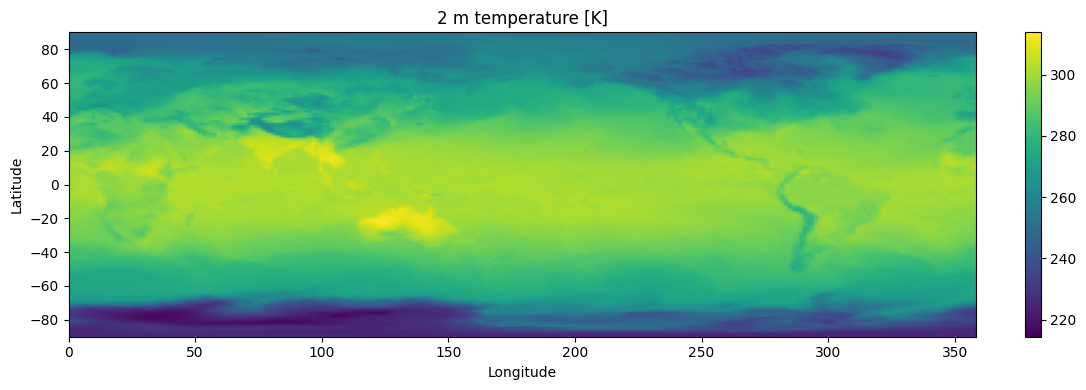

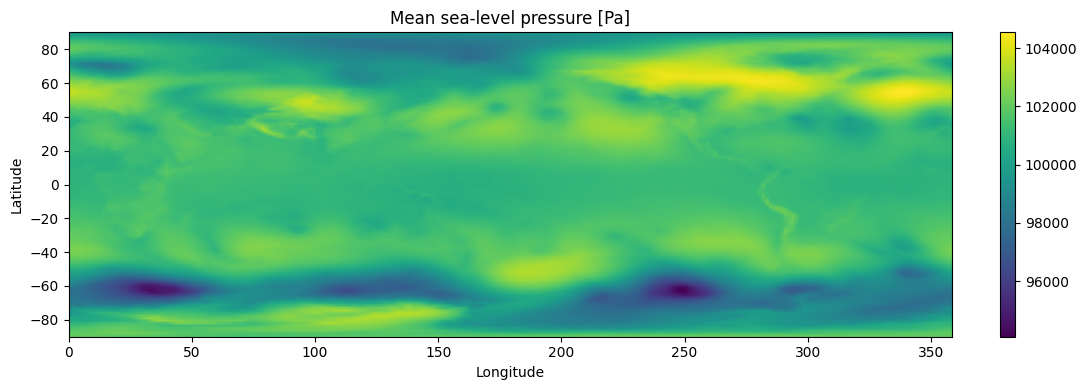

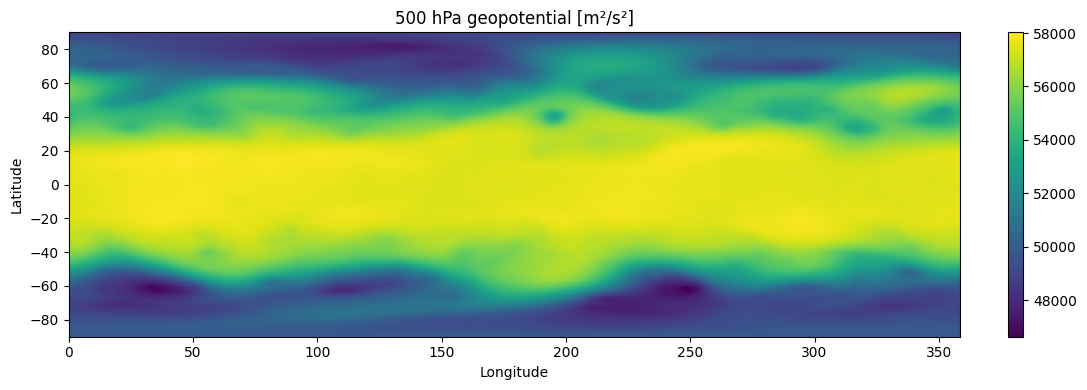

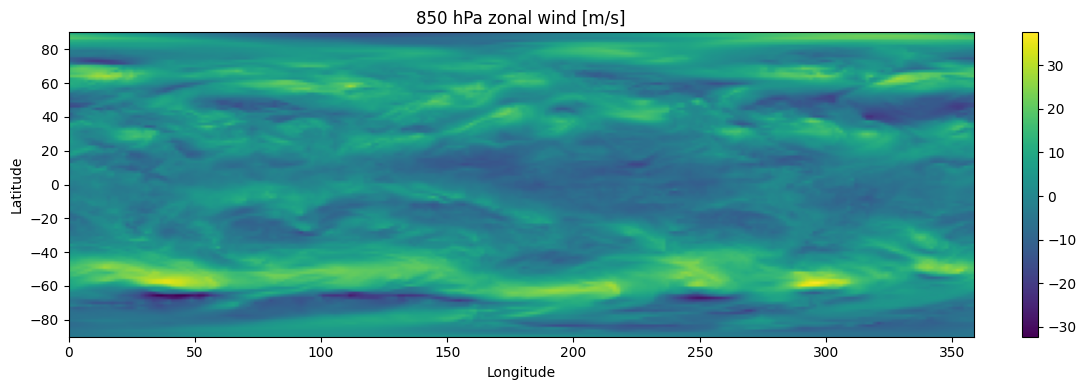

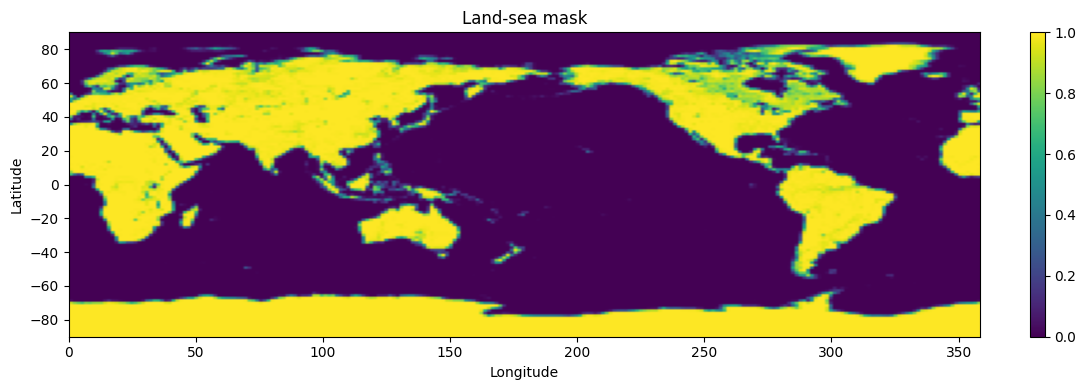

In [ ]:
# @title Visualize selected validation fields
LEVEL_INDEX = {level: i for i, level in enumerate(LEVELS)}
sample = val_window
time_index = 1
extent = [sample["lon"][0], sample["lon"][-1], sample["lat"][-1], sample["lat"][0]]

fields = [
    ("2 m temperature [K]", sample["surf"]["2t"][time_index]),
    ("Mean sea-level pressure [Pa]", sample["surf"]["msl"][time_index]),
    ("500 hPa geopotential [m²/s²]", sample["atmos"]["z"][time_index, LEVEL_INDEX[500]]),
    ("850 hPa zonal wind [m/s]", sample["atmos"]["u"][time_index, LEVEL_INDEX[850]]),
    ("Land-sea mask", sample["static"]["lsm"]),
]

for title, field in fields:
    fig, ax = plt.subplots(figsize=(11, 4))
    im = ax.imshow(field, extent=extent, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.colorbar(im, ax=ax, fraction=0.025)
    plt.tight_layout()
    safe = title.lower().replace(" ", "_").replace("/", "_")[:40]
    plt.savefig(produced(OUTPUT_ROOT / "figures" / f"state_{safe}.png"), dpi=140, bbox_inches="tight")
    plt.show()

# 8. Area weighting on a latitude–longitude grid

A regular latitude–longitude grid does not assign equal physical area to every cell.

Cells near the poles represent much less area than cells near the equator. The canonical global RMSE therefore uses:

\[
w(\phi)=\cos(\phi)
\]

with the latitude weights normalized to unit mean.

**Exercise:** What would happen if every 1.5° grid cell were weighted equally?

<details>
<summary><b>Show a sample answer</b></summary>

The rows near the poles would count as much as the rows near the equator, although their cells cover far less area (cell area scales with cos φ, and the pole rows cover almost none). The global RMSE would then over-represent polar errors, and a model could look better or worse depending on how it does at high latitudes rather than over the globe.

</details>

In [ ]:
# @title Weighted and unweighted RMSE helpers
def lat_weights(lat):
    w = np.cos(np.deg2rad(np.asarray(lat, dtype=np.float64)))
    return w / w.mean()

def lat_weighted_rmse(pred, truth, lat):
    pred = np.asarray(pred, dtype=np.float64)
    truth = np.asarray(truth, dtype=np.float64)
    if pred.shape != truth.shape:
        raise ValueError(f"prediction {pred.shape} != truth {truth.shape}")
    w = lat_weights(lat)
    w = w[:, None] if pred.ndim == 2 else w[None, :, None]
    return float(np.sqrt(np.mean((pred - truth) ** 2 * w)))

def unweighted_rmse(pred, truth):
    pred = np.asarray(pred, dtype=np.float64)
    truth = np.asarray(truth, dtype=np.float64)
    return float(np.sqrt(np.mean((pred-truth)**2)))

# A persistence example on validation 2t at +6 h.
origin = 1
height = val_window["shape"][0] - (val_window["shape"][0] % PATCH_SIZE)
truth = val_window["surf"]["2t"][origin+1, :height]
persist = val_window["surf"]["2t"][origin, :height]
lat = val_window["lat"][:height]

print({
    "unweighted_rmse_K": unweighted_rmse(persist, truth),
    "latitude_weighted_rmse_K": lat_weighted_rmse(persist, truth, lat),
})

{'unweighted_rmse_K': 2.6920891185307285, 'latitude_weighted_rmse_K': 2.9911232091115294}


# 9. Build Aurora from the pinned checkpoint

Two model instances are conceptually important:

1. **frozen Aurora** — base checkpoint only;
2. **adaptable Aurora** — same base checkpoint plus LoRA tensors whose effective update starts at zero.

Before LoRA training, those two models should represent the same pretrained forecasting function apart from numerical implementation effects.

In [ ]:
# @title Model and Batch helpers
from aurora import AuroraSmallPretrained, Batch, Metadata, rollout

def build_aurora(use_lora):
    torch.manual_seed(SEED)
    model = AuroraSmallPretrained(use_lora=use_lora)
    # The source file was byte/digest verified above. The upstream loader uses
    # torch.load(..., weights_only=True) and adapts historical parameter names.
    model.load_checkpoint_local(str(checkpoint_path), strict=not use_lora)
    model = model.to(DEVICE).eval()
    for p in model.parameters():
        p.requires_grad_(False)

    if use_lora:
        names = [n for n, _ in model.named_parameters() if "lora" in n]
        n_params = sum(p.numel() for n, p in model.named_parameters() if "lora" in n)
        if len(names) != LORA_TENSORS_EXPECTED:
            raise ValueError(f"LoRA tensor count {len(names)} != expected {LORA_TENSORS_EXPECTED}")
        if n_params != LORA_PARAMETERS_EXPECTED:
            raise ValueError(f"LoRA parameter count {n_params} != expected {LORA_PARAMETERS_EXPECTED}")
    return model

def make_batch(window, origin):
    if origin < HISTORY_STEPS-1 or origin >= window["n_steps"]:
        raise ValueError(f"origin {origin} outside valid range")
    lo, hi = origin-HISTORY_STEPS+1, origin+1
    return Batch(
        surf_vars={
            k: torch.from_numpy(window["surf"][k][lo:hi][None])
            for k in SURF_VARS
        },
        static_vars={
            k: torch.from_numpy(window["static"][k])
            for k in STATIC_VARS
        },
        atmos_vars={
            k: torch.from_numpy(window["atmos"][k][lo:hi][None])
            for k in ATMOS_VARS
        },
        metadata=Metadata(
            lat=torch.tensor(window["lat"], dtype=torch.float32),
            lon=torch.tensor(window["lon"], dtype=torch.float32),
            time=(datetime.fromisoformat(window["times"][origin]),),
            atmos_levels=LEVELS,
        ),
    )

def forecast_from_origin(model, window, origin, steps):
    batch = make_batch(window, origin)
    with torch.inference_mode():
        preds = [p.to("cpu") for p in rollout(model, batch.to(DEVICE), steps=steps)]
    return preds

adapted_model = build_aurora(use_lora=True)

print({
    "base_parameters": PARAMETER_COUNT,
    "lora_parameters": LORA_PARAMETERS_EXPECTED,
    "lora_fraction_percent": 100 * LORA_PARAMETERS_EXPECTED / PARAMETER_COUNT,
    "device": DEVICE,
})

{'base_parameters': 112797584, 'lora_parameters': 540672, 'lora_fraction_percent': 0.47932941542435875, 'device': 'cuda'}


# 10. Persistence first

Persistence simply carries the latest analysis forward:

\[
\hat y_{t+h}=y_t
\]

At six hours it is often a surprisingly strong baseline. A learned weather model that cannot beat persistence on its deployment domain has not yet demonstrated useful forecast skill.

The notebook therefore calculates persistence **before** reporting Aurora.

**Exercise 1 — persistence (answer before you run section 11).** Before viewing any neural forecast, write down which atmospheric fields you expect persistence to handle well at six hours, and which badly. Section 24 has a sample answer.

### How the RMSE is aggregated

For each forecast origin, the notebook computes one latitude-weighted RMSE per variable and lead. For an atmospheric variable this RMSE pools all 13 pressure levels. It then averages these **per-origin RMSEs** over the origins. This is a mean of RMSEs, not one RMSE pooled over every origin's errors: origin RMSEs of 1 and 3 give 2.0, whereas pooling their squared errors would give about 2.24. Both conventions are coherent, and this notebook uses the first. The RMSE ratio divides the model's value by persistence's. The **nine-variable macro-average RMSE ratio** is the plain mean of the per-variable ratios: a chosen summary, not an overall physical error, and pooling the 13 pressure levels inside each atmospheric variable can hide failures at single levels. It leaves out any variable whose persistence RMSE is 0, because its ratio is undefined; the tables report `variables_with_defined_ratio` as the denominator. z500 is reported separately as a diagnostic.

Before scoring, the evaluator checks every forecast. It needs exactly one forecast per origin, the expected variables and shapes, finite values, and a valid time equal to the origin plus 6 h × lead. A malformed or non-finite forecast is refused instead of being scored as a poor one.

In [ ]:
# @title Common forecast evaluator
HEADLINE_LEVEL = 500
REPORTED = (*SURF_VARS, *ATMOS_VARS, "z500")
METRIC_CONVENTION = (
    "latitude-weighted RMSE computed separately for each forecast origin, then averaged over origins "
    "(a mean of per-origin RMSEs, not one RMSE pooled over origins); an atmospheric variable's RMSE pools its "
    "13 pressure levels within each origin; skill = model RMSE / persistence RMSE, undefined (NaN) when the "
    "persistence RMSE is 0 and then left out of the nine-variable mean; z500 is a separate diagnostic outside that mean"
)

def check_forecast_fields(pred, window, height, where):
    """Refuse a forecast that is not exactly the expected finite fields on the evaluation grid."""
    if not isinstance(pred, dict) or set(pred) != {"surf", "atmos"}:
        raise ValueError(f"{where}: a forecast must hold exactly 'surf' and 'atmos' fields")
    width = window["shape"][1]
    for group, names, shape in (
        ("surf", SURF_VARS, (height, width)),
        ("atmos", ATMOS_VARS, (len(LEVELS), height, width)),
    ):
        fields = pred[group]
        if set(fields) != set(names):
            raise ValueError(f"{where}: {group} variables {sorted(fields)} != expected {sorted(names)}")
        for name in names:
            arr = np.asarray(fields[name])
            if arr.shape != shape:
                raise ValueError(f"{where}: {group}/{name} has shape {arr.shape}, expected {shape}")
            if not np.isfinite(arr).all():
                raise ValueError(f"{where}: {group}/{name} contains non-finite values; refusing to score an invalid forecast")

def _as_datetime(value):
    if isinstance(value, datetime):
        return value.replace(tzinfo=None)
    return datetime.fromisoformat(str(value)[:19])

def forecast_arrays(preds, window, origin):
    """NumPy fields for each rolled-out lead, after checking that lead k is valid at origin + 6 h x k."""
    start = datetime.fromisoformat(window["times"][origin])
    out = []
    for k, p in enumerate(preds, start=1):
        valid = _as_datetime(p.metadata.time[0])
        expected = start + timedelta(hours=TIMESTEP_HOURS * k)
        if valid != expected:
            raise ValueError(f"origin {origin}: lead {k} forecast is valid at {valid}, expected {expected}")
        out.append({
            "surf": {name: p.surf_vars[name][0, 0].numpy() for name in SURF_VARS},
            "atmos": {name: p.atmos_vars[name][0, 0].numpy() for name in ATMOS_VARS},
        })
    return out

def forecast_metrics(window, origins, predictions):
    height = window["shape"][0] - (window["shape"][0] % PATCH_SIZE)
    lat = window["lat"][:height]
    level_500 = LEVELS.index(500)
    origins = [int(o) for o in origins]
    if not origins:
        raise ValueError("no forecast origins to score")
    if len(set(origins)) != len(origins):
        raise ValueError(f"duplicate forecast origins {origins}")
    if len(predictions) != len(origins):
        raise ValueError(f"{len(predictions)} forecast sets for {len(origins)} origins; every origin needs exactly one")
    n_leads = len(predictions[0])
    if n_leads == 0:
        raise ValueError("the forecasts contain no lead times")
    for origin, preds in zip(origins, predictions, strict=True):
        if len(preds) != n_leads:
            raise ValueError(f"origin {origin}: {len(preds)} leads, expected {n_leads}")
        if origin < HISTORY_STEPS - 1 or origin + n_leads >= window["n_steps"]:
            raise ValueError(
                f"origin {origin} with {n_leads} leads needs analyses up to index {origin + n_leads}; "
                f"the window has {window['n_steps']}"
            )
        for k, pred in enumerate(preds):
            check_forecast_fields(pred, window, height, f"origin {origin}, +{(k + 1) * TIMESTEP_HOURS} h")
    result = {name: {} for name in REPORTED}

    for k in range(n_leads):
        lead = f"{(k+1)*6}h"
        model_errors = {name: [] for name in REPORTED}
        persistence_errors = {name: [] for name in REPORTED}

        for origin, preds in zip(origins, predictions, strict=True):
            target_index = origin + k + 1
            for name in SURF_VARS:
                truth = window["surf"][name][target_index, :height]
                model_errors[name].append(
                    lat_weighted_rmse(preds[k]["surf"][name], truth, lat)
                )
                persistence_errors[name].append(
                    lat_weighted_rmse(window["surf"][name][origin, :height], truth, lat)
                )
            for name in ATMOS_VARS:
                truth = window["atmos"][name][target_index, :, :height]
                model_errors[name].append(
                    lat_weighted_rmse(preds[k]["atmos"][name], truth, lat)
                )
                persistence_errors[name].append(
                    lat_weighted_rmse(window["atmos"][name][origin, :, :height], truth, lat)
                )

            truth = window["atmos"]["z"][target_index, level_500, :height]
            model_errors["z500"].append(
                lat_weighted_rmse(preds[k]["atmos"]["z"][level_500], truth, lat)
            )
            persistence_errors["z500"].append(
                lat_weighted_rmse(window["atmos"]["z"][origin, level_500, :height], truth, lat)
            )

        for name in REPORTED:
            model_rmse = float(np.mean(model_errors[name]))
            persistence_rmse = float(np.mean(persistence_errors[name]))
            result[name][lead] = {
                "model": model_rmse,
                "persistence": persistence_rmse,
                "skill": model_rmse / persistence_rmse if persistence_rmse > 0 else np.nan,
            }

    leads = [f"{(k+1)*6}h" for k in range(n_leads)]
    summary = {}
    for lead in leads:
        ratios = [result[name][lead]["skill"] for name in REPORTED if name != "z500"]
        defined = [r for r in ratios if np.isfinite(r)]
        summary[lead] = {
            "mean_skill": float(np.mean(defined)) if defined else float("nan"),
            "variables_beating_persistence": int(sum(r < 1 for r in defined)),
            "variables_with_defined_ratio": len(defined),
        }
    return {
        "n_origins": len(origins),
        "origins": origins,
        "origin_times": [window["times"][o] for o in origins],
        "leads": leads,
        "variables": result,
        "summary": summary,
        "metric": METRIC_CONVENTION,
    }

def evaluate_model(model, window, max_steps=4, origins=None):
    chosen = eval_origins(window, max_steps) if origins is None else [int(o) for o in origins]
    if not chosen:
        raise ValueError(
            f"window has {window['n_steps']} analyses; {HISTORY_STEPS + max_steps} are needed for {max_steps} lead steps"
        )
    predictions = []
    for origin in chosen:
        preds = forecast_from_origin(model, window, origin, max_steps)
        if len(preds) != max_steps:
            raise ValueError(f"origin {origin}: rollout returned {len(preds)} leads, expected {max_steps}")
        predictions.append(forecast_arrays(preds, window, origin))
    return forecast_metrics(window, chosen, predictions)

def persistence_only(window, max_steps=4, origins=None):
    height = window["shape"][0] - (window["shape"][0] % PATCH_SIZE)
    chosen = eval_origins(window, max_steps) if origins is None else [int(o) for o in origins]
    if not chosen:
        raise ValueError(
            f"window has {window['n_steps']} analyses; {HISTORY_STEPS + max_steps} are needed for {max_steps} lead steps"
        )
    predictions = [
        [
            {
                "surf": {k: window["surf"][k][origin, :height] for k in SURF_VARS},
                "atmos": {k: window["atmos"][k][origin, :, :height] for k in ATMOS_VARS},
            }
            for _ in range(max_steps)
        ]
        for origin in chosen
    ]
    scored = forecast_metrics(window, chosen, predictions)
    return {
        "leads": scored["leads"],
        "origins": scored["origins"],
        "variables": {
            name: {
                lead: {"persistence": values["persistence"]}
                for lead, values in lead_values.items()
            }
            for name, lead_values in scored["variables"].items()
        },
        "baseline": "persistence",
        "metric": METRIC_CONVENTION,
    }

val_persistence = persistence_only(val_window, MAX_LEAD_STEPS)
produced(OUTPUT_ROOT / "baseline" / "validation_persistence.json").write_text(
    json.dumps(val_persistence, indent=2), encoding="utf-8"
)

print("Validation persistence RMSE:")
for name in ("2t", "msl", "z500"):
    print(name, {
        lead: round(values["persistence"], 4)
        for lead, values in val_persistence["variables"][name].items()
    })

Validation persistence RMSE:
2t {'6h': 2.7004, '12h': 3.6936, '18h': 3.2141, '24h': 1.9941}
msl {'6h': 261.1796, '12h': 387.503, '18h': 535.6019, '24h': 614.2006}
z500 {'6h': 236.7974, '12h': 374.0863, '18h': 525.4159, '24h': 628.6764}


# 11. Frozen Aurora on validation — diagnose the domain shift

**Predict before you run the next cell.** Persistence has just been scored on the validation window. Will the frozen Aurora forecast beat persistence at 6 h? At 24 h? Which of the nine variables do you expect to fare worst? Write your prediction down, then run the cell and compare.

The adaptable model's LoRA update is currently zero (every `lora_B` factor is zero, so B·A adds nothing), so it is still the frozen pretrained forecast.

On the tutorial's 1.5° data product, **losing to persistence is an expected and scientifically useful result**. It shows that correct variable names and units alone do not guarantee transfer.

The grid change is a well-motivated explanation, because each grid cell and each 4×4 token now covers a much larger physical area than during pretraining. It is **not isolated** by this comparison, however. The notebook does not run this checkpoint at its native 0.25° resolution under otherwise matched conditions, it uses the small debugging checkpoint, and every input, including the static land-sea mask and soil type, comes from WeatherBench2's conservatively regridded product (the categorical soil-type codes are averaged into non-integer values). Losing to persistence on one coarse sample therefore supports *grid spacing as one plausible contributor to the domain shift*, not a proven sole cause.

,lead,mean_rmse_ratio_vs_persistence,variables_beating_persistence,of
0,6h,1.572999,1,9
1,12h,1.355079,1,9
2,18h,1.245819,0,9
3,24h,1.285941,1,9


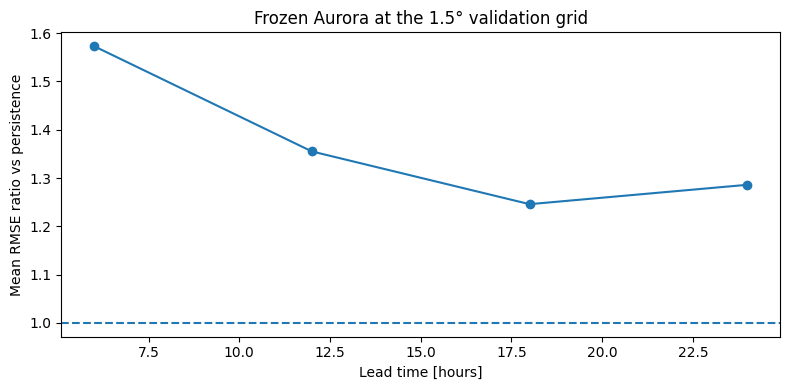

In [ ]:
# @title Frozen validation forecast
import time

started = time.perf_counter()
frozen_validation = evaluate_model(adapted_model, val_window, MAX_LEAD_STEPS)
frozen_validation_seconds = time.perf_counter() - started

produced(OUTPUT_ROOT / "frozen_model" / "validation_metrics.json").write_text(
    json.dumps(frozen_validation, indent=2), encoding="utf-8"
)

validation_summary = pd.DataFrame([
    {
        "lead": lead,
        "mean_rmse_ratio_vs_persistence": frozen_validation["summary"][lead]["mean_skill"],
        "variables_beating_persistence": frozen_validation["summary"][lead]["variables_beating_persistence"],
        "of": 9,
    }
    for lead in frozen_validation["leads"]
])
display(validation_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    [int(x[:-1]) for x in validation_summary["lead"]],
    validation_summary["mean_rmse_ratio_vs_persistence"],
    marker="o",
)
ax.axhline(1.0, linestyle="--")
ax.set_xlabel("Lead time [hours]")
ax.set_ylabel("Mean RMSE ratio vs persistence")
ax.set_title(f"Frozen Aurora at the {val_window['resolution_degrees']:g}° validation grid")
plt.tight_layout()
plt.savefig(produced(OUTPUT_ROOT / "figures" / "validation_frozen_skill.png"), dpi=150, bbox_inches="tight")
plt.show()

## Interpretation checkpoint

Aurora was trained at 0.25°. The 1.5° WeatherBench2 product used here differs from its training data in several ways at once:

- horizontal gradients are smoother;
- extremes are reduced by regridding;
- orography is coarser;
- the static fields are regridded too: for example, the categorical soil-type codes are averaged into non-integer values;
- the spatial scale represented by each token changes dramatically.

Each of these is a **hypothesis** for why the frozen model loses to persistence. This notebook has no matched control that separates them, so it does not show which one matters.

**Exercise:** Which of these differences could plausibly hurt a pretrained neural forecaster even when the variable names, units and global coverage are correct? What matched control would you need to tell resolution apart from the regridded static fields?

<details>
<summary><b>Show a sample answer</b></summary>

All of them could: the network learned the statistics of 0.25° fields, so smoother gradients, weaker extremes, coarser orography, averaged static codes and 36 times the area per token each move its inputs away from what it saw in training.

Each possible control tests something narrower than "resolution":

- Running the frozen model on 0.25° data of the same dates changes several input properties together (grid spacing, gradients, extremes, orography and the static fields), so it tells you whether this whole 1.5° product hurts, not which property does.
- Keeping the 1.5° inputs but regridding the soil-type codes by a categorical (mode) rule tests that one preprocessing choice, not resolution itself and not every static-field effect.

Separating the factors needs a controlled design: matched dates, scores on one common verification grid, and resolution and each static-field treatment varied one at a time where feasible. None of this is run here, so the result in this notebook stays descriptive.

</details>

# 12. LoRA adaptation

Aurora's attention layers expose rank-8 LoRA parameters.

**Training vocabulary.**

- A **parameter** is a number inside the model that training may change. Only the LoRA parameters change here; the 113M base parameters stay fixed.
- The **loss** is one number measuring how far the model's forecast is from the target analysis; training tries to make it smaller.
- An **epoch** is one pass over all 12 training samples (two training windows × six forecast origins).
- **Early stopping** ends training when the validation loss has not improved for a declared number of epochs (the *patience*); the epoch with the lowest validation loss is kept.
- The **optimizer** (AdamW) moves each trainable parameter a small step in the direction that lowers the loss; the **learning rate** sets the step size.
- **Roles:** the *training* windows are what the optimizer learns from; the *validation* window chooses between the saved epochs; the *test* window is scored once, after the freeze.

A tiny worked example: one parameter w = 0, loss (w − 3)², learning rate 0.1. The gradient is 2(w − 3) = −6, so a plain gradient step moves w to 0 − 0.1 × (−6) = 0.6, and the loss falls from 9 to 5.76. Training repeats steps like this for every sample in every epoch (AdamW rescales the steps, but the idea is the same).

**LoRA** (low-rank adaptation) [5] adds a learned low-rank correction B·A (rank 8) to selected weight matrices. B starts at zero, so the **effective update** B·A starts at zero and the adapted model begins exactly as the pretrained one; training then learns B and A. The cell below rebuilds that zero-update model from the verified checkpoint before every adaptation, so re-running it repeats the recipe instead of continuing to train the previous adapter.

Canonical adaptation:

- 80 LoRA tensors;
- 540,672 trainable parameters;
- approximately 0.48% of the 113M base model;
- train on 31 December 2018–1 January 2019 and 1–2 July 2019;
- validate on 31 March–1 April 2020;
- up to `EPOCHS` = 30 epochs, stopping early once the validation loss has not improved for `PATIENCE` = 3 epochs in a row (both declared in section 2, before any training);
- AdamW;
- one-step (+6 h) training loss;
- lowest validation loss selects the final state.

Epoch 0 — the frozen model — remains eligible. If adaptation does not improve the validation objective, the notebook keeps the frozen policy.

**Where the recipe comes from.** The learning rate, LoRA scope and loss scales are inherited from this repository's primary Aurora tutorial (`tutorials/aurora_earth_system_colab.ipynb`), which trains a fixed six epochs on the same four windows; they are not tuned here. The number of epochs is no longer inherited. Earlier blobs of this notebook also trained a fixed six epochs, and in every run of them recorded in `docs/release-verification.md` (2026-09-26 to 2026-10-03) validation selected the last allowed epoch, 6, while the validation loss was still decreasing, so the selection could not show whether more training would help. This revision lets validation choose: it trains for up to 30 epochs, stops once the validation loss has not improved for 3 epochs in a row, and keeps the epoch with the lowest validation loss. If your run still selects epoch 30, the cell below says so: the selection then reached the budget, not a minimum.

**What validation selects on, and what the test reports.** The selection objective is the training loss itself: an **unweighted** (every grid cell counts equally), per-variable scaled, **one-step (+6 h)** mean squared error on the validation window. `LOSS_SCALES` divides each variable's error by a typical size (for example 10 K for temperature and 1000 Pa for sea-level pressure) so the nine variables count on a comparable footing. The test reports something different: latitude-weighted RMSE, relative to persistence, over autoregressive leads from 6 to 24 h. The two can disagree, because a lower one-step loss does not guarantee lower error after four steps that feed on their own output. Keeping epoch 0 eligible therefore protects only the selection objective, not the headline RMSE ratios. The test window is read once, after the freeze in section 14.

**Predict before you run.** At which epoch do you expect early stopping to end training, and will that be enough for the adapted model to beat persistence on validation? Which variables do you expect to improve most?

In [ ]:
# @title LoRA adaptation helpers
import copy

def trainable_names(model, mode):
    if mode not in {"lora", "lora+heads"}:
        raise ValueError(mode)
    prefixes = (
        "decoder.surf_heads.",
        "decoder.atmos_heads.",
        "encoder.surf_token_embeds.",
        "encoder.atmos_token_embeds.",
    )
    names = []
    for name, _ in model.named_parameters():
        if "lora" in name or (mode == "lora+heads" and name.startswith(prefixes)):
            names.append(name)
    return names

def target_fields(window, origin):
    height = window["shape"][0] - (window["shape"][0] % PATCH_SIZE)
    return {
        **{
            k: torch.from_numpy(window["surf"][k][origin+1, :height]).to(DEVICE)
            for k in SURF_VARS
        },
        **{
            k: torch.from_numpy(window["atmos"][k][origin+1, :, :height]).to(DEVICE)
            for k in ATMOS_VARS
        },
    }

def scaled_loss(pred, target, scales):
    total = 0.0
    for k in SURF_VARS:
        total = total + torch.mean(((pred.surf_vars[k][0,0] - target[k]) / scales[k])**2)
    for k in ATMOS_VARS:
        total = total + torch.mean(((pred.atmos_vars[k][0,0] - target[k]) / scales[k])**2)
    return total / (len(SURF_VARS) + len(ATMOS_VARS))

def one_step_validation_loss(model, window, scales):
    model.eval()
    values = []
    with torch.inference_mode():
        for origin in range(HISTORY_STEPS-1, window["n_steps"]-1):
            pred = model(make_batch(window, origin).to(DEVICE))
            values.append(float(scaled_loss(pred, target_fields(window, origin), scales)))
    return float(np.mean(values))

def adapt_model(model, train_windows, val_window, epochs, lr, mode, seed, patience):
    torch.manual_seed(seed)
    names = trainable_names(model, mode)
    wanted = set(names)

    for name, param in model.named_parameters():
        param.requires_grad_(name in wanted)

    params = [p for p in model.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in params)

    if mode == "lora":
        if len(names) != LORA_TENSORS_EXPECTED:
            raise ValueError(f"LoRA tensor count {len(names)} != {LORA_TENSORS_EXPECTED}")
        if n_trainable != LORA_PARAMETERS_EXPECTED:
            raise ValueError(f"LoRA params {n_trainable} != {LORA_PARAMETERS_EXPECTED}")

    optimizer = torch.optim.AdamW(params, lr=lr)
    scales = {
        k: torch.tensor(v, dtype=torch.float32, device=DEVICE)
        for k, v in LOSS_SCALES.items()
    }

    samples = [
        (window, origin)
        for window in train_windows
        for origin in range(HISTORY_STEPS-1, window["n_steps"]-1)
    ]
    generator = torch.Generator().manual_seed(seed)

    initial = {k: v.detach().clone() for k, v in model.state_dict().items() if k in wanted}
    best_state = copy.deepcopy(initial)
    best_epoch = 0
    best_val = one_step_validation_loss(model, val_window, scales)
    since_best = 0
    stopped_early = False
    history = [{
        "epoch": 0,
        "train_loss": None,
        "val_loss": best_val,
        "note": "frozen model / zero LoRA",
    }]

    started = time.perf_counter()
    try:
        for epoch in range(1, epochs+1):
            model.train()
            order = torch.randperm(len(samples), generator=generator).tolist()
            losses = []
            for idx in order:
                window, origin = samples[idx]
                pred = model(make_batch(window, origin).to(DEVICE))
                loss = scaled_loss(pred, target_fields(window, origin), scales)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                optimizer.step()
                losses.append(float(loss.detach()))

            val_loss = one_step_validation_loss(model, val_window, scales)
            entry = {
                "epoch": epoch,
                "train_loss": float(np.mean(losses)),
                "val_loss": val_loss,
            }
            history.append(entry)
            print(entry)

            if val_loss < best_val:
                best_val = val_loss
                best_epoch = epoch
                best_state = {
                    k: v.detach().clone()
                    for k, v in model.state_dict().items()
                    if k in wanted
                }
                since_best = 0
            else:
                since_best += 1
                if since_best >= patience:
                    stopped_early = True
                    print({"early_stop": f"no validation improvement for {patience} epochs", "stopped_after_epoch": epoch})
                    break
    except BaseException:
        merged = dict(model.state_dict())
        merged.update(initial)
        model.load_state_dict(merged, strict=True)
        for p in model.parameters():
            p.requires_grad_(False)
        model.eval()
        raise

    merged = dict(model.state_dict())
    merged.update(best_state)
    model.load_state_dict(merged, strict=True)
    for p in model.parameters():
        p.requires_grad_(False)
    model.eval()

    return {
        "trainable": mode,
        "trainable_names": names,
        "n_trainable": n_trainable,
        "n_total": sum(p.numel() for p in model.parameters()),
        "epochs": epochs,
        "patience": patience,
        "epochs_run": len(history) - 1,
        "stopped_early": stopped_early,
        "best_epoch": best_epoch,
        "selection_at_budget": best_epoch == epochs,
        "learning_rate": lr,
        "seed": seed,
        "loss_scales": LOSS_SCALES,
        "n_train_samples": len(samples),
        "history": history,
        "seconds": time.perf_counter() - started,
    }

def fresh_adaptable_model():
    """A new LoRA-capable Aurora from the verified checkpoint with a zero effective LoRA update (every lora_B is zero,
    so B @ A adds nothing). Re-running this cell therefore repeats the documented recipe from the pretrained model
    instead of continuing to train the previously selected adapter."""
    model = build_aurora(use_lora=True)
    lora_b = [float(p.detach().abs().max()) for name, p in model.named_parameters() if name.endswith("lora_B")]
    if not lora_b or max(lora_b) != 0.0:
        raise RuntimeError("a freshly built adaptable model does not have a zero effective LoRA update; refusing to train")
    return model

# Release the previous model before building the new one, so a re-run does not hold two copies in GPU memory.
adapted_model = None
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
adapted_model = fresh_adaptable_model()

adaptation = adapt_model(
    adapted_model,
    train_windows,
    val_window,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    mode=TRAINABLE,
    seed=SEED,
    patience=PATIENCE,
)

produced(OUTPUT_ROOT / "adaptation" / "training_history.json").write_text(
    json.dumps(adaptation, indent=2), encoding="utf-8"
)

display(pd.DataFrame(adaptation["history"]))
print({
    "best_epoch": adaptation["best_epoch"],
    "epochs_run": adaptation["epochs_run"],
    "stopped_early": adaptation["stopped_early"],
    "trainable_parameters": adaptation["n_trainable"],
    "percent_of_base": 100 * adaptation["n_trainable"] / PARAMETER_COUNT,
    "training_seconds": adaptation["seconds"],
})
if adaptation["selection_at_budget"]:
    print(f"Validation selected the last allowed epoch ({EPOCHS}): the selection reached the budget, not a minimum.")
else:
    print(f"Validation selected epoch {adaptation['best_epoch']} of {adaptation['epochs_run']} run (patience {PATIENCE}).")

{'epoch': 1, 'train_loss': 0.14134077541530132, 'val_loss': 0.100042009105285}


{'epoch': 2, 'train_loss': 0.08408458344638348, 'val_loss': 0.07940302044153214}


{'epoch': 3, 'train_loss': 0.068623723462224, 'val_loss': 0.06996069848537445}


{'epoch': 4, 'train_loss': 0.05939265185346206, 'val_loss': 0.062339840456843376}


{'epoch': 5, 'train_loss': 0.05384235984335343, 'val_loss': 0.0568055926511685}


...

{'epoch': 26, 'train_loss': 0.02889124226445953, 'val_loss': 0.04093870831032594}


{'epoch': 27, 'train_loss': 0.03576400472472111, 'val_loss': 0.0458121815075477}


{'epoch': 28, 'train_loss': 0.034596120317777, 'val_loss': 0.042861087868611016}
{'early_stop': 'no validation improvement for 3 epochs', 'stopped_after_epoch': 28}


,epoch,train_loss,val_loss,note
0,0,NaN,0.184840,frozen model / zero LoRA
1,1,0.141341,0.100042,NaN
2,2,0.084085,0.079403,NaN
3,3,0.068624,0.069961,NaN
4,4,0.059393,0.062340,NaN
5,5,0.053842,0.056806,NaN
6,6,0.049368,0.053639,NaN
7,7,0.046220,0.051429,NaN
8,8,0.044177,0.050350,NaN
9,9,0.042152,0.047978,NaN


{'best_epoch': 25, 'epochs_run': 28, 'stopped_early': True, 'trainable_parameters': 540672, 'percent_of_base': 0.47932941542435875, 'training_seconds': 174.537776211}
Validation selected epoch 25 of 28 run (patience 3).


# 13. Validate the selected adapted model

The training objective is one-step scaled MSE. The scientifically relevant question, however, is how the selected model behaves during an autoregressive rollout.

The next cell compares the selected adapted model with its own persistence baseline over 6–24 hours **on validation only**.

In [ ]:
# @title Adapted validation rollout
adapted_validation = evaluate_model(adapted_model, val_window, MAX_LEAD_STEPS)

produced(OUTPUT_ROOT / "adaptation" / "validation_metrics.json").write_text(
    json.dumps(adapted_validation, indent=2), encoding="utf-8"
)

val_compare = pd.DataFrame([
    {
        "lead": lead,
        "frozen_mean_ratio": frozen_validation["summary"][lead]["mean_skill"],
        "adapted_mean_ratio": adapted_validation["summary"][lead]["mean_skill"],
        "frozen_vars_beating_persistence": frozen_validation["summary"][lead]["variables_beating_persistence"],
        "adapted_vars_beating_persistence": adapted_validation["summary"][lead]["variables_beating_persistence"],
    }
    for lead in frozen_validation["leads"]
])
display(val_compare)

,lead,frozen_mean_ratio,adapted_mean_ratio,frozen_vars_beating_persistence,adapted_vars_beating_persistence
0,6h,1.572999,0.808974,1,8
1,12h,1.355079,0.751435,1,8
2,18h,1.245819,0.775617,0,9
3,24h,1.285941,0.869169,1,8


# 14. Freeze the experiment before the test

Within this run, no test metric has been used for:

- choosing LoRA versus `lora+heads`;
- choosing the epoch;
- changing learning rate;
- changing lead times;
- changing the persistence definition; or
- changing the metric.

That holds **within this run only**. Most of the recipe was inherited (section 12). The 30 September–1 October 2021 test window was scored in earlier runs of this notebook and was used to develop the repository's primary tutorial, which applies a fixed six-epoch version of the recipe to the same window. That tutorial stops on its default path unless its adapted model beats the frozen model and persistence on this window; that stop is a default-path regression check against its recorded runs, not a scientific test. The test here is therefore a **temporally separate, development-reused evaluation window** (three overlapping origins in one two-day period): separate in time from training and validation, but not a never-seen held-out estimate. The exported manifest records two kinds of exposure separately: this **development reuse**, and the pretrained checkpoint's own training data, which may or may not include this period. That **pretrained-checkpoint exposure is unknown** here, so the window is not shown to be independent of the base model either.

The next record freezes those choices before final test evaluation. It also binds the test to them. It records a digest of the **selected adapter tensors**, the content digest of the test window, the adaptation scope, and the exact test leads and origins, and it is itself digested.

Section 15 recomputes those identities from the live notebook state before any test forecast runs, and **refuses** to evaluate if anything has changed. It then takes the leads and origins from the record, not from the controls. Changing a setting after freezing therefore requires a new freeze. A new freeze never overwrites a different earlier one: that record is kept under `frozen/superseded/`.

> **What to notice.** Compare the model result with the stated baseline/reference first. Then inspect the secondary metric or diagnostic that explains *how* the result was achieved; do not infer a universal model ranking from one sample and configuration.

In [ ]:
# @title Freeze experiment
def tensor_state_digest(tensors):
    """SHA-256 over sorted tensor names, shapes and float32 values: the identity of a selected adapter state."""
    h = hashlib.sha256()
    for name in sorted(tensors):
        value = tensors[name]
        if hasattr(value, "detach"):
            value = value.detach().to("cpu").float().numpy()
        arr = np.ascontiguousarray(np.asarray(value, dtype=np.float32))
        h.update(name.encode()); h.update(json.dumps(list(arr.shape)).encode()); h.update(arr.tobytes())
    return h.hexdigest()

def selected_adapter_state(model, names):
    wanted = set(names)
    return {k: v for k, v in model.state_dict().items() if k in wanted}

def experiment_sha256(record):
    """Digest of a frozen record's JSON content, excluding the digest field itself."""
    body = {k: v for k, v in record.items() if k != "experiment_sha256"}
    return hashlib.sha256(json.dumps(body, sort_keys=True, default=str).encode("utf-8")).hexdigest()

def freeze_mismatches(record, *, checkpoint_sha256, trainable, adapter_state_sha256, test_content_sha256, lead_steps):
    """Every way the live state differs from a frozen experiment record; an empty list means the same experiment."""
    problems = []
    if record.get("experiment_sha256") != experiment_sha256(record):
        problems.append("the frozen record was edited after it was written")
    if record["model"]["checkpoint_sha256"] != checkpoint_sha256:
        problems.append("base checkpoint identity")
    if record["adaptation"]["trainable"] != trainable:
        problems.append(f"adaptation scope (frozen {record['adaptation']['trainable']!r}, live {trainable!r})")
    if record["selected_adapter"]["state_sha256"] != adapter_state_sha256:
        problems.append("selected adapter tensors")
    request = record["test_request"]
    if request["window_content_sha256"] != test_content_sha256:
        problems.append("test window data")
    if request["lead_steps"] != lead_steps:
        problems.append(f"evaluation lead steps (frozen {request['lead_steps']}, live {lead_steps})")
    return problems

frozen_experiment = {
    "notebook_spec": "2.5",
    "profile": "E2E",
    "mode": "WORKSHOP",
    "model": {
        "id": MODEL_ID,
        "revision": MODEL_REVISION,
        "checkpoint_name": CHECKPOINT_NAME,
        "checkpoint_bytes": CHECKPOINT_BYTES,
        "checkpoint_sha256": CHECKPOINT_SHA256,
        "checkpoint_loading": "upstream weights_only checkpoint loader after local digest verification",
        "small_checkpoint_boundary": True,
    },
    "dataset": dataset_manifest,
    "state_contract": {
        "surface_variables": list(SURF_VARS),
        "atmospheric_variables": list(ATMOS_VARS),
        "static_variables": list(STATIC_VARS),
        "pressure_levels_hpa": list(LEVELS),
        "history_steps": HISTORY_STEPS,
        "timestep_hours": TIMESTEP_HOURS,
        "tutorial_resolution_degrees": val_window["resolution_degrees"],
        "training_resolution_degrees": 0.25,
    },
    "adaptation": {
        k: v for k, v in adaptation.items()
        if k not in {"trainable_names"}
    },
    "trainable_tensor_names": adaptation["trainable_names"],
    "evaluation": {
        "metric": "latitude-weighted RMSE with cosine-latitude weights normalized to unit mean",
        "persistence": "latest analysis carried unchanged to every lead",
        "skill_semantics": "model RMSE / persistence RMSE; below 1 beats persistence",
        "lead_hours": [6 * i for i in range(1, MAX_LEAD_STEPS+1)],
        "z500_is_diagnostic_not_tenth_summary_variable": True,
    },
    "validation": {
        "frozen": frozen_validation,
        "adapted": adapted_validation,
    },
    "base_conversion": base_receipt,
    "selected_adapter": {
        "state_sha256": tensor_state_digest(selected_adapter_state(adapted_model, adaptation["trainable_names"])),
        "n_tensors": len(adaptation["trainable_names"]),
        "best_epoch": adaptation["best_epoch"],
    },
    "validation_window_content_sha256": window_content_digest(val_window),
    "test_request": {
        "window_role": "test",
        "window_name": test_window["name"],
        "window_content_sha256": window_content_digest(test_window),
        "lead_steps": MAX_LEAD_STEPS,
        "origins": eval_origins(test_window, MAX_LEAD_STEPS),
        "origin_times": [test_window["times"][o] for o in eval_origins(test_window, MAX_LEAD_STEPS)],
    },
}
# Round-trip through JSON first so the digest describes exactly the bytes written to disk.
frozen_record = json.loads(json.dumps(frozen_experiment, default=str))
frozen_record["experiment_sha256"] = experiment_sha256(frozen_record)

freeze_path = OUTPUT_ROOT / "frozen" / "frozen_experiment.json"
if freeze_path.exists():
    previous = json.loads(freeze_path.read_text(encoding="utf-8"))
    if previous.get("experiment_sha256") != frozen_record["experiment_sha256"]:
        # A completed freeze is never silently replaced: a changed experiment is a new experiment.
        kept = OUTPUT_ROOT / "frozen" / "superseded" / f"frozen_experiment_{str(previous.get('experiment_sha256') or 'unhashed')[:12]}.json"
        kept.parent.mkdir(parents=True, exist_ok=True)
        freeze_path.replace(kept)
        print("A different experiment had been frozen here; it is kept at", kept)
produced(freeze_path).write_text(json.dumps(frozen_record, indent=2), encoding="utf-8")
print("Experiment frozen:", freeze_path, "experiment_sha256", frozen_record["experiment_sha256"][:12])

Experiment frozen: outputs/frozen/frozen_experiment.json experiment_sha256 653f6d96a7ea


# 15. Test on a temporally separate, development-reused evaluation window (30 September–1 October 2021 in the built-in sample)

**Predict before you run.** Will the adapted model's advantage over the frozen model on validation carry over to the test window at every lead? At which lead do you expect persistence to be hardest to beat, and why?

The test first verifies the frozen record from section 14 against the live model, data and settings.

The test now compares three forecast systems:

1. persistence;
2. a **fresh** zero-LoRA Aurora model;
3. the validation-selected adapted model.

The frozen model is reconstructed only after the experiment is frozen, so its test metrics cannot influence the adaptation choices made in this run. The window is separate in time from training and validation (another year), but, as section 14 explains, it is a re-used window, so read the result as "this fixed recipe on one re-used two-day window (three origins)", not as an independent held-out estimate.

In [ ]:
# @title Test comparison on the temporally separate, development-reused evaluation window
# Bind the test to the frozen record: the live model, data and settings must be the ones that were frozen.
frozen_record = json.loads(freeze_path.read_text(encoding="utf-8"))
freeze_problems = freeze_mismatches(
    frozen_record,
    checkpoint_sha256=CHECKPOINT_SHA256,
    trainable=TRAINABLE,
    adapter_state_sha256=tensor_state_digest(selected_adapter_state(adapted_model, adaptation["trainable_names"])),
    test_content_sha256=window_content_digest(test_window),
    lead_steps=MAX_LEAD_STEPS,
)
if freeze_problems:
    raise RuntimeError(
        "The live notebook state no longer matches the frozen experiment: " + "; ".join(freeze_problems)
        + ". Re-run from '14. Freeze the experiment' to record a new experiment "
        "(an earlier record is kept under frozen/superseded/)."
    )
# The test request comes from the verified record, not from the (mutable) controls.
TEST_LEAD_STEPS = frozen_record["test_request"]["lead_steps"]
TEST_ORIGINS = frozen_record["test_request"]["origins"]

test_persistence = persistence_only(test_window, TEST_LEAD_STEPS, origins=TEST_ORIGINS)

fresh_frozen_model = build_aurora(use_lora=True)

started = time.perf_counter()
frozen_test = evaluate_model(fresh_frozen_model, test_window, TEST_LEAD_STEPS, origins=TEST_ORIGINS)
frozen_test_seconds = time.perf_counter() - started

started = time.perf_counter()
adapted_test = evaluate_model(adapted_model, test_window, TEST_LEAD_STEPS, origins=TEST_ORIGINS)
adapted_test_seconds = time.perf_counter() - started

comparison = pd.DataFrame([
    {
        "lead_hours": int(lead[:-1]),
        "frozen_mean_rmse_ratio": frozen_test["summary"][lead]["mean_skill"],
        "adapted_mean_rmse_ratio": adapted_test["summary"][lead]["mean_skill"],
        "frozen_vars_beating_persistence": frozen_test["summary"][lead]["variables_beating_persistence"],
        "adapted_vars_beating_persistence": adapted_test["summary"][lead]["variables_beating_persistence"],
        "variables_with_defined_ratio": frozen_test["summary"][lead]["variables_with_defined_ratio"],
    }
    for lead in frozen_test["leads"]
])
display(comparison)

comparison.to_csv(produced(OUTPUT_ROOT / "test" / "comparison.csv"), index=False)
produced(OUTPUT_ROOT / "test" / "frozen_metrics.json").write_text(
    json.dumps(frozen_test, indent=2), encoding="utf-8"
)
produced(OUTPUT_ROOT / "test" / "adapted_metrics.json").write_text(
    json.dumps(adapted_test, indent=2), encoding="utf-8"
)

variable_rows = []
for name in REPORTED:
    for lead in frozen_test["leads"]:
        variable_rows.append({
            "variable": name,
            "lead": lead,
            "persistence_rmse": frozen_test["variables"][name][lead]["persistence"],
            "frozen_rmse": frozen_test["variables"][name][lead]["model"],
            "frozen_ratio": frozen_test["variables"][name][lead]["skill"],
            "adapted_rmse": adapted_test["variables"][name][lead]["model"],
            "adapted_ratio": adapted_test["variables"][name][lead]["skill"],
            "unit": UNITS.get("z" if name == "z500" else name, ""),
        })
variable_table = pd.DataFrame(variable_rows)
display(variable_table[variable_table["variable"].isin(["2t", "msl", "z500", "u"])])
# The nine-variable macro-average hides per-variable behaviour; 2 m temperature follows the daily cycle (see the note below).
print("2 m temperature against persistence (at 24 h the daily cycle is approximately back in phase):")
print(variable_table[variable_table["variable"] == "2t"][["lead", "persistence_rmse", "frozen_ratio", "adapted_ratio"]].to_string(index=False))
variable_table.to_csv(produced(OUTPUT_ROOT / "test" / "variable_metrics.csv"), index=False)

,lead_hours,frozen_mean_rmse_ratio,adapted_mean_rmse_ratio,frozen_vars_beating_persistence,adapted_vars_beating_persistence,variables_with_defined_ratio
0,6,1.568051,0.794277,1,8,9
1,12,1.327926,0.735075,1,8,9
2,18,1.237117,0.765286,1,9,9
3,24,1.293737,0.871614,2,8,9


,variable,lead,persistence_rmse,frozen_rmse,frozen_ratio,adapted_rmse,adapted_ratio,unit
0,2t,6h,2.665918,2.459192,0.922456,1.323118,0.496309,K
1,2t,12h,3.628601,3.242790,0.893675,1.770136,0.487829,K
2,2t,18h,3.106182,3.530526,1.136613,1.979782,0.637368,K
3,2t,24h,1.804413,3.706666,2.054222,2.185706,1.211312,K
12,msl,6h,269.141103,414.644570,1.540622,180.110389,0.669204,Pa
13,msl,12h,392.725093,584.403593,1.488073,284.852016,0.725322,Pa
14,msl,18h,524.715721,699.498966,1.333101,406.630705,0.774954,Pa
15,msl,24h,584.746807,771.775758,1.319846,508.330852,0.869318,Pa
20,u,6h,3.639071,7.494901,2.059564,2.983908,0.819964,m/s
21,u,12h,5.525572,8.692264,1.573097,4.202788,0.760607,m/s


2 m temperature against persistence (at 24 h the daily cycle is approximately back in phase):
lead  persistence_rmse  frozen_ratio  adapted_ratio
  6h          2.665918      0.922456       0.496309
 12h          3.628601      0.893675       0.487829
 18h          3.106182      1.136613       0.637368
 24h          1.804413      2.054222       1.211312


## Reference expectation, not a canned answer

**Quoted from an earlier run, not re-run here.** The Colab CLI T4 run of this notebook at revision `b5c8494` (notebook blob `09775738`, 2026-10-03, default settings; recorded in `docs/release-verification.md`) observed frozen → adapted nine-variable macro-average RMSE ratios of:

- 6 h: 1.568 → 0.914
- 12 h: 1.328 → 0.867
- 18 h: 1.237 → 0.888
- 24 h: 1.294 → 0.997

Those values are **not injected into this notebook's results**. The table above is recomputed from this execution. They come from the same 30 September–1 October 2021 window but from the earlier **six fixed epochs** design, so with early stopping your numbers will differ. They are not an independent estimate (section 14).

### Read persistence by lead: the daily cycle

Persistence copies the analysis at the origin. At **24 h** the valid time falls at the same time of day as the origin, so the daily (diurnal) heating cycle is approximately back in phase, and persistence can do relatively well on near-surface fields such as 2 m temperature; at 6–18 h it is out of phase. Persistence error that does not simply grow with lead, and a ratio against persistence that jumps at 24 h, are **consistent with the diurnal component returning approximately to phase**. The weather itself keeps evolving over those 24 hours, and this notebook does not separate the two effects.

The nine-variable macro-average RMSE ratio hides this, so the test cell also prints the **2 m temperature** rows on their own. In the `b5c8494` run quoted above (not re-run here), 2t persistence RMSE was 2.67 / 3.63 / 3.11 / 1.80 K at 6 / 12 / 18 / 24 h, and the adapted model's 2t ratio at 24 h was **1.589**: worse than persistence at the lead where the daily cycle is approximately back in phase, although the macro-average ratio stayed below 1. Compare these with your own 2t rows.

# 16. Lead-time error growth

Autoregressive forecasts feed predictions back into the next model step, so errors can accumulate with lead.

The following curves keep physical RMSE and relative-to-persistence behavior visible together.

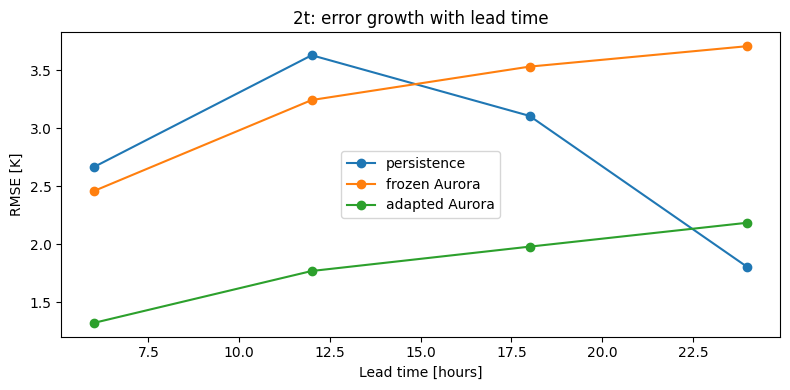

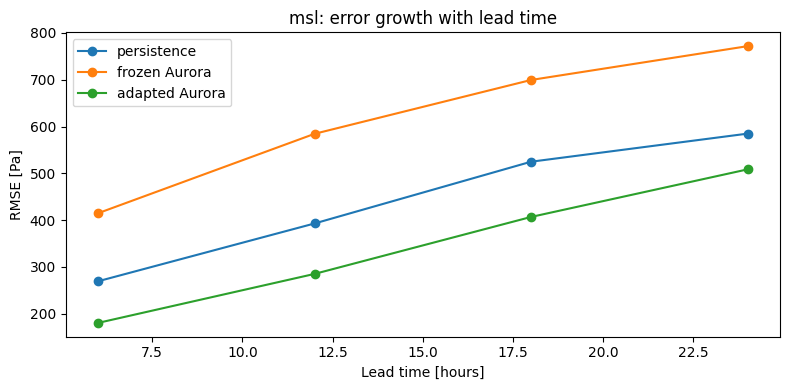

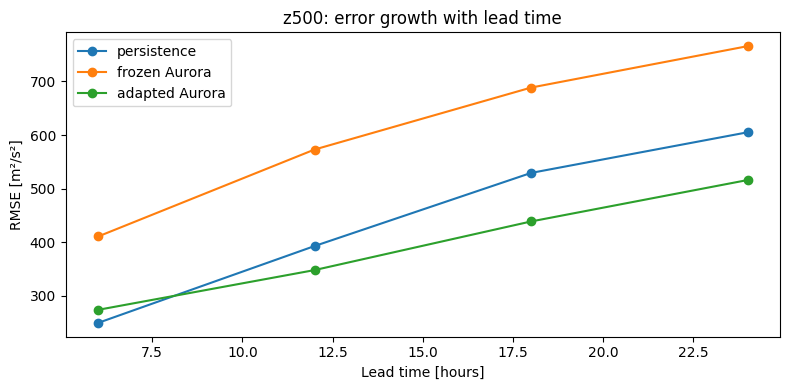

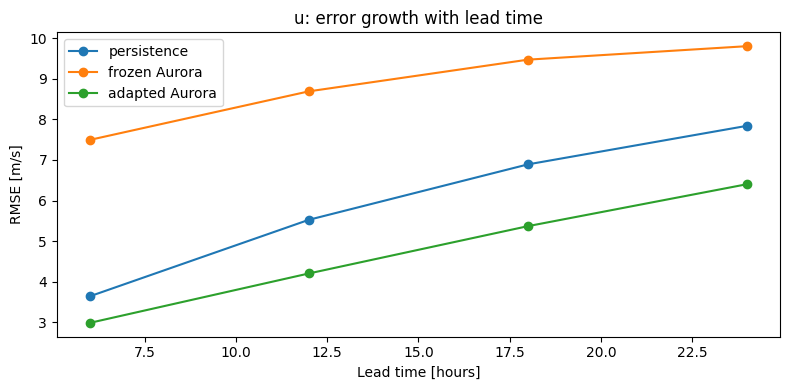

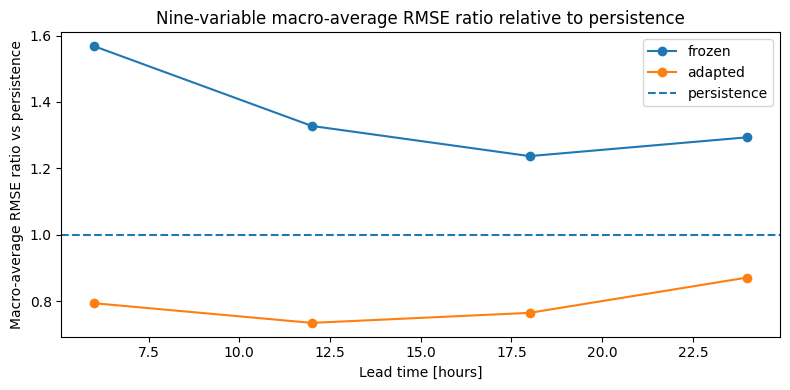

In [ ]:
# @title Lead-time curves for headline variables
for variable in ("2t", "msl", "z500", "u"):
    block = variable_table[variable_table["variable"] == variable].copy()
    leads = block["lead"].str.replace("h", "", regex=False).astype(int)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(leads, block["persistence_rmse"], marker="o", label="persistence")
    ax.plot(leads, block["frozen_rmse"], marker="o", label="frozen Aurora")
    ax.plot(leads, block["adapted_rmse"], marker="o", label="adapted Aurora")
    ax.set_xlabel("Lead time [hours]")
    ax.set_ylabel(f"RMSE [{block['unit'].iloc[0]}]")
    ax.set_title(f"{variable}: error growth with lead time")
    ax.legend()
    plt.tight_layout()
    plt.savefig(produced(OUTPUT_ROOT / "figures" / f"lead_rmse_{variable}.png"), dpi=150, bbox_inches="tight")
    plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison["lead_hours"], comparison["frozen_mean_rmse_ratio"], marker="o", label="frozen")
ax.plot(comparison["lead_hours"], comparison["adapted_mean_rmse_ratio"], marker="o", label="adapted")
ax.axhline(1.0, linestyle="--", label="persistence")
ax.set_xlabel("Lead time [hours]")
ax.set_ylabel("Macro-average RMSE ratio vs persistence")
ax.set_title("Nine-variable macro-average RMSE ratio relative to persistence")
ax.legend()
plt.tight_layout()
plt.savefig(produced(OUTPUT_ROOT / "figures" / "test_mean_skill.png"), dpi=150, bbox_inches="tight")
plt.show()

# 17. Spatial forecast and error maps

A global mean can hide large regional differences.

For the first frozen test origin, compare the forecasts at the longest evaluated lead (24 hours by default):

- ERA5 analysis;
- persistence;
- frozen forecast;
- adapted forecast;
- frozen absolute error;
- adapted absolute error.

The images remain on the native **1.5° tutorial grid**. They are not visually interpolated to pretend that 0.25° detail exists.

The four state panels share one colour scale, and the two absolute-error panels share another. Equal colours therefore mean equal values across the panels you compare. The title gives the origin and valid time.

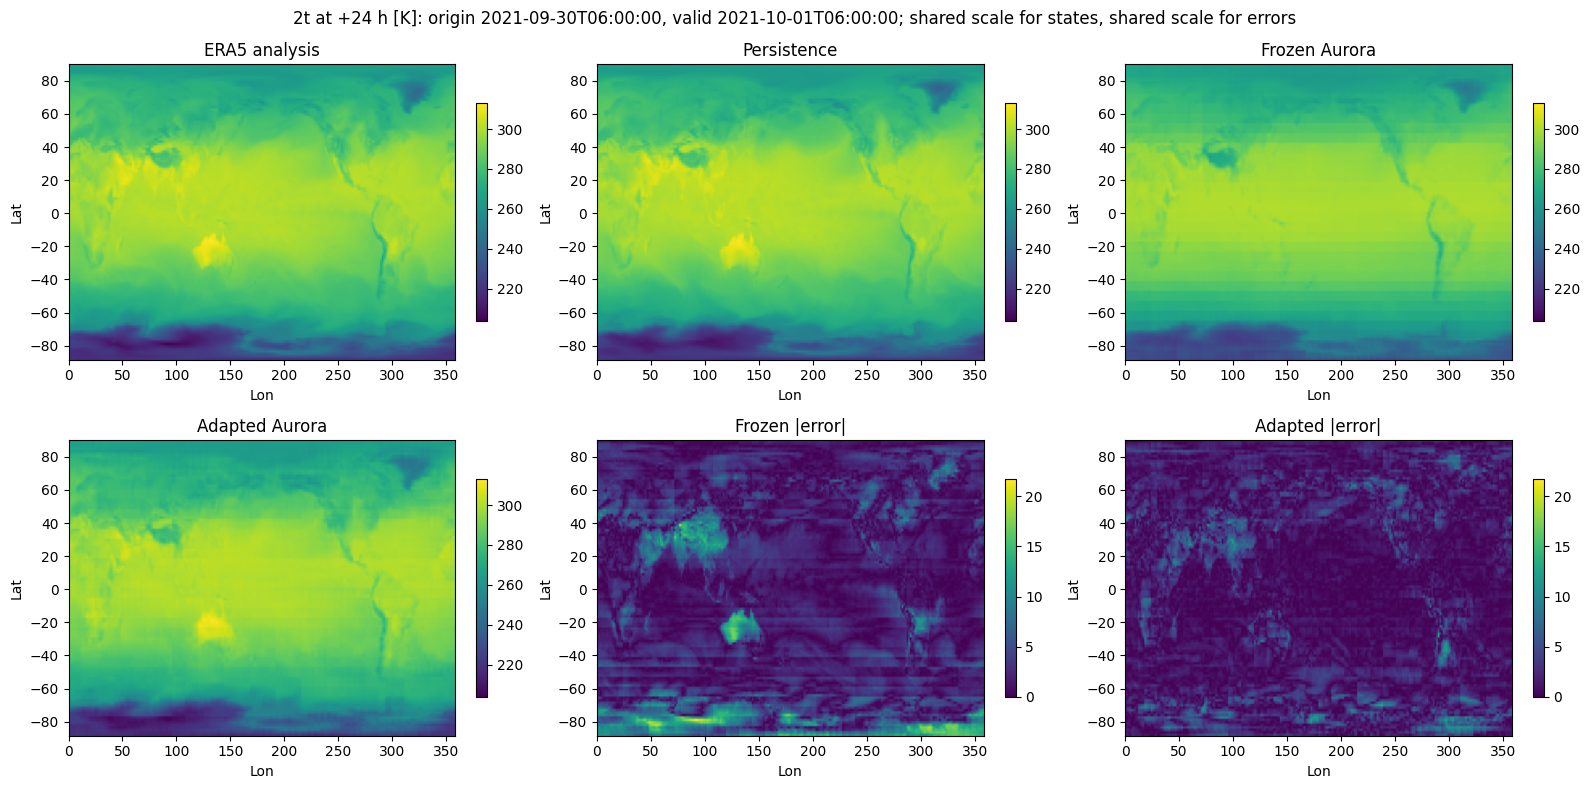

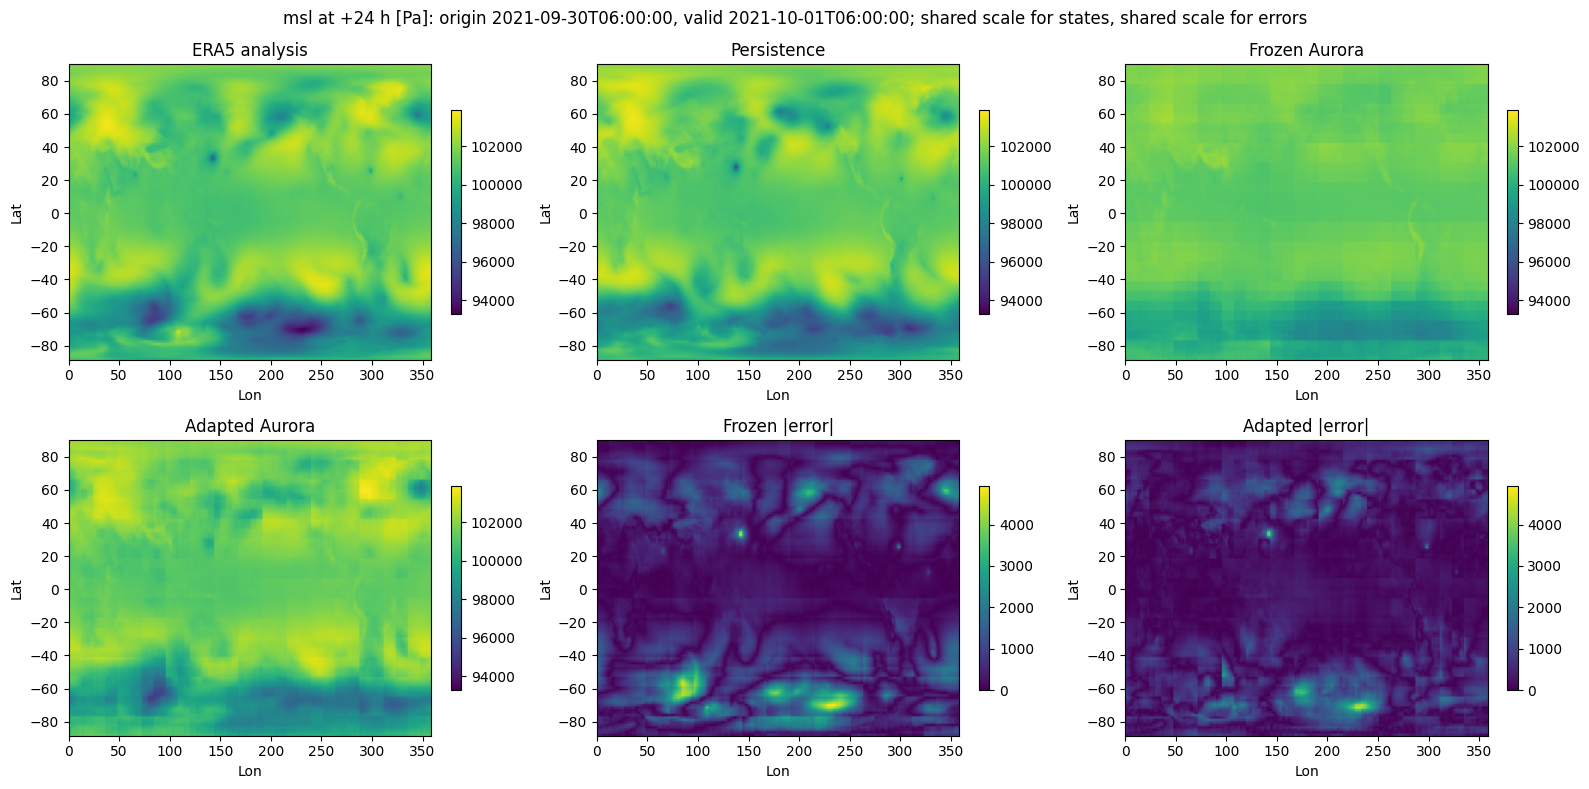

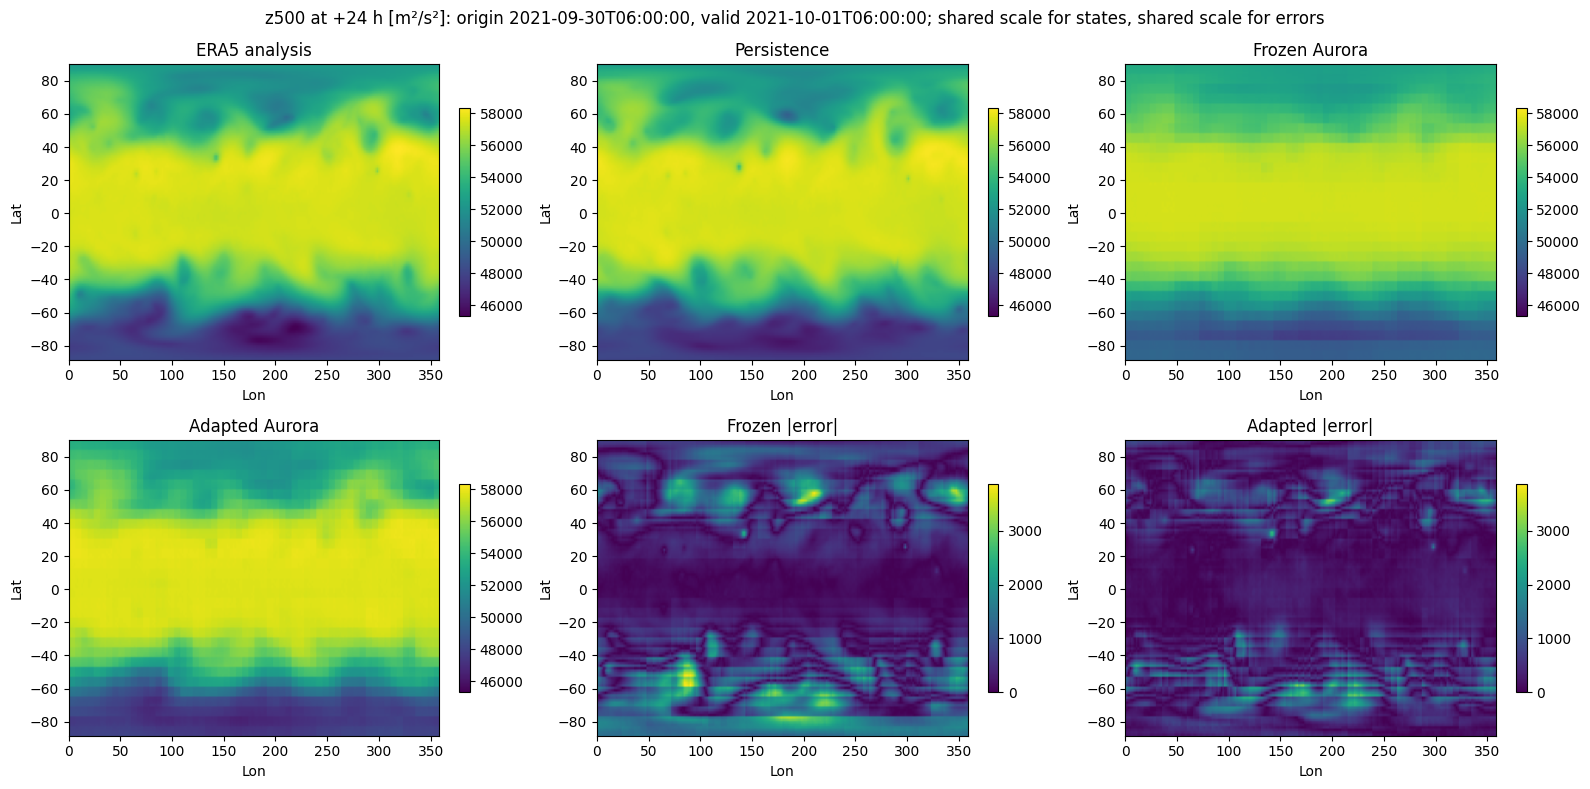

In [ ]:
# @title Spatial maps at the longest evaluated lead
MAP_ORIGIN = TEST_ORIGINS[0]
MAP_STEPS = TEST_LEAD_STEPS

frozen_preds = forecast_from_origin(fresh_frozen_model, test_window, MAP_ORIGIN, MAP_STEPS)
adapted_preds = forecast_from_origin(adapted_model, test_window, MAP_ORIGIN, MAP_STEPS)
height = test_window["shape"][0] - (test_window["shape"][0] % PATCH_SIZE)
frozen_last = forecast_arrays(frozen_preds, test_window, MAP_ORIGIN)[-1]
adapted_last = forecast_arrays(adapted_preds, test_window, MAP_ORIGIN)[-1]
check_forecast_fields(frozen_last, test_window, height, "frozen map forecast")
check_forecast_fields(adapted_last, test_window, height, "adapted map forecast")

lat_map = test_window["lat"][:height]
lon_map = test_window["lon"]
extent = [lon_map[0], lon_map[-1], lat_map[-1], lat_map[0]]
truth_idx = MAP_ORIGIN + MAP_STEPS
z500_idx = LEVELS.index(500)
map_hours = MAP_STEPS * TIMESTEP_HOURS

spatial_cases = {
    "2t": {
        "truth": test_window["surf"]["2t"][truth_idx, :height],
        "persistence": test_window["surf"]["2t"][MAP_ORIGIN, :height],
        "frozen": frozen_last["surf"]["2t"],
        "adapted": adapted_last["surf"]["2t"],
        "unit": "K",
    },
    "msl": {
        "truth": test_window["surf"]["msl"][truth_idx, :height],
        "persistence": test_window["surf"]["msl"][MAP_ORIGIN, :height],
        "frozen": frozen_last["surf"]["msl"],
        "adapted": adapted_last["surf"]["msl"],
        "unit": "Pa",
    },
    "z500": {
        "truth": test_window["atmos"]["z"][truth_idx, z500_idx, :height],
        "persistence": test_window["atmos"]["z"][MAP_ORIGIN, z500_idx, :height],
        "frozen": frozen_last["atmos"]["z"][z500_idx],
        "adapted": adapted_last["atmos"]["z"][z500_idx],
        "unit": "m²/s²",
    },
}

for name, case in spatial_cases.items():
    frozen_err = np.abs(case["frozen"] - case["truth"])
    adapted_err = np.abs(case["adapted"] - case["truth"])
    # One colour scale for the four state panels and a second, shared one for both error panels,
    # so equal colours mean equal values across the panels being compared.
    state_lo = min(float(np.min(case[k])) for k in ("truth", "persistence", "frozen", "adapted"))
    state_hi = max(float(np.max(case[k])) for k in ("truth", "persistence", "frozen", "adapted"))
    err_hi = max(float(np.max(frozen_err)), float(np.max(adapted_err)))
    fields = [
        ("ERA5 analysis", case["truth"], (state_lo, state_hi)),
        ("Persistence", case["persistence"], (state_lo, state_hi)),
        ("Frozen Aurora", case["frozen"], (state_lo, state_hi)),
        ("Adapted Aurora", case["adapted"], (state_lo, state_hi)),
        ("Frozen |error|", frozen_err, (0.0, err_hi)),
        ("Adapted |error|", adapted_err, (0.0, err_hi)),
    ]
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    for ax, (title, field, (vmin, vmax)) in zip(axes.ravel(), fields, strict=True):
        im = ax.imshow(field, extent=extent, aspect="auto", vmin=vmin, vmax=vmax)
        ax.set_title(title)
        ax.set_xlabel("Lon")
        ax.set_ylabel("Lat")
        plt.colorbar(im, ax=ax, fraction=0.026)
    fig.suptitle(
        f"{name} at +{map_hours} h [{case['unit']}]: origin {test_window['times'][MAP_ORIGIN]}, "
        f"valid {test_window['times'][truth_idx]}; shared scale for states, shared scale for errors"
    )
    plt.tight_layout()
    plt.savefig(produced(OUTPUT_ROOT / "figures" / f"spatial_{map_hours}h_{name}.png"), dpi=140, bbox_inches="tight")
    plt.show()

# 18. New-origin forecast

The rollout length is `FUTURE_FORECAST_STEPS` (24 hours by default, up to 48 hours). It is separate from the scored `MAX_LEAD_STEPS`, because no reference analysis exists for these valid times.

The final two analyses of the test window are now treated as the initial condition for a forecast extending beyond the supplied reference period.

Because the future analyses are not part of the sample:

**evaluation status = not measurable yet**

The summary reports **area-weighted** (cosine-latitude) global means. `forecast_fields.npz` is a **2 m temperature-only** sample export. It carries latitude, longitude, origin and valid times, lead hours and units, so every value can be placed. It is not a complete forecast state and not a georeferenced GIS product.

In [ ]:
# @title Forecast beyond the available window
NEW_ORIGIN = test_window["n_steps"] - 1
future_preds = forecast_from_origin(adapted_model, test_window, NEW_ORIGIN, FUTURE_FORECAST_STEPS)
future_fields = forecast_arrays(future_preds, test_window, NEW_ORIGIN)
future_height = test_window["shape"][0] - (test_window["shape"][0] % PATCH_SIZE)
future_lat = test_window["lat"][:future_height]
for step, fields in enumerate(future_fields, start=1):
    check_forecast_fields(fields, test_window, future_height, f"future +{step * TIMESTEP_HOURS} h")
z500_idx = LEVELS.index(500)

def area_weighted_mean(field, lat):
    """Cosine-latitude area-weighted global mean of a (lat, lon) field."""
    field = np.asarray(field, dtype=np.float64)
    w = np.cos(np.deg2rad(np.asarray(lat, dtype=np.float64)))[:, None]
    return float((field * w).sum() / (w.sum() * field.shape[-1]))

future_start = datetime.fromisoformat(test_window["times"][NEW_ORIGIN])
future_valid = [
    (future_start + timedelta(hours=TIMESTEP_HOURS * step)).strftime("%Y-%m-%dT%H:%M:%S")
    for step in range(1, FUTURE_FORECAST_STEPS + 1)
]
future_summary = []
for step, fields in enumerate(future_fields, start=1):
    future_summary.append({
        "lead_hours": step * 6,
        "origin_time": test_window["times"][NEW_ORIGIN],
        "valid_time": future_valid[step - 1],
        "area_weighted_mean_2t_K": area_weighted_mean(fields["surf"]["2t"], future_lat),
        "area_weighted_mean_msl_Pa": area_weighted_mean(fields["surf"]["msl"], future_lat),
        "area_weighted_mean_z500_m2_s2": area_weighted_mean(fields["atmos"]["z"][z500_idx], future_lat),
        "evaluation_status": "not-measurable",
    })

future_df = pd.DataFrame(future_summary)
display(future_df)
future_df.to_csv(produced(OUTPUT_ROOT / "future" / "forecast_summary.csv"), index=False)

# A 2 m temperature-only sample export, with the coordinates and times needed to place every value.
np.savez_compressed(
    produced(OUTPUT_ROOT / "future" / "forecast_fields.npz"),
    **{
        f"lead_{(i+1)*6}h_2t": fields["surf"]["2t"]
        for i, fields in enumerate(future_fields)
    },
    latitude=np.asarray(future_lat, dtype=np.float64),
    longitude=np.asarray(test_window["lon"], dtype=np.float64),
    origin_time=np.asarray(test_window["times"][NEW_ORIGIN]),
    valid_times=np.asarray(future_valid),
    lead_hours=np.asarray([6 * (i + 1) for i in range(FUTURE_FORECAST_STEPS)]),
    units=np.asarray("K"),
    scope=np.asarray("2 m temperature only: a sample export, not a complete forecast state; not georeferenced GIS output"),
)

,lead_hours,origin_time,valid_time,area_weighted_mean_2t_K,area_weighted_mean_msl_Pa,area_weighted_mean_z500_m2_s2,evaluation_status
0,6,2021-10-01T18:00:00,2021-10-02T00:00:00,287.844916,101180.124315,55731.184975,not-measurable
1,12,2021-10-01T18:00:00,2021-10-02T06:00:00,288.041915,101203.215088,55765.369312,not-measurable
2,18,2021-10-01T18:00:00,2021-10-02T12:00:00,288.832858,101210.112820,55809.029294,not-measurable
3,24,2021-10-01T18:00:00,2021-10-02T18:00:00,288.696581,101226.422478,55828.024426,not-measurable


# 19. Export the LoRA adapter

The adapter contains only tensors permitted by the selected adaptation scope.

Canonical LoRA-only output is roughly 2 MB, far smaller than the 451 MB base checkpoint.

The manifest uses the DIMER Aurora carrier's adapter format (`org.valcorza.aurora-earth-system.adapter.v1`). It records the base model identity, including the **converted-base digests** that section 4 computed and verified, so an adapter cannot silently float across a different Aurora base. The carrier's consumer (`AuroraPipeline.from_artifact` / `load_artifact`) requires exactly those digests.

The manifest also records the source checkpoint and static-file digests, the adaptation scope, the tensor list, the training history and a digest of the selected adapter tensors. That tensor digest must equal the one frozen before the test.

In [ ]:
# @title SafeTensors adapter export
from safetensors.torch import save_file, load_file

ARTIFACT_DIR = OUTPUT_ROOT / "artifacts" / "aurora_lora"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
adapter_path = ARTIFACT_DIR / ARTIFACT_WEIGHTS_NAME

wanted = set(adaptation["trainable_names"])
adapter_tensors = {
    k: v.detach().cpu().contiguous()
    for k, v in adapted_model.state_dict().items()
    if k in wanted
}
if sorted(adapter_tensors) != sorted(wanted):
    raise RuntimeError("adapter tensor scope mismatch")

save_file(adapter_tensors, str(produced(adapter_path)), metadata={"format": "pt"})

def build_adapter_manifest(adapter_path, tensor_names, adaptation, selected_state_sha256):
    """The carrier's adapter.v1 manifest. The converted-base digests are the ones verified in section 4."""
    return {
        "format": ARTIFACT_FORMAT,
        "format_version": ARTIFACT_FORMAT_VERSION,
        "base_model": {
            "id": MODEL_ID,
            "revision": MODEL_REVISION,
            "key": MODEL_KEY,
            "converted_sha256": dict(CONVERTED_SHA256),
            "checkpoint_name": CHECKPOINT_NAME,
            "checkpoint_sha256": CHECKPOINT_SHA256,
            "static_name": STATIC_NAME,
            "static_sha256": STATIC_SHA256,
        },
        "adapter": {
            "trainable": adaptation["trainable"],
            "n_tensors": len(tensor_names),
            "n_trainable": adaptation["n_trainable"],
            "n_parameters": adaptation["n_trainable"],
            "epochs": adaptation["epochs"],
            "patience": adaptation["patience"],
            "epochs_run": adaptation["epochs_run"],
            "best_epoch": adaptation["best_epoch"],
            "learning_rate": adaptation["learning_rate"],
            "seed": adaptation["seed"],
            "loss_scales": adaptation["loss_scales"],
            "selected_state_sha256": selected_state_sha256,
        },
        "history": adaptation["history"],
        "tensors": sorted(tensor_names),
        "files": [{
            "path": ARTIFACT_WEIGHTS_NAME,
            "bytes": Path(adapter_path).stat().st_size,
            "sha256": sha256_file(adapter_path),
        }],
        "metadata": {
            "producer": "DIMER weather and Earth-system forecasting workshop notebook",
            "run_id": RUN_ID,
            "base_conversion": "converted in this notebook from the pinned, pickle-audited source files; "
                               "both converted files matched the pinned digests",
            "training_static_fields": "static fields of the training windows (WeatherBench2 1.5° for the built-in sample)",
        },
    }

artifact_manifest = build_adapter_manifest(
    adapter_path,
    list(adapter_tensors),
    adaptation,
    tensor_state_digest(adapter_tensors),
)
if artifact_manifest["adapter"]["selected_state_sha256"] != frozen_record["selected_adapter"]["state_sha256"]:
    raise RuntimeError("the exported adapter tensors are not the ones frozen before the test")
produced(ARTIFACT_DIR / "manifest.json").write_text(
    json.dumps(artifact_manifest, indent=2), encoding="utf-8"
)

print(artifact_manifest["files"][0])

{'path': 'adapter.safetensors', 'bytes': 2173200, 'sha256': '8b15af4d2d0fa60148094de2c9046d0a47cbebb3c971f7297847b66c15d426bf'}


# 20. Fresh-boundary reload verification

A valid artifact is more than a file that deserializes.

The notebook reconstructs a fresh LoRA-capable Aurora from the verified base checkpoint, loads exactly the declared adapter tensors, and repeats one fixed forecast.

Before loading, the notebook copies the artifact into a **fresh directory**. It applies the same static checks as the carrier's consumer: format and version, the pinned base including the converted-base digests, one weights file inside the directory, the declared scope and exact tensor list, and the file digest.

The adapted and reloaded outputs must both be **finite**, carry the expected valid time, and match within a strict numerical tolerance. A non-finite difference is a failure, not a pass.

In [ ]:
# @title Fresh reload and parity
import math
import shutil
import tempfile

def check_adapter_manifest(root, manifest, expected_tensors):
    """The carrier consumer's static checks, plus the tensor scope and file digest.

    Format and version; the pinned base, including the converted-base digests; exactly one weights file,
    named adapter.safetensors, inside the artifact directory; a declared adaptation scope; the exact tensor
    list that scope may change; and the file's size and SHA-256. Returns the weights path and the scope."""
    root = Path(root)
    if manifest.get("format") != ARTIFACT_FORMAT:
        raise ValueError(f"artifact format {manifest.get('format')!r} != {ARTIFACT_FORMAT!r}")
    if manifest.get("format_version") != ARTIFACT_FORMAT_VERSION:
        raise ValueError(f"artifact format_version {manifest.get('format_version')!r} is not supported")
    base = manifest.get("base_model") or {}
    if (base.get("id"), base.get("revision")) != (MODEL_ID, MODEL_REVISION):
        raise ValueError("adapter base revision mismatch")
    if base.get("converted_sha256") != CONVERTED_SHA256:
        raise ValueError("artifact records different converted-base digests")
    if base.get("checkpoint_sha256") != CHECKPOINT_SHA256:
        raise ValueError("adapter base digest mismatch")
    files = manifest.get("files")
    if not isinstance(files, list) or len(files) != 1:
        raise ValueError("artifact manifest must list exactly one weights file")
    entry = files[0]
    if not isinstance(entry, dict) or entry.get("path") != ARTIFACT_WEIGHTS_NAME:
        raise ValueError(f"artifact weights file must be named {ARTIFACT_WEIGHTS_NAME!r}")
    weights = (root / entry["path"]).resolve()
    if weights.parent != root.resolve():
        raise ValueError("artifact weights file must sit inside the artifact directory")
    mode = (manifest.get("adapter") or {}).get("trainable")
    if mode not in ADAPTATION_MODES:
        raise ValueError("artifact adapter.trainable must be exactly 'lora' or 'lora+heads'")
    if not isinstance(manifest.get("tensors"), list) or sorted(manifest["tensors"]) != sorted(expected_tensors):
        raise ValueError("adapter tensor manifest mismatch")
    if not weights.is_file() or weights.stat().st_size != entry.get("bytes") or sha256_file(weights) != entry.get("sha256"):
        raise ValueError("adapter digest/size mismatch")
    return weights, mode

def parity_report(reference, candidate, tolerance):
    """Largest absolute difference per group, after requiring the same variables, shapes and finite values."""
    diffs = {}
    for group in ("surf", "atmos"):
        if set(reference[group]) != set(candidate[group]):
            raise ValueError(f"fresh reload parity failed: {group} variables differ")
        worst = 0.0
        for name in reference[group]:
            a = np.asarray(reference[group][name], dtype=np.float64)
            b = np.asarray(candidate[group][name], dtype=np.float64)
            if a.shape != b.shape:
                raise ValueError(f"fresh reload parity failed: {group}/{name} shapes {a.shape} != {b.shape}")
            if not (np.isfinite(a).all() and np.isfinite(b).all()):
                raise ValueError(f"fresh reload parity failed: {group}/{name} contains non-finite values")
            worst = max(worst, float(np.max(np.abs(a - b))) if a.size else 0.0)
        diffs[group] = worst
    if not all(math.isfinite(v) for v in diffs.values()) or max(diffs.values()) > tolerance:
        raise RuntimeError(f"fresh reload parity failed: surf={diffs['surf']}, atmos={diffs['atmos']}")
    return {
        "max_abs_surf_diff": diffs["surf"],
        "max_abs_atmos_diff": diffs["atmos"],
        "tolerance": tolerance,
        "status": "PASS",
    }

# Consume the artifact the way a downstream user would: copied into a fresh directory, checked, then loaded.
fresh_artifact_dir = Path(tempfile.mkdtemp(prefix="aurora_adapter_reload_"))
for name in (ARTIFACT_WEIGHTS_NAME, "manifest.json"):
    shutil.copy2(ARTIFACT_DIR / name, fresh_artifact_dir / name)

reloaded_model = build_aurora(use_lora=True)
manifest = json.loads((fresh_artifact_dir / "manifest.json").read_text(encoding="utf-8"))
declared_mode = (manifest.get("adapter") or {}).get("trainable")
expected_tensors = trainable_names(reloaded_model, declared_mode) if declared_mode in ADAPTATION_MODES else []
fresh_weights, _mode = check_adapter_manifest(fresh_artifact_dir, manifest, expected_tensors)

loaded = load_file(str(fresh_weights))
if sorted(loaded) != sorted(manifest["tensors"]):
    raise ValueError("adapter tensor manifest mismatch")

state = reloaded_model.state_dict()
for key, value in loaded.items():
    if tuple(value.shape) != tuple(state[key].shape):
        raise ValueError(f"{key}: adapter shape mismatch")
merged = dict(state)
merged.update({k: v.to(state[k].dtype) for k, v in loaded.items()})
reloaded_model.load_state_dict(merged, strict=True)
reloaded_model.eval()

VERIFY_ORIGIN = 1
VERIFY_STEPS = 1
a = forecast_arrays(forecast_from_origin(adapted_model, val_window, VERIFY_ORIGIN, VERIFY_STEPS), val_window, VERIFY_ORIGIN)[0]
b = forecast_arrays(forecast_from_origin(reloaded_model, val_window, VERIFY_ORIGIN, VERIFY_STEPS), val_window, VERIFY_ORIGIN)[0]

RELOAD_TOLERANCE = 1e-6
reload_report = parity_report(a, b, RELOAD_TOLERANCE)
reload_report["consumer_checks"] = {
    "fresh_directory": True,
    "format": manifest["format"],
    "converted_base_digests_match": True,
    "tensor_scope": declared_mode,
    "n_tensors": len(loaded),
}
surf_diff = reload_report["max_abs_surf_diff"]
atmos_diff = reload_report["max_abs_atmos_diff"]
print(reload_report)

{'max_abs_surf_diff': 0.0, 'max_abs_atmos_diff': 0.0, 'tolerance': 1e-06, 'status': 'PASS', 'consumer_checks': {'fresh_directory': True, 'format': 'org.valcorza.aurora-earth-system.adapter.v1', 'converted_base_digests_match': True, 'tensor_scope': 'lora', 'n_tensors': 80}}


# 21. BYOD contract

Full BYOD E2E mode requires **four NetCDF windows**:

- two training windows;
- one validation window;
- one test window, later than and separate from the other three.

The accepted schema uses:

### Coordinates

`time`, `latitude`, `longitude`, `level`

### Surface fields

`2t`, `10u`, `10v`, `msl`  
(or `surf_2t`, `surf_10u`, ...)

### Atmospheric fields

`t`, `u`, `v`, `q`, `z`  
(or `atmos_t`, ...)

### Static fields

`static_lsm`, `static_z`, `static_slt`

### Dimensions

Surface variables use `(time, latitude, longitude)`, atmospheric variables use `(time, level, latitude, longitude)`, and static fields use `(latitude, longitude)`. Any stored order is accepted, because every variable is transposed **by dimension name**. A variable with other or extra dimensions is refused. Each coordinate must be a 1-D coordinate along its own dimension.

### Units

`2t`, `t` K; `10u`, `10v`, `u`, `v` m/s; `msl` Pa; `q` kg/kg; `z` and `static_z` m²/s²; `static_lsm` a 0–1 fraction; `static_slt` a soil-type code. Values outside the plausible ranges in section 3 are refused: correct the units rather than widening the validator.

### Grid

All four windows use **one regular global grid** with identical coordinates:

- latitude from 90 to −90 (either direction), uniformly spaced, with H mod 4 in {0, 1};
- longitude in **[0, 360)**, uniformly spaced, covering the full circle, with W divisible by 4;
- H and W within 17..721 and 32..1440.

Regional and −180..180 grids are refused; shift a −180..180 grid and its fields to 0..360 first. All four windows must also carry identical static fields and exactly the 13 Aurora pressure levels, in the order listed in section 3.

### Role independence

- The four windows must not share any analysis time.
- Every training analysis must precede the validation window, and validation must precede test.
- No analysis's fields may repeat across roles under another timestamp.

The dataset manifest records each role's time span and name-independent content digest.

### Length

Each window holds 3..64 six-hourly analyses. The validation and test windows also need `2 + MAX_LEAD_STEPS` analyses: 6 for the default 24-hour evaluation, 10 for 48 hours. A shorter window is refused before any model is loaded.

### Example layout

```python
xr.Dataset(
    {"2t": (("time", "latitude", "longitude"), t2m), "t": (("time", "level", "latitude", "longitude"), temperature),
     "static_lsm": (("latitude", "longitude"), lsm), ...},
    coords={"time": times, "level": list(LEVELS), "latitude": lat, "longitude": lon},
).to_netcdf("train_1.nc")
```

BYOD results are labelled with your windows' names, periods and resolution. The built-in sample's headings (30 September–1 October 2021, 1.5°) describe only the default run.

### Data privacy

BYOD files are processed in the selected notebook runtime and are not sent to DIMER workers or APIs. A hosted notebook remains an external compute environment. Do not upload confidential, embargoed, proprietary, security-sensitive, or operational forecast data unless authorized.

# 22. Optional experiments

### A. LoRA versus LoRA + heads

Set:

`TRAINABLE = "lora+heads"`

and rerun from the top.

`lora+heads` trains the LoRA tensors, the decoder output heads **and the encoder token embeddings** (`encoder.surf_token_embeds`, `encoder.atmos_token_embeds`), not only the heads.

This changes the adaptation scope and must be selected on validation only. Do not compare several scopes on the test window and keep the best one.

### B. Longer rollouts

Forecast **generation** and forecast **evaluation** have different limits:

- **Scored leads:** one origin needs two history analyses plus one target analysis per lead. The built-in eight-analysis windows can therefore score at most **36 hours** (6 steps), from a single origin. A 42- or 48-hour evaluation has **no** reference target in the sample, so the preflight refuses it before any model loads.
- **Unscored forecasts:** `FUTURE_FORECAST_STEPS` (section 18) can roll out to 48 hours; its status is *not measurable*.

The activity cell below scores 6 h up to `ACTIVITY_LEAD_STEPS` × 6 h on **one fixed set of origins**, so every lead is compared on the same initial conditions. Changing `MAX_LEAD_STEPS` itself would also change which origins are scored. The activity writes to its own `activity/` directory, leaves every canonical result unchanged (it checks this), and is packaged separately in the report. With one or two origins, its results are diagnostic, not statistical evidence.

### C. Latitude bands

A useful extension is to break RMSE into:

- 90–60°N
- 60–30°N
- 30°N–30°S
- 30–60°S
- 60–90°S

One two-day evaluation window cannot establish regional forecast quality.

In [ ]:
# @title Optional activity: longer rollouts on one fixed set of origins
RUN_LONGER_ROLLOUT_ACTIVITY = False  # @param {type:"boolean"}
ACTIVITY_LEAD_STEPS = 6              # @param {type:"integer"}
ACTIVITY_WINDOW = "validation"       # @param ["validation", "test"]

activity_result = None
if not RUN_LONGER_ROLLOUT_ACTIVITY:
    print(
        "Activity not run. Tick RUN_LONGER_ROLLOUT_ACTIVITY, then run this cell (or Run all) to compare every lead "
        "from 6 h to ACTIVITY_LEAD_STEPS x 6 h on the same forecast origins."
    )
else:
    if ACTIVITY_WINDOW not in ("validation", "test"):
        raise ValueError("ACTIVITY_WINDOW must be 'validation' or 'test'")
    activity_window = {"validation": val_window, "test": test_window}[ACTIVITY_WINDOW]
    longest = activity_window["n_steps"] - HISTORY_STEPS
    if not 1 <= ACTIVITY_LEAD_STEPS <= min(8, longest):
        raise ValueError(
            f"ACTIVITY_LEAD_STEPS = {ACTIVITY_LEAD_STEPS} ({ACTIVITY_LEAD_STEPS * TIMESTEP_HOURS} h) is not measurable on the "
            f"{ACTIVITY_WINDOW} window: it has {activity_window['n_steps']} analyses, so the longest scored lead is "
            f"{longest * TIMESTEP_HOURS} h. Longer leads have no ERA5 target in this sample; use FUTURE_FORECAST_STEPS "
            "for an unscored forecast."
        )
    activity_origins = eval_origins(activity_window, ACTIVITY_LEAD_STEPS)

    # Snapshot the canonical results: files already written by this run, and the in-memory test summaries.
    canonical_files = {key: sha256_file(key) for key in PRODUCED if Path(key).is_file()}
    canonical_state = json.dumps(
        {"frozen_test": frozen_test["summary"], "adapted_test": adapted_test["summary"], "test_lead_steps": TEST_LEAD_STEPS},
        sort_keys=True, default=str,
    )

    activity_frozen = evaluate_model(fresh_frozen_model, activity_window, ACTIVITY_LEAD_STEPS, origins=activity_origins)
    activity_adapted = evaluate_model(adapted_model, activity_window, ACTIVITY_LEAD_STEPS, origins=activity_origins)

    if {key: sha256_file(key) for key in canonical_files} != canonical_files or json.dumps(
        {"frozen_test": frozen_test["summary"], "adapted_test": adapted_test["summary"], "test_lead_steps": TEST_LEAD_STEPS},
        sort_keys=True, default=str,
    ) != canonical_state:
        raise RuntimeError("the activity changed a canonical result; this must not happen")

    activity_hours = ACTIVITY_LEAD_STEPS * TIMESTEP_HOURS
    activity_dir = OUTPUT_ROOT / "activity" / f"longer_rollout_{activity_hours}h_{ACTIVITY_WINDOW}"
    activity_dir.mkdir(parents=True, exist_ok=True)
    activity_table = pd.DataFrame([
        {
            "lead_hours": int(lead[:-1]),
            "frozen_mean_rmse_ratio": activity_frozen["summary"][lead]["mean_skill"],
            "adapted_mean_rmse_ratio": activity_adapted["summary"][lead]["mean_skill"],
            "frozen_vars_beating_persistence": activity_frozen["summary"][lead]["variables_beating_persistence"],
            "adapted_vars_beating_persistence": activity_adapted["summary"][lead]["variables_beating_persistence"],
            "n_origins": activity_frozen["n_origins"],
        }
        for lead in activity_frozen["leads"]
    ])
    activity_receipt = {
        "activity": "longer rollouts on one fixed set of origins",
        "window_role": ACTIVITY_WINDOW,
        "window_name": activity_window["name"],
        "window_content_sha256": window_content_digest(activity_window),
        "lead_steps": ACTIVITY_LEAD_STEPS,
        "lead_hours": activity_hours,
        "origins": activity_origins,
        "origin_times": [activity_window["times"][o] for o in activity_origins],
        "canonical_results_unchanged": True,
        "evidence_status": "exploratory diagnostic; not the frozen canonical test result",
        "output_dir": str(activity_dir),
    }
    produced(activity_dir / "metrics.json").write_text(
        json.dumps({"receipt": activity_receipt, "frozen": activity_frozen, "adapted": activity_adapted}, indent=2),
        encoding="utf-8",
    )
    activity_table.to_csv(produced(activity_dir / "lead_table.csv"), index=False)

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(activity_table["lead_hours"], activity_table["frozen_mean_rmse_ratio"], marker="o", label="frozen")
    ax.plot(activity_table["lead_hours"], activity_table["adapted_mean_rmse_ratio"], marker="o", label="adapted")
    ax.axhline(1.0, linestyle="--", label="persistence")
    ax.set_xlabel("Lead time [hours]")
    ax.set_ylabel("Mean RMSE ratio vs persistence")
    ax.set_title(f"Activity: {ACTIVITY_WINDOW} window, {len(activity_origins)} fixed origin(s), up to {activity_hours} h")
    ax.legend()
    plt.tight_layout()
    plt.savefig(produced(activity_dir / "lead_skill.png"), dpi=150, bbox_inches="tight")
    plt.show()

    print(activity_table.to_string(index=False))
    if ACTIVITY_WINDOW == "test":
        print("The test window was already inspected in section 15: treat this as exploratory, not a new held-out result.")
    print({k: activity_receipt[k] for k in ("window_role", "lead_hours", "origin_times", "canonical_results_unchanged")})
    activity_result = {"receipt": activity_receipt, "table": activity_table.to_dict("records")}

Activity not run. Tick RUN_LONGER_ROLLOUT_ACTIVITY, then run this cell (or Run all) to compare every lead from 6 h to ACTIVITY_LEAD_STEPS x 6 h on the same forecast origins.


# 23. Interpretation and operational limits

### Small checkpoint

This notebook uses Aurora's small debugging/testing checkpoint, not the production-scale 1.3B model.

### Domain shift: a different data product

Every built-in metric is measured on WeatherBench2's conservatively regridded **1.5°** product, not on the data Aurora was trained on: a coarser grid, smoothed fields, regridded static fields (non-integer soil-type codes) and the small checkpoint. No matched control is run, so the notebook does not show how much of the frozen model's loss, or of the LoRA gain, comes from any one of these.

### ERA5 is the reference

ERA5 is a reanalysis produced by assimilating observations into a numerical weather model. Error here means error relative to ERA5, not error relative to direct observations.

### Deterministic forecast

This workflow provides no:

- ensemble spread;
- calibrated forecast uncertainty;
- probability of threshold exceedance; or
- confidence interval.

### One tiny, re-used test period

Two days (30 September–1 October 2021), already scored while the recipe was developed (section 14), cannot establish general forecast skill across:

- seasons;
- tropical cyclones;
- blocking events;
- regional extremes;
- different analysis products.

### Operational boundary

Do not use this notebook's output alone to issue or inform:

- public weather warnings;
- aviation decisions;
- marine routing;
- emergency management;
- energy dispatch;
- agricultural advisories; or
- other consequential weather decisions.

An operational workflow requires representative verification, uncertainty treatment, monitoring, appropriate fallback procedures, and qualified meteorological review.

## What did not work

These entries come from development of earlier blobs of this notebook. They are development evidence, not results of this run.

- **A fixed six-epoch recipe** (blobs up to `3b5dbc42`). *Tried:* six epochs inherited from the primary tutorial, keeping the epoch with the lowest validation loss. *Observed:* in every recorded run the selected epoch was the last one, 6, with validation loss still falling; the Colab CLI T4 run of revision `b5c8494` (2026-10-03) went from 0.0568 at epoch 5 to 0.0536 at epoch 6. *Why rejected:* the selection never chose anything, so the notebook could not show whether validation selection works. Replaced by up to 30 epochs with early stopping (patience 3).
- **Reading the frozen model's loss as a resolution effect** (blobs up to `09775738`). *Tried:* teaching the 1.5° grid as the cause of the frozen model's loss to persistence, and the LoRA gain as recovery from it. *Observed:* the comparison has no matched control, and the same product also regrids the static fields (soil-type codes averaged into non-integer values in about 26% of cells) and uses the small checkpoint (2026-10-13 review). *Why rejected:* the experiment cannot attribute the result to one component, so the notebook now presents it as a domain shift to a whole data product.

# 24. Exercises

Write your own answer before opening each sample answer.

### Exercise 1 — persistence

You answered this in section 10, before viewing any neural forecast: which atmospheric fields should persistence handle well at six hours? Check your answer against your run's 6 h rows.

<details>
<summary><b>Show a sample answer</b></summary>

Slowly evolving, large-scale fields: mid-tropospheric geopotential such as z500, mean sea-level pressure away from active storms, and upper-level temperature change little in six hours. Fields tied to the daily heating cycle (2 m temperature) or to moving weather systems (near-surface wind, humidity) change more, so persistence does worse on them, although at 24 h the daily cycle is approximately back in phase (section 15).

</details>

### Exercise 2 — domain shift

Why does changing from 0.25° to 1.5° alter the meaning of a 4×4 model token even though the input variables and units are unchanged? Why does that make grid spacing one plausible contributor to the domain shift here, but not a demonstrated cause?

<details>
<summary><b>Show a sample answer</b></summary>

A 4×4 token spans 1° × 1° at 0.25° but 6° × 6° at 1.5°, about 36 times the area, so the patterns inside a token are at a scale the embeddings never saw in training. That makes grid spacing a plausible contributor to the domain shift. It is not a demonstrated cause, because the same data product also regrids the static fields (soil-type codes become non-integer) and the notebook uses the small checkpoint, and no matched native-resolution run separates these effects.

</details>

### Exercise 3 — weighted RMSE

Why does cosine-latitude weighting matter for a regular lat/lon grid?

<details>
<summary><b>Show a sample answer</b></summary>

Every row of a regular grid has the same number of cells, but the area of a cell shrinks with cos(latitude). Without weighting, polar rows, which cover little of the Earth, would count as much as equatorial rows, and the global RMSE would not describe errors per unit of the Earth's surface.

</details>

### Exercise 4 — adaptation

If one-step validation loss improves, must the 24-hour autoregressive forecast also improve? Why not?

<details>
<summary><b>Show a sample answer</b></summary>

No. Training only scores the first 6 h step from true analyses. In a rollout, each later step starts from the model's own forecast, so small errors feed back and can grow in ways the one-step loss never saw. The training loss is also a scaled MSE over variables, not the latitude-weighted RMSE ratio reported at each lead, so the two can move differently.

</details>

### Exercise 5 — deployment

What additional verification would you require before using an adapted Earth-system model for a Philippine forecasting application?

<details>
<summary><b>Show a sample answer</b></summary>

Verification over many seasons and years, including typhoons and monsoon onsets; regional scores over the Philippines rather than global means; comparison against observations as well as reanalysis, and against the operational forecasts already in use; a fresh test period never used during development; uncertainty or ensemble information; and monitoring, fallback procedures and review by qualified meteorologists before any output informs a decision.

</details>

## 25. Export provenance and report bundle

The bundle contains **only the files this run produced**, listed with their SHA-256 in `run_inventory.json`, and its name carries the run ID. Files that earlier runs left in `OUTPUT_DIR` stay on disk but are not packaged as this run's results. If you run the optional activity after this cell, run this cell again to package it.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Final provenance export
import zipfile
from datetime import timezone

runtime_report = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

experiment_manifest = {
    "notebook_spec": "2.5",
    "notebook_profile": "E2E",
    "notebook_mode": "WORKSHOP",
    "workshop_revision": "0.1.0-candidate",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "model": {
        "id": MODEL_ID,
        "revision": MODEL_REVISION,
        "checkpoint": CHECKPOINT_NAME,
        "bytes": CHECKPOINT_BYTES,
        "sha256": CHECKPOINT_SHA256,
        "parameters": PARAMETER_COUNT,
        "small_debug_checkpoint": True,
    },
    "run_id": RUN_ID,
    "base_conversion": base_receipt,
    "dataset": dataset_manifest,
    "freeze": {
        "path": str(freeze_path),
        "experiment_sha256": frozen_record["experiment_sha256"],
        "test_lead_steps": TEST_LEAD_STEPS,
        "test_origins": TEST_ORIGINS,
    },
    "future_forecast": {"steps": FUTURE_FORECAST_STEPS, "evaluation_status": "not-measurable"},
    "optional_outputs": {
        "longer_rollout_activity": (activity_result or {}).get("receipt", "not run"),
    },
    "adaptation": {
        k: v for k, v in adaptation.items()
        if k != "trainable_names"
    },
    "test": {
        "comparison": comparison.to_dict("records"),
        "frozen_seconds": frozen_test_seconds,
        "adapted_seconds": adapted_test_seconds,
    },
    "artifact": artifact_manifest,
    "reload": reload_report,
    "runtime": runtime_report,
    "standalone_contract": {
        "git_clone_required": False,
        "dimer_source_runtime_fetch_required": False,
        "dimer_worker_required": False,
        "credentials_required": False,
        "default_upload_required": False,
    },
    "candidate_release_gates": [
        "fresh T4 Run all qualification",
        "reconcile anonymous xarray WeatherBench2 acquisition with the live DIMER 57-object digest-pinned data path",
        "record peak VRAM and wall times for the exact released notebook",
        "hosted qualification of BYOD NetCDF, the longer-rollout activity, and consumption of the exported adapter "
        "by aurora_earth_system_pipeline.AuroraPipeline.from_artifact",
    ],
    "evidence_scope": (
        "small Aurora checkpoint, real ERA5 via WeatherBench2 at out-of-distribution 1.5° resolution, "
        "two training windows, one validation window, one temporally separate, development-reused evaluation window (two days)"
    ),
    "evaluation_window": {
        "description": "temporally separate, development-reused evaluation window",
        "temporal_separation": "later than every training and validation analysis (enforced in section 6)",
        "development_reuse": "the built-in test window was scored in earlier runs of this notebook and used to develop the default recipe of the repository's primary tutorial; for BYOD, record your own history",
        "pretrained_checkpoint_exposure": "unknown: not established whether the pretrained checkpoint's training data include this period",
    },
}

produced(OUTPUT_ROOT / "provenance" / "experiment_manifest.json").write_text(
    json.dumps(experiment_manifest, indent=2, default=str),
    encoding="utf-8",
)
produced(OUTPUT_ROOT / "workshop_summary.json").write_text(
    json.dumps({
        "model": "Aurora 0.25° small pretrained",
        "test_comparison": comparison.to_dict("records"),
        "best_epoch": adaptation["best_epoch"],
        "trainable_parameters": adaptation["n_trainable"],
        "adapter_bytes": adapter_path.stat().st_size,
        "reload": reload_report,
    }, indent=2, default=str),
    encoding="utf-8",
)

def write_report_bundle(bundle_path, root, produced_paths, run_id):
    """Zip exactly the files this run produced, plus run_inventory.json with their sizes and SHA-256.
    Files from earlier runs that remain in OUTPUT_DIR are left on disk and are not packaged."""
    root = Path(root).resolve()
    inventory = []
    for path in sorted({Path(p).resolve() for p in produced_paths}):
        if not path.is_file():
            continue
        try:
            rel = path.relative_to(root).as_posix()
        except ValueError as exc:
            raise ValueError(f"{path} is outside the output directory {root}") from exc
        inventory.append({"path": rel, "bytes": path.stat().st_size, "sha256": sha256_file(path)})
    with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for entry in inventory:
            zf.write(root / entry["path"], entry["path"])
        zf.writestr("run_inventory.json", json.dumps({"run_id": run_id, "files": inventory}, indent=2))
    return inventory

bundle = str(Path(OUTPUT_DIR).resolve()) + f"_DIMER_Aurora_Weather_Workshop_Report_{RUN_ID}.zip"
bundle_inventory = write_report_bundle(bundle, OUTPUT_ROOT, list(PRODUCED), RUN_ID)

print({
    "experiment_manifest": str(OUTPUT_ROOT / "provenance" / "experiment_manifest.json"),
    "report_bundle": bundle,
    "report_sha256": sha256_file(bundle),
    "files_in_bundle": len(bundle_inventory),
    "optional_outputs": sorted(e["path"] for e in bundle_inventory if e["path"].startswith("activity/")) or "none",
})

{'experiment_manifest': 'outputs/provenance/experiment_manifest.json', 'report_bundle': '/content/outputs_DIMER_Aurora_Weather_Workshop_Report_20261014T142927Z-846.zip', 'report_sha256': 'ec7c599ab36db3cf78ed5ea51fa003548a6da0a9a312a6ca45fef6d99f95e3c6', 'files_in_bundle': 30, 'optional_outputs': 'none'}


# 26. Troubleshooting

| Symptom | Likely cause | Corrective action |
|---|---|---|
| CUDA unavailable | CPU runtime selected | switch to a T4-class GPU before running from the top |
| Section 1 stops: not Linux x86_64 | Windows or macOS kernel | use Google Colab, Kaggle or a Linux Jupyter server; the locked environment is built for manylinux x86_64 |
| Section 1: download, `uv` size/SHA-256 or hash failure | interrupted or altered download | run the cell again on a stable connection; never remove a pin or a hash |
| `The isolated environment's Python process exited` | the worker ran out of memory or was killed | restart the session and choose **Run all** again |
| `This Python environment does not hold the locked versions` | the environment folder holds other packages | run both section 1 cells again, or start a fresh runtime |
| Aurora checkpoint digest mismatch | changed/incomplete model asset | remove cached checkpoint and retry; never bypass the pin |
| anonymous GCS/Zarr open fails | transient WeatherBench2/GCS or package issue | retry in a fresh runtime; preserve the same store and role chunks |
| wrong pressure levels | incompatible dataset | provide exactly the 13 Aurora levels |
| longitude count rejected | grid incompatible with patch size | use a global grid whose longitude count is divisible by four |
| latitude count rejected | patch geometry mismatch | use a global grid with H mod 4 in {0,1} |
| temperature/pressure range rejection | wrong units or corrupt data | correct source units rather than widening the validator |
| frozen model loses to persistence | domain shift to the 1.5° WeatherBench2 data product (several differences, each a plausible contributor; not isolated here) | expected on the built-in sample; not an execution failure |
| LoRA validation worsens | adaptation did not help | epoch 0 remains a valid selection |
| training runs to epoch 30 and selects epoch 30 | the selection reached the budget, not a minimum | report it as such; raising `EPOCHS` (up to 50) changes the recipe and takes longer |
| test improves after tuning on it | test leakage | Treat this window as development/exploratory data after using it to choose settings; freeze the resulting recipe and evaluate on a genuinely untouched period. Keep the previous results and selection history. (The default recipe was itself developed on this window, see section 14.) |
| fresh reload mismatch | artifact/base mismatch or nondeterministic execution issue | stop and inspect model/artifact identity |
| BYOD path missing | full E2E role set incomplete | provide all four NetCDF role paths |
| `MAX_LEAD_STEPS ... cannot be evaluated` | the validation/test windows lack `2 + MAX_LEAD_STEPS` analyses | lower `MAX_LEAD_STEPS` (at most 6 on the built-in sample), supply longer windows, or use `FUTURE_FORECAST_STEPS` for an unscored forecast |
| roles share analysis times / same fields / chronological policy | BYOD windows overlap or are out of order | give each role different, non-overlapping periods: train before validation before test |
| coordinates or static fields differ from train-1 | the four windows are not on one grid | regrid all windows to one global grid with identical static fields |
| longitudes must lie in [0, 360) / cover the full circle | −180..180 or regional grid | shift longitudes to 0..360 with their fields; regional grids are not supported |
| `... has dimensions ...; expected exactly ...` | a NetCDF variable has other or extra dimensions | store surface/atmospheric/static variables on the documented dimensions |
| live state no longer matches the frozen experiment | a setting, the data or the adapter changed after section 14 | re-run from section 14 to record a new experiment |
| forecast `contains non-finite values` / valid time mismatch | invalid model output | stop and inspect the runtime; the result is not scored as a poor forecast |
| converted base files do not match the pinned digests | the runtime did not reproduce the carrier's base | stop; do not export or reuse an adapter from this runtime |

A clear refusal is preferable to silently changing the Earth-system forecasting problem.

## Try it yourself — one controlled change

Use the same discipline as the main experiment:

**Predict → change one variable → rerun → observe → explain**

Use the **Longer rollouts** activity in section 22: tick `RUN_LONGER_ROLLOUT_ACTIVITY` and run that cell. You can tick it before **Run all**, so the export in section 25 packages it; if you run it later, run the export cell again. Before running it, predict how forecast error should change as lead time increases. Then compare the lead-time error curve with persistence and explain where the model gains or loses skill.

The activity scores every lead on **one fixed set of origins**, so the leads share initial conditions. On the built-in sample, 36 hours is the longest measurable lead, and it comes from a single origin. It writes only to `activity/` and checks that the frozen canonical results are unchanged.

Keep this exercise separate from the frozen canonical test result. If you use validation or an optional post-test exercise to explore a setting, do not retroactively present the changed setting as the pre-registered canonical result.


## Self-paced checkpoint

Before reading the sample interpretation, answer in your own words:

1. What was the model or system asked to do?
2. Which baseline/reference tells you whether the model added useful capability?
3. What is the most important failure mode or tradeoff visible in this notebook?
4. What would you need to test before applying the result to a different dataset or operational setting?

<details>
<summary><b>Show a sample interpretation</b></summary>

Forecast quality must be read by lead time and against persistence, not from a single map or aggregate number. A visually plausible field can still have substantial spatial error, and this weather-forecasting exercise is not a climate projection.

A complete answer should cite the outputs from **your run**, because small numerical differences can occur across supported runtimes.

</details>


## Write an evidence-based conclusion

Use the outputs from your run rather than declaring a universal winner.

1. **State the question.** What capability or comparison did this notebook test?
2. **Report the primary result.** Compare the relevant model/system with its baseline or reference on the held-out or otherwise designated evaluation data.
3. **Add supporting evidence.** Include the most informative secondary metric, error pattern, qualitative diagnostic, or disagreement.
4. **Account for cost or complexity.** Mention runtime, model footprint, extra stages, or adaptation when they materially affect the comparison.
5. **State the limits.** Say what this dataset, split, model revision, and configuration do—and do not—support.

Report the frozen test result against persistence, describe lead-time error growth and at least one spatial error pattern, note the effect of adaptation if used, and keep the conclusion specific to the ERA5/WeatherBench2 windows and Aurora configuration evaluated here.


# Glossary

| Term | Meaning |
|---|---|
| **Analysis** | Estimated atmospheric state used as model initial condition/reference |
| **Reanalysis** | Retrospective analysis produced with a fixed assimilation/model system, e.g. ERA5 |
| **Forecast origin** | Latest observed analysis from which a forecast starts |
| **Lead time** | Time between forecast origin and predicted valid time |
| **Persistence** | Baseline that carries the latest analysis forward unchanged |
| **Autoregressive rollout** | Feed each predicted state into the next forecast step |
| **Latitude-weighted RMSE** | RMSE weighted by cos(latitude) to account for grid-cell area |
| **z500** | Geopotential at 500 hPa, a common mid-tropospheric diagnostic |
| **LoRA** | Low-rank adaptation: a learned low-rank correction B·A added to selected weight matrices; B starts at zero, so the effective update starts at zero |
| **Parameter** | A number inside the model that training may change |
| **Loss** | One number measuring forecast error that training minimizes; here an unweighted, scaled, one-step MSE |
| **Epoch** | One pass over all training samples |
| **Early stopping** | Ending training when validation loss has not improved for a declared number of epochs (the patience), keeping the best epoch |
| **Optimizer** | The rule that updates trainable parameters to lower the loss (AdamW here) |
| **Training / validation / test** | Learn from / choose between epochs / score once after the freeze |
| **Domain shift** | Difference between pretraining and deployment distributions |
| **Resolution (grid-spacing) shift** | Change in physical meaning/scale of model grid cells; one component of the domain shift here |
| **Data-product shift** | Difference between the data a model was trained on and the product it is run on; here the grid spacing, the conservative regridding of every field including the static ones, and the source product, of which resolution is one part |
| **ERA5** | ECMWF global atmospheric reanalysis used here as reference |
| **WeatherBench2** | Benchmark/data infrastructure distributing standardized weather datasets |
| **Sample-sanity evidence** | Evidence that a bounded tutorial workflow executes; not operational verification |

## References

[1] C. Bodnar, W. P. Bruinsma, A. Lucic, M. Stanley, A. Allen, J. Brandstetter, et al., "A foundation model for the Earth system," *Nature*, vol. 641, pp. 1180–1187, 2025, doi: 10.1038/s41586-025-09005-y. [Online]. Available: https://doi.org/10.1038/s41586-025-09005-y

[2] Microsoft, "Aurora: model weights and code," Hugging Face repository `microsoft/aurora`, revision `a96afd7ee6d65e3bd2d476f3be798a25a56f2296`, and Python package `microsoft-aurora` 2.0.1. [Online]. Available: https://huggingface.co/microsoft/aurora/tree/a96afd7ee6d65e3bd2d476f3be798a25a56f2296 and https://github.com/microsoft/aurora

[3] H. Hersbach, B. Bell, P. Berrisford, S. Hirahara, A. Horányi, J. Muñoz-Sabater, et al., "The ERA5 global reanalysis," *Q. J. R. Meteorol. Soc.*, vol. 146, pp. 1999–2049, 2020, doi: 10.1002/qj.3803. [Online]. Available: https://doi.org/10.1002/qj.3803

[4] S. Rasp, S. Hoyer, A. Merose, I. Langmore, P. Battaglia, T. Russell, et al., "WeatherBench 2: A benchmark for the next generation of data-driven global weather models," *J. Adv. Model. Earth Syst.*, vol. 16, e2023MS004019, 2024, doi: 10.1029/2023MS004019. [Online]. Available: https://doi.org/10.1029/2023MS004019

[5] E. J. Hu, Y. Shen, P. Wallis, Z. Allen-Zhu, Y. Li, S. Wang, L. Wang, and W. Chen, "LoRA: Low-rank adaptation of large language models," in *Proc. Int. Conf. Learn. Represent. (ICLR)*, 2022. [Online]. Available: https://arxiv.org/abs/2106.09685

## Licences

- Aurora code and the checkpoint used here [2]: **MIT licence**. The upstream licence governs your use of the weights.
- ERA5 [3]: © ECMWF, Copernicus Climate Change Service, under the **Licence to use Copernicus Products**; attribution required. The WeatherBench2 1.5° store [4] is derived from ERA5, so that licence applies to it.
- This notebook and its repository (`kurtvalcorza/aurora-earth-system-pipeline`): Apache-2.0.

In [ ]:
# @title Run-all completion summary
completion = {
    "notebook_spec": "2.5",
    "profile": "E2E",
    "mode": "WORKSHOP",
    "model": "microsoft/aurora — AuroraSmallPretrained",
    "model_revision": MODEL_REVISION,
    "run_id": RUN_ID,
    "device": DEVICE,
    "dataset": dataset_manifest["source"],
    "tutorial_resolution_degrees": dataset_manifest["resolution_degrees"],
    "training_resolution_degrees": 0.25,
    "best_epoch": adaptation["best_epoch"],
    "trainable_parameters": adaptation["n_trainable"],
    "adapter_bytes": adapter_path.stat().st_size,
    "reload_status": reload_report["status"],
    "evaluation_lead_hours": TEST_LEAD_STEPS * TIMESTEP_HOURS,
    "longer_rollout_activity": "run" if activity_result else "not run",
    "output_directory": str(OUTPUT_ROOT.resolve()),
    "release_status": "candidate",
}
display(pd.Series(completion, name="value").to_frame())

print(
    "Notebook complete. Interpret all metrics as sample-sanity evidence on the small Aurora checkpoint "
    "at an out-of-distribution 1.5° grid, not as operational or native-resolution Aurora skill."
)

,value
notebook_spec,2.5
profile,E2E
mode,WORKSHOP
model,microsoft/aurora — AuroraSmallPretrained
model_revision,a96afd7ee6d65e3bd2d476f3be798a25a56f2296
run_id,20261014T142927Z-846
device,cuda
dataset,ERA5 via WeatherBench2 1.5°
tutorial_resolution_degrees,1.5
training_resolution_degrees,0.25


Notebook complete. Interpret all metrics as sample-sanity evidence on the small Aurora checkpoint at an out-of-distribution 1.5° grid, not as operational or native-resolution Aurora skill.


# Troubleshooting

| What you see | Likely cause | What to do |
|---|---|---|
| Accelerator unavailable or the model is unexpectedly slow | The runtime does not match the documented resource envelope | Select the documented accelerator/runtime, start a fresh session, and run the notebook top-to-bottom. |
| Package/version error from the isolated environment | The environment folder was changed, or section 1 did not finish | Run both section 1 cells again, or start a fresh runtime and choose **Run all**. Nothing is installed into the kernel, so no restart is needed. Do not bypass the notebook's version checks. |
| Model/sample digest or size verification fails | A download is incomplete or upstream bytes differ from the pinned artifact | Remove the affected runtime cache/download and rerun. Do not disable the integrity check. |
| Out-of-memory / session restart | Too many large models or intermediate objects are resident | Use the default execution tier, follow the notebook's release/unload steps, and avoid enabling optional heavy branches together. |
| BYOD validation fails | User input does not satisfy the documented schema, shape, labels, or limits | Read the validation message, correct the stated field/shape/format, and rerun the BYOD branch. |
| Your numbers differ slightly from the example/expectation | Supported hardware or library execution can introduce small numerical variation | Compare the qualitative pattern, metric definitions, split, and model revision before treating the difference as meaningful. |
